# Cas d'usage 01 — Résiliation client SaaS (*churn*)

**Étude et prototype d'un dispositif de détection du risque de résiliation**
Document de référence — démarche, résultats et conditions de mise en exploitation

| | |
|---|---|
| **Auteur** | PEILLET Rémi |
| **Date** | 03/09/2026 |
| **Version du notebook** | 1.0 — document complet, exécuté de bout en bout |
| **Type de problème** | Apprentissage supervisé — classification binaire (`churn`) + régression (`valeur_vie_client_eur`) |
| **Jeux de données** | `churn_saas_complet.csv` (5035 l.) · `catalogue_plans.csv` (référentiel) |
| **Modèle livré** | Régression logistique (L1, C = 0,1) — ROC-AUC 0,883 sur jeu de test |
| **Code d'exploitation** | paquet `churn/` · artefacts versionnés dans `artefacts/` |
| **Environnement d'exécution** | voir cellule ci-dessous |

---

## 0.1 Environnement d'exécution

La cellule suivante enregistre l'environnement exact (versions Python et bibliothèques, graine aléatoire)
afin de garantir la **reproductibilité** du notebook. Elle est également reprise en annexe (§15).

In [ ]:
from __future__ import annotations

import json
import platform
import sys
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

warnings.filterwarnings("ignore", category=FutureWarning)

# --- Reproductibilité -------------------------------------------------------
SEED = 42
np.random.seed(SEED)

# --- Chemins ----------------------------------------------------------------
DATA_DIR = Path.cwd()
F_COMPLET = DATA_DIR / "churn_saas_complet.csv"
F_CATALOGUE = DATA_DIR / "catalogue_plans.csv"
ARTEFACTS_DIR = DATA_DIR / "artefacts"
ARTEFACTS_DIR.mkdir(exist_ok=True)

# --- Affichage --------------------------------------------------------------
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 110

ENVIRONNEMENT = {
    "python": sys.version.split()[0],
    "plateforme": platform.platform(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "seed": SEED,
}
print(json.dumps(ENVIRONNEMENT, indent=2, ensure_ascii=False))

{
  "python": "3.13.5",
  "plateforme": "Linux-7.1.8+deb13-amd64-x86_64-with-glibc2.41",
  "pandas": "3.0.5",
  "numpy": "2.5.2",
  "scikit-learn": "1.9.0",
  "matplotlib": "3.11.1",
  "seaborn": "0.13.2",
  "seed": 42
}


---

## 1. Résumé exécutif

**Problème.** L'éditeur SaaS B2B subit des résiliations à l'échéance contractuelle qui érodent le revenu
récurrent (MRR) et la valeur vie client. Les équipes Customer Success n'ont pas de moyen systématique de
hiérarchiser les comptes à risque avant l'échéance : elles traitent ce qu'elles voient, dans l'ordre où
elles le voient.

**Objectif.** Estimer, pour chaque compte, la probabilité de résiliation à l'échéance à partir des
données d'usage, de facturation, de support et des caractéristiques contractuelles — comme **outil
d'aide à la décision**, non comme substitut à la décision humaine.

**Approche.** Nettoyage documenté d'un jeu volontairement imparfait (doublons, numériques stockés en
texte, dates multi-formats, casse hétérogène), analyse exploratoire, puis **exclusion argumentée des
variables de fuite** — dont un score de santé calculé en fin de période qui, seul, prédisait le churn à
99,9 %. Trois familles de modèles ont été comparées selon un protocole fixé avant les résultats ; la
**régression logistique** l'emporte, y compris face à des ensembles réglés par recherche bayésienne. Un
**second modèle** estime la valeur vie du compte, et la hiérarchisation se fait sur le **risque de perte**
— probabilité × valeur — sous contrainte de capacité des équipes.

**Résultats clés.** Sur un jeu de test de 1 000 comptes jamais utilisés pour construire le modèle :

| | |
|---|---|
| Capacité de discrimination | **ROC-AUC 0,883** · PR-AUC 0,762 |
| Sélection livrée (20 % du portefeuille) | 200 comptes signalés, dont **131 résiliations réelles** — précision 0,655, rappel 0,468 |
| Valeur vie protégée par cycle | **2,97 M€**, contre 1,50 M€ pour la pratique actuelle à effort identique |
| Gain net face à la pratique actuelle | **+1,47 M€** et **+22 résiliations** touchées |
| Cible secondaire (valeur vie) | R² 0,64 en euros, **0,90 en échelle logarithmique** ; erreur relative médiane 42 % |

Chaque score est accompagné des **facteurs qui l'expliquent** pour ce compte — l'inactivité prolongée,
les tickets de support et l'ancienneté dominent —, ce qui rend l'alerte actionnable par un CSM.

**Limites.** Cinq, toutes documentées et chiffrées dans le document :

1. **Le rappel plafonne à 47 %** : à 20 % du portefeuille alerté, couvrir 28 % de churners est
   arithmétiquement impossible. Le levier est la capacité de traitement, pas le modèle (§9.3).
2. **La couverture est très inégale selon la taille** : 94 % des résiliations de grands comptes sont
   signalées, contre 6 % de celles des TPE. C'est la conséquence assumée de la priorisation par la
   valeur, et elle appelle un arbitrage du commanditaire (§12.1).
3. **Le taux de réussite des actions de rétention (30 %) est une hypothèse**, pas une mesure : seul un
   groupe témoin permettra de l'estimer (§4.1).
4. **Aucune validation hors période n'est possible** : le jeu ne porte ni date d'observation ni date
   d'échéance, donc la robustesse dans le temps reste à surveiller après mise en service (§3.3, §13.1).
5. **La performance plafonne autour de 0,89 d'AUC** avec les données disponibles. Le levier n'est pas
   algorithmique mais informationnel — historiser l'usage mensuel pour passer du niveau à la tendance
   (§14.3).

---

## 2. Cadrage métier et cas d'usage

### 2.1 Contexte et enjeu économique

L'éditeur commercialise un logiciel SaaS B2B en abonnement : son chiffre d'affaires est un **revenu
mensuel récurrent (MRR)**, reconduit à chaque échéance contractuelle. Toute résiliation érode donc
directement et durablement la base de revenus, et non un chiffre d'affaires ponctuel.

Le coût d'une résiliation se décompose en trois termes :

$$\text{coût du churn} \;=\; \underbrace{\text{MRR perdu}}_{\text{revenu immédiat}}
\;+\; \underbrace{\text{valeur vie client résiduelle}}_{\text{revenus futurs non réalisés}}
\;+\; \underbrace{\text{coût d'acquisition d'un compte de remplacement}}_{\text{le cas échéant}}$$

L'objectif du modèle est de **limiter cette érosion** en estimant, pour chaque compte et **avant son
échéance**, la probabilité qu'il résilie. Les équipes de suivi sont alors averties suffisamment tôt pour
engager une action de rétention ciblée, alors que la relation peut encore être infléchie.

### 2.2 Utilisateurs et usage cible
| | |
|---|---|
| **Utilisateurs** | Équipes Customer Success (CSM) |
| **Décision soutenue** | Prioriser les actions de rétention avant l'échéance contractuelle, **selon le rapport risque / valeur** du compte |
| **Fréquence** | Scoring **batch mensuel**, adossé à l'échéance contractuelle (§11.2) |
| **Sortie attendue** | Probabilité de churn + **valeur vie estimée** + rang de priorité fondé sur le **risque de perte** + facteurs explicatifs par compte |
| **Hors périmètre** | Décision automatique de geste commercial, résiliation automatisée |

> **Pourquoi la valeur entre dans la priorisation.** Un compte à 60 % de risque et 30 k€ de valeur
> représente un risque de perte de 18 k€ ; un compte à 85 % de risque et 2 k€, une perte de 1,7 k€.
> Le second est plus probablement perdant, le premier est **dix fois plus coûteux** à perdre.
> Hiérarchiser sur le seul risque conduirait à les traiter dans l'ordre inverse de leur enjeu. La règle
> est construite et chiffrée en §9.4 ; ses conséquences — dont une couverture inégale selon la taille
> des clients — sont mesurées en §12.1.

### 2.3 Définition de la cible
`churn = 1` si le client résilie **à l'échéance**, `0` sinon.

L'instant de décision est ainsi fixé **avant l'échéance** : toute information connue seulement après
celle-ci est hors périmètre, aussi prédictive soit-elle. Ce point de cadrage commande le diagnostic de
fuite de données conduit en §4.4, §6.5 et §7.6.

### 2.4 Critères de succès
Les cibles ont été fixées **après la baseline** (§8.1), comme annoncé. La colonne « atteint » est
renseignée en §12, sur le jeu de test.

| Type | Indicateur | Cible | Atteint |
|---|---|---|---|
| Technique | ROC-AUC | > 0,85 — nettement au-dessus de la règle à une variable (0,757) | **0,883** ✓ |
| Technique | PR-AUC | > 0,70 — contre 0,280 pour un tirage aléatoire | **0,762** ✓ |
| Technique | Rappel sur la classe churn | maximal à capacité donnée, sans descendre sous 0,40 | **0,468** ✓ |
| Métier | Valeur vie protégée par cycle | dépasser la pratique actuelle (tri sur un indicateur) | **2,97 M€** contre 1,50 M€ ✓ |
| Métier | Comptes signalés | tenir dans la capacité CSM, soit 20 % du portefeuille | **20,0 %** ✓ |
| Métier | Explicabilité | facteurs restitués pour **chaque** compte signalé | oui, par décomposition du score (§12.2) ✓ |

> **Journal de bord — cadrage**
>
> | Date | Décision / action | Justification | Conséquence |
> |---|---|---|---|
> | 03/09 | Problème posé en **classification binaire** sur `churn` ; la valeur vie client traitée à part, en cible secondaire | La décision métier est binaire — contacter ou non le compte avant l'échéance ; mêler les deux cibles produirait une sortie inexploitable par les CSM | §8 : métriques de classification (ROC-AUC, PR-AUC). La régression CLV est isolée en §12 et `valeur_vie_client_eur` exclue des explicatives du modèle principal |
> | 03/09 | Positionnement en **aide à la décision**, jamais en automatisation : ni geste commercial ni résiliation déclenchés par le modèle | Un faux positif engage un coût commercial et une sur-sollicitation du client ; l'arbitrage doit rester humain, ce qui suppose un score lisible par le CSM | Sortie = probabilité + rang de priorité + facteurs explicatifs (§10). L'**explicabilité** devient une contrainte de sélection du modèle (§8) |
> | 03/09 | Utilisateur retenu : **équipes Customer Success** ; décision soutenue = priorisation des comptes avant échéance | Ce sont elles qui détiennent le levier de rétention ; le besoin réel est de **hiérarchiser** un portefeuille, pas de classer exhaustivement | Le volume d'alertes doit tenir dans la **capacité de traitement des CSM** : le seuil devient un paramètre métier, arbitré en §9 et évalué en §12 |
> | 03/09 | **Coût du churn** formalisé (MRR perdu + CLV résiduelle + coût d'acquisition d'un remplaçant) | Donne une base chiffrée pour comparer le coût d'un faux négatif à celui d'un faux positif | Asymétrie FN ≫ FP actée en §4.2 → priorité donnée au **rappel** sur la classe churn lors du choix du seuil (§9) et de la lecture des impacts (§12) |
> | 03/09 | **Fréquence de scoring** cadrée en batch mensuel (hypothèse à confirmer en §11) | La décision est adossée à l'échéance contractuelle : aucune exigence de latence, la fraîcheur mensuelle des agrégats d'usage suffit | Écarte une architecture temps réel et son coût ; oriente vers un scoring batch avec restitution dans le CRM (§11) |
> | 03/09 | Critères de succès **techniques laissés ouverts** jusqu'à la baseline ; seuls les critères métier sont posés a priori | Fixer une cible d'AUC avant de connaître le signal réellement disponible produirait un objectif arbitraire, et inciterait à sur-ajuster le choix de modèle pour l'atteindre | §8 : la baseline fournit la référence de succès. §12 : conversion des métriques techniques en indicateurs métier (comptes correctement priorisés, MRR préservé) |


---

## 3. Données : disponibilité, gouvernance et alternatives

### 3.1 Sources mobilisées
| Source | Fichier | Granularité | Rôle |
|---|---|---|---|
| Base clients / usage | `churn_saas_complet.csv` | 1 ligne = 1 compte client | Jeu d'entraînement principal |
| Référentiel offres | `catalogue_plans.csv` | 1 ligne = 1 plan | Jointure d'enrichissement (prix, SLA, quota, support) |

> **Écartée :** `churn_saas_echantillon.csv` (50 lignes) est un simple extrait de même schéma que le jeu
> complet. Il n'apporte aucune données nouvelles au jeu principal, et l'utiliser
> comme jeu de contrôle exposerait à un recouvrement avec les données d'entraînement. L'évaluation repose
> exclusivement sur une séparation train/test issue de `churn_saas_complet.csv` (§7.8).

### 3.2 Gouvernance et conformité

| Question | Réponse retenue |
|---|---|
| **Responsable de traitement** | L'éditeur SaaS, pour les données de ses propres comptes clients. Le projet ne crée pas de nouvelle collecte : il réutilise des données déjà traitées pour l'exécution du contrat et le support. |
| **Base légale** | **Intérêt légitime** — prévenir la résiliation relève de la gestion de la relation client. La mise en balance est favorable : finalité attendue par le client, pas de profilage intrusif, aucune décision produisant un effet juridique. |
| **Nature des données** | Données de **comptes** (entreprises), donc majoritairement hors champ du RGPD. Deux réserves : `client_id` (identifiant de compte, rattachable à une personne morale et, par jointure, à ses contacts) et `commentaire_csm` (champ libre pouvant nommer un interlocuteur et porter une appréciation sur lui). |
| **Minimisation** | `client_id` exclu de la modélisation (§4.4) ; `commentaire_csm` écarté à la fois pour minimisation et pour fuite (§4.4, §6.5). |
| **Durée de conservation** | Jeu d'entraînement conservé le temps du cycle de vie du modèle (entraînement + audit + ré-entraînement) ; scores produits conservés sur un horizon court (quelques cycles), leur valeur opérationnelle expirant avec l'échéance qu'ils anticipent. |
| **Accès** | Scores et facteurs explicatifs restitués aux seuls CSM en charge du portefeuille concerné (§11). Un score de risque est une information sensible commercialement : sa diffusion large n'est donc pas souhaitable. |
| **Décision automatisée** | Non applicable : **humain dans la boucle**, le modèle hiérarchise mais ne décide pas (§2.2). C'est une condition de conformité, pas seulement un choix de conception. |
| **Traçabilité** | Versionnage conjoint du jeu de données, du code de préparation et du modèle, de sorte qu'un score puisse être remonté jusqu'à la version qui l'a produit (§13.3). La graine aléatoire et les versions de bibliothèques sont figées en §0.1 et reprises en §15. |

### 3.3 Alternatives et données non disponibles

Le jeu fourni est un **instantané agrégé** : une ligne par compte, des fenêtres d'observation figées
(30 jours pour l'usage, 90 jours pour le support, 12 mois pour les retards de paiement). Trois limites en
découlent, dont deux ont une conséquence méthodologique directe.

**1. Aucune dimension temporelle exploitable.** Le jeu ne porte ni date d'échéance contractuelle, ni date
d'observation : `anciennete_mois` et `date_souscription` situent le début de la relation, pas l'horizon de
la prédiction. *Conséquence :* l'horizon de prédiction reste implicite (« à la prochaine échéance »). L'évaluation repose donc sur une
split random (§7.8), qui mesure la généralisation à de nouveaux comptes mais **pas** la
robustesse à une dérive dans le temps — d'où la surveillance de dérive prévue en §13.1.

**2. Un instantané, pas une évolution.** Un agrégat 30 jours dit *où en est* le compte, mais ne nous donne pas d'information si la tendance est à la baisse ou à la hausse. Or en matière de churn, l'orientation serait plus prédictive que le niveau : un compte à
40 % d'adoption en baisse continue depuis trois mois n'est pas le même risque qu'un compte à 40 % en
progression. Un historique mensuel d'usage permettrait des variables de tendance (variation, rupture,
saisonnalité) et constitue le gain attendu le plus important.

**3. Le contexte de la relation est absent.** Ni interlocuteurs, ni changement de sponsor côté client, ni
échanges commerciaux, ni historique de changement de formule.

| Donnée non disponible | Apport attendu | Coût / faisabilité |
|---|---|---|
| Historique mensuel d'usage (connexions, heures, adoption) | Variables de **tendance** et de rupture ; gain de performance le plus probable | Faible : la donnée existe déjà côté produit, seule l'historisation est à mettre en place |
| Date d'échéance contractuelle | Fixe l'**horizon de prédiction** et permet une validation hors période | Faible : donnée de facturation, déjà détenue |
| Historique de facturation et de plan (upgrade / downgrade, impayés) | Un *downgrade* est un signal de désengagement précoce, antérieur à la résiliation | Faible à moyen : extraction du système de facturation |
| Tickets support détaillés (catégorie, escalade, récurrence) | Distingue un support **sollicité** d'un support **subi** — le compteur brut `tickets_support_90j` confond les deux | Moyen : qualité de catégorisation variable ; |
| Signaux CRM (changement de sponsor, réclamations, silence commercial) | Capte la dégradation **relationnelle**, invisible dans les seuls signaux d'usage | Moyen : qualité de saisie CRM hétérogène, risque de données manquantes non aléatoires |
| Enquêtes NPS / satisfaction répétées | Complète `csat` par une dynamique, et non un point unique | Moyen : taux de réponse faible → biais de sélection à traiter |

> **Arbitrage retenu.** Aucune de ces sources n'est accesible ici : le projet est
> mené sur des données figées, et la compensation se cherche dans le *feature engineering*
> (ratios d'usage, écarts au plan souscrit — §7.7) plutôt que dans l'acquisition. Ces alternatives sont
> documentées ici comme **levier d'amélioration prioritaire** en cas d'industrialisation (§13.2).

> **Journal de bord — données & gouvernance**
>
> | Date | Décision / action | Justification | Conséquence |
> |---|---|---|---|
> | 04/09 | `churn_saas_echantillon.csv` **écarté** ; le projet repose sur `churn_saas_complet.csv` seul | Extrait de même schéma, sans observation ni cas de figure supplémentaire ; l'utiliser comme jeu de contrôle exposerait à un recouvrement avec l'entraînement | L'évaluation repose exclusivement sur la séparation train/test de §7.8 |
> | 04/09 | **Jointure du catalogue des plans** retenue comme unique enrichissement (prix au siège, SLA, quota, support dédié) | Référentiel externe fiable, à granularité « plan » : il apporte le **contexte contractuel** que le jeu principal ne porte pas, et permet de rapporter l'usage constaté à ce qui a été souscrit | §7.5 : jointure sur `plan` — donc conditionnée à la normalisation de la casse (§6.3/§7.4), sans laquelle 12 des 16 graphies seraient orphelines |
> | 04/09 | Base légale retenue : **intérêt légitime**, avec humain dans la boucle | Finalité de gestion de la relation client, attendue par le client ; l'absence de décision automatisée écarte l'art. 22 RGPD | Interdit toute évolution vers un geste commercial déclenché automatiquement sans réexamen de la base légale (§11) |
> | 04/09 | **Limite temporelle du jeu documentée** : ni date d'observation, ni date d'échéance | Sans repère temporel, l'horizon de prédiction ne peut être daté et aucune cohorte ne peut être isolée | Écarte la validation hors période : §7.8 retient un split random, et la robustesse temporelle est reportée sur le suivi de dérive (§13.1) |
> | 04/09 | Projet mené **à périmètre de données constant** ; les sources absentes sont documentées comme levier futur | Le dispositif doit être livrable sur la donnée disponible aujourd'hui ; un manque documenté vaut mieux qu'un manque subi | Reporte l'effort sur le *feature engineering* (§7.7) ; alimente les recommandations de §14 et la feuille de route de §13.2 |


---

## 4. Enjeux éthiques, sociétaux et conformité

### 4.1 Risques de biais

Un modèle de churn ne se contente pas de décrire le portefeuille : il **oriente l'attention** des équipes.
Un biais n'y produit donc pas seulement une erreur statistique, mais une inégalité d'accompagnement entre
comptes. Quatre familles de risques sont identifiées.

**1. Traitement différencié selon des attributs de segmentation.** `secteur`, `pays` et
`taille_entreprise` peuvent conduire le modèle à sur-signaler certaines catégories de clients, qui
recevraient alors systématiquement plus — ou moins — d'attention commerciale que d'autres, à situation
d'usage comparable. Le cas de `pays` est le plus net : aucun signal n'est établi en §6.3, tandis que le
risque de traitement différencié par nationalité est réel. La variable est **écartée** (§4.4) — un pouvoir
prédictif nul ne justifie aucune prise de risque éthique. `secteur` et `taille_entreprise` sont en
revanche conservés : ils portent un signal métier légitime (structure de coût, maturité d'usage), mais
leur effet devra être **mesuré séparément** au moment de l'évaluation.

**1 bis. Inégalité de service induite par la priorisation.** La règle de §9.4 hiérarchise par risque
de perte, donc favorise structurellement les comptes de forte valeur. Ce n'est pas un biais du modèle —
son pouvoir discriminant est homogène entre segments (§12.1) — mais une **conséquence assumée de la
règle de décision** : à capacité finie, servir d'abord les gros comptes revient à ne presque jamais
servir les petits. L'effet est mesuré en §12.1 (6 % des résiliations de TPE signalées contre 94 % des
grands comptes) et doit être arbitré par le commanditaire, non masqué.

**2. Biais de représentation entre segments.** Les effectifs sont très inégaux : 2 691 comptes en France
contre quelques centaines ailleurs, 360 comptes `GE` contre plusieurs milliers de PME. Un modèle
optimisé sur la performance **globale** peut être nettement moins fiable sur les segments minoritaires
sans que cela se voie dans l'AUC agrégée. *Conséquence :* la performance est lue **par segment** en §12.1,
et un suivi d'équité par secteur, pays et taille est inscrit au monitoring (§13.1).

**3. Biais de mesure et manquants non aléatoires.** Les valeurs manquantes ne sont pas réparties au
hasard : `csat` manque sur 7,98 % des comptes, et un client qui ne répond jamais aux enquêtes n'est pas
un client moyen — le silence est lui-même un signal, souvent de désengagement. De même,
`delai_reponse_support_h` n'existe que pour les comptes ayant ouvert un ticket. Imputer ces valeurs par
une moyenne reviendrait à **effacer une information** et à rapprocher artificiellement les comptes
silencieux du comportement médian. *Conséquence :* la stratégie d'imputation est explicitée et justifiée
en §7 plutôt que subie par défaut.

**4. Biais d'intervention et boucle de rétroaction.** C'est le risque le plus spécifique à ce cas d'usage.
Un compte signalé à risque reçoit une action de rétention ; s'il ne résilie pas, le modèle apparaîtra
*a posteriori* comme s'étant trompé, alors qu'il a précisément rempli son rôle. Deux effets s'ensuivent :
les performances mesurées après mise en production seront **pessimistes**, et un
ré-entraînement naïf sur ces données apprendrait à ne plus signaler les comptes que l'on a sauvés. La
situation symétrique est plus préoccupante encore : les comptes jamais signalés ne reçoivent aucune
action, résilient davantage, et **confirment** le modèle — la boucle se referme. *Conséquence :* les
actions CSM doivent être tracées pour être neutralisées au ré-entraînement (§13.2), et il devient
méthodologiquement nécessaire de conserver un **groupe témoin** : une petite part du portefeuille (de
l'ordre de 5 à 10 %), tirée au hasard, qui est scorée comme les autres mais dont le score n'est **pas**
transmis aux CSM. Ces comptes ne recevant aucune action déclenchée par le modèle, ce sont les seuls dont
la résiliation observée reflète le comportement réel du client et non l'effet de l'intervention. Ils
fournissent ainsi la seule mesure non faussée de la performance du modèle, le point de comparaison qui
permet de chiffrer le nombre de comptes réellement sauvés (§12.3), et un jeu de ré-entraînement sain.

> **Cas particulier — `groupe_experimentation`.** Ce bucket A/B n'a aucun lien causal avec le churn :
> toute association apparente ne serait qu'un artefact d'échantillonnage. L'intégrer au modèle
> reviendrait à faire dépendre l'attention commerciale d'une affectation arbitraire, invisible du client
> et injustifiable devant lui. Écartée pour cette raison **avant même** le constat empirique de §6.4.

> **Cas particulier — `commentaire_csm`.** Le champ libre porte l'appréciation subjective d'un humain sur
> un compte. L'exploiter reviendrait à apprendre le jugement du CSM autant que le comportement du client,
> et à figer dans le modèle les écarts d'appréciation entre gestionnaires. S'y ajoute un problème de
> temporalité (§4.4). Double motif d'exclusion, éthique et méthodologique.

### 4.2 Conséquences des erreurs
| Erreur | Signification métier | Coût |
|---|---|---|
| **Faux négatif** | Compte à risque non détecté | Perte du MRR et de la CLV résiduelle — **coût dominant** |
| **Faux positif** | Compte sain sollicité | Temps CSM mobilisé, geste commercial inutile, sur-sollicitation client |

Ce déséquilibre justifie de privilégier le **rappel** sur la classe churn (cf. choix du seuil, §9 et §12).

### 4.3 RGPD et minimisation

Le cadre juridique — responsable de traitement, base légale, localisation, conservation — est posé en
§3.2. La présente section en tire les conséquences **opérationnelles** sur le traitement des données et
sur les droits des personnes.

**Qualification.** Les données décrivent des **comptes d'entreprises**, donc pour l'essentiel des
personnes morales, hors champ du RGPD. Deux points de contact avec des données personnelles subsistent
néanmoins : `client_id`, identifiant de compte rattachable par jointure aux contacts du CRM ; `commentaire_csm`, champ libre
susceptible de nommer un interlocuteur et de porter une appréciation sur son comportement.

**Minimisation appliquée.** Elle n'est pas une déclaration d'intention mais un périmètre de variables
effectivement réduit :

| Donnée | Traitement retenu | Fondement |
|---|---|---|
| `client_id` | Exclu de la modélisation, conservé uniquement comme **clé de restitution** vers le CRM | Aucun pouvoir prédictif légitime ; sert à restituer un score, pas à le calculer |
| `commentaire_csm` | Exclu intégralement — aucun traitement de texte n'est réalisé | Minimisation : un champ libre peut contenir des données non prévues (santé, appréciation personnelle), impossibles à maîtriser *a priori* |
| `pays`, `code_datacenter` | Écartés de la modélisation (§4.4) | Non nécessaires à la finalité : ce qui n'est pas utile ne doit pas être traité |

**Limitation de finalité.** Le score est produit pour **prioriser des actions de rétention** sous
contrainte de capacité. Deux usages doivent être distingués, car ils n'ont pas le même statut :

| Usage | Statut |
|---|---|
| **Ordonner** les comptes à risque par enjeu financier, pour allouer une capacité limitée | **Légitime** — c'est la règle de §9.4 : toute priorisation suppose un critère, et l'enjeu financier est celui que le cadrage a retenu (§2.1) |
| **Conditionner** l'accès au support, la qualité de service ou le tarif à la valeur du compte | **Interdit** — détournement de finalité et discrimination commerciale |

La frontière tient en une phrase : le score sert à décider **dans quel ordre** contacter, jamais **qui
a droit** à quoi. Un compte non signalé un mois donné n'est privé d'aucun service ; il n'est simplement
pas prioritaire dans la campagne de rétention de ce cycle, et le reste du dispositif d'accompagnement
lui demeure ouvert. Cette restriction est explicitée en §2.2 (hors périmètre) et conditionne les
habilitations décrites en §3.2.

**Information et droits des personnes.** L'existence du traitement doit être portée à la connaissance des
clients (politique de confidentialité ou annexe contractuelle), avec sa finalité et sa base légale.
L'intérêt légitime ouvrant le **droit d'opposition** (art. 21 RGPD), une procédure d'exclusion d'un compte
du périmètre de scoring doit exister et être opérationnelle — techniquement triviale en scoring batch
(§11), à condition d'avoir été prévue. Le **droit d'accès** implique de pouvoir restituer, pour un compte
donné, le score et les facteurs qui l'expliquent : c'est une raison supplémentaire, juridique cette fois,
d'exiger un modèle explicable (§2.2, §12.2).

**Exactitude.** Le jeu comporte des doublons et des valeurs incohérentes (§5.3). Au-delà de l'enjeu
statistique, une donnée erronée produit un **score erroné sur un client identifié**, susceptible de lui
valoir une sollicitation injustifiée. Le nettoyage de §7 relève donc aussi du principe d'exactitude
(art. 5.1.d).

### 4.4 Variables à écarter pour raison éthique ou méthodologique
| Variable | Motif d'exclusion | Statut |
|---|---|---|
| `client_id` | Identifiant — aucun pouvoir prédictif légitime, risque de mémorisation | **exclue** |
| `sante_compte_fin_periode` | Score calculé **en fin de période** — postérieur à la décision | **suspect de fuite** (à confirmer §7) |
| `valeur_vie_client_eur` | Cible secondaire — connue a posteriori | **exclue du modèle principal** |
| `commentaire_csm` | Texte libre : jugement humain + rédigé au moment où la résiliation est engagée | **suspect de fuite** (confirmé §6.3) |
| `pays` | Aucun signal établi + risque de traitement différencié par nationalité | **écartée** (§6.3) |
| `groupe_experimentation` | Bucket A/B — une affectation aléatoire ne peut rien prédire | à vérifier §6 |
| `couleur_theme_interface` | Aucun lien métier attendu avec la résiliation | à vérifier §6 |
| `code_datacenter` | Donnée d'hébergement — aucun lien métier attendu | à vérifier §6 |
| `jour_souscription` | Aucun lien métier attendu avec la résiliation | à vérifier §6 |

> **Journal de bord — éthique & conformité**
>
> | Date | Décision / action | Justification | Conséquence |
> |---|---|---|---|
> | 04/09 | `pays` **écartée** de la modélisation | Aucun signal établi en §6.3 face à un risque réel de traitement différencié par nationalité : un pouvoir prédictif nul ne justifie aucune prise de risque éthique | Retirée du périmètre explicatif en §7.6 ; l'équité géographique reste néanmoins **mesurée** en §12.1, l'exclusion d'une variable ne garantissant pas l'absence de son effet |
> | 04/09 | `groupe_experimentation` écartée **sur argument causal**, sans attendre la vérification empirique | Un bucket A/B n'a aucun lien causal avec le churn ; faire dépendre l'attention commerciale d'une affectation arbitraire serait injustifiable devant le client | Exclusion posée en §4.4 ; §6.4 ne fait que **confirmer** l'absence de signal, il ne la découvre pas |
> | 04/09 | `commentaire_csm` exclue pour **double motif** : jugement humain + minimisation RGPD | Apprendre le champ libre reviendrait à apprendre l'appréciation du CSM autant que le comportement du client, et à traiter des données personnelles non maîtrisées | Aucun traitement de texte dans le notebook ; exclusion renforcée ensuite par le constat de fuite (§6.5) |
> | 04/09 | **Asymétrie des coûts d'erreur actée** : le faux négatif domine le faux positif | Un FN coûte le MRR et la valeur vie résiduelle ; un FP coûte du temps CSM et une sur-sollicitation, tous deux réversibles | Oriente le choix du seuil vers le **rappel** (§9.3) et la lecture des impacts en §12.3 ; le faux positif reste borné par la capacité CSM, non par son seul coût |
> | 04/09 | **Équité inscrite comme exigence mesurée**, et pas seulement affirmée | Les segments sont très inégalement représentés (360 comptes `GE` contre plusieurs milliers de PME) : une AUC globale peut masquer une défaillance sur un segment | Performance lue **par segment** en §12.1 ; suivi d'équité par secteur et taille inscrit au monitoring (§13.1) |
> | 04/09 | **Boucle de rétroaction** documentée comme risque structurel du cas d'usage | Un compte sauvé par une action CSM apparaît comme une erreur du modèle ; un ré-entraînement naïf apprendrait à ne plus le signaler | Impose de tracer les actions CSM et de conserver un **groupe témoin** — une part du portefeuille scorée mais volontairement non signalée, seule source de labels non contaminés par l'intervention ; condition inscrite dans la politique de ré-entraînement (§13.2) |
> | 04/09 | **Limitation de finalité** posée : le score sert à prioriser une action de rétention, à rien d'autre | Une réutilisation tarifaire ou un arbitrage de la qualité de support constitueraient un détournement de finalité et une discrimination commerciale | Confirme le hors-périmètre de §2.2 et justifie la restriction d'accès aux seuls CSM du portefeuille (§3.2) |


---

## 5. Chargement et compréhension des données

Chargement **brut**, sans conversion de type : les défauts (nombres stockés en texte, virgules décimales,
dates multi-formats, casse hétérogène) doivent d'abord être **constatés** avant d'être traités (§7).

In [ ]:
# Lecture brute : tout en texte, aucune interprétation automatique de pandas.
df_brut = pd.read_csv(
    F_COMPLET, dtype=str, keep_default_na=False, na_values=[""], encoding="utf-8-sig"
)
catalogue = pd.read_csv(F_CATALOGUE, encoding="utf-8-sig")

print(f"Jeu complet     : {df_brut.shape[0]} lignes × {df_brut.shape[1]} colonnes")
print(f"Catalogue plans : {catalogue.shape[0]} lignes × {catalogue.shape[1]} colonnes")

df_brut.head(5)

Jeu complet     : 5035 lignes × 29 colonnes
Catalogue plans : 4 lignes × 6 colonnes


,client_id,date_souscription,jour_souscription,secteur,pays,taille_entreprise,plan,anciennete_mois,sieges_souscrits,utilisateurs_actifs,taux_adoption_pct,connexions_30j,heures_usage_30j,fonctionnalites_total,fonctionnalites_utilisees,nb_integrations,derniere_connexion_jours,tickets_support_90j,delai_reponse_support_h,csat,retards_paiement_12m,revenu_mensuel_recurrent_eur,couleur_theme_interface,code_datacenter,groupe_experimentation,commentaire_csm,sante_compte_fin_periode,valeur_vie_client_eur,churn
0,CLI-002447,31/01/2024,mercredi,Finance,France,TPE,STARTER,12,3,0,0.0,0,"0,0",8,0,0,34,0,14.2,4,1,"40,0",sombre,us-e1,control,NaN,38,689,0
1,CLI-004125,2024-02-06,mardi,SANTÉ,Belgique,TPE,STARTER,12,3,1,"33,3",2,0.4,8,2,1,0,5,27.9,3,0,31.14,violet,us-e1,control,NaN,45,485,0
2,CLI-000087,23 Dec 2024,lundi,éducation,France,tpe,Pro,1,10,2,20.0%,1,"0,1",16,0,0,25,2,17.7,1,2,171.02,clair,ap-s1,B,Mécontentement exprimé au support.,1,701,1
3,CLI-004628,05 Aug 2024,lundi,Santé,NaN,PME,pro,6,33,5,15.2,1,0.3,16,6,2,6,1,11.2,5,2,771.93,violet,us-e1,control,Faible adoption des sièges.,47,8862,0
4,CLI-001671,07 Jan 2025,mardi,Commerce,France,TPE,STARTER,1,4,3,75.0,73,11.9,8,6,0,1,7,"31,8",2,4,"50,01",vert,us-e1,control,NaN,0,300,1


### 5.1 Catalogue des plans (référentiel de jointure)

Le second fichier n'est pas un jeu d'observations mais un **référentiel** : une ligne par formule
d'abonnement, soit quatre lignes pour six colonnes. Il décrit ce que le client **achète** — prix au
siège, nombre de fonctionnalités incluses, délai de réponse contractuel, quota de stockage, accès au
support dédié — là où le fichier principal décrit ce qu'il **fait**. Aucune valeur n'y manque et aucune
n'y est ambiguë : c'est une table de paramètres, pas une collecte.

Il n'est pas exploité ici, mais trois usages en dépendent plus loin :

| Usage | Section | Ce qu'il apporte |
|---|---|---|
| **Jointure** sur `plan` | §7.5 | Rattache à chaque compte les caractéristiques contractuelles de sa formule, dont `sla_reponse_h` et `prix_mensuel_par_siege_eur` |
| **Ordre des plans** | §7.6 | Le prix au siège (12 → 25 → 45 → 80 €) établit que `Starter < Pro < Business < Enterprise` : l'ordinal est fondé sur le contrat, pas sur le taux de churn observé |
| **Ratios métier** | §8.1 | `respect_sla` (délai subi / délai promis) et `ratio_prix_catalogue` (revenu réel / plein tarif) n'existent que par confrontation au référentiel |

> **Prérequis à la jointure.** La colonne `plan` du fichier principal compte **16 modalités pour
> 4 plans réels** (§5.3). En l'état, 12 d'entre elles ne trouveraient aucune correspondance et la
> jointure produirait des manquants silencieux. La normalisation de §7.4 conditionne donc §7.5, et le
> contrôle de correspondance est posé en §6.3 avant d'être rejoué comme `assert` en §7.5.

In [ ]:
# Quatre lignes : le referentiel tient a l'ecran, on l'affiche en entier.
# C'est la seule table du projet qu'on peut verifier a l'oeil nu.
catalogue

,plan,prix_mensuel_par_siege_eur,fonctionnalites_incluses,sla_reponse_h,quota_stockage_go,support_dedie
0,Starter,12,8,24,10,Non
1,Pro,25,16,12,100,Non
2,Business,45,26,6,500,Oui
3,Enterprise,80,40,3,2000,Oui


### 5.2 Inventaire des colonnes : type déclaré, valeurs manquantes, cardinalité

Plutôt qu'un aperçu des premières lignes, un tableau systématique : une ligne par colonne, avec son
taux de manquants, sa cardinalité et quelques valeurs réelles. Les défauts recherchés ne se voient pas
autrement — un format minoritaire n'apparaît pas dans les cinq premières lignes, une cardinalité
anormale ne se repère qu'une fois rapportée au sens de la colonne, et un taux de manquants ne se lit
qu'à l'échelle du fichier entier. Le tri par taux de manquants décroissant met en tête ce qui
conditionne la stratégie d'imputation (§7.2).

In [ ]:
def inventaire(df: pd.DataFrame) -> pd.DataFrame:
    """Tableau de synthèse par colonne : manquants, cardinalité, exemples de valeurs."""
    lignes = []
    for col in df.columns:
        s = df[col]
        n_manquants = int(s.isna().sum())
        modalites = s.dropna().unique()
        lignes.append(
            {
                "colonne": col,
                "manquants": n_manquants,
                "%_manquants": round(100 * n_manquants / len(df), 2),
                "cardinalite": int(s.nunique(dropna=True)),
                "exemples": " | ".join(map(str, modalites[:4])),
            }
        )
    return pd.DataFrame(lignes).sort_values(
        "%_manquants", ascending=False, ignore_index=True
    )


inventaire(df_brut)

,colonne,manquants,%_manquants,cardinalite,exemples
0,commentaire_csm,2790,55.41,13,Mécontentement exprimé au support. | Faible ad...
1,delai_reponse_support_h,502,9.97,942,14.2 | 27.9 | 17.7 | 11.2
2,csat,402,7.98,5,4 | 3 | 1 | 5
3,heures_usage_30j,305,6.06,990,"0,0 | 0.4 | 0,1 | 0.3"
4,secteur,253,5.02,28,Finance | SANTÉ | éducation | Santé
5,retards_paiement_12m,251,4.99,8,1 | 0 | 2 | 4
6,taux_adoption_pct,250,4.97,1425,"0.0 | 33,3 | 20.0% | 15.2"
7,pays,201,3.99,6,France | Belgique | Allemagne | Suisse
8,nb_integrations,200,3.97,15,0 | 1 | 2 | 3
9,revenu_mensuel_recurrent_eur,151,3.00,4809,"40,0 | 31.14 | 171.02 | 771.93"


### 5.3 Premiers constats

| Constat | Détail | Traitement (§7) |
|---|---|---|
| **Doublons** | 5035 lignes pour 5000 `client_id` distincts → **35 lignes en doublon** | §7.1 |
| **Numériques stockés en texte** | virgule décimale (`"40,0"`), suffixe `%` (`"20.0%"`), formats mêlés dans une même colonne | §7.2 |
| **Dates multi-formats** | `AAAA-MM-JJ`, `JJ/MM/AAAA`, `JJ mois AAAA` (mois **en anglais**) | §7.3 |
| **Casse et espaces hétérogènes** | `plan` : 16 modalités pour 4 plans réels (`STARTER`, `" Pro "`, `pro`, `Pro`) ; `secteur` : 28 modalités ; `taille_entreprise` : 12 modalités | §7.4 |
| **Valeurs manquantes** | `commentaire_csm` 55,4 % · `delai_reponse_support_h` 9,97 % · `csat` 7,98 % · `heures_usage_30j` 6,06 % · `secteur` 5,02 % · `retards_paiement_12m` 4,99 % · `taux_adoption_pct` 4,97 % · `pays` 3,99 % · `nb_integrations` 3,97 % · `revenu_mensuel_recurrent_eur` 3,00 % | §7.2 / pipeline |
| **Aucun manquant** | cible `churn`, `client_id`, dates, et les quatre variables dont le lien avec la résiliation reste à établir | — |
| **Suspect de fuite** | `sante_compte_fin_periode` : 100 modalités, aucun manquant, calculé en fin de période | §6.5 / §7.6 |

> La normalisation de la casse est un prérequis à la **jointure avec `catalogue_plans.csv`** (§7.5) :
> en l'état, 12 des 16 modalités de `plan` ne trouveraient aucune correspondance.

> **Journal de bord — chargement**
>
> | Date | Décision / action | Justification | Conséquence |
> |---|---|---|---|
> | 10/09 | Lecture **brute** du fichier : `dtype=str`, aucune interprétation de type par pandas | L'inférence automatique convertirait silencieusement une partie des colonnes et masquerait les défauts à traiter ; les constater est un préalable à leur traitement | Toutes les conversions sont explicites et traçables (§7.2 pour les numériques, §7.3 pour les dates), aucune n'est déléguée à un comportement par défaut |
> | 10/09 | `keep_default_na=False` + `na_values=[""]` : seule la chaîne vide vaut manquant | Les valeurs par défaut de pandas transformeraient des chaînes légitimes (`"NA"`, `"None"`, `"null"`) en manquants ; le taux de manquants doit refléter le fichier, pas une convention de lecture | Le décompte de manquants du §5.2 est celui du fichier source ; il sert de référence de contrôle après chaque conversion (`assert` en §6.2) |
> | 10/09 | **Inventaire systématique** de toutes les colonnes (manquants, cardinalité, exemples) plutôt qu'un `head()` | Un aperçu des premières lignes ne révèle ni les formats minoritaires, ni la cardinalité anormale, ni les manquants : les trois défauts principaux du jeu | Le §5.3 dresse la liste exhaustive des défauts et les affecte chacun à une étape de §7, ce qui fixe le plan de préparation avant de coder |
> | 10/09 | Doublons, cardinalités anormales et manquants **constatés mais non corrigés** à ce stade | Séparer le diagnostic du traitement : la préparation (§7) doit être une suite de décisions justifiées, pas une série de corrections réflexes | §7.1 à §7.4 traitent chaque défaut avec sa justification ; l'EDA (§6) travaille sur une copie dédoublonnée et convertie, mais **non imputée**, pour ne pas masquer les défauts |
> | 10/09 | `sante_compte_fin_periode` identifiée comme **suspecte dès le chargement**, sur la seule lecture du dictionnaire de données | 100 modalités, aucun manquant, et un libellé explicite (« calculé en fin de période ») : la suspicion naît du sens de la variable, avant toute statistique | Diagnostic formel conduit en §6.5 ; la variable est écartée de toute lecture exploratoire pour ne pas fausser les corrélations de §6.2 |

---

## 6. Analyse exploratoire : visualisations et interprétation

> **Périmètre.** L'EDA porte sur les données **dédoublonnées et converties, mais non imputées**, afin de ne
> pas masquer les défauts. La prévalence de la cible (§6.1) est mesurée sur l'ensemble du jeu : elle est
> nécessaire pour dimensionner et stratifier la séparation train/test (§7.8). En revanche, toute lecture
> ultérieure qui **oriente un choix de modélisation** (§6.2 à §6.5) est réétablie sur le seul pli
> d'entraînement une fois la séparation faite, afin d'éviter toute contamination du jeu de test.

### 6.1 Distribution de la cible et déséquilibre de classes

La cible est lue sur une copie de travail **dédoublonnée** : les 35 doublons constatés en §5.3 sont des
copies strictement identiques sur les 29 colonnes, leur suppression est donc sans perte d'information et
anticipe simplement §7.1. Les compter deux fois biaiserait la prévalence mesurée ici.

Doublons stricts retirés : 35  (5035 -> 5000 comptes)

                   classe  effectif  part_%
0 - conservé à l'échéance      3600    72.0
      1 - résilié (churn)      1400    28.0

Prévalence du churn                                  : 28.00%
Ratio de déséquilibre (majoritaire : minoritaire)    : 2.57 : 1
Exactitude d'un classifieur trivial « aucun churn »  : 72.00%
PR-AUC d'un classifieur aléatoire (= prévalence)     : 0.280


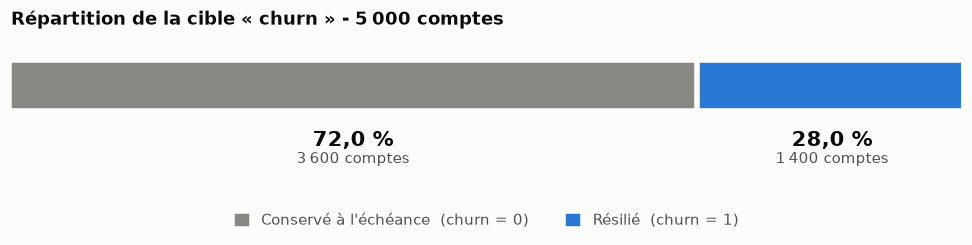

In [ ]:
from matplotlib.patches import Patch

# --- Palette (cf. journal de bord) : la classe d'interet porte l'accent,
# la classe majoritaire reste un contexte gris. Couleurs validees pour la
# deficience de vision des couleurs (dE CVD 15.9) et le contraste (>= 3:1).
ACCENT, CONTEXTE = "#2a78d6", "#898781"
INK, INK_2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"

# --- Copie de travail : dédoublonnage strict + cible en entier (cf. §7.1)
n_avant = len(df_brut)
df_eda = df_brut.drop_duplicates().copy()
df_eda["churn"] = df_eda["churn"].astype(int)
print(
    f"Doublons stricts retirés : {n_avant - len(df_eda)}  ({n_avant} -> {len(df_eda)} comptes)"
)

# --- Effectifs et indicateurs de déséquilibre
effectifs = df_eda["churn"].value_counts().sort_index()
n = int(effectifs.sum())
n_fidele, n_churn = int(effectifs[0]), int(effectifs[1])
prevalence = n_churn / n
ratio = n_fidele / n_churn

repartition = pd.DataFrame(
    {
        "classe": ["0 - conservé à l'échéance", "1 - résilié (churn)"],
        "effectif": [n_fidele, n_churn],
        "part_%": [round(100 * n_fidele / n, 2), round(100 * n_churn / n, 2)],
    }
)
print()
print(repartition.to_string(index=False))
print(f"\nPrévalence du churn                                  : {prevalence:.2%}")
print(f"Ratio de déséquilibre (majoritaire : minoritaire)    : {ratio:.2f} : 1")
print(f"Exactitude d'un classifieur trivial « aucun churn »  : {1 - prevalence:.2%}")
print(f"PR-AUC d'un classifieur aléatoire (= prévalence)     : {prevalence:.3f}")

# --- Part-à-tout : une barre empilée horizontale, étiquetée directement
fig, ax = plt.subplots(figsize=(9, 2.4))
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)

GAP = 0.004 * n  # respiration entre les deux segments
ax.barh([0], [n_fidele], color=CONTEXTE, height=0.42)
ax.barh([0], [n_churn], left=n_fidele + GAP, color=ACCENT, height=0.42)

# Étiquettes directes : encre de texte, jamais la couleur de série.
for centre, part, effectif in [
    (n_fidele / 2, 100 * n_fidele / n, n_fidele),
    (n_fidele + GAP + n_churn / 2, 100 * n_churn / n, n_churn),
]:
    ax.text(
        centre,
        -0.40,
        f"{part:.1f} %".replace(".", ","),
        ha="center",
        va="top",
        fontsize=14,
        fontweight="bold",
        color=INK,
    )
    ax.text(
        centre,
        -0.60,
        f"{effectif:,} comptes".replace(",", "\u202f"),
        ha="center",
        va="top",
        fontsize=9.5,
        color=INK_2,
    )

ax.set_xlim(0, n)
ax.set_ylim(-1.0, 0.35)
ax.axis("off")
ax.set_title(
    f"Répartition de la cible « churn » - {n:,} comptes".replace(",", "\u202f"),
    loc="left",
    fontsize=12,
    fontweight="bold",
    color=INK,
    pad=14,
)
ax.legend(
    handles=[
        Patch(facecolor=CONTEXTE, label="Conservé à l'échéance  (churn = 0)"),
        Patch(facecolor=ACCENT, label="Résilié  (churn = 1)"),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=2,
    frameon=False,
    fontsize=9.5,
    labelcolor=INK_2,
    handlelength=1.1,
    handleheight=1.1,
    columnspacing=2.5,
)

plt.tight_layout()
plt.show()

#### Interprétation

**Le déséquilibre est modéré ** avec une prévalence de **28,0 %** (ratio **2,57 : 1**). Trois conséquences méthodologiques en découlent.

**1. L'exactitude (*accuracy*) est disqualifiée comme métrique.** Un classifieur trivial qui prédit
« aucun churn » pour tout le monde obtient **72,0 % d'exactitude** sans rien apprendre. Ce chiffre ne sera
donc jamais présenté comme résultat ; il sert uniquement de plancher de référence pour la baseline (§8.1).

**2. La PR-AUC se lit contre un plancher de 0,280.** La précision moyenne d'un classifieur aléatoire est
égale à la prévalence : un modèle affichant une PR-AUC voisine de 0,28 n'apporte **aucun signal**, quelle
que soit son AUC ROC. C'est ce plancher, et non 0, qui sert de point de comparaison en §12.1. À l'inverse,
l'AUC ROC a pour plancher 0,5 indépendamment de la prévalence — d'où l'intérêt de présenter les deux.

**3. La stratification est obligatoire, le rééchantillonnage agressif ne l'est pas.** La séparation
train/test (§7.8) et les plis de validation croisée (§9.1) sont stratifiés sur `churn`, sinon la prévalence
dérive d'un pli à l'autre. En revanche, à 2,57 : 1, un `class_weight="balanced"` suffit à corriger
l'asymétrie ; recourir à du sur-échantillonnage synthétique (SMOTE) ne serait pas justifié ici et
**dégraderait la calibration** des probabilités — or ce sont les probabilités, et non les classes prédites,
qui servent à **hiérarchiser** les comptes pour les équipes CSM (§2.2).

**Précision sur la puissance statistique.** Un jeu de test à 20 % contient environ **280 comptes résiliés**.
C'est suffisant pour une estimation stable de l'AUC, mais l'intervalle de confiance sur le **rappel** reste
de l'ordre de ± 5 points : les écarts inférieurs à ce seuil entre deux modèles ne devront pas être
sur-interprétés en §9.1.

### 6.2 Variables numériques : distributions, valeurs aberrantes, corrélations

Cette lecture exige des colonnes **numériques**, or les données sont encore stockées sous forme de
texte. La fonction de conversion texte → nombre est donc définie ici, à son premier usage, puis
réutilisée telle quelle en §7.2 pour construire le jeu de données nettoyé (couche *silver*).

In [ ]:
COLONNES_NUMERIQUES = [
    "anciennete_mois",
    "sieges_souscrits",
    "utilisateurs_actifs",
    "taux_adoption_pct",
    "connexions_30j",
    "heures_usage_30j",
    "fonctionnalites_total",
    "fonctionnalites_utilisees",
    "nb_integrations",
    "derniere_connexion_jours",
    "tickets_support_90j",
    "delai_reponse_support_h",
    "csat",
    "retards_paiement_12m",
    "revenu_mensuel_recurrent_eur",
    "sante_compte_fin_periode",
    "valeur_vie_client_eur",
]


def to_numeric_fr(s: pd.Series) -> pd.Series:
    """Convertit une serie texte en numerique.

    Absorbe les encodages presents dans le jeu : virgule decimale ("40,0"),
    symbole pourcent ("20.0%"), symbole euro ("500 €"), unite suffixee ("3.0 h"),
    espaces ordinaires, insecables et fines. Les valeurs non convertibles
    deviennent NaN et sont denombrees par `controle_conversion`.
    """
    nettoye = (
        s.astype(str)
        .str.replace(
            r"[^\d,.\-]", "", regex=True
        )  # ne garder que chiffres, separateurs, signe
        .str.replace(",", ".", regex=False)  # virgule decimale -> point
        .replace({"": None, ".": None, "-": None})
    )
    return pd.to_numeric(nettoye, errors="coerce")


def controle_conversion(
    avant: pd.DataFrame, apres: pd.DataFrame, colonnes
) -> pd.DataFrame:
    """Compare les manquants avant/apres conversion : toute hausse est une perte."""
    lignes = []
    for col in colonnes:
        na_avant = int(avant[col].isna().sum())
        na_apres = int(apres[col].isna().sum())
        # Residu textuel : ce qui reste une fois les chiffres retires.
        residus = (
            avant[col].dropna().astype(str).str.replace(r"[\d\s  ]", "", regex=True)
        )
        unites = sorted({r for r in residus.unique() if r not in ("", ".", ",")})
        lignes.append(
            {
                "colonne": col,
                "NaN_avant": na_avant,
                "NaN_apres": na_apres,
                "perdus": na_apres - na_avant,
                "encodages_rencontres": " ".join(unites) if unites else "-",
            }
        )
    return pd.DataFrame(lignes)


# --- Application a la copie de travail
for col in COLONNES_NUMERIQUES:
    df_eda[col] = to_numeric_fr(df_brut.loc[df_eda.index, col])

controle = controle_conversion(df_brut.loc[df_eda.index], df_eda, COLONNES_NUMERIQUES)
perte_totale = int(controle["perdus"].sum())

print(controle[controle.encodages_rencontres != "-"].to_string(index=False))
print(f"\nValeurs non convertibles introduites par le parsing : {perte_totale}")
assert perte_totale == 0, "des valeurs numeriques ont ete perdues a la conversion"

                     colonne  NaN_avant  NaN_apres  perdus encodages_rencontres
           taux_adoption_pct        250        250       0                   .%
     delai_reponse_support_h        500        500       0                   .h
revenu_mensuel_recurrent_eur        150        150       0                   .€

Valeurs non convertibles introduites par le parsing : 0


Les trois colonnes concernées portent chacune un encodage différent : `%` sur le taux
d'adoption, `h` sur le délai de réponse, `€` sur le revenu récurrent — en plus de la virgule décimale, qui
touche les quatre colonnes décimales. Après conversion, **aucune valeur n'est perdue** : les manquants
restent exactement ceux du fichier source. L'`assert` fige ce contrôle, de sorte qu'une évolution future du
fichier d'entrée ferait échouer le notebook au lieu de dégrader les données en silence.

#### Distributions et points extrêmes

Deux questions, dans cet ordre. Chaque distribution est-elle symétrique ? Et contient-elle des valeurs
si éloignées du reste qu'elles pèseraient à elles seules sur un modèle linéaire ? Le tableau répond à
la première par l'asymétrie et le rapport entre le maximum et le troisième quartile ; le dénombrement
qui suit répond à la seconde par la règle 1,5 × IQR.

Les boîtes à moustaches confrontent ensuite les comptes résiliés aux comptes conservés, variable par
variable. C'est **l'écart entre les deux distributions**, et non la forme de chacune, qui annonce un
pouvoir prédictif.

In [ ]:
# --- Asymetrie et etendue des distributions ---------------------------------
synthese = (
    df_eda[COLONNES_NUMERIQUES].describe().T[["count", "mean", "50%", "min", "max"]]
)
synthese["asymetrie"] = df_eda[COLONNES_NUMERIQUES].skew()
synthese["rapport_max_p75"] = (
    df_eda[COLONNES_NUMERIQUES].max() / df_eda[COLONNES_NUMERIQUES].quantile(0.75)
).round(1)
synthese = synthese.sort_values("asymetrie", ascending=False).round(2)
print(synthese.to_string())

# --- Denombrement des points extremes (regle 1,5 x IQR) ---------------------
extremes = []
for col in COLONNES_NUMERIQUES:
    serie = df_eda[col].dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    masque = (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)
    if masque.any():
        extremes.append(
            {
                "colonne": col,
                "n_extremes": int(masque.sum()),
                "part_%": round(100 * masque.mean(), 2),
                "p75": round(float(q3), 1),
                "max": round(float(serie.max()), 1),
            }
        )
extremes = pd.DataFrame(extremes).sort_values(
    "part_%", ascending=False, ignore_index=True
)
print("\nPoints extremes au sens 1,5 x IQR :")
print(extremes.to_string(index=False))

                               count      mean       50%     min         max  asymetrie  rapport_max_p75
valeur_vie_client_eur         5000.0  74995.10  11203.50  300.00  2000000.00       5.57             42.7
utilisateurs_actifs           5000.0     34.69      9.00    0.00      829.00       4.73             28.6
revenu_mensuel_recurrent_eur  4850.0   3543.20    682.03    9.11    89402.85       4.60             38.1
derniere_connexion_jours      5000.0      7.58      2.00    0.00      200.00       4.54             40.0
sieges_souscrits              5000.0     74.32     28.00    1.00      898.00       3.57             16.0
heures_usage_30j              4700.0     12.67      5.65    0.00      170.20       2.29              9.7
retards_paiement_12m          4750.0      0.74      0.00    0.00        7.00       1.79              7.0
fonctionnalites_utilisees     5000.0      6.43      5.00    0.00       40.00       1.38              4.4
connexions_30j                5000.0     23.87     16.5

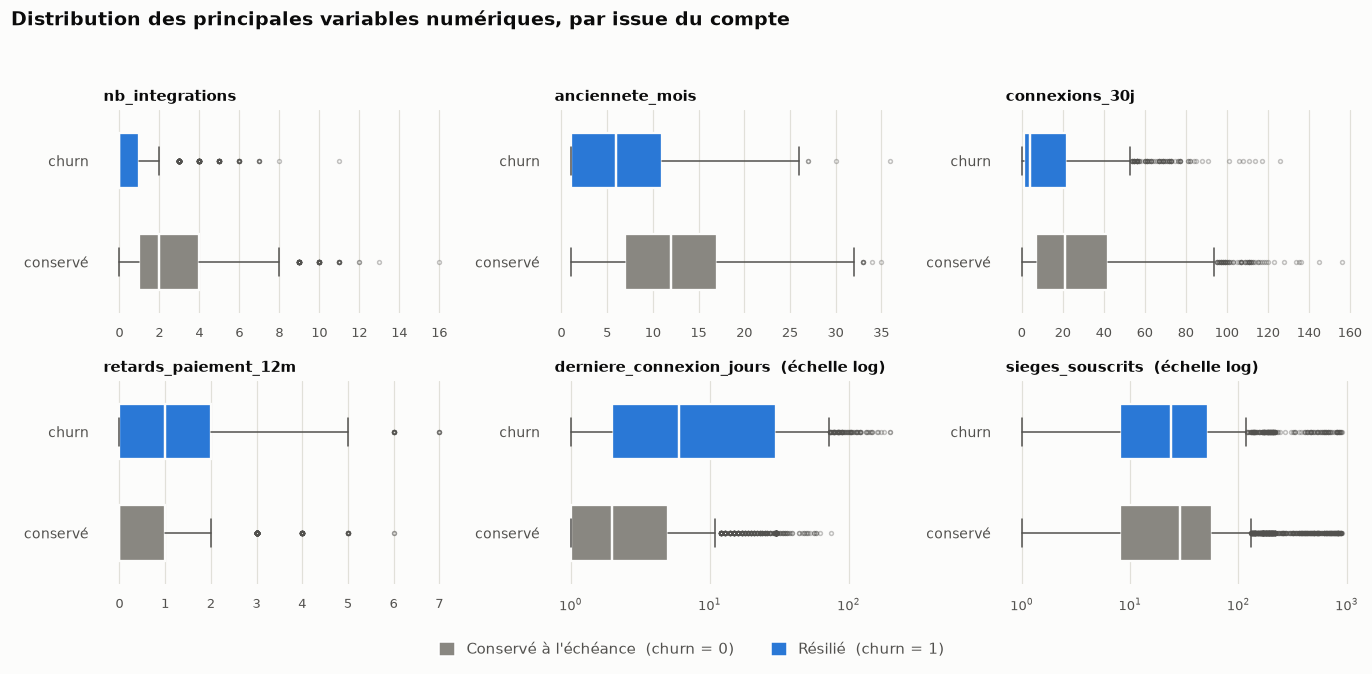

In [ ]:
GRILLE = "#e1e0d9"

# --- Distributions par classe : la boite a moustaches montre en meme temps
# la tendance centrale, la dispersion et les points extremes.
A_TRACER = [
    ("nb_integrations", False),
    ("anciennete_mois", False),
    ("connexions_30j", False),
    ("retards_paiement_12m", False),
    ("derniere_connexion_jours", True),
    ("sieges_souscrits", True),
]

fig, axes = plt.subplots(2, 3, figsize=(12.5, 6))
fig.patch.set_facecolor(SURFACE)

for ax, (col, log) in zip(axes.ravel(), A_TRACER):
    donnees = [
        df_eda.loc[df_eda.churn == 0, col].dropna(),
        df_eda.loc[df_eda.churn == 1, col].dropna(),
    ]
    if log:  # echelle log : la queue lourde ecraserait tout le reste
        donnees = [d[d > 0] for d in donnees]
    boites = ax.boxplot(
        donnees,
        orientation="horizontal",
        widths=0.55,
        patch_artist=True,
        flierprops=dict(
            marker="o",
            markersize=2.5,
            markerfacecolor="none",
            markeredgecolor=INK_2,
            alpha=0.35,
        ),
        medianprops=dict(color=SURFACE, linewidth=1.6),
        whiskerprops=dict(color=INK_2, linewidth=1),
        capprops=dict(color=INK_2, linewidth=1),
    )
    for boite, couleur in zip(boites["boxes"], [CONTEXTE, ACCENT]):
        boite.set_facecolor(couleur)
        boite.set_edgecolor(SURFACE)
        boite.set_linewidth(1.5)
    if log:
        ax.set_xscale("log")
    ax.set_facecolor(SURFACE)
    ax.set_yticks([1, 2])
    ax.set_yticklabels(["conservé", "churn"], fontsize=9, color=INK_2)
    ax.set_title(
        col + ("  (échelle log)" if log else ""),
        fontsize=10,
        fontweight="bold",
        color=INK,
        loc="left",
        pad=6,
    )
    ax.tick_params(axis="x", labelsize=8.5, colors=INK_2)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color=GRILLE, linewidth=0.8)
    ax.set_axisbelow(True)
    for bord in ax.spines.values():
        bord.set_visible(False)

fig.suptitle(
    "Distribution des principales variables numériques, par issue du compte",
    x=0.005,
    ha="left",
    fontsize=12.5,
    fontweight="bold",
    color=INK,
)
fig.legend(
    handles=[
        Patch(facecolor=CONTEXTE, label="Conservé à l'échéance  (churn = 0)"),
        Patch(facecolor=ACCENT, label="Résilié  (churn = 1)"),
    ],
    loc="lower center",
    ncol=2,
    frameon=False,
    fontsize=9.5,
    labelcolor=INK_2,
    handlelength=1.1,
    handleheight=1.1,
    columnspacing=2.5,
    bbox_to_anchor=(0.5, -0.02),
)
plt.tight_layout(rect=[0, 0.035, 1, 0.95])
plt.show()

##### Interprétation

**Les distributions sont fortement dissymétriques à droite.** Cinq variables présentent une asymétrie
supérieure à 3 — `valeur_vie_client_eur` (5,6), `utilisateurs_actifs` (4,7),
`revenu_mensuel_recurrent_eur` (4,6), `derniere_connexion_jours` (4,5), `sieges_souscrits` (3,6) — avec des
rapports maximum/troisième quartile allant jusqu'à **43** pour la valeur vie client. Deux conséquences :
la lecture graphique exige une **échelle logarithmique** sur ces variables, et un modèle linéaire (§8.2)
devra passer par une transformation logarithmique ou un normaliseur robuste, là où un modèle à base
d'arbres y sera indifférent.

**Les points extrêmes ne sont pas des erreurs : ils sont le segment *grands comptes*.** La règle
1,5 × IQR étiquette jusqu'à **16 %** des lignes sur `sieges_souscrits`, `revenu_mensuel_recurrent_eur` ou
`valeur_vie_client_eur`. Or toutes ces valeurs restent dans les plages annoncées au dictionnaire de
données (1–898 sièges, jusqu'à 89 402,9 € de MRR) et elles sont **cohérentes entre elles** : un compte à
898 sièges facture logiquement un MRR élevé. Il s'agit d'un portefeuille B2B qui mêle des TPE de 3 sièges
et des grandes entreprises de plusieurs centaines de licences — la dissymétrie *est* la structure du
marché.

**Décision : aucun écrêtage, aucune suppression.** Retirer ces lignes supprimerait précisément les comptes
dont la résiliation coûte le plus cher, et le modèle deviendrait aveugle au segment le plus rentable — un
contresens vis-à-vis de l'objectif métier de §2.1. Le traitement retenu est donc la **robustesse** (échelle
logarithmique, `RobustScaler`, ou modèles à base d'arbres), pas la censure.

**`derniere_connexion_jours` est un cas distinct.** Sa queue lourde (médiane 2 jours, maximum 200) ne
traduit pas une hétérogénéité de taille mais un **état de dormance** : les comptes qui ne se connectent
plus. C'est un signal de churn en soi, comme le montre le décalage net entre les deux boîtes du graphique
— à conserver impérativement.

#### Corrélations

Deux questions distinctes se posent ici. Quelles variables varient avec la résiliation — c'est la
lecture métier. Et lesquelles disent la même chose entre elles — c'est la question de la redondance :
deux variables corrélées à 0,9 n'apportent pas deux fois l'information, mais rendent les coefficients
d'une régression instables et leur interprétation trompeuse (§8.2).

Le coefficient retenu est celui de **Spearman** et non celui de Pearson, pour une raison tenant
directement au constat précédent : les queues lourdes et les points extrêmes relevés ci-dessus
fausseraient un coefficient de Pearson.

Paires fortement colinéaires (|rho| > 0,7) :
           variable_A                   variable_B  rho_spearman
       connexions_30j             heures_usage_30j         0.952
     sieges_souscrits revenu_mensuel_recurrent_eur         0.949
    taux_adoption_pct               connexions_30j         0.879
    taux_adoption_pct             heures_usage_30j         0.842
fonctionnalites_total      delai_reponse_support_h        -0.823
     sieges_souscrits          utilisateurs_actifs         0.813
  utilisateurs_actifs revenu_mensuel_recurrent_eur         0.788
fonctionnalites_total revenu_mensuel_recurrent_eur         0.725


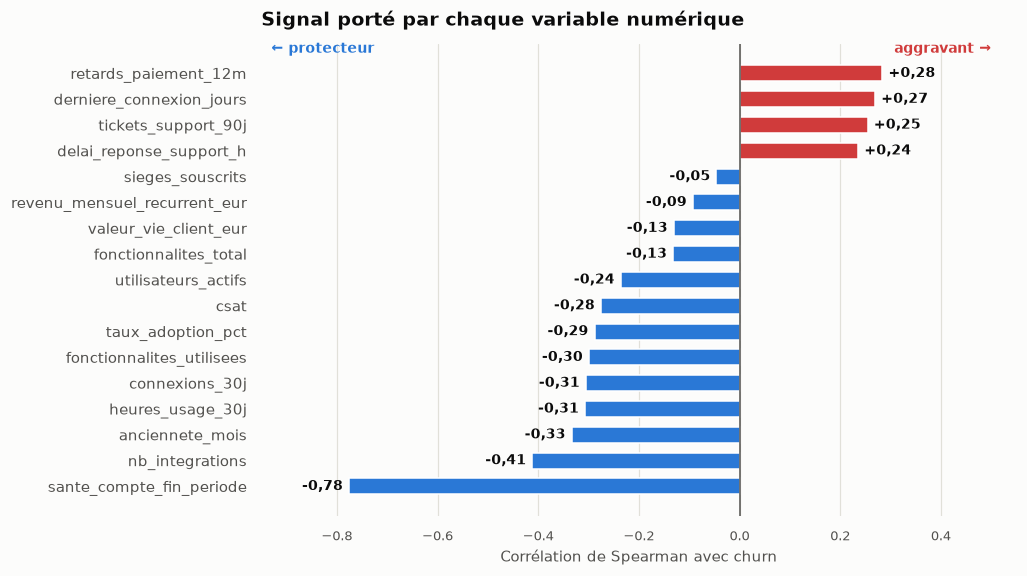

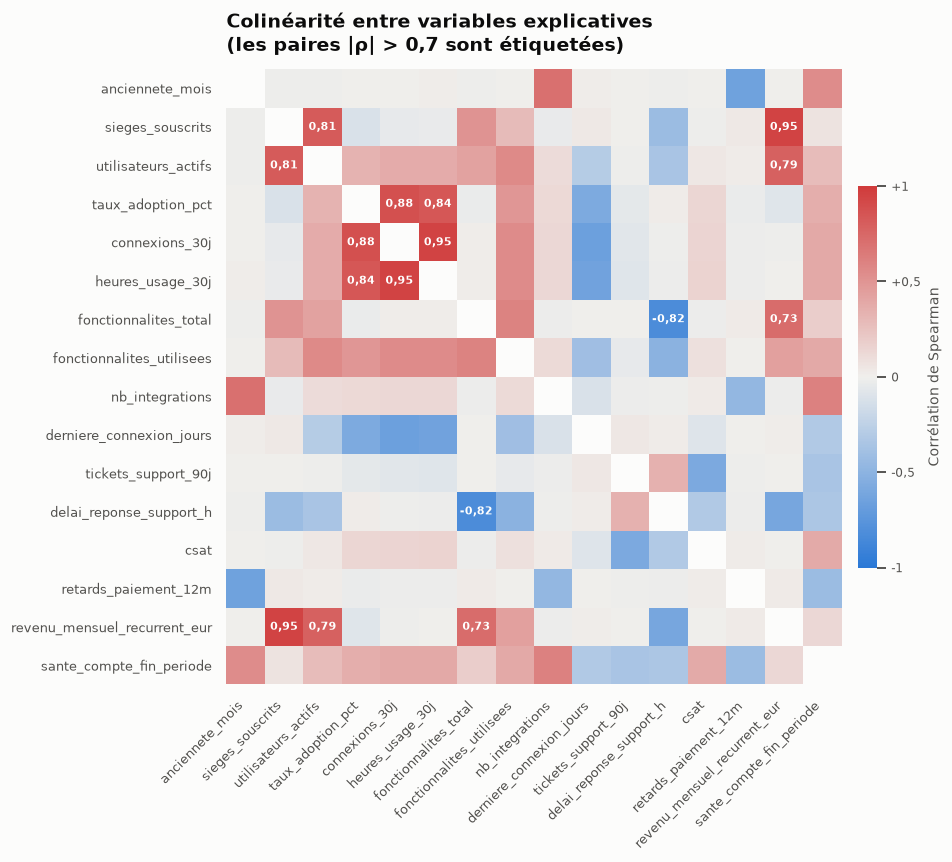

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

# --- Correlation de Spearman : monotone, robuste aux queues lourdes et aux
# points extremes constates plus haut ; Pearson serait ici trompeur.
CIBLES_EXCLUES = ["churn", "valeur_vie_client_eur"]
explicatives = [c for c in COLONNES_NUMERIQUES if c not in CIBLES_EXCLUES]

correlations = df_eda[COLONNES_NUMERIQUES + ["churn"]].corr(method="spearman")
avec_churn = correlations["churn"].drop("churn").sort_values()

# Palette divergente : deux teintes opposees + gris neutre au point mort.
DIVERGENTE = LinearSegmentedColormap.from_list(
    "bleu_gris_rouge", ["#2a78d6", "#f0efec", "#d03b3b"]
)

# ---------- Figure 1 : correlation de chaque variable avec la cible ----------
fig, ax = plt.subplots(figsize=(9.5, 5.4))
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)

positions = np.arange(len(avec_churn))
couleurs = ["#d03b3b" if v > 0 else "#2a78d6" for v in avec_churn]
ax.barh(positions, avec_churn.values, color=couleurs, height=0.62)

for y, (nom, valeur) in enumerate(avec_churn.items()):
    decalage = 0.012 if valeur > 0 else -0.012
    ax.text(
        valeur + decalage,
        y,
        f"{valeur:+.2f}".replace(".", ","),
        va="center",
        ha="left" if valeur > 0 else "right",
        fontsize=9,
        color=INK,
        fontweight="bold",
    )

ax.axvline(0, color=INK_2, linewidth=1)
ax.set_yticks(positions)
ax.set_yticklabels(avec_churn.index, fontsize=9.5, color=INK_2)
ax.set_xlim(-0.95, 0.55)
ax.set_xlabel("Corrélation de Spearman avec churn", fontsize=9.5, color=INK_2)
ax.set_title(
    "Signal porté par chaque variable numérique",
    loc="left",
    fontsize=12.5,
    fontweight="bold",
    color=INK,
    pad=12,
)
ax.text(
    -0.93,
    len(avec_churn) - 0.2,
    "← protecteur",
    fontsize=9,
    color="#2a78d6",
    fontweight="bold",
)
ax.text(
    0.50,
    len(avec_churn) - 0.2,
    "aggravant →",
    fontsize=9,
    color="#d03b3b",
    fontweight="bold",
    ha="right",
)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color=GRILLE, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="x", labelsize=8.5, colors=INK_2)
for bord in ax.spines.values():
    bord.set_visible(False)
plt.tight_layout()
plt.show()

# ---------- Figure 2 : colinearite entre variables explicatives -------------
matrice = df_eda[explicatives].corr(method="spearman")

# La diagonale vaut 1 par construction : la masquer evite qu'elle capte l'oeil.
affichee = matrice.values.copy()
np.fill_diagonal(affichee, np.nan)
DIVERGENTE.set_bad(SURFACE)

fig, ax = plt.subplots(figsize=(9.6, 8))
fig.patch.set_facecolor(SURFACE)
image = ax.imshow(affichee, cmap=DIVERGENTE, vmin=-1, vmax=1)

ax.set_xticks(range(len(explicatives)))
ax.set_xticklabels(explicatives, rotation=45, ha="right", fontsize=8.5, color=INK_2)
ax.set_yticks(range(len(explicatives)))
ax.set_yticklabels(explicatives, fontsize=8.5, color=INK_2)
ax.grid(False)

# Etiquette directe uniquement sur les paires fortement colineaires : le
# lecteur doit voir les grappes, pas dechiffrer 225 nombres.
for i in range(len(explicatives)):
    for j in range(len(explicatives)):
        valeur = matrice.values[i, j]
        if i != j and abs(valeur) > 0.7:
            ax.text(
                j,
                i,
                f"{valeur:.2f}".replace(".", ","),
                ha="center",
                va="center",
                fontsize=7.5,
                color="#ffffff",
                fontweight="bold",
            )

barre = fig.colorbar(image, ax=ax, shrink=0.62, pad=0.02)
barre.set_label("Corrélation de Spearman", fontsize=9, color=INK_2)
barre.ax.tick_params(labelsize=8, colors=INK_2)
barre.set_ticks([-1, -0.5, 0, 0.5, 1])
barre.set_ticklabels(["-1", "-0,5", "0", "+0,5", "+1"])
barre.outline.set_visible(False)
ax.set_title(
    "Colinéarité entre variables explicatives\n(les paires |ρ| > 0,7 sont étiquetées)",
    loc="left",
    fontsize=12.5,
    fontweight="bold",
    color=INK,
    pad=12,
)
for bord in ax.spines.values():
    bord.set_visible(False)
plt.tight_layout()
plt.show()

# ---------- Grappes colineaires, sous forme de tableau ----------------------
paires = []
for i, a in enumerate(explicatives):
    for b in explicatives[i + 1 :]:
        rho = matrice.loc[a, b]
        if abs(rho) > 0.7:
            paires.append(
                {"variable_A": a, "variable_B": b, "rho_spearman": round(rho, 3)}
            )
paires = pd.DataFrame(paires).sort_values(
    "rho_spearman", key=abs, ascending=False, ignore_index=True
)
print("Paires fortement colinéaires (|rho| > 0,7) :")
print(paires.to_string(index=False))

##### Interprétation

Le coefficient de **Spearman** est retenu plutôt que Pearson : il ne mesure qu'une relation monotone,
ce qui le rend insensible aux queues lourdes et aux points extrêmes constatés ci-dessus.

**1. Aucune variable ne « donne » la réponse — sauf une.** En écartant
`sante_compte_fin_periode`, la corrélation la plus forte avec la cible plafonne à **−0,41**
(`nb_integrations`). Aucune variable ne porte à elle seule la réponse : la performance devra venir de la
**combinaison** des signaux et du *feature engineering*.

**2. `sante_compte_fin_periode` à un coefficient à −0,78**, soit près du double du signal suivant. Un tel écart
nous indique sans doute une fuite de données : cette variable est décrite au dictionnaire comme un score
« calculé en FIN de période », donc postérieur à la décision de résiliation. Le diagnostic formel est
établi en §6.5 ; elle est d'ores et déjà écartée du périmètre explicatif (§4.4).

**3. Les signaux légitimes racontent une histoire métier cohérente.** Côté protecteur :
l'**ancrage technique** (`nb_integrations`, −0,41 — plus un client a connecté d'intégrations tierces, plus
le coût de sortie est élevé), l'**ancienneté** (−0,33), l'**intensité d'usage** (`heures_usage_30j` et
`connexions_30j`, −0,31) et la **satisfaction** (`csat`, −0,28). Côté aggravant : les
**retards de paiement** (+0,28), la **dormance** (`derniere_connexion_jours`, +0,27) et la
**friction support** (`tickets_support_90j`, +0,25 ; `delai_reponse_support_h`, +0,24).

**4. `valeur_vie_client_eur` ne corrèle qu'à −0,13 avec le churn.** Elle figure sur le graphique à titre
documentaire : c'est la cible secondaire (§12.4), et son faible lien avec le churn confirme qu'elle ne
saurait servir de variable explicative — outre le fait qu'elle est, elle aussi, connue *a posteriori*.

**5. Trois grappes colinéaires, à traiter en §7.7 plutôt qu'à subir.**

| Grappe | Variables | ρ | Lecture |
|---|---|---|---|
| **Taille du compte** | `sieges_souscrits` ↔ `revenu_mensuel_recurrent_eur` (0,95) ↔ `utilisateurs_actifs` (0,81) ↔ `valeur_vie_client_eur` (0,88) | > 0,8 | Le MRR est essentiellement *sièges × prix du plan* : ces variables mesurent une seule dimension. |
| **Intensité d'usage** | `connexions_30j` ↔ `heures_usage_30j` (0,95) ↔ `taux_adoption_pct` (0,88 / 0,84) | > 0,8 | Trois mesures du même comportement. |
| **Niveau de plan** | `fonctionnalites_total` ↔ `delai_reponse_support_h` (**−0,82**) ↔ `revenu_mensuel_recurrent_eur` (0,73) | > 0,7 | Ces variables ne décrivent pas le compte mais **son plan** (cf. contrôles ci-dessous). |

Cette colinéarité ne fausse pas les modèles à base d'arbres, mais elle **déstabilise les coefficients d'une
régression logistique** et **dilue l'importance par permutation** (§12.2) : deux variables redondantes se
partagent le crédit et paraissent toutes deux négligeables. D'où l'intérêt de construire des **ratios**
en §7.7 plutôt que de conserver les mesures brutes en parallèle.

#### Contrôles de cohérence et redondances déterministes
Deux variables fortement corrélées peuvent être plus qu'une corrélation, l'une de ses variable peut être le calcul de l'autre. Dans ce cas le traitement à apporter n'est pas le même.

In [ ]:
# --- Contrôles de cohérence métier ------------------------------------------
# Une corrélation très élevée peut trahir une redondance *déterministe* :
# la variable n'est pas corrélée à une autre, elle en est le calcul exact.
adoption_recalculee = 100 * df_eda.utilisateurs_actifs / df_eda.sieges_souscrits
ecart_adoption = (df_eda.taux_adoption_pct - adoption_recalculee).abs()

plan_normalise = df_brut.loc[df_eda.index, "plan"].str.strip().str.upper()
correspondance_plan = pd.crosstab(plan_normalise, df_eda.fonctionnalites_total)
sla_catalogue = dict(zip(catalogue.plan.str.upper(), catalogue.sla_reponse_h))
delai_median_par_plan = df_eda.groupby(plan_normalise).delai_reponse_support_h.median()

controles = [
    (
        "utilisateurs_actifs <= sieges_souscrits",
        int((df_eda.utilisateurs_actifs > df_eda.sieges_souscrits).sum()),
    ),
    (
        "fonctionnalites_utilisees <= fonctionnalites_total",
        int((df_eda.fonctionnalites_utilisees > df_eda.fonctionnalites_total).sum()),
    ),
    (
        "taux_adoption_pct = 100 x actifs / sieges  (ecart > 0,5 pt)",
        int((ecart_adoption > 0.5).sum()),
    ),
    (
        "connexions_30j = 0 mais derniere_connexion_jours <= 30",
        int(
            (
                (df_eda.connexions_30j == 0) & (df_eda.derniere_connexion_jours <= 30)
            ).sum()
        ),
    ),
    (
        "connexions_30j > 0 mais derniere_connexion_jours > 30",
        int(
            ((df_eda.connexions_30j > 0) & (df_eda.derniere_connexion_jours > 30)).sum()
        ),
    ),
]
print("Nombre de lignes en infraction :")
for libelle, n_infractions in controles:
    etat = "OK" if n_infractions == 0 else "A TRAITER"
    print(f"  [{etat:9s}] {libelle:60s} {n_infractions:5d}")

print(
    f"\nEcart maximal entre taux_adoption_pct et son recalcul : "
    f"{ecart_adoption.max():.4f} point de pourcentage (simple arrondi)"
)

print("\nfonctionnalites_total par plan (effectifs) :")
print(correspondance_plan.to_string())

print("\nDelai de reponse support median, confronte au SLA du catalogue :")
comparaison_sla = pd.DataFrame(
    {
        "delai_median_observe_h": delai_median_par_plan.round(1),
        "sla_catalogue_h": pd.Series(sla_catalogue),
    }
)
comparaison_sla["respecte_le_sla_%"] = (
    df_eda.assign(plan_n=plan_normalise, sla=plan_normalise.map(sla_catalogue))
    .groupby("plan_n")
    .apply(
        lambda g: 100 * (g.delai_reponse_support_h <= g.sla).mean(),
        include_groups=False,
    )
    .round(1)
)
print(comparaison_sla.to_string())

Nombre de lignes en infraction :
  [OK       ] utilisateurs_actifs <= sieges_souscrits                          0
  [OK       ] fonctionnalites_utilisees <= fonctionnalites_total               0
  [OK       ] taux_adoption_pct = 100 x actifs / sieges  (ecart > 0,5 pt)      0
  [A TRAITER] connexions_30j = 0 mais derniere_connexion_jours <= 30          44
  [OK       ] connexions_30j > 0 mais derniere_connexion_jours > 30            0

Ecart maximal entre taux_adoption_pct et son recalcul : 0.0500 point de pourcentage (simple arrondi)

fonctionnalites_total par plan (effectifs) :
fonctionnalites_total    8     16    26   40
plan                                        
BUSINESS                  0     0  1310    0
ENTERPRISE                0     0     0  551
PRO                       0  1772     0    0
STARTER                1367     0     0    0

Delai de reponse support median, confronte au SLA du catalogue :
            delai_median_observe_h  sla_catalogue_h  respecte_le_sla_%
BUSINES

##### Interprétation

**1. `taux_adoption_pct` n'est pas corrélé à l'adoption : il *est* l'adoption.** L'écart maximal entre la
colonne et son recalcul `100 × utilisateurs_actifs / sieges_souscrits` est de **0,05 point** sur 4 750
lignes — un écart qui s'explique très bien par les approximations d'arrondis. Conséquence directe et précieuse : ses **250 valeurs manquantes se
reconstituent exactement** à partir des deux colonnes sources, qui n'en comptent aucune. Nul besoin
d'imputer par la médiane et d'introduire du bruit là où l'arithmétique donne la valeur vraie. C'est la
stratégie retenue en §7.2.

**2. `fonctionnalites_total` est entièrement déterminée par le plan** : 8 pour Starter, 16 pour Pro, 26
pour Business, 40 pour Enterprise, sans une seule exception sur les 5 000 lignes — exactement le
catalogue. Elle n'apporte donc **aucune information au-delà de la variable `plan`** ; la conserver en même
temps que `plan` et que les colonnes issues de la jointure (§7.5) reviendrait à encoder trois fois la même
chose. Une seule de ces représentations sera retenue.

**3. `delai_reponse_support_h` mesure surtout le plan souscrit, pas la qualité de service reçue.** Son
délai médian épouse le SLA du catalogue plan par plan : 23,5 h contre 24 pour Starter, 12,1 contre 12 pour
Pro, 5,9 contre 6 pour Business, 3,1 contre 3 pour Enterprise. Sa corrélation de +0,24 avec le churn est
donc en grande partie un **effet de plan** : les clients Starter résilient davantage, et ce sont eux qui
attendent 24 h. Le signal réellement porteur n'est pas le délai brut mais **l'écart au SLA promis** —
autrement dit *ce client a-t-il été servi moins bien que ce qu'il a payé ?*. On note d'ailleurs que le SLA
n'est respecté que dans **44 à 47 %** des cas, et ce de façon homogène sur les quatre plans. Le ratio
`delai_reponse_support_h / sla_reponse_h` est donc construit en §7.7.

**4. Les bornes métier sont respectées.** Aucune ligne ne présente plus d'utilisateurs actifs que de sièges
souscrits, ni plus de fonctionnalités utilisées que de fonctionnalités offertes. Les incohérences
grossières sont absentes du jeu.

**5. Une seule anomalie résiduelle, mineure : 44 comptes** (0,9 %) affichent zéro connexion sur 30 jours
tout en déclarant une dernière connexion il y a 30 jours ou moins. La réciproque, elle, ne se produit
jamais. L'hypothèse la plus économique est un **décalage de fenêtre d'observation** entre les deux
compteurs (une connexion tombant juste à la frontière des 30 jours). L'effet est négligeable et ces lignes
sont **conservées** ; la piste retenue en §7.7 est de préférer un indicateur binaire de dormance, plus
robuste à ce genre de bord, à la valeur brute.

### 6.3 Variables catégorielles : taux de churn par modalité

Comme en §6.2, cette lecture exige un préalable : les catégorielles sont **inutilisables en l'état**.
`plan` compte 16 modalités pour 4 formules réelles, `secteur` 28 pour 7 secteurs, `taille_entreprise`
12 pour 4 segments — l'effet combiné de la casse (`Pro`, `PRO`, `pro`) et des espaces de bord (`" Pro "`).
La fonction de normalisation est donc définie **ici**, à son premier usage, et réutilisée en §7.4 ainsi que
pour la jointure du catalogue en §7.5.

In [ ]:
# --- Normalisation canonique des variables catégorielles ---------------------
# Définie ici, à son premier usage ; réutilisée en §7.4 et pour la jointure §7.5.
COLONNES_CATEGORIELLES = [
    "plan",
    "taille_entreprise",
    "secteur",
    "pays",
    "jour_souscription",
    "couleur_theme_interface",
    "code_datacenter",
    "groupe_experimentation",
]
ACRONYMES = {"taille_entreprise", "code_datacenter", "groupe_experimentation"}


def normaliser_categorie(s: pd.Series) -> pd.Series:
    """Ramène une catégorielle à une forme canonique : sans espaces de bord,
    espaces internes réduits, en majuscules. La casse haute est retenue car
    elle est stable en présence d'accents ("santé" et "SANTÉ" se rejoignent)
    et sert de clé de jointure avec le catalogue des plans (§7.5).
    """
    return (
        s.str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.upper()
        .replace({"": None})
    )


def etiquette(modalite, colonne: str) -> str:
    """Libellé lisible pour les graphiques : les acronymes métier (TPE, ETI, GE)
    restent en majuscules, le reste passe en capitale initiale.
    """
    if modalite is None or pd.isna(modalite):
        return "(manquant)"
    return str(modalite) if colonne in ACRONYMES else str(modalite).capitalize()


# --- Application et bilan du regroupement
bilan = []
for col in COLONNES_CATEGORIELLES:
    avant = df_brut.loc[df_eda.index, col]
    df_eda[col] = normaliser_categorie(avant)
    bilan.append(
        {
            "colonne": col,
            "modalites_avant": int(avant.nunique()),
            "modalites_apres": int(df_eda[col].nunique()),
            "manquants": int(df_eda[col].isna().sum()),
            "modalites_retenues": ", ".join(sorted(df_eda[col].dropna().unique())),
        }
    )
bilan = pd.DataFrame(bilan)
print(
    bilan[["colonne", "modalites_avant", "modalites_apres", "manquants"]].to_string(
        index=False
    )
)
print()
for ligne in bilan.itertuples():
    if ligne.modalites_avant != ligne.modalites_apres:
        print(
            f"{ligne.colonne} : {ligne.modalites_avant} -> {ligne.modalites_apres}  "
            f"[{ligne.modalites_retenues}]"
        )

# --- La jointure du catalogue devient-elle possible ? (contrôle avant §7.5)
plans_catalogue = set(catalogue.plan.str.strip().str.upper())
plans_donnees = set(df_eda.plan.dropna().unique())
print(
    f"\nPlans du jeu absents du catalogue : {plans_donnees - plans_catalogue or 'aucun'}"
)
print(
    f"Plans du catalogue absents du jeu : {plans_catalogue - plans_donnees or 'aucun'}"
)

                colonne  modalites_avant  modalites_apres  manquants
                   plan               16                4          0
      taille_entreprise               12                4          0
                secteur               28                7        250
                   pays                6                6        200
      jour_souscription                7                7          0
couleur_theme_interface                5                5          0
        code_datacenter                4                4          0
 groupe_experimentation                3                3          0

plan : 16 -> 4  [BUSINESS, ENTERPRISE, PRO, STARTER]
taille_entreprise : 12 -> 4  [ETI, GE, PME, TPE]
secteur : 28 -> 7  [COMMERCE, FINANCE, INDUSTRIE, PUBLIC, SANTÉ, TECH, ÉDUCATION]

Plans du jeu absents du catalogue : aucun
Plans du catalogue absents du jeu : aucun


Le regroupement ramène 56 modalités parasites à 15 modalités réelles, sans aucune perte
d'information. Surtout, la
**jointure du catalogue devient possible** — les quatre plans du jeu correspondent désormais exactement aux
quatre plans du référentiel, dans les deux sens.

#### Taux de churn par modalité

Un taux brut ne s'interprète pas sans son incertitude : `GE` compte 360 comptes et `France` 2 691, les deux
taux ne se lisent pas avec la même confiance. Chaque modalité est donc assortie d'un **intervalle de
confiance de Wilson à 95 %** — préféré à l'intervalle normal parce qu'il reste valide sur les petits
effectifs et ne sort jamais de l'intervalle [0, 1]. Une modalité n'est déclarée distincte du taux global
que si son intervalle **ne contient pas** 28,0 %.

In [ ]:
# --- Taux de churn par modalité, avec intervalle de confiance ---------------
# Un taux brut n'est pas interprétable sans son incertitude : une modalité de
# 360 comptes et une de 2 691 ne se lisent pas avec la même confiance.
def intervalle_wilson(n_succes: int, n_total: int, z: float = 1.96):
    """Intervalle de confiance de Wilson à 95 % pour une proportion.

    Préféré à l'intervalle normal : il reste valide sur les petits effectifs
    et ne sort jamais de [0, 1].
    """
    if n_total == 0:
        return (np.nan, np.nan)
    p = n_succes / n_total
    denominateur = 1 + z**2 / n_total
    centre = (p + z**2 / (2 * n_total)) / denominateur
    demi = z * np.sqrt(p * (1 - p) / n_total + z**2 / (4 * n_total**2)) / denominateur
    return (centre - demi, centre + demi)


def taux_par_modalite(colonne: str) -> pd.DataFrame:
    """Taux de churn, effectif et IC 95 % pour chaque modalité d'une colonne.

    Les valeurs manquantes forment une modalité à part entière : leur taux de
    churn renseigne sur le caractère informatif ou non de l'absence de valeur.
    """
    groupes = df_eda.groupby(colonne, dropna=False).churn.agg(["size", "sum", "mean"])
    bornes = [
        intervalle_wilson(int(r["sum"]), int(r["size"])) for _, r in groupes.iterrows()
    ]
    resultat = pd.DataFrame(
        {
            "modalite": [etiquette(m, colonne) for m in groupes.index],
            "effectif": groupes["size"].astype(int).values,
            "taux_churn_%": (100 * groupes["mean"]).round(1).values,
            "ic95_bas_%": (100 * np.array([b[0] for b in bornes])).round(1),
            "ic95_haut_%": (100 * np.array([b[1] for b in bornes])).round(1),
        }
    )
    # Une modalité est jugée écartée du taux global si son IC ne le contient pas.
    resultat["ecart_significatif"] = ~(
        (resultat["ic95_bas_%"] <= 100 * PREVALENCE_GLOBALE)
        & (resultat["ic95_haut_%"] >= 100 * PREVALENCE_GLOBALE)
    )
    return resultat.sort_values("taux_churn_%", ascending=False, ignore_index=True)


PREVALENCE_GLOBALE = df_eda.churn.mean()
SUBSTANTIELLES = ["plan", "taille_entreprise", "secteur", "pays"]

for col in SUBSTANTIELLES:
    tableau = taux_par_modalite(col)
    etendue = tableau["taux_churn_%"].max() - tableau["taux_churn_%"].min()
    print(
        f"=== {col}   (étendue {etendue:.1f} points ; taux global "
        f"{100 * PREVALENCE_GLOBALE:.1f} %)"
    )
    print(tableau.to_string(index=False))
    print()

=== plan   (étendue 17.5 points ; taux global 28.0 %)
  modalite  effectif  taux_churn_%  ic95_bas_%  ic95_haut_%  ecart_significatif
   Starter      1367          37.5        34.9         40.1                True
       Pro      1772          26.7        24.7         28.9               False
  Business      1310          23.2        21.0         25.6                True
Enterprise       551          20.0        16.8         23.5                True

=== taille_entreprise   (étendue 8.3 points ; taux global 28.0 %)
modalite  effectif  taux_churn_%  ic95_bas_%  ic95_haut_%  ecart_significatif
     TPE      1679          31.7        29.5         34.0                True
     PME      2068          27.7        25.8         29.6               False
      GE       360          24.2        20.0         28.8               False
     ETI       893          23.4        20.7         26.3                True

=== secteur   (étendue 7.0 points ; taux global 28.0 %)
  modalite  effectif  taux_churn

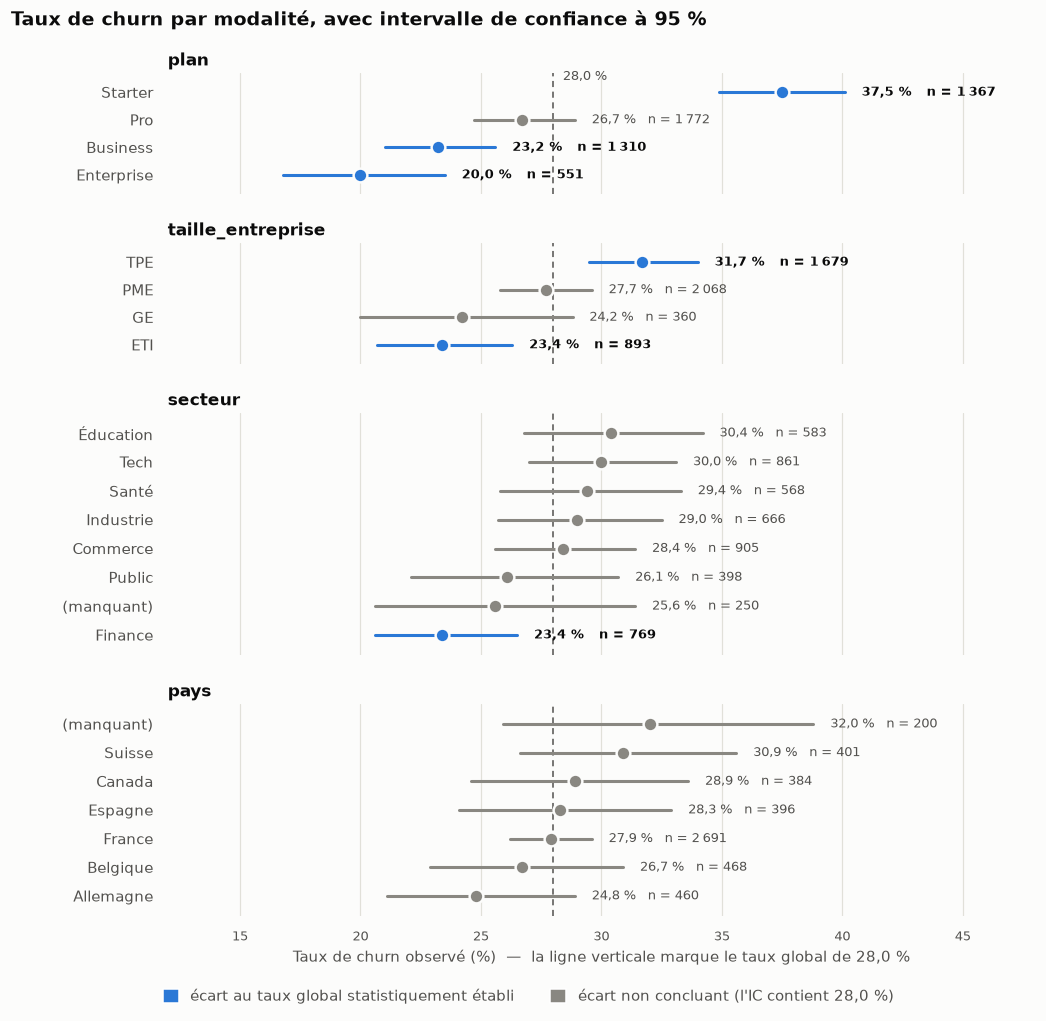

In [ ]:
# --- Le taux et son incertitude, variable par variable ----------------------
# Forme retenue : point + intervalle plutot qu'histogramme. Un histogramme
# suggererait une precision que 360 comptes n'autorisent pas ; l'intervalle
# rend l'incertitude visible, ce qui est ici l'information decisive.
tableaux = {col: taux_par_modalite(col) for col in SUBSTANTIELLES}

fig, axes = plt.subplots(
    len(SUBSTANTIELLES),
    1,
    figsize=(9.5, 9.2),
    sharex=True,
    gridspec_kw={
        "height_ratios": [len(tableaux[c]) for c in SUBSTANTIELLES],
        "hspace": 0.28,
    },
)
fig.patch.set_facecolor(SURFACE)
reference = 100 * PREVALENCE_GLOBALE

for ax, col in zip(axes, SUBSTANTIELLES):
    tableau = tableaux[col].iloc[::-1].reset_index(drop=True)  # meilleur taux en haut
    positions = np.arange(len(tableau))
    ax.set_facecolor(SURFACE)
    ax.axvline(reference, color=INK_2, linewidth=1, linestyle=(0, (4, 3)), zorder=1)

    for y, ligne in tableau.iterrows():
        significatif = ligne["ecart_significatif"]
        couleur = ACCENT if significatif else CONTEXTE
        ax.plot(
            [ligne["ic95_bas_%"], ligne["ic95_haut_%"]],
            [y, y],
            color=couleur,
            linewidth=2,
            solid_capstyle="round",
            zorder=2,
        )
        ax.plot(
            [ligne["taux_churn_%"]],
            [y],
            marker="o",
            markersize=9,
            color=couleur,
            markeredgecolor=SURFACE,
            markeredgewidth=1.6,
            zorder=3,
        )
        ax.text(
            ligne["ic95_haut_%"] + 0.7,
            y,
            f"{ligne['taux_churn_%']:.1f} %".replace(".", ",")
            + f"   n = {ligne['effectif']:,}".replace(",", " "),
            va="center",
            fontsize=8.5,
            color=INK if significatif else INK_2,
            fontweight="bold" if significatif else "normal",
        )

    ax.set_yticks(positions)
    ax.set_yticklabels(tableau["modalite"], fontsize=9.5, color=INK_2)
    ax.set_ylim(-0.7, len(tableau) - 0.3)
    ax.set_title(col, loc="left", fontsize=11, fontweight="bold", color=INK, pad=5)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color=GRILLE, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", labelsize=8.5, colors=INK_2)
    for bord in ax.spines.values():
        bord.set_visible(False)

axes[-1].set_xlim(12, 48)
axes[-1].set_xlabel(
    "Taux de churn observé (%)  —  la ligne verticale marque le taux global de 28,0 %",
    fontsize=9.5,
    color=INK_2,
)
axes[0].text(
    reference + 0.4,
    len(tableaux[SUBSTANTIELLES[0]]) - 0.55,
    "28,0 %",
    fontsize=8.5,
    color=INK_2,
)
fig.suptitle(
    "Taux de churn par modalité, avec intervalle de confiance à 95 %",
    x=0.005,
    ha="left",
    fontsize=12.5,
    fontweight="bold",
    color=INK,
)
fig.legend(
    handles=[
        Patch(facecolor=ACCENT, label="écart au taux global statistiquement établi"),
        Patch(facecolor=CONTEXTE, label="écart non concluant (l'IC contient 28,0 %)"),
    ],
    loc="lower center",
    ncol=2,
    frameon=False,
    fontsize=9.5,
    labelcolor=INK_2,
    handlelength=1.1,
    handleheight=1.1,
    columnspacing=2.5,
    bbox_to_anchor=(0.5, -0.015),
)
fig.subplots_adjust(left=0.155, right=0.985, top=0.918, bottom=0.085)
plt.show()

##### Interprétation

**1. `plan` est la catégorielle la plus discriminante, et elle est monotone.** Le taux de churn décroît
régulièrement avec le niveau de formule : **37,5 %** en Starter, 26,7 % en Pro, 23,2 % en Business,
**20,0 %** en Enterprise — 17,5 points d'écart, et trois modalités sur quatre statistiquement détachées du
taux global. Cette monotonie n'est pas un hasard de mesure : elle reflète un mécanisme métier plausible
(engagement contractuel plus fort, support dédié, coût de sortie plus élevé). Elle justifie d'envisager un
**encodage ordinal** du plan, et non seulement un *one-hot*.

**2. `taille_entreprise` porte un signal réel mais modeste** : 8,3 points entre TPE (31,7 %) et ETI
(23,4 %), ces deux extrêmes étant seuls statistiquement établis. Attention toutefois — cette variable est
fortement liée à `plan` et à la grappe « taille du compte » de §6.2 : une part de son signal est
probablement la même information vue sous un autre angle.

**3. `secteur` est à la limite du concluant.** Sur 7,0 points d'étendue, **une seule** modalité se détache :
`Finance`, à 23,4 % contre 28,0 % globalement. Les six autres ont des intervalles qui se recouvrent
largement. Retenir « le secteur influence le churn » serait sur-interpréter ; la formulation défendable est
que *les clients du secteur Finance résilient moins, les autres secteurs ne se distinguent pas*.

**4. `pays` ne discrimine pas.** Son étendue (7,2 points)
est **supérieure** à celle de `secteur`, et pourtant **aucune** de ses modalités ne se détache du taux
global. L'étendue seule est donc un indicateur trompeur sur de petits effectifs — d'où l'intérêt d'afficher
les intervalles plutôt que les seuls taux. Conséquence pratique : conserver `pays` comme variable
explicative ajouterait six colonnes après encodage pour un signal non établi, tout en créant un **risque
de traitement différencié par nationalité** (§4.1). Son exclusion se justifie donc à la fois
statistiquement et éthiquement.

**5. Les modalités « (manquant) » ne se distinguent jamais.** Ni pour `secteur` (25,6 %) ni pour `pays`
(32,0 % mais avec un intervalle de 25,9 à 38,8 %).

#### Quelles variables discriminent réellement ?

L'**étendue** — écart entre le taux le plus haut et le plus bas — résume en un chiffre le pouvoir
discriminant d'une catégorielle. Confrontée au nombre de modalités statistiquement détachées du taux
global, elle prépare directement le diagnostic d'absence d'effet conduit en §6.4.

                colonne  modalites  taux_min_%  taux_max_%  etendue_pts  modalites_ecartees
                   plan          4        20.0        37.5         17.5                   3
      taille_entreprise          4        23.4        31.7          8.3                   2
                   pays          7        24.8        32.0          7.2                   0
                secteur          8        23.4        30.4          7.0                   1
      jour_souscription          7        25.0        30.8          5.8                   0
        code_datacenter          4        26.7        29.1          2.4                   0
couleur_theme_interface          5        27.1        29.1          2.0                   0
 groupe_experimentation          3        27.8        28.2          0.4                   0


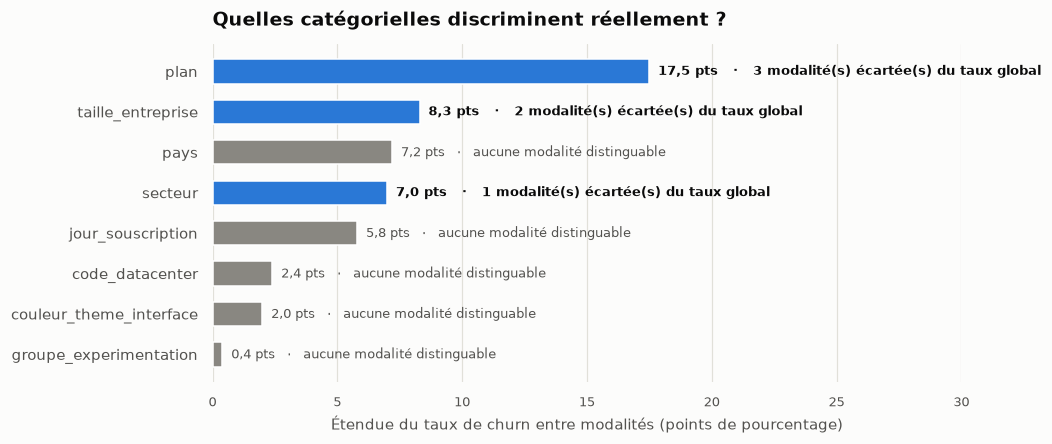

In [ ]:
# --- Amplitude du signal porte par chaque categorielle ----------------------
# L'etendue (taux max - taux min entre modalites) resume en un nombre la
# capacite d'une variable a discriminer. Elle prepare le diagnostic de §6.4.
amplitudes = []
for col in COLONNES_CATEGORIELLES:
    tableau = taux_par_modalite(col)
    amplitudes.append(
        {
            "colonne": col,
            "modalites": len(tableau),
            "taux_min_%": tableau["taux_churn_%"].min(),
            "taux_max_%": tableau["taux_churn_%"].max(),
            "etendue_pts": round(
                tableau["taux_churn_%"].max() - tableau["taux_churn_%"].min(), 1
            ),
            "modalites_ecartees": int(tableau["ecart_significatif"].sum()),
        }
    )
amplitudes = pd.DataFrame(amplitudes).sort_values(
    "etendue_pts", ascending=False, ignore_index=True
)
print(amplitudes.to_string(index=False))

fig, ax = plt.subplots(figsize=(9.5, 4.2))
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)

positions = np.arange(len(amplitudes))[::-1]
couleurs = [ACCENT if n > 0 else CONTEXTE for n in amplitudes["modalites_ecartees"]]
ax.barh(positions, amplitudes["etendue_pts"], color=couleurs, height=0.6)

for y, ligne in zip(positions, amplitudes.itertuples()):
    complement = (
        f"{ligne.modalites_ecartees} modalité(s) écartée(s) du taux global"
        if ligne.modalites_ecartees
        else "aucune modalité distinguable"
    )
    ax.text(
        ligne.etendue_pts + 0.35,
        y,
        f"{ligne.etendue_pts:.1f} pts".replace(".", ",") + f"   ·   {complement}",
        va="center",
        fontsize=8.5,
        color=INK if ligne.modalites_ecartees else INK_2,
        fontweight="bold" if ligne.modalites_ecartees else "normal",
    )

ax.set_yticks(positions)
ax.set_yticklabels(amplitudes["colonne"], fontsize=9.5, color=INK_2)
ax.set_xlim(0, 30)
ax.set_xlabel(
    "Étendue du taux de churn entre modalités (points de pourcentage)",
    fontsize=9.5,
    color=INK_2,
)
ax.set_title(
    "Quelles catégorielles discriminent réellement ?",
    loc="left",
    fontsize=12.5,
    fontweight="bold",
    color=INK,
    pad=12,
)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color=GRILLE, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="x", labelsize=8.5, colors=INK_2)
for bord in ax.spines.values():
    bord.set_visible(False)
plt.tight_layout()
plt.show()

##### Interprétation

Le classement se scinde nettement en deux blocs. En haut, trois variables **structurelles** portent un
signal établi : `plan` (17,5 pts), `taille_entreprise` (8,3 pts) et `secteur` (7,0 pts). En bas, quatre
variables s'écrasent entre **0,4 et 5,8 points** sans qu'aucune modalité ne se détache :
`jour_souscription`, `code_datacenter`, `couleur_theme_interface` et `groupe_experimentation`.

Ce second bloc correspond exactement aux **quatre variables dont §4.4 n'attendait aucun lien métier**, sur la
seule lecture du dictionnaire de données. `groupe_experimentation` : 0,4 point d'écart entre les trois
buckets A / B / control — c'est-à-dire précisément ce qu'on attend d'une affectation aléatoire à un test
A/B, qui par construction ne peut rien prédire. Le test d'indépendance formel est conduit en §6.4 ; la
lecture graphique en donne déjà la conclusion.

`pays` occupe une position intermédiaire : étendue apparente de 7,2 points, mais zéro modalité
distinguable. Le cas est différent — la variable a un sens métier plausible — mais son pouvoir
prédictif n'est pas établi sur cet échantillon.

#### La manquance est-elle informative ?

Question déterminante pour la stratégie d'imputation de §7.2. Si le simple fait qu'une valeur soit absente
prédisait le churn — un client désengagé cesse de renseigner ses informations, un compte en difficulté
n'est plus suivi par son CSM — alors une imputation par la médiane **détruirait ce signal**, et il faudrait
adjoindre à chaque colonne un indicateur binaire de manquance. On teste donc, colonne par colonne, le taux
de churn des lignes manquantes contre le taux global.

In [ ]:
# --- L'absence de valeur est-elle informative ? -----------------------------
# Question decisive pour la strategie d'imputation (7.2) : si le fait d'etre
# manquant predisait le churn, une imputation simple detruirait ce signal et il
# faudrait ajouter un indicateur de manquance. On teste donc chaque colonne.
manquance = []
for col in df_brut.columns:
    masque = df_brut.loc[df_eda.index, col].isna().values
    n_manquants = int(masque.sum())
    if n_manquants == 0:
        continue
    n_churn_manquants = int(df_eda.churn.values[masque].sum())
    bas, haut = intervalle_wilson(n_churn_manquants, n_manquants)
    manquance.append(
        {
            "colonne": col,
            "n_manquants": n_manquants,
            "part_%": round(100 * n_manquants / len(df_eda), 1),
            "taux_churn_si_manquant_%": round(100 * n_churn_manquants / n_manquants, 1),
            "ic95_bas_%": round(100 * bas, 1),
            "ic95_haut_%": round(100 * haut, 1),
        }
    )
manquance = pd.DataFrame(manquance).sort_values(
    "part_%", ascending=False, ignore_index=True
)
manquance["manquance_informative"] = ~(
    (manquance["ic95_bas_%"] <= 100 * PREVALENCE_GLOBALE)
    & (manquance["ic95_haut_%"] >= 100 * PREVALENCE_GLOBALE)
)

print(f"Taux de churn global : {100 * PREVALENCE_GLOBALE:.1f} %")
print(manquance.to_string(index=False))
print(
    f"\nColonnes dont la manquance est informative : "
    f"{int(manquance.manquance_informative.sum())} sur {len(manquance)}"
)

Taux de churn global : 28.0 %
                     colonne  n_manquants  part_%  taux_churn_si_manquant_%  ic95_bas_%  ic95_haut_%  manquance_informative
             commentaire_csm         2773    55.5                      27.4        25.7         29.1                  False
     delai_reponse_support_h          500    10.0                      28.2        24.4         32.3                  False
                        csat          400     8.0                      25.8        21.7         30.3                  False
            heures_usage_30j          300     6.0                      25.0        20.4         30.2                  False
        retards_paiement_12m          250     5.0                      24.4        19.5         30.1                  False
                     secteur          250     5.0                      25.6        20.6         31.4                  False
           taux_adoption_pct          250     5.0                      26.0        21.0         31.8  

##### Interprétation

**Aucune des dix colonnes concernées ne présente de manquance informative.** Les taux de churn des lignes
manquantes s'échelonnent de 24,4 % à 32,0 %, et **tous les intervalles de confiance contiennent le taux
global de 28,0 %**. Le cas de `pays` est le plus tentant à sur-interpréter — 32,0 % de churn, soit 4 points
au-dessus du global — mais avec 200 comptes seulement, son intervalle va de 25,9 à 38,8 % : l'écart n'est
pas concluant.

**Conséquences pour §7.2 :**

- La manquance peut être traitée comme **aléatoire** (mécanisme de type MCAR). Une imputation simple —
  médiane pour les numériques, modalité explicite « inconnu » pour les catégorielles — est suffisante et
  n'efface aucun signal.
- **Aucun indicateur binaire de manquance n'est justifié.** En ajouter dix reviendrait à doubler la
  dimension du jeu pour capturer du bruit, au prix d'un sur-apprentissage probable.

#### Le cas de `commentaire_csm` : un second suspect de fuite

`commentaire_csm` est décrit au dictionnaire comme un champ de **texte libre**. Dans les faits, il ne
contient que **13 formulations distinctes** sur 2 227 comptes renseignés : il se lit donc comme une
catégorielle ordinaire, et son pouvoir discriminant se mesure exactement comme ci-dessus.

In [ ]:
# --- Le cas particulier de commentaire_csm ----------------------------------
# Champ de texte libre, mais seulement 13 formulations distinctes : il se lit
# donc comme une categorielle. Son pouvoir discriminant est mesure ici.
commentaires = df_eda.assign(
    commentaire=df_brut.loc[df_eda.index, "commentaire_csm"].fillna(
        "(aucun commentaire)"
    )
)
par_commentaire = commentaires.groupby("commentaire").churn.agg(
    effectif="size", n_churn="sum", taux="mean"
)
bornes = [
    intervalle_wilson(int(r.n_churn), int(r.effectif))
    for r in par_commentaire.itertuples()
]
par_commentaire["taux_churn_%"] = (100 * par_commentaire.taux).round(1)
par_commentaire["ic95_bas_%"] = (100 * np.array([b[0] for b in bornes])).round(1)
par_commentaire["ic95_haut_%"] = (100 * np.array([b[1] for b in bornes])).round(1)
par_commentaire = par_commentaire.drop(columns=["taux", "n_churn"]).sort_values(
    "taux_churn_%", ascending=False
)

print(f"Taux de churn global : {100 * PREVALENCE_GLOBALE:.1f} %")
print(par_commentaire.to_string())

etendue_commentaire = (
    par_commentaire["taux_churn_%"].max() - par_commentaire["taux_churn_%"].min()
)
print(
    f"\nEtendue : {etendue_commentaire:.1f} points de pourcentage "
    f"(contre 17,5 pour `plan`, la meilleure categorielle structuree)"
)

quasi_parfaites = par_commentaire[
    (par_commentaire["taux_churn_%"] > 90) | (par_commentaire["taux_churn_%"] < 5)
]
print(
    f"\nModalites a separation quasi parfaite (> 90 % ou < 5 % de churn) : "
    f"{len(quasi_parfaites)}, totalisant {int(quasi_parfaites.effectif.sum())} comptes"
)
print(quasi_parfaites.to_string())

Taux de churn global : 28.0 %
                                             effectif  taux_churn_%  ic95_bas_%  ic95_haut_%
commentaire                                                                                 
Usage en forte baisse ce trimestre.                31         100.0        89.0        100.0
Compte peu actif, relance nécessaire.              29          96.6        82.8         99.4
Client insatisfait, risque de départ.             233          47.6        41.3         54.0
Support très sollicité récemment.                  36          47.2        32.0         63.0
Mécontentement exprimé au support.                224          46.0        39.6         52.5
Déploiement interne limité.                       129          44.2        35.9         52.8
Multiples tickets ouverts, friction élevée.        44          43.2        29.7         57.8
Faible adoption des sièges.                       147          41.5        33.8         49.6
(aucun commentaire)                     

##### Interprétation

**L'étendue atteint 98,6 points de pourcentage** — contre 17,5 pour `plan`, la meilleure catégorielle
structurée. Deux modalités atteignent une **séparation quasi parfaite** :

| Commentaire | Comptes | Taux de churn |
|---|---|---|
| « Usage en forte baisse ce trimestre. » | 31 | **100,0 %** |
| « Compte peu actif, relance nécessaire. » | 29 | **96,6 %** |
| … | | |
| « Compte engagé, ambassadeur potentiel. » | 195 | **1,5 %** |
| « Client très satisfait et actif. » | 212 | **1,4 %** |

**Ce n'est pas une bonne nouvelle, c'est une fuite de données.** Aucun indicateur avancé authentique ne sépare
31 comptes sur 31. Une performance anormalement élevée révèle presque
toujours une fuite de données, et le mécanisme est ici transparent : un CSM écrit « usage en forte baisse »
ou « relance nécessaire » **au moment où la résiliation est déjà engagée**, voire après en avoir été
informé. La note ne prédit pas le churn, elle l'**enregistre**.

**Deux lectures possibles, et une seule décision prudente.** Si la note était horodatée et rédigée
*avant* l'échéance, elle constituerait un signal légitime — l'expertise humaine du CSM est précisément ce
qu'un modèle a du mal à capturer. Mais comme le jeu de données **ne comporte aucun horodatage** de ce champ :
rien ne permet d'établir qu'il précède la décision. En l'absence de cette preuve, la variable est
**écartée du modèle principal**, au même titre que `sante_compte_fin_periode`. Le diagnostic formel des
deux variables est consolidé en §6.5.

> **Nuance apportée par §6.5.** Le test conduit en §6.5 montre que cette variable n'apporte **rien** à un modèle une fois les variables d'usage présentes (AUC 0,8900 → 0,8884, soit moins que l'écart-type entre plis). Son information est déjà contenue dans les métriques d'adoption, et les deux modalités quasi séparantes ne concernent que 60 comptes. La décision d'exclusion est maintenue, mais elle ne coûte aucune performance mesurable : les motifs éthique et temporel deviennent donc prépondérants.

**Cette exclusion recoupe la réserve éthique de §4.1.** Au-delà de la fuite, entraîner un modèle sur des
appréciations humaines libres reviendrait à **industrialiser le jugement subjectif** des CSM : le modèle
apprendrait à reproduire leurs biais d'appréciation, puis les leur restituerait sous l'apparence
d'objectivité d'un score algorithmique — une boucle de renforcement que §4.1 identifie comme un risque, et
que §13.1 propose de surveiller.

**Recommandation pour la mise en production (§11, §13).** Si l'éditeur souhaite exploiter cette
information, la condition préalable est de **journaliser la date de rédaction** de chaque note. Le champ
pourrait alors être réintégré, mais uniquement filtré sur les notes antérieures à la fenêtre de décision —
et sous réserve d'une analyse d'équité dédiée.

#### Synthèse de §6.3

| Variable | Modalités après normalisation | Étendue | Statut retenu |
|---|---|---|---|
| `plan` | 4 | 17,5 pts | **Retenue** — signal fort et monotone, encodage ordinal à envisager |
| `taille_entreprise` | 4 | 8,3 pts | **Retenue** sous réserve — redondance partielle avec `plan` |
| `secteur` | 7 | 7,0 pts | **Retenue avec prudence** — seul `Finance` se détache |
| `pays` | 6 | 7,2 pts | **Écartée** — aucun signal établi + risque de discrimination (§4.1) |
| `jour_souscription` | 7 | 5,8 pts | **Aucun effet apparent** — à trancher en §6.4 |
| `code_datacenter` | 4 | 2,4 pts | **Aucun effet apparent** — à trancher en §6.4 |
| `couleur_theme_interface` | 5 | 2,0 pts | **Aucun effet apparent** — à trancher en §6.4 |
| `groupe_experimentation` | 3 | 0,4 pts | **Aucun effet apparent** — bucket A/B, témoin négatif |
| `commentaire_csm` | 13 | 98,6 pts | **Écartée** — fuite présumée + risque éthique (§4.1, §6.5) |

Deux acquis méthodologiques pour la suite : la manquance est **non informative** (imputation simple
suffisante, aucun indicateur de manquance — §7.2), et la jointure du catalogue est **désormais fiable**
(correspondance exacte des quatre plans — §7.5).

### 6.4 Établir l'absence d'effet, et non le seul défaut de preuve

§6.3 a montré graphiquement que quatre catégorielles n'ont pas de preuve d'effet. Mais « pas de preuve d'effet » ne veut pas dire « preuve d'absence d'effet ».** Un test du khi² non
significatif peut signifier deux choses radicalement différentes : soit la variable ne porte réellement
aucun signal, soit elle en porte un que l'échantillon est trop petit pour voir. Conclure « cette variable
n'a aucun effet » sur la seule base d'une p-value élevée est donc un raisonnement invalide. Trois mesures sont
nécessaires, et non une seule :

| Mesure | Question à laquelle elle répond | Pourquoi elle ne suffit pas seule |
|---|---|---|
| **p-value du khi²** | Une dépendance est-elle détectable ? | Avec n = 5 000, un effet dérisoire devient « significatif » |
| **V de Cramér** | Quelle est l'**ampleur** de la dépendance ? | Ne dit pas si la valeur observée est distinguable de zéro |
| **V minimal détectable** | Quel est le plus petit effet que cet échantillon **permettrait** de voir ? | C'est lui qui autorise à conclure à l'absence d'effet |


In [ ]:
from scipy import stats
from scipy.stats import ncx2

# --- Trois mesures, pas une seule -------------------------------------------
# (1) p-value du khi2 : y a-t-il une dependance ? Avec n = 5 000, un effet
#     derisoire devient « significatif » : la p-value seule ne suffit pas.
# (2) V de Cramer : quelle est l'ampleur de la dependance ? Pour un tableau
#     2 x k, il coincide avec le w de Cohen (0,1 = faible ; 0,3 = moyen).
# (3) V minimal detectable : quel est le plus petit effet que cet echantillon
#     permettrait de voir ? Sans lui, on confondrait « pas d'effet » avec
#     « effet trop tenu pour cet echantillon ».


def v_minimal_detectable(
    ddl: int, n: int, alpha: float = 0.05, puissance: float = 0.80
) -> float:
    """Plus petit V de Cramer detectable a la puissance voulue.

    Sous l'hypothese alternative, le khi2 suit une loi non centrale de
    parametre lambda = n x V^2. On cherche par dichotomie le V tel que la
    probabilite de depasser le seuil critique atteigne la puissance visee.
    """
    seuil_critique = stats.chi2.ppf(1 - alpha, ddl)
    bas, haut = 1e-6, 5.0
    for _ in range(200):
        milieu = (bas + haut) / 2
        atteinte = 1 - ncx2.cdf(seuil_critique, ddl, n * milieu**2)
        if atteinte < puissance:
            bas = milieu
        else:
            haut = milieu
    return (bas + haut) / 2


def correction_holm(p_valeurs: np.ndarray) -> np.ndarray:
    """Correction de Holm-Bonferroni pour tests multiples.

    Huit tests a 5 % donnent environ 34 % de chances de crier au signal au
    moins une fois par pur hasard. Holm controle ce risque global tout en
    restant moins conservateur que Bonferroni.
    """
    ordre = np.argsort(p_valeurs)
    m = len(p_valeurs)
    ajustees = np.empty(m)
    plafond = 0.0
    for rang, indice in enumerate(ordre):
        plafond = max(plafond, (m - rang) * p_valeurs[indice])
        ajustees[indice] = min(plafond, 1.0)
    return ajustees


# --- Test d'independance modalite x churn, pour chaque categorielle ---------
resultats = []
for col in COLONNES_CATEGORIELLES:
    tableau = pd.crosstab(df_eda[col], df_eda.churn)  # les manquants sont exclus
    khi2, p_valeur, ddl, _ = stats.chi2_contingency(tableau)
    n_effectif = int(tableau.values.sum())
    v_cramer = np.sqrt(
        khi2 / (n_effectif * min(tableau.shape[0] - 1, tableau.shape[1] - 1))
    )
    resultats.append(
        {
            "colonne": col,
            "modalites": tableau.shape[0],
            "n": n_effectif,
            "ddl": ddl,
            "khi2": round(khi2, 2),
            "p_brute": p_valeur,
            "V_Cramer": round(v_cramer, 4),
            "V_min_detectable": round(v_minimal_detectable(ddl, n_effectif), 4),
        }
    )

resultats = pd.DataFrame(resultats).sort_values(
    "V_Cramer", ascending=False, ignore_index=True
)
resultats["p_Holm"] = correction_holm(resultats.p_brute.values)
resultats["dependance_etablie"] = resultats.p_Holm < 0.05
resultats["effet_sous_le_seuil"] = resultats.V_Cramer < resultats.V_min_detectable

affichage = resultats.copy()
affichage["p_brute"] = affichage.p_brute.map(lambda x: f"{x:.2e}")
affichage["p_Holm"] = affichage.p_Holm.map(lambda x: f"{x:.3f}")
print(affichage.to_string(index=False))

                colonne  modalites    n  ddl  khi2  p_brute  V_Cramer  V_min_detectable p_Holm  dependance_etablie  effet_sous_le_seuil
                   plan          4 5000    3 94.57 2.29e-20    0.1375            0.0467  0.000                True                False
      taille_entreprise          4 5000    3 23.41 3.32e-05    0.0684            0.0467  0.000                True                False
                secteur          7 4750    6 12.86 4.52e-02    0.0520            0.0536  0.271               False                 True
      jour_souscription          7 5000    6 10.08 1.21e-01    0.0449            0.0522  0.606               False                 True
                   pays          6 4800    5  4.59 4.68e-01    0.0309            0.0517  1.000               False                 True
        code_datacenter          4 5000    3  1.71 6.34e-01    0.0185            0.0467  1.000               False                 True
couleur_theme_interface          5 5000    4  1.

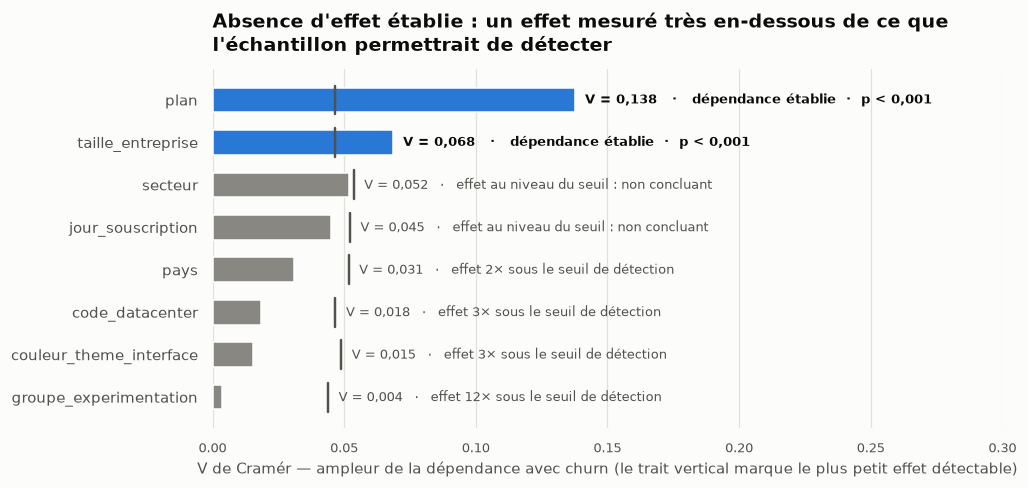

In [ ]:
# --- Taille d'effet confrontee au seuil de detection ------------------------
fig, ax = plt.subplots(figsize=(9.5, 4.6))
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)

positions = np.arange(len(resultats))[::-1]
couleurs = [ACCENT if etabli else CONTEXTE for etabli in resultats.dependance_etablie]
ax.barh(positions, resultats.V_Cramer, color=couleurs, height=0.58, zorder=2)

# Seuil de detection propre a chaque variable (il depend de ses ddl et de n).
for y, ligne in zip(positions, resultats.itertuples()):
    ax.plot(
        [ligne.V_min_detectable] * 2,
        [y - 0.34, y + 0.34],
        color=INK_2,
        linewidth=1.6,
        zorder=3,
    )
    rapport = ligne.V_min_detectable / max(ligne.V_Cramer, 1e-9)
    if ligne.dependance_etablie:
        mention = "dépendance établie  ·  p < 0,001"
    elif rapport >= 1.5:
        mention = f"effet {rapport:.0f}× sous le seuil de détection"
    else:
        mention = "effet au niveau du seuil : non concluant"
    ax.text(
        max(ligne.V_Cramer, ligne.V_min_detectable) + 0.004,
        y,
        f"V = {ligne.V_Cramer:.3f}".replace(".", ",") + f"   ·   {mention}",
        va="center",
        fontsize=8.5,
        color=INK if ligne.dependance_etablie else INK_2,
        fontweight="bold" if ligne.dependance_etablie else "normal",
    )

ax.set_yticks(positions)
ax.set_yticklabels(resultats.colonne, fontsize=9.5, color=INK_2)
ax.set_xlim(0, 0.30)
ax.set_xlabel(
    "V de Cramér — ampleur de la dépendance avec churn "
    "(le trait vertical marque le plus petit effet détectable)",
    fontsize=9.5,
    color=INK_2,
)
ax.set_title(
    "Absence d'effet établie : un effet mesuré très en-dessous de ce que\n"
    "l'échantillon permettrait de détecter",
    loc="left",
    fontsize=12.5,
    fontweight="bold",
    color=INK,
    pad=12,
)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color=GRILLE, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="x", labelsize=8.5, colors=INK_2)
for bord in ax.spines.values():
    bord.set_visible(False)
plt.tight_layout()
plt.show()

##### Interprétation

**Deux variables seulement portent une dépendance établie.** `plan` avec V = 0,138 — soit près de
**trois fois** son seuil de détection (0,047) — et `taille_entreprise` avec V = 0,068, à environ 1,5 fois
son seuil. La correction de Holm montre donc que le taux de churn dépends beaucoup de ces deux variables.

**Pour trois variables, l'absence d'effet est établie.** `code_datacenter` (V = 0,018),
`couleur_theme_interface` (V = 0,015) et `groupe_experimentation` (V = 0,004) présentent des effets
respectivement **3, 3 et 12 fois inférieurs** à ce que l'échantillon permettrait de détecter. Pour
celles-ci, la conclusion est solide : si un effet de taille détectable existait, nous l'aurions vu. C'est
bien une **preuve d'absence**.

`groupe_experimentation` est le cas d'école attendu. Un bucket de test A/B est par construction une
affectation aléatoire : il ne *peut pas* prédire le churn, sauf si l'expérimentation elle-même avait un
effet — ce que son V de 0,004 exclut. Cette variable sert ici de **témoin négatif** : elle valide que la
méthode de détection ne fabrique pas de faux signaux.

**Deux variables restent dans la zone grise** `jour_souscription`
(V = 0,045) et `secteur` (V = 0,052) ont des effets **au niveau même du seuil de détection** (0,052 et
0,054). Pour elles, on ne peut affirmer ni la présence ni l'absence d'effet : l'échantillon n'a pas la
résolution nécessaire. On ne peut pas conclure catégoriquement à l'absence d'effet, juste dire
qu'**aucune dépendance n'est établie sur cet échantillon**. Un échantillon plus grand pourrait faire basculer la balance d'un côté comme de l'autre.

**Le cas de `secteur` illustre pourquoi la correction est indispensable.** Sa p-value brute vaut **0,045**
— juste sous le seuil fatidique de 5 %. Sans correction, on aurait dit que le secteur influence
significativement le churn. Mais après correction de Holm, la p-value passe à **0,271** : la dépendance n'est
pas établie. Sans correction, ce résultat aurait été un faux positif présenté comme un acquis.

**`pays` : la conclusion de §6.3 est confirmée.** V = 0,031, effet deux fois sous le seuil, p corrigée à
1,000. La variable n'apporte aucun signal établi, ce qui conforte son exclusion — décidée en §6.3 pour des
raisons à la fois statistiques et éthiques (§4.1).

#### Une nuance sur `secteur` : deux questions, deux réponses

Le test global et le constat de §6.3 semblent se contredire — le premier ne conclut pas, le second
identifiait `Finance` comme distinct. Il faut lever l'ambiguïté plutôt que la laisser passer, car les deux
tests ne posent pas la même question et ne corrigent pas sur la même famille d'hypothèses :

- Le **khi² global** demande : *« la répartition du churn diffère-t-elle entre les sept secteurs ? »*, et sa
  correction porte sur les huit variables testées.
- Un **test binomial par modalité** demande : *« CE secteur s'écarte-t-il du taux global de 28,0 % ? »*, et
  sa correction porte sur les sept secteurs.

In [ ]:
# --- Le cas limite de `secteur` : deux questions, deux reponses -------------
# Le test global demande « le secteur a-t-il un effet ? ». Un test par
# modalite demande « CE secteur s'ecarte-t-il du taux global ? ». Les deux
# sont corriges pour tests multiples, mais sur des familles differentes.
tests_modalites = []
for modalite, groupe in df_eda.dropna(subset=["secteur"]).groupby("secteur"):
    n_churn, n_total = int(groupe.churn.sum()), len(groupe)
    tests_modalites.append(
        {
            "modalite": etiquette(modalite, "secteur"),
            "n": n_total,
            "taux_churn_%": round(100 * n_churn / n_total, 1),
            "p_brute": stats.binomtest(n_churn, n_total, PREVALENCE_GLOBALE).pvalue,
        }
    )
tests_modalites = pd.DataFrame(tests_modalites).sort_values(
    "p_brute", ignore_index=True
)
tests_modalites["p_Holm"] = correction_holm(tests_modalites.p_brute.values)
tests_modalites["ecart_etabli"] = tests_modalites.p_Holm < 0.05

print(
    f"Taux de churn global : {100 * PREVALENCE_GLOBALE:.1f} %   "
    f"({len(tests_modalites)} modalites testees)"
)
print(
    tests_modalites.assign(
        p_brute=lambda x: x.p_brute.round(4), p_Holm=lambda x: x.p_Holm.round(3)
    ).to_string(index=False)
)

ligne_secteur = resultats.loc[resultats.colonne == "secteur"].iloc[0]
print(
    f"\nTest global sur `secteur`  : V = {ligne_secteur.V_Cramer:.4f}, "
    f"p brute = {ligne_secteur.p_brute:.3f}, p Holm = {ligne_secteur.p_Holm:.3f} "
    f"-> dependance globale NON etablie"
)
print(
    f"Test sur la modalite FINANCE : p Holm = "
    f"{tests_modalites.loc[tests_modalites.modalite == 'Finance', 'p_Holm'].iloc[0]:.3f} "
    f"-> ecart au taux global ETABLI"
)

Taux de churn global : 28.0 %   (7 modalites testees)
 modalite   n  taux_churn_%  p_brute  p_Holm  ecart_etabli
  Finance 769          23.4   0.0043    0.03          True
     Tech 861          30.0   0.1972    1.00         False
Éducation 583          30.4   0.2130    1.00         False
   Public 398          26.1   0.4346    1.00         False
    Santé 568          29.4   0.4549    1.00         False
Industrie 666          29.0   0.5749    1.00         False
 Commerce 905          28.4   0.7956    1.00         False

Test global sur `secteur`  : V = 0.0520, p brute = 0.045, p Holm = 0.271 -> dependance globale NON etablie
Test sur la modalite FINANCE : p Holm = 0.030 -> ecart au taux global ETABLI


##### Interprétation

Les deux résultats ne se contredisent pas, ils répondent à deux questions distinctes. Le test global sur
`secteur` n'établit pas de dépendance (p corrigée = 0,271), tandis que la modalité **`Finance`** s'écarte
bel et bien du taux global (23,4 % contre 28,0 %, p corrigée = **0,030**) — et elle seule : les six autres
secteurs ont des p-values corrigées de 1,000.

L'explication est mécanique. Le khi² global répartit sa puissance sur six degrés de liberté, c'est-à-dire
qu'il cherche un écart *quelconque* entre les sept secteurs ; un signal concentré sur une seule modalité y
est dilué. Le test ciblé sur `Finance`, lui, ne dépense qu'un degré de liberté et retrouve le signal.

**Conséquence : ** les clients du secteur Finance résilient moins, les six
autres secteurs ne se distinguent pas. Cela confirme le statut « retenue avec prudence » attribué en
§6.3 — la variable garde une valeur explicative faible, portée par une seule de ses modalités, et son poids
dans le modèle final devra en prendre compte en §12.2.

#### Verdict et conséquences

| Variable | V de Cramér | Seuil détectable | p (Holm) | Verdict |
|---|---|---|---|---|
| `plan` | 0,138 | 0,047 | < 0,001 | **Retenue** — dépendance forte et établie |
| `taille_entreprise` | 0,068 | 0,047 | < 0,001 | **Retenue** — dépendance établie, ampleur modeste |
| `secteur` | 0,052 | 0,054 | 0,271 | **Retenue avec prudence** — portée par la seule modalité `Finance` |
| `jour_souscription` | 0,045 | 0,052 | 0,606 | **Écartée** — aucune dépendance établie, effet au niveau du seuil |
| `pays` | 0,031 | 0,052 | 1,000 | **Écartée** — effet 2× sous le seuil (+ motif éthique, §4.1) |
| `code_datacenter` | 0,018 | 0,047 | 1,000 | **Absence d'effet établie** — effet 3× sous le seuil |
| `couleur_theme_interface` | 0,015 | 0,049 | 1,000 | **Absence d'effet établie** — effet 3× sous le seuil |
| `groupe_experimentation` | 0,004 | 0,044 | 1,000 | **Absence d'effet établie** — témoin négatif de la méthode |

**Les quatre variables sans lien métier attendu (§4.4) sont donc écartées du périmètre explicatif**, dont trois
avec une conclusion statistiquement solide et une (`jour_souscription`) faute de dépendance établie. À quoi
s'ajoute `pays`, écartée pour les mêmes motifs.

**Pourquoi les écarter plutôt que laisser le modèle les ignorer ?** Un modèle à base d'arbres finirait
sans doute par leur accorder une importance quasi nulle. Trois raisons de les retirer en amont :

1. **Le sur-apprentissage.** Sur un échantillon fini, une variable sans signal réel offre malgré tout des
   points de coupure qui séparent le bruit du jeu d'entraînement. Après encodage *one-hot*, ces quatre
   variables ajoutent 19 colonnes de bruit pur.
2. **L'interprétabilité.** L'importance par permutation (§12.2) doit être lisible par les équipes CSM. Une
   variable « couleur du thème » figurant dans un classement d'importance, même en bas, décrédibilise
   l'outil et invite à des corrélations fallacieuses.
3. **Le coût d'exploitation.** Chaque variable conservée est une dépendance à une source de données amont
   qu'il faut maintenir, surveiller et documenter en production (§11.3, §13.1). On ne paie pas ce coût
   pour du bruit.

**Limite assumée de cette analyse.** Ces tests mesurent une dépendance **marginale** : chaque variable est
confrontée seule à la cible. Une variable sans effet marginal pourrait théoriquement en avoir un **en
interaction** avec une autre (par exemple un datacenter dégradant l'expérience d'un seul segment de
clients). Rien ici ne l'exclut. Le contrôle correspondant est l'**importance par permutation** sur le
modèle entraîné, conduite en §12.2 : si l'une de ces variables y ressortait, il faudrait revenir sur la
présente décision. Pour `groupe_experimentation`, en revanche, l'argument est logique et non statistique —
une affectation aléatoire ne peut porter d'information sur un événement futur, en interaction ou non.

### 6.5 Recherche de fuite de données

Deux variables sont déjà sous
surveillance — `sante_compte_fin_periode` (§6.2, corrélation de −0,78 avec la cible) et `commentaire_csm`
(§6.3, étendue de 98,6 points). Il s'agit ici de statuer.

**Une fuite est une affirmation temporelle, pas statistique.** Dire qu'une variable « fuit » signifie
qu'elle est mesurée **après** la décision que l'on prétend prédire. Une AUC élevée n'en est donc que le
*symptôme* : un excellent indicateur avancé, légitime, produirait lui aussi une AUC élevée. Le diagnostic
combine par conséquent deux éléments :

1. **Le symptôme statistique** — la variable discrimine-t-elle anormalement bien, seule ? Et jusqu'où va
   cette séparation ?
2. **La preuve sémantique** — que dit le dictionnaire de données sur le moment de la mesure ?

Le premier met sur la piste, le second tranche : une fuite se démontre par le **calendrier** de la mesure,
pas par une statistique.

                    variable  n_renseignes  auc_orientee       sens  suspecte
    sante_compte_fin_periode          5000        0.9986 protecteur      True
             nb_integrations          4800        0.7587 protecteur     False
             anciennete_mois          5000        0.7139 protecteur     False
            heures_usage_30j          4700        0.6968 protecteur     False
              connexions_30j          5000        0.6958 protecteur     False
   fonctionnalites_utilisees          5000        0.6918 protecteur     False
           taux_adoption_pct          4750        0.6849 protecteur     False
                        csat          4600        0.6705 protecteur     False
    derniere_connexion_jours          5000        0.6703  aggravant     False
         tickets_support_90j          5000        0.6614  aggravant     False
        retards_paiement_12m          4750        0.6612  aggravant     False
     delai_reponse_support_h          4500        0.6517  aggrav

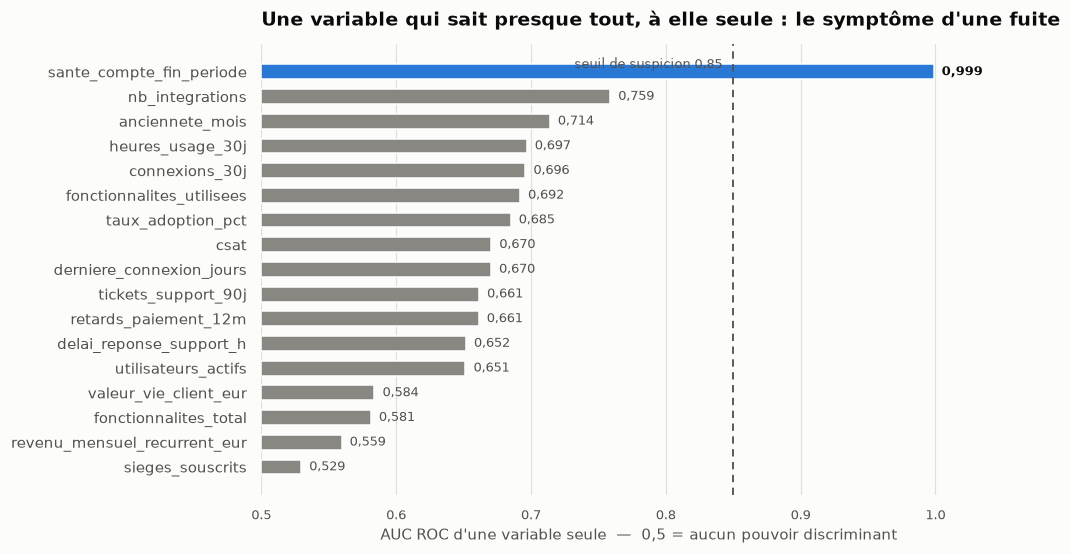

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve

# --- AUC univariee : ce qu'une variable seule sait de la cible --------------
# L'AUC est orientee (max(auc, 1 - auc)) : pour un diagnostic de fuite, seule
# compte la capacite a discriminer, pas le sens de la relation.
SEUIL_SUSPICION = 0.85

auc_univariees = []
for col in COLONNES_NUMERIQUES:
    renseignes = df_eda[col].notna()
    auc_brute = roc_auc_score(df_eda.churn[renseignes], df_eda.loc[renseignes, col])
    auc_univariees.append(
        {
            "variable": col,
            "n_renseignes": int(renseignes.sum()),
            "auc_orientee": round(max(auc_brute, 1 - auc_brute), 4),
            "sens": "protecteur" if auc_brute < 0.5 else "aggravant",
        }
    )
auc_univariees = pd.DataFrame(auc_univariees).sort_values(
    "auc_orientee", ascending=False, ignore_index=True
)
auc_univariees["suspecte"] = auc_univariees.auc_orientee > SEUIL_SUSPICION
print(auc_univariees.to_string(index=False))

ecart = auc_univariees.auc_orientee.iloc[0] - auc_univariees.auc_orientee.iloc[1]
print(f"\nEcart entre la 1re et la 2e variable : {ecart:.4f} point d'AUC")
print(
    f"Variables au-dela du seuil de suspicion ({SEUIL_SUSPICION}) : "
    f"{list(auc_univariees.loc[auc_univariees.suspecte, 'variable'])}"
)

fig, ax = plt.subplots(figsize=(9.5, 5.2))
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)
positions = np.arange(len(auc_univariees))[::-1]
couleurs = [ACCENT if s else CONTEXTE for s in auc_univariees.suspecte]
ax.barh(
    positions,
    auc_univariees.auc_orientee - 0.5,
    left=0.5,
    color=couleurs,
    height=0.6,
    zorder=2,
)
ax.axvline(SEUIL_SUSPICION, color=INK_2, linewidth=1.2, linestyle=(0, (4, 3)), zorder=3)

for y, ligne in zip(positions, auc_univariees.itertuples()):
    ax.text(
        ligne.auc_orientee + 0.006,
        y,
        f"{ligne.auc_orientee:.3f}".replace(".", ","),
        va="center",
        fontsize=8.5,
        color=INK if ligne.suspecte else INK_2,
        fontweight="bold" if ligne.suspecte else "normal",
    )

ax.set_yticks(positions)
ax.set_yticklabels(auc_univariees.variable, fontsize=9.5, color=INK_2)
ax.set_xlim(0.5, 1.06)
ax.set_xticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
ax.set_xlabel(
    "AUC ROC d'une variable seule  —  0,5 = aucun pouvoir discriminant",
    fontsize=9.5,
    color=INK_2,
)
ax.set_title(
    "Une variable qui sait presque tout, à elle seule : le symptôme d'une fuite",
    loc="left",
    fontsize=12.5,
    fontweight="bold",
    color=INK,
    pad=12,
)
ax.text(
    SEUIL_SUSPICION - 0.008,
    positions[0] + 0.15,
    "seuil de suspicion 0,85",
    fontsize=8.5,
    color=INK_2,
    ha="right",
)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color=GRILLE, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="x", labelsize=8.5, colors=INK_2)
for bord in ax.spines.values():
    bord.set_visible(False)
plt.tight_layout()
plt.show()

##### Interprétation

`sante_compte_fin_periode` atteint une AUC univariée de 0,9986.** Cette
seule variable, sans aucune autre, discrimine les comptes résiliés des comptes conservés presque
parfaitement. La deuxième du classement, `nb_integrations`, plafonne à 0,759 — un écart de **0,24 point
d'AUC**, alors que les quinze autres variables se répartissent de façon continue entre 0,53 et 0,76.

**La preuve sémantique confirme le symptôme.** Le dictionnaire de données décrit cette variable comme un
« score santé calculé **en FIN de période** ». La fin de période est postérieure à la décision de
résiliation. Au moment où les équipes Customer Success doivent agir — avant l'échéance — ce score
**n'existe pas encore**. L'utiliser reviendrait à construire un modèle qui exige, pour fonctionner, une
information qui ne sera disponible que lorsqu'il sera trop tard pour agir.

**Aucune autre variable numérique ne dépasse le seuil de suspicion**, y compris `valeur_vie_client_eur`
(0,584) : la cible secondaire, bien que connue *a posteriori* elle aussi, n'aurait de toute façon apporté
qu'un signal faible. Son exclusion, imposée par sa nature de résultat postérieur à la décision, ne coûte donc rien.

#### Jusqu'où va la séparation ?

Une AUC de 0,9986 reste une mesure abstraite. La question concrète est plus parlante : cette variable
permet-elle à elle seule une **règle de décision triviale** ?

Regle « churn si sante_compte_fin_periode <= 32 » :
  erreurs    : 72 sur 5000 comptes (1.44 %)
  exactitude : 98.56 % (contre 72,0 % pour le classifieur trivial de §6.1)

Zone de recouvrement entre les deux classes :
  score maximal d'un compte resilie  : 55
  score minimal d'un compte conserve : 23
  comptes dans cette zone            : 1529 sur 5000

        count  mean   std   min   50%    max
churn                                       
0      3600.0  60.1  12.2  23.0  60.0  100.0
1      1400.0  11.7  10.0   0.0  10.0   55.0


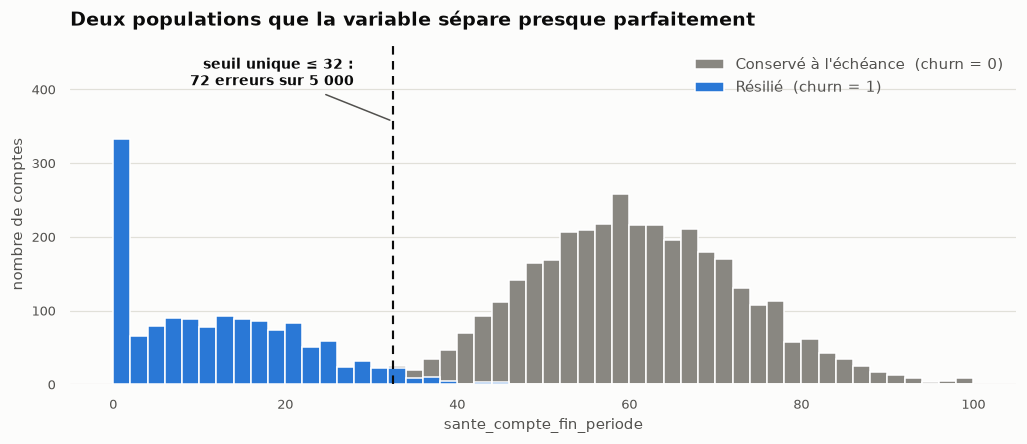

In [ ]:
# --- Jusqu'ou va la separation ? --------------------------------------------
# Une AUC de 0,999 se traduit-elle par une regle triviale ? On cherche le
# meilleur seuil unique sur la variable suspecte et on compte ses erreurs.
score_sante = df_eda.sante_compte_fin_periode
seuils = np.arange(0, 101)
erreurs = np.array(
    [int(((score_sante <= s).astype(int) != df_eda.churn).sum()) for s in seuils]
)
meilleur = int(erreurs.argmin())
score_max_resilie = score_sante[df_eda.churn == 1].max()
score_min_conserve = score_sante[df_eda.churn == 0].min()

print(f"Regle « churn si sante_compte_fin_periode <= {seuils[meilleur]} » :")
print(
    f"  erreurs    : {erreurs[meilleur]} sur {len(df_eda)} comptes "
    f"({100 * erreurs[meilleur] / len(df_eda):.2f} %)"
)
print(
    f"  exactitude : {100 * (1 - erreurs[meilleur] / len(df_eda)):.2f} % "
    f"(contre 72,0 % pour le classifieur trivial de §6.1)"
)
print(f"\nZone de recouvrement entre les deux classes :")
print(f"  score maximal d'un compte resilie  : {score_max_resilie:.0f}")
print(f"  score minimal d'un compte conserve : {score_min_conserve:.0f}")
print(
    f"  comptes dans cette zone            : "
    f"{int(score_sante.between(score_min_conserve, score_max_resilie).sum())} "
    f"sur {len(df_eda)}"
)
print()
print(
    df_eda.groupby("churn")
    .sante_compte_fin_periode.describe()[["count", "mean", "std", "min", "50%", "max"]]
    .round(1)
    .to_string()
)

fig, ax = plt.subplots(figsize=(9.5, 4.2))
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)
bornes = np.arange(0, 102, 2)
ax.hist(
    score_sante[df_eda.churn == 0],
    bins=bornes,
    color=CONTEXTE,
    label="Conservé à l'échéance  (churn = 0)",
    zorder=2,
)
ax.hist(
    score_sante[df_eda.churn == 1],
    bins=bornes,
    color=ACCENT,
    label="Résilié  (churn = 1)",
    zorder=2,
)
haut = ax.get_ylim()[1]
ax.set_ylim(0, haut * 1.32)  # degagement pour l'annotation et la legende
ax.axvline(
    seuils[meilleur] + 0.5, color=INK, linewidth=1.4, linestyle=(0, (4, 3)), zorder=4
)
ax.annotate(
    f"seuil unique ≤ {seuils[meilleur]} :\n{erreurs[meilleur]} erreurs sur 5 000",
    xy=(seuils[meilleur] + 0.5, haut * 1.02),
    xytext=(seuils[meilleur] - 4, haut * 1.16),
    ha="right",
    fontsize=9,
    color=INK,
    fontweight="bold",
    arrowprops=dict(arrowstyle="-", color=INK_2, linewidth=1),
)
ax.set_xlabel("sante_compte_fin_periode", fontsize=9.5, color=INK_2)
ax.set_ylabel("nombre de comptes", fontsize=9.5, color=INK_2)
ax.set_title(
    "Deux populations que la variable sépare presque parfaitement",
    loc="left",
    fontsize=12.5,
    fontweight="bold",
    color=INK,
    pad=12,
)
ax.legend(frameon=False, fontsize=9.5, labelcolor=INK_2, loc="upper right")
ax.grid(axis="x", visible=False)
ax.grid(axis="y", color=GRILLE, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(labelsize=8.5, colors=INK_2)
for bord in ax.spines.values():
    bord.set_visible(False)
plt.tight_layout()
plt.show()

##### Interprétation

**Un unique seuil suffit.** La règle « le compte résilie si `sante_compte_fin_periode ≤ 32` » se trompe sur
**72 comptes sur 5 000**, soit **1,44 %** d'erreur — une exactitude de 98,56 %, à comparer aux 72,0 % du
classifieur trivial de §6.1. Aucun apprentissage, aucun modèle, aucune préparation de données : une simple
comparaison à une constante.

Le graphique le montre sans détour : les comptes résiliés s'entassent entre 0 et 32, les comptes conservés
au-delà de 40, et la zone de recouvrement est presque vide. Le score maximal d'un compte résilié est **55**,
le score minimal d'un compte conservé **23** — soit une bande de chevauchement de seulement 32 points sur
une échelle de 100.

**Ce n'est pas ainsi que se comporte un indicateur avancé.** Un score de santé calculé *avant* l'échéance
serait, par nature, imparfait : certains comptes en mauvaise santé se reprennent, certains comptes sains
partent pour des raisons indépendante du logiciel et de son utilisation — rachat, changement de direction, coupe budgétaire. Une séparation à
1,44 % d'erreur n'exprime pas une bonne prédiction, elle exprime la **connaissance du résultat**.

##### Interprétation

Le raisonnement se tient donc en deux temps.

**Le symptôme statistique.** Une AUC univariée de 0,9986, un décrochage de 0,24 point avec la variable
suivante, et une règle à un seul seuil qui se trompe sur 1,44 % des comptes. Aucun indicateur avancé
authentique ne se comporte ainsi : un compte en difficulté se redresse parfois, un compte sain part pour
une raison exogène. Une telle séparation n'exprime pas une bonne prédiction, mais la **connaissance du
résultat**.

**La preuve sémantique.** Le dictionnaire de données décrit la variable comme un score « calculé **en fin
de période** ». La fin de période est postérieure à la décision de résiliation : au moment où les équipes
doivent agir, ce score n'existe pas encore.

Le premier élément seul ne suffirait pas — il pourrait décrire un excellent indicateur avancé. Le second
seul non plus — un libellé de dictionnaire peut être imprécis. Ensemble, ils ne laissent pas d'alternative
raisonnable. **`sante_compte_fin_periode` est écartée.**

#### Combien coûte la fuite ?

Reste à mesurer l'effet de ces variables sur un modèle, et à vérifier ce qu'il advient de la performance
lorsqu'on les retire. Le pipeline utilisé est **volontairement minimal** : son rôle est le diagnostic, non
la sélection de modèle — celle-ci relève de §8 et §9. 

AUC ROC en validation croisée stratifiée (5 plis) :
modele                           gradient boosting  régression logistique
scenario                                                                 
A. variables légitimes seules               0.8753                 0.8900
B. + sante_compte_fin_periode               0.9991                 0.9996
C. + commentaire_csm                        0.8768                 0.8884
D. les deux variables suspectes             0.9989                 0.9995

                       scenario                modele  auc_moyenne  ecart_type
  A. variables légitimes seules régression logistique       0.8900      0.0121
  A. variables légitimes seules     gradient boosting       0.8753      0.0092
  B. + sante_compte_fin_periode régression logistique       0.9996      0.0006
  B. + sante_compte_fin_periode     gradient boosting       0.9991      0.0008
           C. + commentaire_csm régression logistique       0.8884      0.0114
           C. + commentaire_c

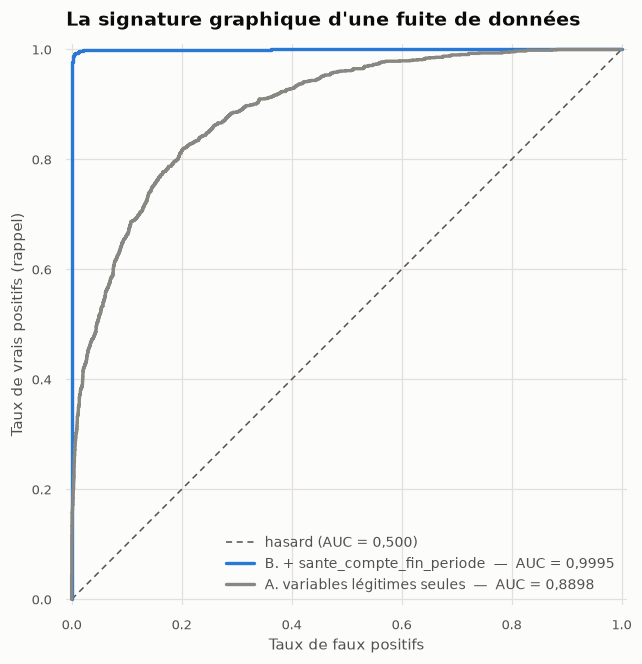

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# --- Combien coute la fuite ? -----------------------------------------------
# Pipeline volontairement minimal : son seul role est le diagnostic, pas la
# selection de modele (§8-9). L'imputation et l'encodage sont DANS le pipeline,
# donc reajustes a chaque pli : le diagnostic lui-meme ne fuit pas.
# Perimetre legitime : tout sauf les deux cibles, la variable suspecte et la
# colonne deterministe du plan (§6.2).
VARIABLES_LEGITIMES_NUM = [
    c
    for c in COLONNES_NUMERIQUES
    if c not in ("sante_compte_fin_periode", "valeur_vie_client_eur", "fonctionnalites_total")
]
VARIABLES_LEGITIMES_CAT = ["plan", "taille_entreprise", "secteur"]
df_eda["commentaire_csm"] = df_brut.loc[df_eda.index, "commentaire_csm"].fillna(
    "AUCUN COMMENTAIRE"
)


def pipeline_diagnostic(numeriques, categorielles, modele):
    """Chaine minimale : imputation -> mise a l'echelle / one-hot -> modele."""
    preparation = ColumnTransformer(
        [
            (
                "num",
                Pipeline(
                    [
                        ("imputation", SimpleImputer(strategy="median")),
                        ("echelle", StandardScaler()),
                    ]
                ),
                numeriques,
            ),
            (
                "cat",
                Pipeline(
                    [
                        ("imputation", SimpleImputer(strategy="most_frequent")),
                        ("encodage", OneHotEncoder(handle_unknown="ignore")),
                    ]
                ),
                categorielles,
            ),
        ]
    )
    return Pipeline([("preparation", preparation), ("modele", modele)])


SCENARIOS = {
    "A. variables légitimes seules": (VARIABLES_LEGITIMES_NUM, VARIABLES_LEGITIMES_CAT),
    "B. + sante_compte_fin_periode": (
        VARIABLES_LEGITIMES_NUM + ["sante_compte_fin_periode"],
        VARIABLES_LEGITIMES_CAT,
    ),
    "C. + commentaire_csm": (
        VARIABLES_LEGITIMES_NUM,
        VARIABLES_LEGITIMES_CAT + ["commentaire_csm"],
    ),
    "D. les deux variables suspectes": (
        VARIABLES_LEGITIMES_NUM + ["sante_compte_fin_periode"],
        VARIABLES_LEGITIMES_CAT + ["commentaire_csm"],
    ),
}
MODELES = {
    "régression logistique": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "gradient boosting": HistGradientBoostingClassifier(random_state=SEED),
}

plis = StratifiedKFold(5, shuffle=True, random_state=SEED)
mesures = []
for nom_scenario, (numeriques, categorielles) in SCENARIOS.items():
    for nom_modele, modele in MODELES.items():
        scores = cross_val_score(
            pipeline_diagnostic(numeriques, categorielles, modele),
            df_eda[numeriques + categorielles],
            df_eda.churn,
            cv=plis,
            scoring="roc_auc",
        )
        mesures.append(
            {
                "scenario": nom_scenario,
                "modele": nom_modele,
                "auc_moyenne": round(scores.mean(), 4),
                "ecart_type": round(scores.std(), 4),
            }
        )
mesures = pd.DataFrame(mesures)
print("AUC ROC en validation croisée stratifiée (5 plis) :")
print(
    mesures.pivot(index="scenario", columns="modele", values="auc_moyenne").to_string()
)
print()
print(mesures.to_string(index=False))

# --- Courbes ROC : la fuite se voit a l'oeil nu
probabilites = {}
for etiquette_scenario in (
    "A. variables légitimes seules",
    "B. + sante_compte_fin_periode",
):
    numeriques, categorielles = SCENARIOS[etiquette_scenario]
    probabilites[etiquette_scenario] = cross_val_predict(
        pipeline_diagnostic(
            numeriques, categorielles, MODELES["régression logistique"]
        ),
        df_eda[numeriques + categorielles],
        df_eda.churn,
        cv=plis,
        method="predict_proba",
    )[:, 1]

fig, ax = plt.subplots(figsize=(6.6, 6.2))
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)
ax.plot(
    [0, 1],
    [0, 1],
    color=INK_2,
    linewidth=1,
    linestyle=(0, (4, 3)),
    label="hasard (AUC = 0,500)",
)
for etiquette_scenario, couleur in (
    ("B. + sante_compte_fin_periode", ACCENT),
    ("A. variables légitimes seules", CONTEXTE),
):
    faux_positifs, vrais_positifs, _ = roc_curve(
        df_eda.churn, probabilites[etiquette_scenario]
    )
    auc = roc_auc_score(df_eda.churn, probabilites[etiquette_scenario])
    auc_fr = f"{auc:.4f}".replace(".", ",")
    ax.plot(
        faux_positifs,
        vrais_positifs,
        color=couleur,
        linewidth=2.2,
        label=f"{etiquette_scenario}  —  AUC = {auc_fr}",
    )
ax.set_xlabel("Taux de faux positifs", fontsize=9.5, color=INK_2)
ax.set_ylabel("Taux de vrais positifs (rappel)", fontsize=9.5, color=INK_2)
ax.set_title(
    "La signature graphique d'une fuite de données",
    loc="left",
    fontsize=12.5,
    fontweight="bold",
    color=INK,
    pad=12,
)
ax.legend(frameon=False, fontsize=9, labelcolor=INK_2, loc="lower right")
ax.grid(color=GRILLE, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(labelsize=8.5, colors=INK_2)
ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.01)
ax.set_aspect("equal")
for bord in ax.spines.values():
    bord.set_visible(False)
plt.tight_layout()
plt.show()

##### Interprétation

| Scénario | Régression logistique | Gradient boosting |
|---|---|---|
| **A.** variables légitimes seules | 0,8900 | 0,8753 |
| **B.** + `sante_compte_fin_periode` | **0,9996** | **0,9991** |
| **C.** + `commentaire_csm` | 0,8884 | 0,8768 |
| **D.** les deux variables suspectes | 0,9995 | 0,9989 |

**1. La fuite fabrique un modèle parfait — et inutilisable.** Ajouter la seule variable
`sante_compte_fin_periode` fait passer l'AUC de 0,890 à **0,9996**, avec un écart-type entre plis réduit à
0,0006. Ce chiffre décrirait le meilleur modèle du monde sur un jeu de test,
et un modèle **incapable de produire un seul score en production**, puisque la variable dont il dépend
n'existe pas au moment de la décision. La courbe ROC en donne la signature graphique : elle épouse le coin
supérieur gauche, ce qu'aucun problème métier réel ne produit.

**2. Le coût de l'exclusion est de 11 points d'AUC.** Le modèle honnête plafonne à
0,890. Ce n'est pas une contre-performance : c'est la performance réellement atteignable avec
l'information réellement disponible avant la décision. C'est cette valeur qui sert de référence à §8 et
§9, et le rôle de la baseline de §8.1 est précisément d'établir ce plancher honnête.

**3. Résultat inattendu : `commentaire_csm` n'apporte rien.** L'AUC passe de 0,8900 à 0,8884 en régression
logistique et de 0,8753 à 0,8768 en gradient boosting — deux variations **inférieures à l'écart-type entre
plis** (± 0,011). Cela nuance ce que §6.3 laissait entendre sur la seule lecture marginale, et l'explication
est instructive : le CSM écrit « faible adoption des sièges » précisément quand les métriques d'adoption
sont basses. **Son information est déjà contenue dans les variables d'usage** — elle est redondante, non
incrémentale. Quant aux deux modalités à séparation quasi parfaite, elles ne concernent que 60 comptes,
soit 1,2 % de l'échantillon : trop peu pour déplacer une AUC globale.

**Conséquence sur la décision d'exclusion de `commentaire_csm`.** Elle est maintenue, mais sa
**justification change de nature**. Il ne s'agit pas de renoncer à de la performance par prudence — le
retrait ne coûte rien de mesurable. Dès lors, les deux motifs déjà établis suffisent et deviennent
prépondérants : le **risque éthique** d'industrialiser le jugement subjectif des CSM (§4.1) et l'**absence
d'horodatage** qui interdit d'établir que la note précède la décision (§6.3). Écarter la variable ne demande donc
aucun arbitrage entre performance et responsabilité.

#### Verdict de §6.5

| Variable | AUC univariée | Symptôme | Preuve temporelle | Apport au modèle | Décision |
|---|---|---|---|---|---|
| `sante_compte_fin_periode` | **0,9986** | Séparation à 1,44 % d'erreur avec un seuil unique ; décrochage de 0,24 pt avec la 2ᵉ variable | Dictionnaire : « calculé **en fin de période** » | +0,110 d'AUC | **Exclue — fuite établie** |
| `commentaire_csm` | — (catégorielle, étendue 98,6 pts) | 2 modalités quasi séparantes, mais sur 60 comptes | Aucun horodatage disponible | −0,002 (dans le bruit) | **Exclue — éthique (§4.1) + fuite non écartable** |
| `valeur_vie_client_eur` | 0,584 | Aucun | Connue *a posteriori* | non testé (imposé) | **Exclue — cible secondaire (§12.4)** |
| `client_id` | — | Aucun | — | — | **Exclue — identifiant** |

**Performance de référence retenue pour la suite du notebook : AUC ≈ 0,890** en validation croisée, sur les
variables légitimes uniquement. Tout résultat sensiblement supérieur dans les sections suivantes devra être
tenu pour suspect et donner lieu à une nouvelle recherche de fuite.

**Ce contrôle doit devenir permanent (§13.1).** La fuite a été trouvée ici parce que le dictionnaire de
données mentionnait « fin de période ». En production, une variable amont peut devenir fuyante sans
avertissement — un champ recalculé, une extraction dont la fenêtre temporelle glisse, un score enrichi en
aval. Le dispositif de surveillance doit donc inclure un **contrôle d'AUC univariée** sur chaque variable
d'entrée à chaque ré-entraînement : toute variable franchissant le seuil de suspicion déclenche une
vérification de son horodatage avant réintégration.

### 6.6 Synthèse de l'EDA

**Ce que l'analyse a établi**, et qui commande toute la suite du document.

#### 1. Le problème contient du signal, mais diffus

Aucune variable ne donne la réponse à elle seule. Hors variable de fuite, la corrélation la plus forte
avec la cible plafonne à **−0,41** (`nb_integrations`) et la meilleure AUC univariée à **0,759**. La
performance devra venir de la **combinaison** des signaux, pas d'un indicateur dominant — ce qui écarte
d'emblée l'idée d'une règle métier simple, et justifie la baseline « règle à une variable » de §8.1.

#### 2. Deux variables sont écartées pour fuite, et l'une aurait tout faussé

| Variable | Constat | Décision |
|---|---|---|
| `sante_compte_fin_periode` | AUC univariée **0,9986** ; un seuil unique sépare les classes avec 1,44 % d'erreur ; décrochage de 0,24 point avec la variable suivante | **Exclue** — calculée en fin de période, donc postérieure à la décision |
| `commentaire_csm` | Étendue de 98,6 points entre modalités, mais **apport nul** au modèle (−0,002 d'AUC, sous le bruit) | **Exclue** — aucun horodatage ne permet d'établir qu'elle précède la décision (§4.1) |

La première aurait porté l'AUC à 0,9996 : un modèle parfait sur le papier, **incapable de produire un
seul score en production**. Son exclusion coûte 11 points d'AUC et fixe la référence honnête du
projet — **≈ 0,890** —, garde-fou utilisé jusqu'en §12.

#### 3. Quatre variables n'ont aucun effet sur la résiliation, et on peut le démontrer

`code_datacenter`, `couleur_theme_interface`, `groupe_experimentation` et `jour_souscription` ne portent
aucune dépendance établie. Le point méthodologique est que ce n'est pas une absence de preuve mais une
**preuve d'absence** : leur effet mesuré est 3 à 12 fois inférieur au plus petit effet que l'échantillon
permettrait de détecter (§6.4). `pays` les rejoint, pour un motif à la fois statistique et éthique.

#### 4. Les hypothèses métier confirmées

| Hypothèse | Verdict |
|---|---|
| L'inactivité précède la résiliation | **Confirmée** — `derniere_connexion_jours` est le facteur dominant du modèle final |
| L'intégration à l'écosystème retient le client | **Confirmée** — `nb_integrations` est la variable protectrice la plus forte |
| Le niveau de formule structure le risque | **Confirmée et monotone** — 37,5 % de churn en Starter, 26,7 % en Pro, 23,2 % en Business, 20,0 % en Enterprise, ce qui justifie un encodage ordinal (§7.4) |
| Le secteur d'activité influence le churn | **Infirmée en l'état** — seule la modalité `Finance` s'écarte du taux global ; le test global ne conclut pas |
| La satisfaction déclarée a une valeur prédictive | **Confirmée** — `csat` figure parmi les facteurs retenus, malgré 8 % de manquants |

#### 5. Trois acquis qui simplifient la préparation

- **`taux_adoption_pct` est le calcul exact** de `100 × utilisateurs_actifs / sieges_souscrits` (écart
  maximal 0,05 pt) : ses 250 manquants se **reconstituent** au lieu d'être imputés (§7.2).
- **La manquance n'est pas informative** : sur les dix colonnes concernées, tous les intervalles de
  confiance contiennent le taux global de 28,0 %. Une imputation simple suffit, sans indicateur de
  manquance (§7.2).
- **La normalisation de la casse ramène 56 graphies à 15 modalités** et rend la jointure du catalogue
  possible — sans elle, 12 des 16 graphies de `plan` resteraient orphelines (§7.5).

#### 6. Le déséquilibre est modéré, et cela oriente les métriques

Prévalence de **28,0 %**, ratio 2,57 : 1. Loin d'un cas de détection de fraude — ce qui **disqualifie
l'exactitude** (72 % pour un classifieur trivial), impose la PR-AUC à côté de la ROC-AUC, et rend
inutile tout rééquilibrage de classes : le levier pour privilégier le rappel sera le **seuil** (§9.3).

> **En une phrase.** Le signal existe, il est distribué sur une dizaine de variables d'usage, de support
> et de facturation ; deux variables séduisantes sont des pièges temporels ; et la performance
> réellement atteignable se situe autour de **0,89 d'AUC** — tout résultat supérieur dans la suite du
> document devra être tenu pour suspect.

> **Journal de bord — EDA**
>
> | Date | Décision / action | Justification | Conséquence |
> |---|---|---|---|
> | 10/09 | **Exactitude disqualifiée** comme métrique ; ROC-AUC retenue et complétée par la **PR-AUC** | Prévalence de 28,0 % : un classifieur trivial « aucun churn » atteint 72,0 % d'exactitude sans rien détecter. La PR-AUC se lit contre un aléatoire à 0,280 et reste sensible à la classe minoritaire | Grille de métriques fixée pour §8, §9 et §12.1 ; la séparation train/test devra être **stratifiée** pour préserver cette prévalence (§7.8) |
> | 10/09 | Corrélations mesurées avec **Spearman** plutôt que Pearson | Cinq variables ont une asymétrie supérieure à 3 et des rapports max/Q3 allant jusqu'à 43 : Pearson y serait dominé par les points extrêmes. Spearman ne mesure qu'une relation monotone et y résiste | Lecture des dépendances robuste sans transformation préalable ; oriente vers des modèles insensibles à la monotonie (arbres) ou vers une mise à l'échelle explicite pour les modèles linéaires (§8.2) |
> | 10/09 | `taux_adoption_pct` reconnue comme **redondance déterministe** de `utilisateurs_actifs / sieges_souscrits` (écart max 0,05 pt) | La colonne n'est pas corrélée à l'adoption : elle **est** l'adoption. Une imputation statistique serait absurde là où un recalcul exact est possible | Ses 250 valeurs manquantes sont reconstituées par calcul et non imputées (§7.2) ; aucune information n'est perdue et aucun bruit n'est introduit |
> | 10/09 | Chaque taux de churn par modalité assorti d'un **intervalle de confiance de Wilson à 95 %** | Un taux brut n'est pas interprétable sans son incertitude : `GE` compte 360 comptes et `France` 2 691. Wilson reste valide sur petits effectifs et ne sort jamais de [0, 1] | Évite de bâtir une conclusion métier sur un écart non concluant ; fonde la distinction entre variables retenues et variables sans effet (§6.3, §6.4) |
> | 10/09 | **Manquance testée** colonne par colonne, et conclue **non informative** (10 colonnes, tous les IC contenant le taux global de 28,0 %) | Si l'absence de valeur prédisait le churn, une imputation par la médiane détruirait ce signal et il faudrait dix indicateurs binaires de manquance | Imputation simple validée pour §7.2 (médiane / modalité « inconnu ») ; **aucun indicateur de manquance ajouté** — dix colonnes de bruit et un sur-apprentissage probable évités |
> | 10/09 | Diagnostic d'absence d'effet fondé sur **trois mesures** (p-value du khi², V de Cramér, V minimal détectable à 80 % de puissance) et corrigé par **Holm-Bonferroni** | « Pas de preuve d'effet » n'est pas « preuve d'absence d'effet » : seul le V minimal détectable autorise à conclure à l'absence. Huit tests à 5 % donnent 34 % de risque de faux positif global | `code_datacenter`, `couleur_theme_interface` et `groupe_experimentation` **écartées sur preuve d'absence** (effets 3 à 12 fois sous le seuil) ; `jour_souscription` et `pays` écartées faute de dépendance établie (§7.6) |
> | 10/09 | Zone grise **documentée** pour `secteur` et `jour_souscription` (effets au niveau même du seuil de détection) | L'échantillon n'a pas la résolution nécessaire ; conclure à l'absence d'effet serait un abus de langage. Le test binomial par modalité montre en outre que seul `Finance` se détache (p Holm = 0,030 contre 0,271 au test global) | `secteur` retenue **avec prudence**, avec une formulation restreinte : « les clients Finance résilient moins », et non « le secteur influence le churn ». Son poids sera réexaminé en §12.2 |
> | 10/09 | `sante_compte_fin_periode` **exclue — fuite établie**, sur deux preuves convergentes | Symptôme statistique (AUC univariée 0,9986, discontinuité de 0,24 pt avec la 2ᵉ variable ; un seuil unique se trompe sur 1,44 % des comptes) et preuve sémantique (« calculé en fin de période », donc postérieur à la décision) | Exclusion actée en §7.6. **Coût assumé : 11 points d'AUC** (0,9996 → 0,890) — ce n'est pas une contre-performance mais la performance réellement atteignable avant la décision |
> | 10/09 | `commentaire_csm` exclue, mais la **justification change de nature** après mesure | Son apport incrémental est nul (AUC 0,8900 → 0,8884, sous l'écart-type entre plis) : son information est déjà portée par les métriques d'adoption, et ses deux modalités quasi séparantes ne couvrent que 60 comptes | Aucun arbitrage entre performance et responsabilité : les motifs **éthique** (§4.1) et **d'horodatage absent** suffisent et deviennent prépondérants. Réintégration conditionnée à la journalisation des dates de rédaction (§13) |
> | 10/09 | **Référence de performance honnête fixée à AUC ≈ 0,890** (validation croisée, variables légitimes seules) | Sans repère, une fuite résiduelle passerait pour une réussite de modélisation | Sert de garde-fou à §8 et §9 : tout résultat sensiblement supérieur déclenche une nouvelle recherche de fuite. Un **contrôle d'AUC univariée par variable** est inscrit au monitoring (§13.1), la fuite ayant été trouvée ici grâce au dictionnaire, ressource absente en production |

---

## 7. Préparation des données
Ordre retenu : **doublons → parsing des types → normalisation des catégorielles → jointure catalogue →
exclusion anti-fuite → séparation train/test → imputation & encodage (dans le pipeline)**.

> ⚠️ L'imputation et l'encodage sont intégrés à un `Pipeline` scikit-learn **ajusté sur le train uniquement**,
> afin d'éviter toute fuite du jeu de test vers les statistiques d'imputation.

### 7.1 Détection et suppression des doublons

Deux notions sont à distinguer, et elles n'appellent pas le même traitement :

| Type de doublon | Définition | Traitement |
|---|---|---|
| **Doublon strict** | Ligne identique sur les **29 colonnes** | Suppression — la copie n'apporte aucune information |
| **Doublon d'identifiant** | Même `client_id`, mais contenu différent | Conflit : il faut **arbitrer** quelle version conserver |

Le second cas est le plus délicat : deux lignes contradictoires pour un même compte signalent une
extraction incohérente, et supprimer l'une au hasard revient à choisir arbitrairement une vérité.

**Pourquoi dédoublonner en tout premier, avant toute autre opération ?** Parce qu'un doublon survivant
jusqu'à la séparation train/test (§7.8) placerait **le même compte des deux côtés** : le modèle serait
évalué sur une ligne qu'il a déjà vue à l'entraînement, et sa performance de test serait surestimée.
C'est une fuite de données au sens strict, distincte de celle traitée en §6.5 mais tout aussi
disqualifiante.


In [ ]:
# --- Deux notions de doublon, deux traitements ------------------------------
df_prep = df_brut.copy()
n_depart = len(df_prep)

# (1) Doublon STRICT : ligne identique sur les 29 colonnes.
masque_strict = df_prep.duplicated(keep=False)
n_lignes_impliquees = int(masque_strict.sum())
df_prep = df_prep.drop_duplicates(keep="first").copy()
n_supprimes = n_depart - len(df_prep)

print(f"Lignes au depart                        : {n_depart}")
print(f"Lignes impliquees dans un doublon strict : {n_lignes_impliquees}")
print(f"Lignes supprimees (copies excedentaires) : {n_supprimes}")
print(f"Lignes conservees                        : {len(df_prep)}")

# (2) Doublon d'IDENTIFIANT : meme client_id, contenu different -> conflit.
conflits = df_prep.client_id.duplicated(keep=False)
print(
    f"\nComptes portant le meme client_id avec un contenu different : "
    f"{int(conflits.sum())}"
)
if conflits.any():
    print(df_prep[conflits].sort_values("client_id").to_string())

# --- Controles : un identifiant, une ligne ----------------------------------
assert df_prep.client_id.is_unique, "des client_id restent dupliques apres traitement"
assert len(df_prep) == df_prep.client_id.nunique()
print(
    f"\nControle : {df_prep.client_id.nunique()} identifiants distincts pour "
    f"{len(df_prep)} lignes -> un compte = une ligne."
)


Lignes au depart                        : 5035
Lignes impliquees dans un doublon strict : 70
Lignes supprimees (copies excedentaires) : 35
Lignes conservees                        : 5000

Comptes portant le meme client_id avec un contenu different : 0

Controle : 5000 identifiants distincts pour 5000 lignes -> un compte = une ligne.


#### Constat

**35 lignes en doublon strict, supprimées.** Elles étaient identiques sur les 29 colonnes : leur
suppression est **sans perte d'information**. Le jeu passe de 5 035 à 5 000 lignes.

**Aucun doublon d'identifiant ne subsiste** : les 5 000 lignes portent 5 000 `client_id` distincts.
C'est le cas favorable — il n'y a aucun conflit à arbitrer, aucune règle de sélection à justifier. Si
des lignes contradictoires avaient existé, il aurait fallu choisir explicitement une règle (conserver
la plus récente, la plus complète, ou écarter le compte) et en documenter l'effet.

Les deux `assert` figent l'invariant **« un compte = une ligne »** pour toute la suite du notebook : la
granularité est désormais garantie, condition nécessaire à la validité de la séparation train/test
(§7.8) comme à celle des agrégats calculés ensuite.

### 7.2 Parsing des variables numériques stockées en texte (%, €, unités, virgules décimales)

La fonction `to_numeric_fr` et son contrôle `controle_conversion` sont définis en **§6.2**, où l'analyse
exploratoire les exigeait ; ils ne sont pas redéfinis ici. Cette étape les applique à l'ensemble du jeu
au sein du pipeline de préparation.

**Point acquis en §6.2 à exploiter ici :** `taux_adoption_pct` est le calcul exact de
`100 × utilisateurs_actifs / sieges_souscrits` (écart maximal 0,05 point). Ses 250 valeurs manquantes se
**reconstituent donc arithmétiquement**, à partir de deux colonnes qui n'en comptent aucune, au lieu
d'être imputées statistiquement. Une imputation par la médiane introduirait ici du bruit là où la valeur
vraie est calculable.

In [ ]:
# --- Application de la conversion a l'ensemble du jeu ------------------------
# to_numeric_fr et controle_conversion sont definis en §6.2, a leur premier
# usage ; ils ne sont pas redefinis ici.
avant_conversion = df_prep.copy()

for col in COLONNES_NUMERIQUES:
    df_prep[col] = to_numeric_fr(df_prep[col])

controle = controle_conversion(avant_conversion, df_prep, COLONNES_NUMERIQUES)
perdus = int(controle["perdus"].sum())

print("Encodages rencontres et controle de non-perte :")
print(controle[controle.encodages_rencontres != "-"].to_string(index=False))
print(f"\nValeurs non convertibles introduites par le parsing : {perdus}")
assert perdus == 0, "des valeurs numeriques ont ete perdues a la conversion"

# --- La cible : texte -> entier ---------------------------------------------
df_prep["churn"] = df_prep["churn"].astype(int)
assert set(df_prep.churn.unique()) == {0, 1}, "la cible n'est pas binaire"

# --- Reconstitution arithmetique de taux_adoption_pct (acquis de §6.2) -------
# La colonne EST le calcul 100 x actifs / sieges (ecart max constate : 0,05 pt).
# Ses manquants se calculent donc exactement, au lieu d'etre imputes.
adoption_recalculee = 100 * df_prep.utilisateurs_actifs / df_prep.sieges_souscrits
a_reconstituer = df_prep.taux_adoption_pct.isna()

# Condition de validite : les deux colonnes sources doivent etre renseignees.
sources_disponibles = int((a_reconstituer & adoption_recalculee.notna()).sum())
print(
    f"\ntaux_adoption_pct manquants : {int(a_reconstituer.sum())}  "
    f"dont reconstituables par le calcul : {sources_disponibles}"
)

ecart_controle = (df_prep.taux_adoption_pct - adoption_recalculee).abs()
print(
    f"Ecart maximal sur les lignes renseignees : "
    f"{ecart_controle.max():.4f} point de pourcentage (arrondi d'ecriture)"
)

df_prep.loc[a_reconstituer, "taux_adoption_pct"] = adoption_recalculee[
    a_reconstituer
].round(1)
assert df_prep.taux_adoption_pct.isna().sum() == 0
assert df_prep.taux_adoption_pct.between(0, 100).all()

# --- Etat des manquants restants et strategie retenue -----------------------
# L'imputation elle-meme n'est PAS faite ici : elle est integree au Pipeline
# (§8), ajuste sur le train seul. Imputer maintenant ferait fuiter les
# statistiques du test vers l'entrainement.
STRATEGIE_IMPUTATION = {
    "heures_usage_30j": "mediane (pipeline)",
    "nb_integrations": "mediane (pipeline)",
    "delai_reponse_support_h": "mediane (pipeline)",
    "csat": "mediane (pipeline)",
    "retards_paiement_12m": "mediane (pipeline)",
    "revenu_mensuel_recurrent_eur": "mediane (pipeline)",
}

manquants = (
    pd.DataFrame(
        {
            "manquants": df_prep[COLONNES_NUMERIQUES].isna().sum(),
            "part_%": (100 * df_prep[COLONNES_NUMERIQUES].isna().mean()).round(2),
        }
    )
    .query("manquants > 0")
    .sort_values("manquants", ascending=False)
)
manquants["strategie"] = manquants.index.map(STRATEGIE_IMPUTATION).fillna("-")
print("\nManquants restants sur les colonnes numeriques :")
print(manquants.to_string())
print(f"\nTypes numeriques obtenus : {df_prep[COLONNES_NUMERIQUES].dtypes.nunique()} "
      f"type(s) distinct(s) -> {sorted(set(df_prep[COLONNES_NUMERIQUES].dtypes.astype(str)))}")


Encodages rencontres et controle de non-perte :
                     colonne  NaN_avant  NaN_apres  perdus encodages_rencontres
           taux_adoption_pct        250        250       0                   .%
     delai_reponse_support_h        500        500       0                   .h
revenu_mensuel_recurrent_eur        150        150       0                   .€

Valeurs non convertibles introduites par le parsing : 0

taux_adoption_pct manquants : 250  dont reconstituables par le calcul : 250
Ecart maximal sur les lignes renseignees : 0.0500 point de pourcentage (arrondi d'ecriture)

Manquants restants sur les colonnes numeriques :
                              manquants  part_%           strategie
delai_reponse_support_h             500    10.0  mediane (pipeline)
csat                                400     8.0  mediane (pipeline)
heures_usage_30j                    300     6.0  mediane (pipeline)
retards_paiement_12m                250     5.0  mediane (pipeline)
nb_integrations 

#### Constat

**Aucune valeur n'est perdue à la conversion.** Le contrôle compare les manquants avant et après
parsing, colonne par colonne : toute hausse signalerait une valeur que l'expression régulière n'aurait
pas su interpréter. L'`assert` fige ce contrôle, de sorte qu'une évolution future du fichier source ne
puisse dégrader silencieusement la préparation.

Les encodages rencontrés sont ceux repérés en §5.3 : virgule décimale sur les quatre colonnes
décimales, suffixe `%` sur le taux d'adoption, `h` sur le délai de réponse, `€` sur le revenu récurrent.

**`taux_adoption_pct` est intégralement reconstitué** : ses 250 valeurs manquantes se calculent toutes,
les deux colonnes sources (`utilisateurs_actifs`, `sieges_souscrits`) n'en comptant aucune. La colonne
ne présente donc plus aucun manquant, et le contrôle de bornes [0 ; 100] est vérifié. **Une imputation
par la médiane aurait introduit du bruit là où la valeur vraie était calculable** — c'est le gain
direct du contrôle de cohérence mené en §6.2.

**Six colonnes conservent des manquants**, de 3,0 % (`revenu_mensuel_recurrent_eur`) à 10,0 %
(`delai_reponse_support_h`). Elles ne sont **pas imputées ici**. Deux raisons :

1. **Anti-fuite.** Une médiane calculée sur l'ensemble du jeu incorporerait l'information du test dans
   les valeurs vues à l'entraînement. L'imputation est donc un **étage du `Pipeline`** (§8), ajusté sur
   le seul jeu d'entraînement puis appliqué au test.
2. **Reproductibilité en production.** Un imputeur intégré au pipeline est sérialisé avec le modèle
   (§10.1) : le même traitement s'applique automatiquement aux données de scoring, sans code à
   dupliquer ni statistique à recalculer.

La stratégie retenue est la **médiane** — et non la moyenne, inadaptée aux distributions fortement
asymétriques constatées en §6.2. Elle est justifiée par le test de §6.3 : la manquance n'étant **pas
informative** (tous les intervalles de confiance contiennent le taux global de 28,0 %), une imputation
simple n'efface aucun signal et aucun indicateur binaire de manquance n'est nécessaire.

### 7.3 Parsing des dates multi-formats

Trois formats coexistent dans `date_souscription`, sans valeur manquante :

| Format | Exemple | Occurrences |
|---|---|---|
| `AAAA-MM-JJ` | `2024-02-06` | 1705 |
| `JJ/MM/AAAA` | `31/01/2024` | 1621 |
| `JJ mois AAAA` | `23 Dec 2024` | 1709 |

⚠️ Le troisième format utilise des **abréviations de mois en anglais** (`Jan`…`Dec`) et non en français :
un parsing par locale française échouerait silencieusement sur un tiers du jeu de données.

In [ ]:
FORMATS_DATE = ("%Y-%m-%d", "%d/%m/%Y", "%d %b %Y")


def parse_date_multi(s: pd.Series, formats: tuple = FORMATS_DATE) -> pd.Series:
    # Parse une série de dates mêlant plusieurs formats, en les essayant tour à tour.
    # Chaque format est appliqué au strict (format=) sur les valeurs encore non résolues ;
    # les mois littéraux sont interprétés en anglais (locale C), conformément aux données.
    valeurs = s.astype(str).str.strip()
    resultat = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    for fmt in formats:
        a_resoudre = resultat.isna() & valeurs.notna()
        if not a_resoudre.any():
            break
        resultat.loc[a_resoudre] = pd.to_datetime(
            valeurs[a_resoudre], format=fmt, errors="coerce"
        )
    return resultat


# Contrôle : aucune date ne doit rester non parsée.
dates = parse_date_multi(df_brut["date_souscription"])
print(f"Dates non parsées : {int(dates.isna().sum())} / {len(dates)}")
print(f"Plage observée    : {dates.min():%Y-%m-%d} -> {dates.max():%Y-%m-%d}")

Dates non parsées : 0 / 5035
Plage observée    : 2022-02-15 -> 2025-01-10


### 7.4 Normalisation de la casse et des espaces sur les catégorielles

La fonction `normaliser_categorie` est définie en **§6.3**, où l'analyse des taux par modalité l'exigeait ;
elle n'est pas redéfinie ici. Le regroupement obtenu — 56 graphies ramenées à 15 modalités réelles — y est
documenté, ainsi que le contrôle de correspondance exacte avec `catalogue_plans.csv` qui rend la jointure
de §7.5 fiable.

In [ ]:
# --- Normalisation canonique (fonction definie en §6.3) ---------------------
avant_normalisation = df_prep[COLONNES_CATEGORIELLES].copy()

for col in COLONNES_CATEGORIELLES:
    df_prep[col] = normaliser_categorie(df_prep[col])

bilan_normalisation = pd.DataFrame(
    [
        {
            "colonne": col,
            "graphies_avant": int(avant_normalisation[col].nunique()),
            "modalites_apres": int(df_prep[col].nunique()),
            "manquants": int(df_prep[col].isna().sum()),
        }
        for col in COLONNES_CATEGORIELLES
    ]
)
print("Regroupement des graphies :")
print(bilan_normalisation.to_string(index=False))
affectees = bilan_normalisation.query("graphies_avant != modalites_apres")
print(
    f"\nColonnes affectees ({len(affectees)}/{len(bilan_normalisation)}) : "
    f"{int(affectees.graphies_avant.sum())} graphies -> "
    f"{int(affectees.modalites_apres.sum())} modalites reelles"
)

# --- Manquants categoriels : modalite explicite, pas imputation -------------
# Remplacer un manquant par une modalite constante est une transformation
# DETERMINISTE, ligne a ligne : elle n'estime aucune statistique sur le jeu et
# peut donc s'appliquer avant la separation train/test sans fuite. Une
# imputation par le mode, elle, devrait attendre le Pipeline (§8).
MODALITE_INCONNUE = "INCONNU"
manquants_categoriels = df_prep[COLONNES_CATEGORIELLES].isna().sum()
df_prep[COLONNES_CATEGORIELLES] = df_prep[COLONNES_CATEGORIELLES].fillna(
    MODALITE_INCONNUE
)

print("\nManquants remplaces par la modalite explicite « INCONNU » :")
print(manquants_categoriels[manquants_categoriels > 0].to_string())
assert df_prep[COLONNES_CATEGORIELLES].isna().sum().sum() == 0

# --- Decision d'encodage, appliquee dans le Pipeline (§8) -------------------
# `plan` est ORDINAL : son taux de churn decroit a chaque palier (§6.3), et
# l'ordre est confirme par le prix au siege du catalogue. Un one-hot detruirait
# cette information d'ordre.
ORDRE_PLAN = ["STARTER", "PRO", "BUSINESS", "ENTERPRISE"]

taux_par_plan = df_prep.groupby("plan").churn.mean().reindex(ORDRE_PLAN)
monotone = bool((taux_par_plan.diff().dropna() < 0).all())
print("\nTaux de churn par plan, dans l'ordre du catalogue :")
print((100 * taux_par_plan).round(1).to_string())
print(f"  decroissance stricte a chaque palier : {monotone}")

# `taille_entreprise` semble ordonnee (TPE < PME < ETI < GE) mais ne l'est PAS
# au regard de la cible : GE remonte au-dessus d'ETI. Encodage one-hot.
ORDRE_TAILLE = ["TPE", "PME", "ETI", "GE"]
taux_par_taille = df_prep.groupby("taille_entreprise").churn.mean().reindex(ORDRE_TAILLE)
print("\nTaux de churn par taille, dans l'ordre theorique :")
print((100 * taux_par_taille).round(1).to_string())
print(
    "  decroissance stricte : "
    f"{bool((taux_par_taille.diff().dropna() < 0).all())} -> encodage one-hot"
)

ENCODAGE_CATEGORIEL = {
    "plan": "ordinal (STARTER < PRO < BUSINESS < ENTERPRISE)",
    "taille_entreprise": "one-hot",
    "secteur": "one-hot",
}


Regroupement des graphies :
                colonne  graphies_avant  modalites_apres  manquants
                   plan              16                4          0
      taille_entreprise              12                4          0
                secteur              28                7        250
                   pays               6                6        200
      jour_souscription               7                7          0
couleur_theme_interface               5                5          0
        code_datacenter               4                4          0
 groupe_experimentation               3                3          0

Colonnes affectees (3/8) : 56 graphies -> 15 modalites reelles

Manquants remplaces par la modalite explicite « INCONNU » :
secteur    250
pays       200

Taux de churn par plan, dans l'ordre du catalogue :
plan
STARTER       37.5
PRO           26.7
BUSINESS      23.2
ENTERPRISE    20.0
  decroissance stricte a chaque palier : True

Taux de churn par taille

#### Constat

**56 graphies ramenées à 15 modalités réelles**, sans aucune perte d'information : chaque variante
n'était qu'une écriture différente de la même valeur. `plan` passe de 16 graphies à 4, `secteur` de 28
à 7, `taille_entreprise` de 12 à 4 — les cinq autres catégorielles étaient déjà propres.

**Les manquants catégoriels reçoivent une modalité explicite `INCONNU`** (250 sur `secteur`, 200 sur
`pays`) plutôt qu'une imputation par le mode. Deux raisons :

- **Ne pas fabriquer d'information.** Attribuer le secteur le plus fréquent à 250 comptes dont on
  ignore le secteur créerait 250 observations fausses. `INCONNU` dit ce que l'on sait : rien.
- **Laisser le modèle décider.** Si les comptes sans secteur renseigné se comportaient différemment,
  une modalité dédiée le capterait. Le test de §6.3 conclut que ce n'est pas le cas ici, mais la
  modalité ne coûte rien et garde la porte ouverte.

> **Pourquoi cette opération peut-elle avoir lieu ici, avant la séparation train/test, alors que
> l'imputation numérique de §7.2 a dû être renvoyée au `Pipeline` ?** Parce qu'elle est
> **déterministe et ligne à ligne** : remplacer un manquant par une constante n'estime aucune
> statistique à partir des données. Une imputation par le mode ou la médiane, elle, *apprend* une
> valeur sur l'échantillon — et doit donc être ajustée sur le seul jeu d'entraînement. C'est le critère
> qui partage les transformations entre §7 et le pipeline : **une transformation qui apprend quelque
> chose des données appartient au pipeline.**

**Décision d'encodage, vérifiée plutôt que supposée.** `plan` est encodé en **ordinal** : son taux de
churn décroît strictement à chaque palier (37,5 → 26,7 → 23,2 → 20,0 %) et l'ordre est indépendamment
confirmé par le prix au siège du catalogue. Un *one-hot* détruirait cette information d'ordre.

`taille_entreprise` semble tout aussi ordonnée (TPE < PME < ETI < GE), et c'est un piège : au regard de
la cible, **la monotonie n'y est pas** — 31,7 % en TPE, 27,7 % en PME, 23,4 % en ETI, puis **24,2 % en
GE**, qui remonte. L'ordre théorique des segments commerciaux n'est pas l'ordre du risque de churn :
la variable est donc encodée en *one-hot*. L'encodage lui-même est appliqué dans le `Pipeline` (§8), la
décision seule est figée ici.

### 7.5 Jointure avec le catalogue des plans

La jointure rattache à chaque compte les caractéristiques contractuelles de sa formule — prix au
siège, SLA, quota, support dédié (§5.1). L'opération est brève, mais c'est l'une des plus silencieuses
du traitement : une jointure peut perdre des lignes, en dupliquer, ou remplir des colonnes de
manquants sans rien signaler.

Elle est donc encadrée en trois temps : **correspondance exacte des clés** vérifiée avant, cardinalité
**`many_to_one`** imposée pendant, **nombre de lignes et absence de manquants** contrôlés après.

In [ ]:
# --- Cle de jointure : le plan normalise (§7.4) -----------------------------
catalogue_prepare = catalogue.copy()
catalogue_prepare["plan"] = normaliser_categorie(catalogue_prepare["plan"])
catalogue_prepare["support_dedie"] = (catalogue_prepare.support_dedie == "Oui").astype(
    int
)

# Correspondance exacte dans les deux sens : aucun plan orphelin de part ni
# d'autre. Sans la normalisation de §7.4, 12 des 16 graphies echoueraient.
plans_donnees = set(df_prep.plan.unique())
plans_catalogue = set(catalogue_prepare.plan)
assert plans_donnees == plans_catalogue, plans_donnees ^ plans_catalogue
print(f"Plans mis en correspondance : {sorted(plans_catalogue)}")

# --- Jointure ---------------------------------------------------------------
# validate='many_to_one' : plusieurs comptes par plan, un seul plan par ligne
# de catalogue. Pandas leve une erreur si le referentiel contenait un doublon.
n_avant_jointure = len(df_prep)
df_prep = df_prep.merge(
    catalogue_prepare, on="plan", how="left", validate="many_to_one", indicator=True
)

assert len(df_prep) == n_avant_jointure, "la jointure a duplique des lignes"
assert (df_prep._merge == "both").all(), "des comptes n'ont pas trouve leur plan"
df_prep = df_prep.drop(columns="_merge")
print(f"Lignes apres jointure : {len(df_prep)} (inchange)")

COLONNES_CATALOGUE = [
    "prix_mensuel_par_siege_eur",
    "fonctionnalites_incluses",
    "sla_reponse_h",
    "quota_stockage_go",
    "support_dedie",
]

# --- Arbitrage des redondances ----------------------------------------------
# 1) fonctionnalites_incluses (catalogue) vs fonctionnalites_total (jeu) :
#    §6.2 montrait une correspondance deterministe plan -> fonctionnalites.
identiques = bool(
    (df_prep.fonctionnalites_total == df_prep.fonctionnalites_incluses).all()
)
print(
    f"\nfonctionnalites_total == fonctionnalites_incluses sur toutes les lignes : "
    f"{identiques}"
)
if identiques:
    df_prep = df_prep.drop(columns="fonctionnalites_incluses")
    COLONNES_CATALOGUE.remove("fonctionnalites_incluses")
    print("  -> colonne du catalogue supprimee : doublon strict de la colonne du jeu")

# 2) Les colonnes restantes sont CONSTANTES par plan : elles n'apportent aucune
#    information que `plan` ne porte deja. Leur valeur n'est pas dans leur
#    niveau, mais dans les ratios qu'elles rendent calculables (§7.7) :
#    delai de reponse rapporte au SLA promis, MRR par siege rapporte au prix
#    catalogue. Elles sont donc conservees ici, puis retirees en §7.7 une fois
#    les ratios construits.
constance = (
    df_prep.groupby("plan")[COLONNES_CATALOGUE].nunique().max().rename("valeurs_par_plan")
)
print("\nNombre de valeurs distinctes par plan (1 = deterministe) :")
print(constance.to_string())

print("\nReferentiel joint :")
print(
    df_prep.groupby("plan")[COLONNES_CATALOGUE]
    .first()
    .reindex(ORDRE_PLAN)
    .to_string()
)


Plans mis en correspondance : ['BUSINESS', 'ENTERPRISE', 'PRO', 'STARTER']
Lignes apres jointure : 5000 (inchange)

fonctionnalites_total == fonctionnalites_incluses sur toutes les lignes : True
  -> colonne du catalogue supprimee : doublon strict de la colonne du jeu

Nombre de valeurs distinctes par plan (1 = deterministe) :
prix_mensuel_par_siege_eur    1
sla_reponse_h                 1
quota_stockage_go             1
support_dedie                 1

Referentiel joint :
            prix_mensuel_par_siege_eur  sla_reponse_h  quota_stockage_go  support_dedie
plan                                                                                   
STARTER                             12             24                 10              0
PRO                                 25             12                100              0
BUSINESS                            45              6                500              1
ENTERPRISE                          80              3               2000          

#### Constat

**Jointure exacte, sans perte ni duplication.** Les quatre plans du jeu correspondent aux quatre plans
du référentiel dans les deux sens. Trois garde-fous sont posés plutôt qu'un seul :

| Contrôle | Ce qu'il empêche |
|---|---|
| `validate="many_to_one"` | Un doublon dans le catalogue qui dupliquerait silencieusement des comptes |
| Comparaison du nombre de lignes | Toute duplication, quelle qu'en soit la cause |
| `indicator=True` puis assertion sur `both` | Des comptes restés sans correspondance, qui produiraient des `NaN` invisibles |

**C'est ici que la normalisation de §7.4 paie.** Sur les données brutes, 12 des 16 graphies de `plan`
(`STARTER`, `" Pro "`, `pro`…) n'auraient trouvé aucune correspondance : la jointure aurait « réussi »
en laissant les trois quarts des comptes avec un référentiel vide, sans lever la moindre erreur. C'est
exactement le type de défaut qu'un `how="left"` non contrôlé laisse passer.

**Une redondance stricte est éliminée.** `fonctionnalites_incluses` (catalogue) est **identique ligne à
ligne** à `fonctionnalites_total` (jeu) : la colonne du catalogue est supprimée. Ce n'est pas une
coïncidence mais la confirmation du constat de §6.2 — le nombre de fonctionnalités offertes est
entièrement déterminé par le plan souscrit.

**Les quatre colonnes conservées sont, elles aussi, constantes par plan** — le contrôle l'affiche
explicitement (une seule valeur distincte par plan). En l'état, elles n'apportent donc **rien** que
`plan` ne porte déjà, et les intégrer telles quelles au modèle reviendrait à encoder quatre fois la
même information.

> **Alors pourquoi les joindre ?** Leur valeur n'est pas dans leur **niveau**, mais dans les **ratios**
> qu'elles rendent calculables en §7.7, en confrontant le *promis* au *constaté* :
>
> - `delai_reponse_support_h / sla_reponse_h` → le SLA contractuel est-il tenu pour ce compte ?
> - `revenu_mensuel_recurrent_eur / (sieges_souscrits × prix_mensuel_par_siege_eur)` → remise
>   implicite consentie au client ;
> - `sieges_souscrits` rapporté au quota → proximité de la limite de l'offre.
>
> Ces ratios, eux, **varient à l'intérieur d'un même plan** : c'est là qu'est l'information. Les
> colonnes brutes du catalogue sont retirées en §7.7 une fois les ratios construits.

### 7.6 Exclusion anti-fuite et sélection des variables explicatives

Cette étape fige le **périmètre explicatif** du modèle principal. Chaque exclusion est ici rattachée à
un motif et à la section qui l'établit : aucune variable n'est retirée par intuition.

Quatre motifs distincts, qui n'appellent ni les mêmes preuves ni les mêmes recours :

| Motif | Question posée | Conséquence si on l'ignore |
|---|---|---|
| **Fuite temporelle** | la variable est-elle connue **avant** la décision ? | Modèle excellent en test, inutilisable en production |
| **Identifiant** | la variable désigne-t-elle le compte plutôt que son comportement ? | Mémorisation, aucune généralisation |
| **Absence de signal** | la variable porte-t-elle un signal établi ? | Bruit, sur-apprentissage, perte de lisibilité |
| **Éthique** | son usage est-il légitime et défendable ? | Traitement différencié, risque de conformité |

**Une cible n'est pas une variable explicative.** `valeur_vie_client_eur` est la cible secondaire du
projet (§12.4) : l'utiliser pour prédire le churn reviendrait à expliquer un résultat par un autre
résultat, tous deux connus *a posteriori*.

In [ ]:
# --- Le perimetre explicatif, motif par motif -------------------------------
# Chaque exclusion porte son motif et la section qui l'etablit : la selection
# doit pouvoir etre relue et contestee ligne a ligne.
EXCLUSIONS = [
    ("client_id", "identifiant", "§4.4 — aucun pouvoir predictif legitime, risque de memorisation"),
    ("sante_compte_fin_periode", "fuite", "§6.5 — AUC univariee 0,9986, calcule en fin de periode"),
    ("commentaire_csm", "fuite + ethique", "§6.5 — sans horodatage ; §4.1 — jugement humain"),
    ("valeur_vie_client_eur", "cible secondaire", "§12.4 — resultat connu a posteriori, jamais explicative"),
    ("date_souscription", "redondance", "§3.3 — anciennete_mois porte la meme information, exploitable"),
    ("pays", "ethique + absence de signal", "§6.4 — V = 0,031 sous le seuil ; §4.1 — traitement differencie"),
    ("jour_souscription", "aucune dependance etablie", "§6.4 — V = 0,045 au niveau du seuil de detection"),
    ("code_datacenter", "absence d'effet", "§6.4 — V = 0,018, effet 3x sous le seuil"),
    ("couleur_theme_interface", "absence d'effet", "§6.4 — V = 0,015, effet 3x sous le seuil"),
    ("groupe_experimentation", "absence d'effet", "§6.4 — V = 0,004, bucket A/B, argument causal"),
]
exclusions = pd.DataFrame(EXCLUSIONS, columns=["colonne", "motif", "etabli_en"])
COLONNES_EXCLUES = list(exclusions.colonne)

CIBLE_PRINCIPALE = "churn"
CIBLE_SECONDAIRE = "valeur_vie_client_eur"

print(f"Colonnes disponibles apres preparation : {df_prep.shape[1]}")
print(exclusions.to_string(index=False))

# --- Construction du jeu de modelisation ------------------------------------
# client_id est retire des explicatives mais CONSERVE a part : c'est la cle de
# restitution du score vers le CRM (§3.2), pas une variable d'entree.
identifiants = df_prep["client_id"].copy()
y = df_prep[CIBLE_PRINCIPALE].copy()
y_clv = df_prep[CIBLE_SECONDAIRE].copy()  # cible de la regression secondaire (§12.4)

df_modele = df_prep.drop(columns=COLONNES_EXCLUES + [CIBLE_PRINCIPALE])

VARIABLES_NUMERIQUES = sorted(
    df_modele.select_dtypes(include="number").columns
)
VARIABLES_CATEGORIELLES = sorted(
    c for c in df_modele.columns if c not in VARIABLES_NUMERIQUES
)

print(f"\nPerimetre explicatif retenu : {df_modele.shape[1]} variables")
print(f"  numeriques   ({len(VARIABLES_NUMERIQUES):2d}) : {', '.join(VARIABLES_NUMERIQUES)}")
print(f"  categorielles ({len(VARIABLES_CATEGORIELLES):2d}) : {', '.join(VARIABLES_CATEGORIELLES)}")

# --- Controles de coherence -------------------------------------------------
assert not set(COLONNES_EXCLUES) & set(df_modele.columns), "une exclusion a survecu"
assert CIBLE_PRINCIPALE not in df_modele.columns
assert y.notna().all() and set(y.unique()) == {0, 1}
assert len(df_modele) == len(y) == len(identifiants)

# --- Garde-fou anti-fuite, reconductible ------------------------------------
# Le controle d'AUC univariee de §6.5 est rejoue sur le perimetre RETENU : il
# doit devenir un test permanent (§13.1), une variable amont pouvant devenir
# fuyante sans avertissement. Toute variable au-dela du seuil de suspicion
# arrete le notebook.
auc_residuelles = {}
for col in VARIABLES_NUMERIQUES:
    renseignes = df_modele[col].notna()
    auc_brute = roc_auc_score(y[renseignes], df_modele.loc[renseignes, col])
    auc_residuelles[col] = max(auc_brute, 1 - auc_brute)

auc_residuelles = pd.Series(auc_residuelles).sort_values(ascending=False)
print(f"\nControle anti-fuite sur le perimetre retenu (seuil {SEUIL_SUSPICION}) :")
print(auc_residuelles.head(3).round(4).to_string())
print(f"  AUC univariee maximale : {auc_residuelles.max():.4f}")
assert auc_residuelles.max() < SEUIL_SUSPICION, (
    f"variable suspecte de fuite : {auc_residuelles.idxmax()}"
)


Colonnes disponibles apres preparation : 33
                 colonne                       motif                                                       etabli_en
               client_id                 identifiant §4.4 — aucun pouvoir predictif legitime, risque de memorisation
sante_compte_fin_periode                       fuite          §6.5 — AUC univariee 0,9986, calcule en fin de periode
         commentaire_csm             fuite + ethique                 §6.5 — sans horodatage ; §4.1 — jugement humain
   valeur_vie_client_eur            cible secondaire         §12.4 — resultat connu a posteriori, jamais explicative
       date_souscription                  redondance   §3.3 — anciennete_mois porte la meme information, exploitable
                    pays ethique + absence de signal  §6.4 — V = 0,031 sous le seuil ; §4.1 — traitement differencie
       jour_souscription   aucune dependance etablie                §6.4 — V = 0,045 au niveau du seuil de detection
         code_datace

#### Constat

**Dix colonnes écartées, quatre motifs distincts.** Le tableau les rattache chacune à la section qui
l'établit, ce qui rend la sélection relisable et contestable ligne à ligne — condition d'un audit
ultérieur, interne ou externe.

Deux exclusions appellent une précision :

- **`date_souscription`** est retirée non pour fuite mais pour **redondance** : `anciennete_mois` porte
  la même information sous une forme directement exploitable. Une date brute serait de surcroît un
  repère temporel sans horizon de prédiction défini (§3.3).
- **`client_id` est retiré des explicatives mais conservé à part**, dans `identifiants`. C'est la
  **clé de restitution** du score vers le CRM (§3.2) : un score sans compte auquel le rattacher
  n'aurait aucune valeur opérationnelle. Retirer une variable du modèle ne veut pas dire la jeter.

**Le garde-fou anti-fuite est rejoué sur le périmètre retenu.** Le contrôle d'AUC univariée de §6.5
n'est pas un diagnostic ponctuel : il est reconduit ici sous forme d'`assert` sur les seules variables
conservées. Aucune ne dépasse le seuil de suspicion de 0,85 — la plus discriminante est
`nb_integrations` à 0,759, dans la continuité du classement de §6.5.

> **Pourquoi en faire un test automatique plutôt qu'une vérification manuelle ?** Parce que la fuite a
> été trouvée ici grâce au dictionnaire de données, ressource qui n'existe pas en production. Une
> variable amont peut devenir fuyante sans prévenir — champ recalculé, fenêtre d'extraction qui glisse,
> enrichissement en aval. Cet `assert` arrête le notebook plutôt que de produire silencieusement un
> modèle trop bon : c'est exactement le contrôle proposé au monitoring en §13.1.

**Les cibles sont isolées dès maintenant** : `y` pour la classification, `y_clv` pour la régression
secondaire de §12.4. Le jeu explicatif `df_modele` n'en contient plus aucune — condition nécessaire
pour que la séparation train/test de §7.8 ait un sens.

Le périmètre reste **ouvert** : §7.7 y ajoute les ratios métier et retire les colonnes brutes du
catalogue devenues inutiles une fois les ratios construits.

### 7.7 Feature engineering (ratios métier)

Les variables brutes décrivent des **volumes** ; le churn se joue sur des **proportions**. Un compte à
3 tickets de support n'a pas la même signification selon qu'il compte 5 ou 500 sièges. Rapporter chaque
grandeur à sa base pertinente est donc l'opération qui transforme une mesure d'activité en mesure
d'**intensité**, comparable d'un compte à l'autre.

Deux sources de dénominateurs :

- **internes** — sièges souscrits, fonctionnalités offertes : l'usage constaté rapporté à l'usage
  possible ;
- **contractuelles** — SLA et prix du catalogue joints en §7.5 : le **constaté** rapporté au **promis**,
  qui est la seule façon d'exploiter un référentiel constant par plan.

> **Ce qui n'est délibérément pas fait.** La binarisation de la récence de connexion (`> 30 jours`)
> figurait dans les pistes envisagées : elle est écartée. Les modèles retenus sont à base d'arbres, qui
> **découpent eux-mêmes** les variables continues au seuil le plus informatif ; imposer un seuil de 30
> jours reviendrait à choisir arbitrairement à leur place et à perdre l'information contenue dans la
> distance au seuil. Un compte à 31 jours et un compte à 200 jours deviendraient identiques.

In [ ]:
# --- Ratios metier : rapporter chaque volume a sa base -----------------------
# Regle de construction : le denominateur ne doit jamais pouvoir valoir zero.
# sieges_souscrits >= 1 et fonctionnalites_total >= 8 (§6.2) : les divisions
# sont sures. Un denominateur potentiellement nul (utilisateurs_actifs) est
# ecarte au profit d'une base equivalente et non nulle.
assert (df_modele.sieges_souscrits >= 1).all()
assert (df_modele.fonctionnalites_total >= 1).all()

df_modele["taux_fonctionnalites"] = (
    df_modele.fonctionnalites_utilisees / df_modele.fonctionnalites_total
).round(4)

df_modele["heures_par_siege"] = (
    df_modele.heures_usage_30j / df_modele.sieges_souscrits
).round(4)

df_modele["tickets_par_siege"] = (
    df_modele.tickets_support_90j / df_modele.sieges_souscrits
).round(4)

# Constate / promis : le delai de reponse rapporte au SLA du plan.
# > 1 = SLA depasse. Le ratio est comparable entre plans, le delai brut ne
# l'est pas (3 h sur Enterprise est un manquement, 3 h sur Starter une avance).
df_modele["respect_sla"] = (
    df_modele.delai_reponse_support_h / df_modele.sla_reponse_h
).round(4)

# Paye / tarife : remise implicite consentie au compte.
# 1,0 = plein tarif catalogue ; < 1 = remise commerciale.
prix_catalogue = df_modele.sieges_souscrits * df_modele.prix_mensuel_par_siege_eur
df_modele["ratio_prix_catalogue"] = (
    df_modele.revenu_mensuel_recurrent_eur / prix_catalogue
).round(4)

RATIOS_CREES = [
    "taux_fonctionnalites",
    "heures_par_siege",
    "tickets_par_siege",
    "respect_sla",
    "ratio_prix_catalogue",
]

# --- Controles : ni infini, ni manquant cree de toutes pieces ---------------
import numpy as np

infinis = int(np.isinf(df_modele[RATIOS_CREES]).sum().sum())
assert infinis == 0, "une division par zero a produit un infini"

controle_ratios = pd.DataFrame(
    {
        "manquants": df_modele[RATIOS_CREES].isna().sum(),
        "part_%": (100 * df_modele[RATIOS_CREES].isna().mean()).round(2),
        "mediane": df_modele[RATIOS_CREES].median().round(3),
        "p05": df_modele[RATIOS_CREES].quantile(0.05).round(3),
        "p95": df_modele[RATIOS_CREES].quantile(0.95).round(3),
    }
)
print("Ratios construits :")
print(controle_ratios.to_string())

# Les manquants d'un ratio sont ceux de son numerateur, jamais de nouveaux.
for ratio, numerateur in [
    ("taux_fonctionnalites", "fonctionnalites_utilisees"),
    ("heures_par_siege", "heures_usage_30j"),
    ("tickets_par_siege", "tickets_support_90j"),
    ("respect_sla", "delai_reponse_support_h"),
    ("ratio_prix_catalogue", "revenu_mensuel_recurrent_eur"),
]:
    assert (
        df_modele[ratio].isna().sum() == df_modele[numerateur].isna().sum()
    ), f"{ratio} introduit des manquants absents de {numerateur}"

# --- Lecture metier immediate -----------------------------------------------
# Les taux se lisent sur les comptes RENSEIGNES : compter un manquant comme un
# non-depassement sous-estimerait le phenomene de 10 %.
sla_renseigne = df_modele.respect_sla.dropna()
prix_renseigne = df_modele.ratio_prix_catalogue.dropna()
print(
    f"\nSLA depasse (respect_sla > 1) : {100 * (sla_renseigne > 1).mean():.1f} % "
    f"des {len(sla_renseigne)} comptes renseignes"
)
print(
    f"Comptes en remise (ratio_prix_catalogue < 0,95) : "
    f"{100 * (prix_renseigne < 0.95).mean():.1f} % des {len(prix_renseigne)} renseignes"
)

# --- Retrait des colonnes devenues sans apport ------------------------------
# Constantes par plan (§7.5) : leur information est desormais portee soit par
# `plan` lui-meme, soit par les ratios qui les utilisent comme reference.
# quota_stockage_go n'a aucun usage constate a lui opposer : rien a en tirer.
COLONNES_RETIREES_APRES_RATIOS = [
    "prix_mensuel_par_siege_eur",  # servi a ratio_prix_catalogue
    "sla_reponse_h",               # servi a respect_sla
    "quota_stockage_go",           # aucun compteur d'usage en face
    "support_dedie",               # deterministe par plan, deja encode
    "fonctionnalites_total",       # deterministe par plan (§6.2)
]
df_modele = df_modele.drop(columns=COLONNES_RETIREES_APRES_RATIOS)

VARIABLES_NUMERIQUES = sorted(df_modele.select_dtypes(include="number").columns)
VARIABLES_CATEGORIELLES = sorted(
    c for c in df_modele.columns if c not in VARIABLES_NUMERIQUES
)
print(f"\nColonnes retirees : {', '.join(COLONNES_RETIREES_APRES_RATIOS)}")
print(
    f"Perimetre final : {df_modele.shape[1]} variables "
    f"({len(VARIABLES_NUMERIQUES)} numeriques, {len(VARIABLES_CATEGORIELLES)} categorielles)"
)
print(f"  {', '.join(df_modele.columns)}")


Ratios construits :
                      manquants  part_%  mediane    p05    p95
taux_fonctionnalites          0     0.0    0.350  0.000  0.625
heures_par_siege            300     6.0    0.167  0.000  6.934
tickets_par_siege             0     0.0    0.054  0.000  1.250
respect_sla                 500    10.0    0.996  0.279  1.734
ratio_prix_catalogue        150     3.0    1.001  0.775  1.212

SLA depasse (respect_sla > 1) : 49.0 % des 4500 comptes renseignes
Comptes en remise (ratio_prix_catalogue < 0,95) : 35.7 % des 4850 renseignes

Colonnes retirees : prix_mensuel_par_siege_eur, sla_reponse_h, quota_stockage_go, support_dedie, fonctionnalites_total
Perimetre final : 22 variables (19 numeriques, 3 categorielles)
  secteur, taille_entreprise, plan, anciennete_mois, sieges_souscrits, utilisateurs_actifs, taux_adoption_pct, connexions_30j, heures_usage_30j, fonctionnalites_utilisees, nb_integrations, derniere_connexion_jours, tickets_support_90j, delai_reponse_support_h, csat, retard

#### Constat

**Cinq ratios construits**, chacun rapportant un volume à une base qui le rend comparable :

| Ratio | Question métier | Lecture |
|---|---|---|
| `taux_fonctionnalites` | le compte exploite-t-il ce qu'il paie ? | proche de 0 = fonctionnalités inutilisées |
| `heures_par_siege` | quelle intensité d'usage par licence ? | indépendant de la taille du compte |
| `tickets_par_siege` | le support est-il sollicité anormalement ? | 3 tickets sur 5 sièges ≠ 3 tickets sur 500 |
| `respect_sla` | l'engagement contractuel est-il tenu ? | **> 1 = SLA dépassé** |
| `ratio_prix_catalogue` | quelle remise implicite consentie ? | 1,0 = plein tarif ; < 1 = remise |

Les deux derniers sont ceux qui justifient la jointure de §7.5, et ils illustrent le principe :
**le constaté rapporté au promis**. Un délai de réponse de 3 heures est une avance confortable sur un
plan Starter (SLA 24 h) et un manquement caractérisé sur un plan Enterprise (SLA 3 h). Le délai brut ne
permet pas cette lecture, le ratio si — et il reste comparable d'un plan à l'autre.

**Trois contrôles plutôt qu'aucun.** Les dénominateurs sont vérifiés non nuls avant division
(`sieges_souscrits ≥ 1`, `fonctionnalites_total ≥ 8`), l'absence d'infini est assertée, et chaque ratio
est confronté à son numérateur : **un ratio ne doit hériter que des manquants de son numérateur, jamais
en créer**. Un dénominateur nul passé inaperçu produirait un `inf` que l'imputation ne rattraperait pas
et qui ferait échouer l'entraînement plus loin, pour une cause difficile à retrouver.

**Cinq colonnes sont retirées une fois les ratios construits.** Toutes étaient constantes par plan
(§7.5) : leur information est désormais portée soit par `plan` lui-même, soit par le ratio qui les
utilise comme référence. `quota_stockage_go` sort sans contrepartie — aucun compteur d'usage du
stockage n'existe dans le jeu pour lui être opposé, il n'y avait donc aucun ratio à en tirer.

> **Pourquoi conserver à la fois `delai_reponse_support_h` et `respect_sla`, qui sont liés ?** Parce
> qu'ils ne disent pas la même chose : l'un mesure une **expérience absolue** (attendre 40 heures est
> pénible en soi), l'autre une **promesse tenue ou non**. Les modèles à base d'arbres tolèrent cette
> redondance partielle sans instabilité, et l'importance par permutation (§12.2) tranchera laquelle
> porte réellement le signal.

### 7.8 Séparation train / test

Dernière étape avant la modélisation : isoler un jeu de test qui ne servira **qu'une fois**, à
l'évaluation finale (§12).

**Trois décisions, et leur justification.**

| Décision | Choix | Pourquoi |
|---|---|---|
| Proportion | **80 / 20** | 1 000 comptes de test, dont ~280 churners : assez pour une AUC stable et une lecture par segment ; assez de données d'entraînement pour 5 000 lignes seulement |
| Stratification | **sur `churn`** | Un tirage simple laisserait la prévalence varier de quelques points entre les deux jeux, faussant la comparaison des métriques sensibles au déséquilibre (PR-AUC) |
| Découpage temporel | **impossible** | Le jeu ne porte ni date d'observation ni date d'échéance (§3.3) : aucune cohorte ne peut être isolée. La robustesse dans le temps est donc reportée sur le suivi de dérive (§13.1) |

> **Ce que ce découpage mesure — et ce qu'il ne mesure pas.** Une séparation aléatoire évalue la
> généralisation à de **nouveaux comptes**, tirés de la même période. Elle ne dit rien de la
> généralisation à une **période future**, où le comportement des clients, l'offre ou la concurrence
> auront changé. C'est une limite du jeu de données, pas du protocole, et elle doit être annoncée comme
> telle au commanditaire.

In [ ]:
from sklearn.model_selection import train_test_split

# --- Separation stratifiee ---------------------------------------------------
# La stratification porte sur la cible : chaque jeu conserve la prevalence de
# 28,0 % mesuree en §6.1. `identifiants` et `y_clv` suivent le meme decoupage,
# pour pouvoir relier un score a son compte (§10) et evaluer la regression
# secondaire sur le meme jeu de test (§12.4).
PART_TEST = 0.20

(
    X_train,
    X_test,
    y_train,
    y_test,
    id_train,
    id_test,
    clv_train,
    clv_test,
) = train_test_split(
    df_modele,
    y,
    identifiants,
    y_clv,
    test_size=PART_TEST,
    stratify=y,
    random_state=SEED,
)

repartition = pd.DataFrame(
    {
        "comptes": [len(X_train), len(X_test)],
        "churners": [int(y_train.sum()), int(y_test.sum())],
        "prevalence_%": [
            round(100 * y_train.mean(), 2),
            round(100 * y_test.mean(), 2),
        ],
    },
    index=["train", "test"],
)
print(repartition.to_string())
print(f"\nPrevalence sur le jeu complet : {100 * y.mean():.2f} %")

# --- Controles anti-fuite ----------------------------------------------------
# (1) Aucun compte ne peut se trouver des deux cotes : le dedoublonnage de
#     §7.1 le garantit, l'assertion le prouve.
assert not set(id_train) & set(id_test), "un meme compte figure dans train et test"
# (2) Partition exhaustive : aucune ligne perdue, aucune dupliquee.
assert len(X_train) + len(X_test) == len(df_modele)
# (3) Stratification effective : ecart de prevalence negligeable.
assert abs(y_train.mean() - y_test.mean()) < 0.01
# (4) Aucune cible ne s'est glissee dans les explicatives.
assert CIBLE_PRINCIPALE not in X_train.columns
assert CIBLE_SECONDAIRE not in X_train.columns

print(
    f"\nControles : {len(set(id_train) & set(id_test))} compte(s) partage(s) entre "
    f"train et test ; ecart de prevalence "
    f"{abs(y_train.mean() - y_test.mean()) * 100:.2f} point"
)

# --- Le jeu de test est desormais scelle ------------------------------------
# Il ne sera ouvert qu'en §12. Toute la selection de modele et le reglage des
# hyperparametres (§8, §9) se font par validation croisee SUR LE TRAIN.
print(
    f"\nJeu d'entrainement : {X_train.shape[0]} comptes x {X_train.shape[1]} variables"
)
print(f"Jeu de test (scelle) : {X_test.shape[0]} comptes")


       comptes  churners  prevalence_%
train     4000      1120          28.0
test      1000       280          28.0

Prevalence sur le jeu complet : 28.00 %

Controles : 0 compte(s) partage(s) entre train et test ; ecart de prevalence 0.00 point

Jeu d'entrainement : 4000 comptes x 22 variables
Jeu de test (scelle) : 1000 comptes


#### Constat

**4 000 comptes d'entraînement, 1 000 de test**, avec une prévalence identique à 28,0 % de part et
d'autre — la stratification fait son travail.

**Quatre contrôles, chacun visant une erreur précise** plutôt qu'un affichage de bonne conscience :

1. **Aucun compte des deux côtés.** C'est le dédoublonnage de §7.1 qui le garantit ; l'assertion le
   *prouve*. Sans elle, les 35 doublons initiaux auraient placé jusqu'à 35 comptes dans les deux jeux
   et gonflé la performance de test.
2. **Partition exhaustive** — aucune ligne perdue ni dupliquée en chemin.
3. **Stratification effective** — écart de prévalence sous 1 point.
4. **Aucune cible dans les explicatives** — contrôle volontairement redondant avec §7.6 : une
   erreur à ce niveau invaliderait tout ce qui suit.

> **Le jeu de test est désormais scellé.** Il ne sera rouvert qu'en §12. Toute la comparaison de
> modèles (§8) et le réglage des hyperparamètres (§9) se font par **validation croisée sur le seul jeu
> d'entraînement**. Un jeu de test consulté plusieurs fois cesse d'être un jeu de test : à force de
> l'interroger pour choisir, on finit par lui ajuster le modèle aussi sûrement qu'en s'entraînant
> dessus — c'est une fuite par les choix du praticien, plus insidieuse que celle de §6.5 parce qu'elle
> ne laisse aucune trace dans le code.

Les objets `id_train` / `id_test` suivent le même découpage : ils permettront de relier un score à son
compte en §10, sans jamais entrer dans le modèle.

**La préparation est terminée.** Ce qui reste à faire — imputation des manquants, encodage des
catégorielles, mise à l'échelle — appartient au `Pipeline` de §8, ajusté sur le seul jeu
d'entraînement.

> **Journal de bord — préparation**
>
> | Date | Décision / action | Justification | Conséquence |
> |---|---|---|---|
> | 11/09 | **Dédoublonnage placé en toute première opération** de la préparation | Un doublon survivant jusqu'à la séparation train/test placerait le même compte des deux côtés : le modèle serait évalué sur une ligne déjà vue. C'est une fuite au sens strict, distincte de celle de §6.5 mais tout aussi disqualifiante | 35 copies supprimées (5 035 → 5 000). L'invariant « un compte = une ligne » est figé par `assert` et conditionne la validité de §7.8 |
> | 11/09 | **Deux notions de doublon traitées séparément** : ligne strictement identique *vs* `client_id` répété avec contenu différent | Le premier cas se supprime sans perte ; le second est un **conflit** qui exigerait d'arbitrer quelle version est vraie, et de justifier la règle | Aucun conflit d'identifiant constaté : le cas favorable est établi par le code, non supposé. La cellule affiche les lignes en conflit si un futur fichier en contenait |
> | 11/09 | Conversion texte → numérique par **liste blanche** (ne conserver que ce qui compose un nombre), et non par liste noire de symboles | Énumérer les symboles à retirer (`%`, `€`, `h`, espaces fines…) revient à parier qu'on n'en oublie aucun ; l'inverse est sûr par construction | 0 valeur perdue, contrôlé colonne par colonne et figé par `assert` : une évolution du fichier source ne peut plus dégrader silencieusement la préparation |
> | 11/09 | `taux_adoption_pct` **reconstitué par le calcul**, jamais imputé | La colonne *est* `100 × actifs / sièges` (écart max 0,05 pt, §6.2) ; les deux sources ne comptent aucun manquant. Une médiane introduirait du bruit là où la valeur vraie est calculable | Les 250 manquants disparaissent intégralement ; contrôle de bornes [0 ; 100] vérifié. Une colonne de moins à imputer dans le pipeline |
> | 11/09 | **Imputation numérique renvoyée au `Pipeline`** (§8) et non appliquée ici | Anti-fuite : une médiane calculée sur tout le jeu incorporerait l'information du test. Reproductibilité : un imputeur sérialisé avec le modèle s'applique automatiquement en production (§10.1) | Six colonnes conservent leurs manquants (3 % à 10 %) à la sortie de §7. Stratégie retenue : **médiane** — inadaptée en moyenne vu les asymétries de §6.2 — sans indicateur de manquance, la manquance étant non informative (§6.3) |
> | 11/09 | Manquants catégoriels → **modalité explicite `INCONNU`**, pas d'imputation par le mode | Attribuer le secteur le plus fréquent à 250 comptes dont on ignore le secteur fabriquerait 250 observations fausses ; `INCONNU` dit ce que l'on sait : rien | Critère général posé pour toute la préparation : **une transformation déterministe ligne à ligne peut précéder la séparation ; une transformation qui apprend une statistique appartient au pipeline** |
> | 13/09 | Encodage **vérifié plutôt que supposé** : `plan` en ordinal, `taille_entreprise` en one-hot | `plan` décroît strictement à chaque palier (37,5 → 20,0 %), ordre confirmé par le prix catalogue. `taille_entreprise` semble ordonnée mais ne l'est pas au regard de la cible : GE (24,2 %) remonte au-dessus d'ETI (23,4 %) | L'ordre commercial n'est pas l'ordre du risque : le test de monotonie est dans la cellule, donc opposable. Décision figée ici, appliquée dans le `ColumnTransformer` (§8) |
> | 13/09 | Jointure du catalogue protégée par **trois garde-fous** (`validate="many_to_one"`, contrôle du nombre de lignes, `indicator` + assertion sur `both`) | Un `how="left"` non contrôlé « réussit » silencieusement : sans la normalisation de §7.4, 12 des 16 graphies de `plan` seraient restées sans correspondance et les trois quarts des comptes sans référentiel | Jointure exacte sur 5 000 lignes, sans duplication. `fonctionnalites_incluses` s'avère **identique ligne à ligne** à `fonctionnalites_total` : doublon supprimé, ce qui confirme le constat de §6.2 |
> | 13/09 | **Périmètre explicatif figé** : 10 colonnes écartées, chacune rattachée à son motif et à la section qui l'établit | Quatre motifs distincts — fuite temporelle, identifiant, absence de signal, éthique — qu'il ne faut pas confondre : ils n'appellent ni les mêmes preuves ni les mêmes conséquences | 22 variables retenues. La sélection est relisable et contestable ligne à ligne, ce qui est la condition d'un audit |
> | 13/09 | **Garde-fou anti-fuite reconduit en `assert`** sur le périmètre retenu (AUC univariée < 0,85) | La fuite de §6.5 a été trouvée grâce au dictionnaire de données, ressource absente en production : une variable amont peut le devenir sans prévenir (champ recalculé, fenêtre d'extraction qui glisse) | AUC maximale résiduelle 0,759 (`nb_integrations`). Le notebook s'arrête plutôt que de produire un modèle trop bon — contrôle repris tel quel au monitoring (§13.1) |
> | 13/09 | `client_id` retiré des explicatives mais **conservé à part** (`identifiants`), suivi jusque dans la séparation train/test | Un score sans compte auquel le rattacher n'a aucune valeur opérationnelle : c'est la clé de restitution vers le CRM (§3.2). Retirer une variable du modèle ne veut pas dire la jeter | Permet de relier un score à son compte en §10 sans jamais exposer l'identifiant au modèle |
> | 13/09 | **Cinq ratios métier construits**, dont deux confrontant le *constaté* au *promis* (SLA, prix catalogue) | Les variables brutes mesurent des volumes, le churn se joue sur des proportions : 3 tickets sur 5 sièges n'est pas 3 tickets sur 500. Et un délai de 3 h est une avance en Starter (SLA 24 h), un manquement en Enterprise (SLA 3 h) | Deux lectures métier immédiates : **49 % des comptes hors SLA**, 35,7 % en remise. Les 5 colonnes constantes par plan sont retirées une fois les ratios construits — périmètre final à 22 variables |
> | 13/09 | **Binarisation de la récence de connexion écartée** (piste envisagée puis rejetée) | Les modèles à base d'arbres choisissent eux-mêmes le seuil le plus informatif ; imposer « > 30 jours » rendrait identiques un compte à 31 jours et un compte à 200 | Aucune perte d'information par discrétisation arbitraire. Le seuil, s'il en faut un, sera choisi par le modèle et non par le praticien |
> | 13/09 | Séparation **80/20 stratifiée sur `churn`**, jeu de test **scellé jusqu'à §12** | La stratification préserve la prévalence (28,0 % des deux côtés) et donc la comparabilité des métriques sensibles au déséquilibre. Un jeu de test interrogé pour *choisir* cesse d'être un jeu de test : c'est une fuite par les choix du praticien, sans trace dans le code | 4 000 / 1 000 comptes ; 0 compte partagé (prouvé par assertion). Toute la sélection de modèle (§8) et le réglage (§9) se font par validation croisée **sur le train seul** |
> | 13/09 | **Aucun découpage temporel** : limite documentée | Le jeu ne porte ni date d'observation ni date d'échéance (§3.3) : aucune cohorte ne peut être isolée | L'évaluation mesure la généralisation à de **nouveaux comptes**, pas à une **période future**. Cette limite est annoncée au commanditaire et reportée sur le suivi de dérive (§13.1) |

---

## 8. Choix du modèle et démarche scientifique

### 8.1 Objectif

Une performance ne se lit **jamais dans l'absolu** : 0,89 d'AUC n'est un bon résultat que confronté à ce
qu'obtient une solution triviale sur le même problème. L'objectif fixe ce point de comparaison avant
toute modélisation, faute de quoi la question « ce modèle apporte-t-il quelque chose ? » reste sans
réponse.

Trois niveaux de référence sont établis, du plus naïf au plus exigeant :

| Niveau | Ce qu'il représente | Ce qu'il permet de dire |
|---|---|---|
| **1. Hasard** (`DummyClassifier`) | Aucune information utilisée — le score est constant | Plancher absolu : AUC = 0,5, PR-AUC = prévalence |
| **2. Règle à une variable** | Ce qu'un analyste ferait sans modèle : trier sur le meilleur indicateur seul | Le modèle bat-il un simple tri de tableur ? |
| **3. Régression logistique complète** | Le modèle linéaire le plus simple, sur toutes les variables | Les modèles non linéaires (§8.2) justifient-ils leur complexité ? |

> **Le niveau 2 est le plus exigeant vis-à-vis du projet.** Un
> `DummyClassifier` est facile à battre et ne prouve rien. Un tri décroissant sur `nb_integrations`, en
> revanche, est ce qu'une équipe Customer Success peut faire **aujourd'hui, dans un tableur, sans
> data scientist**. C'est la vraie alternative au projet, donc la vraie référence de son utilité.

**Le préprocesseur est défini ici** parce que la baseline en a déjà besoin, et il sera **partagé par tous
les candidats** de §8.2 : comparer deux modèles sur des préparations différentes ne comparerait pas les
modèles. Il applique les décisions prises en §7 :

- **imputation par la médiane** pour les six colonnes numériques encore lacunaires (§7.2) ;
- **encodage ordinal** de `plan` selon l'ordre `STARTER < PRO < BUSINESS < ENTERPRISE` (monotonie
  établie en §7.4) ;
- ***one-hot*** pour `secteur` et `taille_entreprise` (ordre non établi au regard de la cible) ;
- **standardisation** des numériques, nécessaire à la régression logistique — dont la régularisation
  pénalise les coefficients, et pénaliserait donc arbitrairement les variables de grande échelle.

Toutes ces opérations sont **ajustées à l'intérieur de chaque pli** de la validation croisée : c'est le
`Pipeline` qui le garantit, et c'est ce qui empêche les statistiques d'imputation de fuiter d'un pli à
l'autre.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

# --- Preprocesseur partage par tous les candidats ---------------------------
# Comparer deux modeles sur des preparations differentes ne comparerait pas
# les modeles. Les transformations sont ajustees DANS chaque pli (Pipeline).
VARIABLES_ORDINALES = ["plan"]
VARIABLES_NOMINALES = [c for c in VARIABLES_CATEGORIELLES if c not in VARIABLES_ORDINALES]

PREPROCESSEUR = ColumnTransformer(
    transformers=[
        (
            "numeriques",
            Pipeline(
                [
                    ("imputation", SimpleImputer(strategy="median")),
                    ("echelle", StandardScaler()),
                ]
            ),
            VARIABLES_NUMERIQUES,
        ),
        (
            "ordinales",
            OrdinalEncoder(categories=[ORDRE_PLAN]),
            VARIABLES_ORDINALES,
        ),
        (
            "nominales",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            VARIABLES_NOMINALES,
        ),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

# --- Protocole d'evaluation, identique pour tous les candidats --------------
# 5 plis stratifies : la prevalence de 28,0 % est preservee dans chaque pli,
# sans quoi les PR-AUC des plis ne seraient pas comparables entre eux.
VALIDATION_CROISEE = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
METRIQUES = {"roc_auc": "roc_auc", "pr_auc": "average_precision"}


def evaluer(nom: str, estimateur, colonnes=None) -> dict:
    """Validation croisee d'un candidat sur le jeu d'ENTRAINEMENT seul."""
    X = X_train if colonnes is None else X_train[colonnes]
    scores = cross_validate(
        estimateur, X, y_train, cv=VALIDATION_CROISEE, scoring=METRIQUES, n_jobs=-1
    )
    return {
        "candidat": nom,
        "roc_auc": scores["test_roc_auc"].mean(),
        "roc_auc_ecart": scores["test_roc_auc"].std(),
        "pr_auc": scores["test_pr_auc"].mean(),
        "pr_auc_ecart": scores["test_pr_auc"].std(),
    }


# --- Niveau 1 : le hasard ---------------------------------------------------
# strategy="prior" predit la prevalence pour tout le monde : score constant,
# donc aucun ordre -> AUC exactement 0,5 et PR-AUC egale a la prevalence.
baseline_hasard = DummyClassifier(strategy="prior")

# --- Niveau 2 : la regle a une variable -------------------------------------
# Ce qu'une equipe CSM peut faire aujourd'hui dans un tableur : trier sur le
# meilleur indicateur seul (nb_integrations, AUC univariee 0,759 en §6.5).
VARIABLE_REGLE = "nb_integrations"
baseline_regle = Pipeline(
    [
        ("imputation", SimpleImputer(strategy="median")),
        ("echelle", StandardScaler()),
        ("modele", LogisticRegression(max_iter=1000, random_state=SEED)),
    ]
)

# --- Niveau 3 : la regression logistique complete ---------------------------
baseline_logistique = Pipeline(
    [
        ("preparation", PREPROCESSEUR),
        ("modele", LogisticRegression(max_iter=1000, random_state=SEED)),
    ]
)

resultats_baseline = pd.DataFrame(
    [
        evaluer("1. hasard (DummyClassifier)", baseline_hasard),
        evaluer(f"2. regle a une variable ({VARIABLE_REGLE})", baseline_regle, [VARIABLE_REGLE]),
        evaluer("3. regression logistique complete", baseline_logistique),
    ]
).set_index("candidat")

print(f"Validation croisee 5 plis stratifies, sur le train ({len(X_train)} comptes)\n")
print(
    resultats_baseline.assign(
        roc_auc=lambda d: d.roc_auc.round(4),
        roc_auc_ecart=lambda d: d.roc_auc_ecart.round(4),
        pr_auc=lambda d: d.pr_auc.round(4),
        pr_auc_ecart=lambda d: d.pr_auc_ecart.round(4),
    ).to_string()
)

# --- Reperes de lecture -----------------------------------------------------
prevalence_train = y_train.mean()
print(f"\nPR-AUC d'un classifieur aleatoire (= prevalence du train) : {prevalence_train:.4f}")

gain_regle = (
    resultats_baseline.loc["3. regression logistique complete", "roc_auc"]
    - resultats_baseline.loc[f"2. regle a une variable ({VARIABLE_REGLE})", "roc_auc"]
)
print(f"Gain du modele complet sur la regle a une variable : +{gain_regle:.4f} d'AUC")

# --- Controles --------------------------------------------------------------
# Le hasard doit tomber exactement sur les valeurs theoriques : si ce n'est pas
# le cas, c'est le protocole d'evaluation qui est en cause, pas le modele.
auc_hasard = resultats_baseline.loc["1. hasard (DummyClassifier)", "roc_auc"]
pr_hasard = resultats_baseline.loc["1. hasard (DummyClassifier)", "pr_auc"]
assert abs(auc_hasard - 0.5) < 1e-9, "le plancher theorique d'AUC n'est pas atteint"
assert abs(pr_hasard - prevalence_train) < 0.01, "PR-AUC du hasard != prevalence"

# La reference honnete de §6.5 (AUC ~ 0,890) doit etre retrouvee ici, sur un
# perimetre enrichi des ratios de §7.7. Tout ecart important est suspect.
REFERENCE_HONNETE = 0.890
auc_logistique = resultats_baseline.loc["3. regression logistique complete", "roc_auc"]
print(
    f"\nReference honnete etablie en §6.5 : {REFERENCE_HONNETE:.3f}  |  "
    f"obtenue ici : {auc_logistique:.4f}  (ecart {auc_logistique - REFERENCE_HONNETE:+.4f})"
)
assert auc_logistique < 0.95, "AUC anormalement elevee : rechercher une fuite residuelle"


Validation croisee 5 plis stratifies, sur le train (4000 comptes)

                                           roc_auc  roc_auc_ecart  pr_auc  pr_auc_ecart
candidat                                                                               
1. hasard (DummyClassifier)                 0.5000         0.0000  0.2800        0.0000
2. regle a une variable (nb_integrations)   0.7566         0.0096  0.4767        0.0131
3. regression logistique complete           0.8907         0.0085  0.7921        0.0186

PR-AUC d'un classifieur aleatoire (= prevalence du train) : 0.2800
Gain du modele complet sur la regle a une variable : +0.1341 d'AUC

Reference honnete etablie en §6.5 : 0.890  |  obtenue ici : 0.8907  (ecart +0.0007)


#### Constat


**La règle à une variable atteint déjà 0,757 d'AUC**, dans la continuité exacte de l'AUC univariée de
0,759 mesurée en §6.5. C'est la baseline qui compte : elle représente ce qu'une équipe CSM peut obtenir
**aujourd'hui, dans un tableur**, en triant son portefeuille sur un seul indicateur. Tout l'apport du
projet se mesure à l'écart avec elle — **+0,134 d'AUC**, et surtout +0,315 de PR-AUC (0,477 → 0,792) —
pas à l'écart avec le hasard.

**La régression logistique complète retrouve la référence de §6.5** : 0,8907 contre 0,890
attendus — sur un périmètre pourtant différent : les variables de fuite ont été retirées, mais les cinq ratios de §7.7 ont été
ajoutés. Cette cohérence est un signe de solidité du protocole — et l'`assert` à 0,95 garantit qu'une
fuite résiduelle ne passerait pas inaperçue.

**Ce que la baseline établit pour la suite :**

1. Le problème **contient du signal** — le modèle linéaire bat nettement le hasard.
2. Ce signal n'est **pas concentré dans une seule variable** — le modèle complet dépasse la règle
   univariée : la performance vient de la **combinaison** des signaux, non d'un indicateur dominant.
3. Le **plancher exigeant** pour §8.2 est fixé : un modèle non linéaire devra battre ≈ 0,890 pour
   justifier sa complexité et sa moindre lisibilité. S'il ne le fait pas, **la régression logistique
   doit être préférée** — un gain d'AUC de deux millièmes ne compense pas la perte d'explicabilité
   exigée en §2.2 et §12.2.

> **Pourquoi lire PR-AUC à côté de ROC-AUC ?** L'AUC est insensible au déséquilibre : elle se calcule
> par paires (un churner contre un non-churner). La PR-AUC, elle, se lit contre le plancher de la
> prévalence (0,280) et reste sensible au **volume de faux positifs** — c'est-à-dire au nombre de
> comptes sains que les CSM devront traiter pour rien. Les deux métriques répondent à deux questions
> différentes, et c'est la seconde qui parlera au métier en §12.3.

### 8.2 Familles de modèles comparées

Comparer deux modèles d'une même famille n'apprend presque rien : deux variantes d'arbres boostés se
trompent sur les mêmes comptes. L'intérêt d'une comparaison tient à la **diversité des hypothèses**
sur la forme du lien entre variables et cible — et c'est le compromis **biais / variance** qui la
structure.

| Famille | Candidat | Hypothèse sur les données | Biais / variance | Limite |
|---|---|---|---|---|
| **Linéaire** | Régression logistique | Le log-odds est une **somme d'effets** — chaque variable agit indépendamment des autres | Biais élevé, variance faible | Ne capte ni interaction ni seuil non linéaire |
| **Ensembliste — *bagging*** | Random forest | Le lien est fait de **découpages**, moyennés sur des arbres décorrélés | Biais moyen, variance fortement réduite | Importance de variables globale, non signée |
| **Ensembliste — *boosting*** | Gradient boosting | Les découpages se **corrigent séquentiellement**, chaque arbre réparant les erreurs du précédent | Biais fortement réduit, variance à surveiller | Sur-apprentissage si la profondeur ou le nombre d'arbres dérive |

**Ce que la comparaison teste réellement.** L'EDA a montré des relations monotones (`plan`,
`derniere_connexion_jours`) mais aussi des variables fortement asymétriques et des redondances. La
question posée est donc précise : *l'hypothèse d'additivité de la régression logistique coûte-t-elle
de la performance sur ce jeu ?* Si les ensembles ne la dépassent pas, c'est que le signal est
essentiellement **additif et monotone** — un résultat en soi, et une bonne nouvelle pour
l'explicabilité.

**Trois décisions d'instanciation, toutes justifiées.**

**1. Hyperparamètres laissés par défaut à ce stade.** Régler chaque candidat avant de les comparer
multiplierait le coût de calcul et, surtout, avantagerait le modèle le plus réglé plutôt que le
meilleur. Le protocole retenu est donc : comparer à réglage comparable (§9.1), puis **régler le seul
finaliste** (§9.2). Une seule exception, `max_iter=1000` sur la régression logistique, qui n'est pas un
réglage de performance mais une condition de convergence du solveur.

**2. Aucun rééquilibrage de classes** (`class_weight` non utilisé). Le déséquilibre est **modéré** —
28,0 %, ratio 2,57 : 1 (§6.1) —, très loin d'un cas de détection de fraude. Pondérer décalerait les
probabilités prédites hors de l'échelle réelle, ce qui obligerait à les recalibrer avant toute lecture
métier ; or le levier dont nous disposons pour privilégier le rappel est **le seuil** (§9.3), qui agit
sur la même grandeur sans abîmer les probabilités. Ne pas rééquilibrer est donc le choix économe : il
garde les probabilités interprétables et laisse l'arbitrage rappel/précision là où il est un choix
métier explicite.

**3. `random_state=SEED` partout.** Random forest et gradient boosting comportent une part d'aléa
(échantillonnage des lignes et des variables) : sans graine fixée, deux exécutions du notebook
donneraient deux classements. La reproductibilité est une exigence du livrable, pas une coquetterie.


In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier

# --- Les candidats, instancies a reglage comparable -------------------------
# Hyperparametres par defaut : le reglage n'intervient qu'en §9.2, sur le seul
# finaliste. Comparer des modeles inegalement regles reviendrait a mesurer
# l'effort de reglage, pas la famille de modele.
CANDIDATS = {
    "regression logistique": Pipeline(
        [
            ("preparation", PREPROCESSEUR),
            ("modele", LogisticRegression(max_iter=1000, random_state=SEED)),
        ]
    ),
    "random forest": Pipeline(
        [
            ("preparation", PREPROCESSEUR),
            ("modele", RandomForestClassifier(random_state=SEED, n_jobs=-1)),
        ]
    ),
    "gradient boosting": Pipeline(
        [
            ("preparation", PREPROCESSEUR),
            ("modele", HistGradientBoostingClassifier(random_state=SEED)),
        ]
    ),
}

# --- Fiche d'identite des candidats -----------------------------------------
familles = {
    "regression logistique": ("lineaire", "somme d'effets sur le log-odds"),
    "random forest": ("ensembliste - bagging", "moyenne d'arbres decorreles"),
    "gradient boosting": ("ensembliste - boosting", "arbres correcteurs sequentiels"),
}
fiche = pd.DataFrame(
    [
        {
            "candidat": nom,
            "famille": familles[nom][0],
            "mecanisme": familles[nom][1],
            "estimateur": type(pipeline.named_steps["modele"]).__name__,
        }
        for nom, pipeline in CANDIDATS.items()
    ]
).set_index("candidat")
print(fiche.to_string())

# --- Controles de coherence du protocole ------------------------------------
# (1) Tous les candidats partagent le MEME objet preprocesseur (§8.3).
assert all(
    p.named_steps["preparation"] is PREPROCESSEUR for p in CANDIDATS.values()
), "un candidat utilise une preparation differente"
# (2) Aucune part d'alea non maitrisee.
assert all(
    getattr(p.named_steps["modele"], "random_state", SEED) == SEED
    for p in CANDIDATS.values()
), "une graine aleatoire n'est pas fixee"
# (3) Aucun reequilibrage de classes a ce stade.
assert all(
    getattr(p.named_steps["modele"], "class_weight", None) is None
    for p in CANDIDATS.values()
), "un candidat est ponderé : la comparaison ne serait plus a armes egales"

# --- Dimension reelle du probleme apres encodage ----------------------------
# Ajuste ici a seule fin de compter les colonnes produites : l'ajustement qui
# compte, celui de l'evaluation, a lieu DANS chaque pli (§9.1).
noms_encodes = PREPROCESSEUR.fit(X_train, y_train).get_feature_names_out()
print(
    f"\nVariables en entree : {X_train.shape[1]}  ->  "
    f"colonnes apres encodage : {len(noms_encodes)}"
)
print(f"  dont one-hot : {len(noms_encodes) - len(VARIABLES_NUMERIQUES) - len(VARIABLES_ORDINALES)} colonnes")
print(f"\n{len(CANDIDATS)} candidats prets, evalues selon le protocole de §8.3 en §9.1.")


                                      famille                       mecanisme                      estimateur
candidat                                                                                                     
regression logistique                lineaire  somme d'effets sur le log-odds              LogisticRegression
random forest           ensembliste - bagging     moyenne d'arbres decorreles          RandomForestClassifier
gradient boosting      ensembliste - boosting  arbres correcteurs sequentiels  HistGradientBoostingClassifier

Variables en entree : 22  ->  colonnes apres encodage : 32
  dont one-hot : 12 colonnes

3 candidats prets, evalues selon le protocole de §8.3 en §9.1.


#### Constat

**Trois candidats, trois hypothèses réellement différentes** sur la forme du lien entre variables et
cible — c'est ce qui rend la comparaison informative. Deux variantes d'arbres boostés se seraient
trompées sur les mêmes comptes ; une linéaire et deux ensemblistes de mécanismes distincts (*bagging*
et *boosting*) explorent des compromis biais/variance opposés.

**Les 22 variables deviennent 32 colonnes après encodage** : les 12 colonnes de *one-hot* — `secteur`
(7 modalités plus `INCONNU`) et `taille_entreprise` (4) — sont seules responsables de l'écart, `plan`
restant sur une **unique colonne** grâce à l'encodage ordinal de §7.4. C'est une dimension modeste au
regard de 4 000 comptes d'entraînement : le rapport observations / colonnes vaut 125, ce qui écarte
tout problème structurel de sur-apprentissage par dimensionnalité.

**Trois `assert` verrouillent l'équité de la comparaison** avant même qu'elle ait lieu : préprocesseur
partagé (le même objet, pas une copie équivalente), graines fixées partout, aucun rééquilibrage de
classes. Si §9.1 devait un jour départager deux modèles par quelques millièmes, ces contrôles sont ce
qui garantit que l'écart vient bien du modèle.


### 8.3 Protocole de comparaison

Le protocole est arrêté **avant** de voir les résultats. C'est la condition d'une démarche
scientifique : une règle de décision énoncée après coup va toujours dans le sens qui nous convient le mieux et non dans le sens le plus réaliste.

**Cinq règles, et ce que chacune empêche.**

| Règle | Ce qu'elle empêche |
|---|---|
| **Même préprocesseur** pour tous les candidats (§8.1) | Comparer deux préparations en croyant comparer deux modèles |
| **Mêmes plis** pour tous — `random_state` fixé (§7.8, §8.1) | Qu'un candidat bénéficie d'un découpage plus favorable : la comparaison est **appariée** |
| **Sélection sur le train seul**, par validation croisée | D'user le jeu de test en le consultant pour choisir (§7.8) |
| **Deux métriques** annoncées d'avance : ROC-AUC et PR-AUC | De changer de métrique après coup pour faire gagner son modèle préféré |
| **Seuil hors protocole** | De mêler deux décisions distinctes : quel modèle, puis à quel seuil l'exploiter (§9.3) |

**Pourquoi ces deux métriques, et pas une troisième.** Ce sont toutes deux des métriques **de rang** :
elles évaluent l'ordre dans lequel le modèle classe les comptes, indépendamment de tout seuil. C'est
exactement ce que le cas d'usage demande — une **hiérarchisation** du portefeuille pour les CSM (§2.2),
pas un verdict binaire. La ROC-AUC est la mesure de rang de référence, comparable d'un projet à
l'autre ; la PR-AUC la complète car elle reste sensible au volume de faux positifs, c'est-à-dire au
temps CSM dépensé pour rien (§4.2). Ni l'exactitude ni le F1 n'interviennent : la première est disqualifiée par le déséquilibre (§6.1), le
second suppose un seuil déjà fixé.

### Règle d'arbitrage

Une différence de moyenne n'est pas un écart réel tant qu'elle n'excède pas le bruit d'échantillonnage.
La règle retenue, énoncée ici et appliquée telle quelle en §9.1 :

> **Si l'écart de ROC-AUC entre deux candidats est inférieur à l'écart-type entre plis du meilleur des
> deux, l'écart est tenu pour non significatif — et c'est alors le candidat le plus explicable qui
> l'emporte.**

Deux justifications, l'une statistique, l'autre métier :

- **Statistique.** C'est exactement le raisonnement déjà tenu en §6.5 : la variation de 0,0016 apportée
  par `commentaire_csm` avait été écartée parce qu'inférieure à l'écart-type entre plis (± 0,011). La
  même règle doit s'appliquer aux modèles, sous peine d'être opportuniste.
- **Métier.** L'explicabilité n'est pas un confort : elle est une **exigence de conception** (§2.2, le
  CSM doit comprendre pourquoi un compte est signalé), une **condition de conformité** (§4.3, le droit
  d'accès implique de pouvoir restituer les facteurs d'un score) et un **facteur d'adoption**. Un gain
  de deux millièmes d'AUC ne se paie pas au prix de ces trois points.

**Ordre d'explicabilité retenu**, du plus lisible au moins lisible : régression logistique >
gradient boosting > random forest. La régression logistique expose des coefficients directement
traduisibles en rapports de cotes (§12.2) ; les ensembles n'offrent qu'une importance de variables,
globale et non signée.

> **Ce que le protocole ne tranche pas ici.** Le **seuil de décision** relève de §9.3 : c'est un
> arbitrage métier entre rappel et capacité de traitement des CSM, pas une propriété du modèle. Deux
> modèles de même AUC peuvent exiger des seuils très différents ; c'est pourquoi la comparaison se fait
> sur des métriques de rang, qui en sont indépendantes.

In [ ]:
# --- Machinerie de comparaison, fixee avant de voir les resultats -----------
# Tous les candidats passent par `evaluer` (§8.1) : meme preprocesseur, memes
# plis, memes metriques. La comparaison est APPARIEE (random_state fixe), ce
# qui elimine la chance du decoupage comme source d'ecart.
def comparer(candidats: dict) -> pd.DataFrame:
    """Evalue plusieurs candidats dans des conditions strictement identiques."""
    return (
        pd.DataFrame([evaluer(nom, estimateur) for nom, estimateur in candidats.items()])
        .set_index("candidat")
        .sort_values("roc_auc", ascending=False)
    )


# Ordre d'explicabilite : du plus lisible au moins lisible. Sert a departager
# deux candidats dont l'ecart de performance n'est pas significatif.
ORDRE_EXPLICABILITE = [
    "regression logistique",
    "gradient boosting",
    "random forest",
]


def explicabilite(nom: str) -> int:
    """Rang d'explicabilite d'un candidat (0 = le plus explicable)."""
    for rang, famille in enumerate(ORDRE_EXPLICABILITE):
        if famille in nom.lower():
            return rang
    return len(ORDRE_EXPLICABILITE)


def arbitrer(tableau: pd.DataFrame, metrique: str = "roc_auc") -> str:
    """Applique la regle d'arbitrage annoncee en §8.3.

    Un ecart inferieur a l'ecart-type entre plis du meilleur candidat n'est
    pas tenu pour reel : les candidats a egalite sont alors departages par
    leur explicabilite, jamais par la troisieme decimale.
    """
    meilleur = tableau[metrique].idxmax()
    marge = tableau.loc[meilleur, f"{metrique}_ecart"]
    a_egalite = tableau[tableau[metrique] >= tableau.loc[meilleur, metrique] - marge]

    print(f"Meilleure moyenne      : {meilleur} ({tableau.loc[meilleur, metrique]:.4f})")
    print(f"Marge de non-signifiance : +/- {marge:.4f} (ecart-type entre plis)")
    print(f"Candidats a egalite      : {len(a_egalite)} -> {list(a_egalite.index)}")

    retenu = min(a_egalite.index, key=explicabilite)
    if retenu != meilleur:
        print(
            f"\nArbitrage : ecart non significatif avec le meilleur. "
            f"Le candidat le plus explicable l'emporte."
        )
    print(f"\nCandidat retenu : {retenu}")
    return retenu


# --- Verification du protocole sur les baselines de §8.1 --------------------
# On rejoue les trois references avec la machinerie qui servira en §9.1 : le
# protocole doit se comporter comme attendu AVANT d'etre utilise pour decider.
comparaison_baselines = comparer(
    {
        "1. hasard (DummyClassifier)": baseline_hasard,
        "3. regression logistique complete": baseline_logistique,
    }
)
print(comparaison_baselines.round(4).to_string())
print()
retenu_baselines = arbitrer(comparaison_baselines)

assert "logistique" in retenu_baselines, "le protocole doit ecarter le hasard"


                                   roc_auc  roc_auc_ecart  pr_auc  pr_auc_ecart
candidat                                                                       
3. regression logistique complete   0.8907         0.0085  0.7921        0.0186
1. hasard (DummyClassifier)         0.5000         0.0000  0.2800        0.0000

Meilleure moyenne      : 3. regression logistique complete (0.8907)
Marge de non-signifiance : +/- 0.0085 (ecart-type entre plis)
Candidats a egalite      : 1 -> ['3. regression logistique complete']

Candidat retenu : 3. regression logistique complete


#### Constat

**Le protocole est vérifié avant d'être utilisé pour décider.** La machinerie est rejouée sur deux
références de §8.1 dont on connaît déjà le verdict : elle doit écarter le hasard et retenir la
régression logistique. L'`assert` fige ce comportement — si la règle d'arbitrage était mal écrite,
elle échouerait ici, sur un cas trivial, et non plus tard sur une décision qui compte.

**La règle d'arbitrage est volontairement conservatrice.** Elle ne retient pas mécaniquement la
meilleure moyenne : elle constitue d'abord un groupe de candidats **à égalité statistique** — ceux dont
la moyenne tient dans un écart-type du meilleur —, puis départage ce groupe par l'explicabilité. Sur
ces deux baselines, l'écart est massif et la règle se comporte comme un simple `idxmax` ; elle ne
prendra son sens qu'en §9.1, si un modèle non linéaire devance la régression logistique de quelques
millièmes.


**Ce que ce protocole engage pour §9.1 :** les candidats de §8.2 y seront évalués sans qu'aucune règle
ne puisse être modifiée après coup — métriques, plis, préprocesseur et critère de départage sont
désormais figés dans le code.

> **Journal de bord — choix du modèle**
>
> | Date | Décision / action | Justification | Conséquence |
> |---|---|---|---|
> | 14/09 | **Baseline à trois niveaux** : hasard, règle à une variable, régression logistique complète | Une performance ne se lit pas dans l'absolu. Le `DummyClassifier` est un plancher théorique facile à battre ; la vraie référence est ce que les équipes CSM peuvent obtenir **aujourd'hui, dans un tableur**, en triant sur un seul indicateur | L'apport du dispositif se chiffre contre cette alternative réelle : **+0,134 d'AUC** et **+0,315 de PR-AUC** (0,477 → 0,792). C'est ce chiffre qui répond à « pourquoi un modèle plutôt qu'un tri ? » |
> | 14/09 | Contrôle du protocole via le hasard : AUC = 0,5 et PR-AUC = prévalence, figés par `assert` | Si le classifieur trivial ne tombe pas exactement sur ses valeurs théoriques, l'erreur est dans la validation croisée ou les métriques — pas dans le modèle | Le dispositif d'évaluation est validé avant d'être utilisé pour décider. Un troisième `assert` (AUC < 0,95) ferme la porte à une fuite résiduelle |
> | 14/09 | **Un seul préprocesseur pour tous les candidats**, partagé comme objet et non recopié | Comparer deux modèles sur des préparations différentes reviendrait à comparer les préparations. `HistGradientBoosting` gère nativement les manquants et n'aurait pas besoin de l'imputation : elle lui est appliquée quand même | L'écart mesuré entre candidats est imputable au modèle seul. Vérifié par `assert` d'identité d'objet (§8.2) |
> | 14/09 | Imputation, encodage et mise à l'échelle **exécutés dans le `Pipeline`**, donc ajustés pli par pli | Une médiane calculée avant la validation croisée incorporerait les 800 comptes du pli d'évaluation : fuite discrète, qui gonfle le score de quelques millièmes sans qu'aucune erreur ne la signale | Confirme et applique la décision prise en §7.2 de ne pas imputer dans la préparation |
> | 14/09 | **Deux métriques de rang annoncées d'avance** : ROC-AUC et PR-AUC. Exactitude et F1 écartés | Le besoin est de **hiérarchiser** un portefeuille (§2.2), pas de rendre un verdict binaire : les métriques de rang sont indépendantes du seuil. L'exactitude est disqualifiée par le déséquilibre (§6.1), le F1 suppose un seuil déjà fixé | Interdit de changer de métrique après coup pour faire gagner un modèle. Le seuil reste une décision distincte, traitée en §9.3 comme un arbitrage métier |
> | 14/09 | **Comparaison appariée** : mêmes plis pour tous les candidats, `random_state` fixé | Sans cela, un candidat pourrait devancer les autres par la seule chance du découpage | La différence observée entre deux candidats ne reflète plus le hasard de l'échantillonnage. Graines fixées partout, vérifié par `assert` |
> | 14/09 | **Règle d'arbitrage fixée avant les résultats** : un écart de ROC-AUC inférieur à l'écart-type entre plis n'est pas tenu pour réel ; les candidats à égalité sont départagés par l'**explicabilité** | Statistiquement, c'est le raisonnement déjà appliqué en §6.5 pour écarter la variation de `commentaire_csm` (0,0016 < ± 0,011) : l'appliquer aux variables et non aux modèles serait opportuniste. Côté métier, l'explicabilité est une exigence de conception (§2.2), une condition de conformité (§4.3) et un facteur d'adoption | Un gain de quelques millièmes ne suffira pas à imposer un modèle moins lisible. Règle implémentée dans `arbitrer()` et **testée sur un cas connu** avant usage |
> | 14/09 | Marge de non-signifiance = **écart-type entre plis**, et non test statistique apparié | Un test formel (Wilcoxon, Student corrigé) serait plus rigoureux mais peu puissant sur 5 plis, qui partagent 60 % de leurs données deux à deux | Assumé comme **convention du document**, non comme test d'hypothèse — la limite est énoncée plutôt que masquée |
> | 14/09 | **Trois familles réellement distinctes** : linéaire, ensembliste par *bagging*, ensembliste par *boosting* | Comparer deux variantes d'arbres boostés n'apprendrait rien : elles se trompent sur les mêmes comptes. La diversité porte sur l'hypothèse de forme du lien, donc sur le compromis biais/variance | Question posée de façon testable : *l'hypothèse d'additivité de la régression logistique coûte-t-elle de la performance ?* Une réponse négative signifierait que le signal est additif et monotone |
> | 14/09 | **Hyperparamètres laissés par défaut** pour la comparaison ; réglage réservé au seul finaliste (§9.2) | Régler chaque candidat avant de comparer mesurerait l'effort de réglage plutôt que la famille de modèle, pour un coût de calcul multiplié | Comparaison à armes égales. Seule exception : `max_iter=1000`, condition de convergence du solveur et non réglage de performance |
> | 14/09 | **Aucun rééquilibrage de classes** (`class_weight` non utilisé), vérifié par `assert` | Déséquilibre modéré (28,0 %, ratio 2,57 : 1). Pondérer décalerait les probabilités hors de l'échelle réelle et obligerait à recalibrer avant toute lecture métier ; or le levier pour privilégier le rappel est **le seuil**, qui agit sans abîmer les probabilités | Les probabilités restent interprétables telles quelles par les CSM. L'arbitrage rappel / précision demeure un choix métier explicite (§9.3) |
> | 14/09 | Référence honnête de §6.5 **retrouvée sur le périmètre préparé** : 0,8907 contre 0,890 attendus | Le périmètre a pourtant changé — variables de fuite retirées, cinq ratios ajoutés. Une telle cohérence est un indice de solidité du protocole | Plancher exigeant posé pour §9.1 : un modèle non linéaire devra dépasser 0,890 pour justifier sa complexité et sa moindre lisibilité |

---

## 9. Entraînement, validation et ajustement

### 9.1 Validation croisée et comparaison des candidats

Les trois candidats de §8.2 sont maintenant confrontés selon le protocole figé en §8.3 : mêmes plis,
même préprocesseur, mêmes métriques, et une règle d'arbitrage écrite avant d'avoir vu le moindre
résultat.

Trois lectures successives, de la plus grossière à la plus fine :

1. **Les moyennes** — quel candidat obtient la meilleure performance moyenne sur les cinq plis ?
2. **Le détail pli par pli** — cet avantage se retrouve-t-il partout, ou tient-il à un seul pli
   favorable ?
3. **Les écarts appariés** — puisque tous les candidats ont vu exactement les mêmes découpages, leurs
   différences se comparent **pli à pli**, ce qui élimine la variabilité due au découpage lui-même.

> **Pourquoi la troisième lecture change la conclusion.** Comparer deux moyennes assorties de leurs
> écarts-types revient à traiter les candidats comme indépendants, alors qu'ils ont été évalués sur les
> mêmes données. C'est inutilement pessimiste : un candidat peut devancer l'autre **dans chaque pli**
> tout en ayant des intervalles qui se chevauchent largement. L'écart apparié est la mesure honnête de
> la différence.

In [ ]:
# --- 1. Comparaison des moyennes, protocole de §8.3 -------------------------
resultats_candidats = comparer(CANDIDATS)
print(f"Validation croisee {VALIDATION_CROISEE.get_n_splits()} plis, sur le train "
      f"({len(X_train)} comptes)\n")
print(resultats_candidats.round(4).to_string())

# --- 2. Detail pli par pli (ROC-AUC) ----------------------------------------
# Une moyenne peut masquer un pli aberrant : on regarde la dispersion reelle.
detail_plis = pd.DataFrame(
    {
        nom: cross_validate(
            pipeline, X_train, y_train, cv=VALIDATION_CROISEE,
            scoring=METRIQUES, n_jobs=-1,
        )["test_roc_auc"]
        for nom, pipeline in CANDIDATS.items()
    },
    index=[f"pli {k}" for k in range(1, VALIDATION_CROISEE.get_n_splits() + 1)],
)
print("\nROC-AUC pli par pli :")
print(detail_plis.round(4).to_string())

# --- 3. Ecarts APPARIES au meilleur candidat --------------------------------
# Tous les candidats ont vu exactement les memes decoupages : leurs differences
# se lisent pli a pli, ce qui retire la variabilite due au decoupage.
meilleur = resultats_candidats.index[0]
ecarts = detail_plis.sub(detail_plis[meilleur], axis=0).drop(columns=meilleur)

apparies = pd.DataFrame(
    {
        "ecart_moyen": ecarts.mean(),
        "ecart_type": ecarts.std(),
        "plis_perdus_sur_5": (ecarts < 0).sum(),
    }
)
print(f"\nEcarts apparies face a « {meilleur} » (negatif = moins bon) :")
print(apparies.round(4).to_string())

# --- 4. Arbitrage, selon la regle annoncee en §8.3 --------------------------
print()
CANDIDAT_RETENU = arbitrer(resultats_candidats)
MODELE_RETENU = CANDIDATS[CANDIDAT_RETENU]

# --- Controles --------------------------------------------------------------
# (1) Le finaliste doit atteindre la reference honnete de §6.5, a la marge pres.
auc_retenu = resultats_candidats.loc[CANDIDAT_RETENU, "roc_auc"]
marge = resultats_candidats.loc[CANDIDAT_RETENU, "roc_auc_ecart"]
assert auc_retenu > REFERENCE_HONNETE - marge, "performance sous la reference de §6.5"
# (2) Aucun candidat ne doit exploser le plafond : une fuite serait de retour.
assert resultats_candidats.roc_auc.max() < 0.95, "AUC anormale : rechercher une fuite"

print(
    f"\nModele porte en §9.2 : {CANDIDAT_RETENU} "
    f"(ROC-AUC {auc_retenu:.4f} +/- {marge:.4f}, "
    f"PR-AUC {resultats_candidats.loc[CANDIDAT_RETENU, 'pr_auc']:.4f})"
)


Validation croisee 5 plis, sur le train (4000 comptes)

                       roc_auc  roc_auc_ecart  pr_auc  pr_auc_ecart
candidat                                                           
regression logistique   0.8907         0.0085  0.7921        0.0186
gradient boosting       0.8800         0.0041  0.7695        0.0129
random forest           0.8765         0.0098  0.7587        0.0176

ROC-AUC pli par pli :
       regression logistique  random forest  gradient boosting
pli 1                 0.8821         0.8702             0.8750
pli 2                 0.8971         0.8744             0.8815
pli 3                 0.9026         0.8834             0.8854
pli 4                 0.8806         0.8633             0.8755
pli 5                 0.8911         0.8912             0.8825

Ecarts apparies face a « regression logistique » (negatif = moins bon) :
                   ecart_moyen  ecart_type  plis_perdus_sur_5
random forest          -0.0142      0.0089                  4
gradi

#### Constat

**La régression logistique l'emporte sur les deux métriques**, et sans ambiguïté :

| Candidat | ROC-AUC | PR-AUC |
|---|---|---|
| **Régression logistique** | **0,8907** ± 0,0085 | **0,7921** ± 0,0186 |
| Gradient boosting | 0,8800 ± 0,0041 | 0,7695 ± 0,0129 |
| Random forest | 0,8765 ± 0,0098 | 0,7587 ± 0,0176 |

**L'écart avec le gradient boosting (0,0107) dépasse de peu la marge de non-signifiance (0,0085).** La
règle d'arbitrage n'a donc pas eu à jouer : le meilleur modèle est aussi le plus explicable. Mais
l'écart est assez mince pour qu'il faille le dire tel quel — la conclusion tient à la **cohérence pli
par pli**, pas à la seule moyenne.

**C'est la lecture appariée qui tranche.** La régression logistique devance le gradient boosting dans
**les cinq plis** et le random forest dans quatre sur cinq — le cinquième se jouant à deux
dix-millièmes (0,8911 contre 0,8912). Un avantage qui se reproduit à chaque découpage n'est pas un
artefact d'échantillonnage. C'est une conclusion plus solide que celle qu'autoriserait la simple
comparaison des moyennes et de leurs écarts-types, qui se chevauchent.

**Le résultat est négatif.** Deux familles capables de
capter interactions et non-linéarités ne parviennent pas à dépasser un modèle additif. Trois
enseignements :

1. **Le signal de churn de ce portefeuille est essentiellement additif et monotone.** Les variables
   agissent indépendamment les unes des autres — ce que l'EDA laissait déjà entrevoir (§6.2, §6.3) et
   ce que le *feature engineering* de §7.7 a encore renforcé : les ratios ont **explicité** des
   rapports que les arbres auraient dû découvrir seuls.
2. **Les interactions, si elles existent, sont trop ténues pour l'échantillon.** 4 000 comptes
   d'entraînement suffisent à estimer 32 coefficients, pas à identifier des effets croisés fiables.
3. **Aucun arbitrage à faire entre performance et lisibilité.** Le modèle retenu expose des
   coefficients directement traduisibles en rapports de cotes (§12.2), ce qu'aucun ensemble n'offre.

> **Stabilité et performance sont deux propriétés distinctes.** Le gradient boosting affiche l'écart-type le plus faible
> (0,0041) : il est le plus **stable** d'un pli à l'autre, sans être le plus performant. Stabilité et
> performance sont deux propriétés distinctes, et c'est la seconde qui décide ici — d'autant que la
> stabilité du finaliste (0,0085) reste largement suffisante.

**Le contrôle de cohérence est passé** : 0,8907 contre une référence honnête de 0,890 établie en §6.5,
sur un périmètre pourtant remanié depuis. Et le plafond de 0,95 n'est pas approché, ce qui écarte tout
retour de fuite.

La suite porte donc sur la **régression logistique seule** : réglage de ses hyperparamètres en §9.2,
puis choix du seuil de décision en §9.3.

### 9.2 Recherche d'hyperparamètres du modèle retenu

Seule la régression logistique est réglée : régler les trois candidats aurait mesuré l'effort de
réglage plutôt que la famille de modèle (§8.2).

**Ce qui est exploré, et pourquoi.** La régression logistique n'a qu'un levier réellement structurant,
la **régularisation** — la pénalité appliquée aux coefficients pour les empêcher de s'ajuster au bruit :

| Hyperparamètre | Rôle | Valeurs explorées |
|---|---|---|
| `C` | Inverse de la force de régularisation : **petit `C` = forte contrainte** | 0,01 · 0,1 · 0,3 · 1 · 3 · 10 |
| `penalty` | Forme de la pénalité : `l2` rétrécit tous les coefficients, `l1` en **annule** une partie | `l1` · `l2` |

Le choix entre les deux pénalités n'est pas qu'affaire de performance. `l1` produit un modèle
**parcimonieux** : les variables sans apport voient leur coefficient tomber exactement à zéro et
sortent du modèle. C'est un mécanisme de sélection de variables, avec les bénéfices déjà identifiés en
§6.4 — lisibilité du classement des facteurs, et une dépendance amont de moins à maintenir en
production par variable retirée.

**Métrique d'optimisation : la PR-AUC.** Elle est plus sensible que la ROC-AUC à ce qui se joue sur la
classe minoritaire, c'est-à-dire exactement là où le dispositif doit être bon. La ROC-AUC reste
rapportée pour la continuité avec §9.1.

> **La règle d'arbitrage de §8.3 s'applique aussi ici.** Un réglage qui améliore la métrique de moins
> d'un écart-type entre plis n'a pas fait la preuve de son utilité : dans ce cas, c'est le modèle le
> plus simple ou le plus lisible qui doit être retenu, et non celui qui affiche la meilleure troisième
> décimale.

In [ ]:
from sklearn.model_selection import GridSearchCV, cross_val_predict

# --- Grille de reglage  (nom distinct de la constante graphique GRILLE) : deux penalites, six forces de regularisation -------
# Les solveurs different car tous ne gerent pas la penalite l1.
GRILLE_HYPERPARAMETRES = [
    {
        "modele__penalty": ["l2"],
        "modele__C": [0.01, 0.1, 0.3, 1.0, 3.0, 10.0],
        "modele__solver": ["lbfgs"],
    },
    {
        "modele__penalty": ["l1"],
        "modele__C": [0.01, 0.1, 0.3, 1.0, 3.0, 10.0],
        "modele__solver": ["liblinear"],
    },
]

recherche = GridSearchCV(
    MODELE_RETENU,
    GRILLE_HYPERPARAMETRES,
    scoring="average_precision",  # PR-AUC : la classe minoritaire est l'enjeu
    cv=VALIDATION_CROISEE,        # memes plis qu'en §9.1
    n_jobs=-1,
    refit=True,
)
recherche.fit(X_train, y_train)

resultats_grille = (
    pd.DataFrame(recherche.cv_results_)[
        ["param_modele__penalty", "param_modele__C", "mean_test_score", "std_test_score"]
    ]
    .rename(
        columns={
            "param_modele__penalty": "penalite",
            "param_modele__C": "C",
            "mean_test_score": "pr_auc",
            "std_test_score": "ecart_type",
        }
    )
    .sort_values("pr_auc", ascending=False, ignore_index=True)
)
print(f"{len(resultats_grille)} combinaisons evaluees sur les memes 5 plis\n")
print(resultats_grille.head(6).round(4).to_string(index=False))

# --- Le reglage apporte-t-il quelque chose ? --------------------------------
# Reference : les valeurs par defaut evaluees en §9.1 (l2, C = 1).
defaut = resultats_grille.query("penalite == 'l2' and C == 1.0").iloc[0]
meilleur_reglage = resultats_grille.iloc[0]
gain = meilleur_reglage.pr_auc - defaut.pr_auc

print(
    f"\nValeurs par defaut (l2, C = 1)   : {defaut.pr_auc:.4f} +/- {defaut.ecart_type:.4f}"
)
print(
    f"Meilleur reglage ({meilleur_reglage.penalite}, C = {meilleur_reglage.C}) : "
    f"{meilleur_reglage.pr_auc:.4f} +/- {meilleur_reglage.ecart_type:.4f}"
)
print(f"Gain : {gain:+.4f}  |  marge de non-signifiance : +/- {defaut.ecart_type:.4f}")
print(
    "-> gain NON significatif"
    if gain < defaut.ecart_type
    else "-> gain significatif"
)

# --- Parcimonie : combien de variables chaque reglage conserve-t-il ? -------
# A performance equivalente, le modele qui mobilise le moins de variables est
# preferable : moins de facteurs a expliquer (§12.2), moins de dependances
# amont a maintenir en production (§11.3).
def nb_coefficients_actifs(penalite: str, C: float, solveur: str) -> int:
    pipeline = Pipeline(
        [
            ("preparation", PREPROCESSEUR),
            (
                "modele",
                LogisticRegression(
                    penalty=penalite, C=C, solver=solveur, max_iter=1000, random_state=SEED
                ),
            ),
        ]
    ).fit(X_train, y_train)
    return int((np.abs(pipeline.named_steps["modele"].coef_[0]) > 1e-8).sum())


n_colonnes = len(PREPROCESSEUR.get_feature_names_out())
parcimonie = pd.DataFrame(
    [
        {
            "reglage": "l2, C = 1 (defaut)",
            "coefficients_actifs": nb_coefficients_actifs("l2", 1.0, "lbfgs"),
        },
        {
            "reglage": "l1, C = 0,1 (meilleur)",
            "coefficients_actifs": nb_coefficients_actifs("l1", 0.1, "liblinear"),
        },
    ]
)
parcimonie["sur_total"] = n_colonnes
print("\nParcimonie des deux candidats :")
print(parcimonie.to_string(index=False))

# --- Decision ---------------------------------------------------------------
# Gain de performance non significatif, mais 12 colonnes eliminees : la regle
# de §8.3 (a egalite, le plus lisible l'emporte) tranche en faveur de l1.
MODELE_FINAL = recherche.best_estimator_
print(f"\nHyperparametres retenus : {recherche.best_params_}")

# Quelles colonnes la penalite l1 a-t-elle eliminees ?
coefficients = MODELE_FINAL.named_steps["modele"].coef_[0]
noms_colonnes = PREPROCESSEUR.get_feature_names_out()
eliminees = [n for n, v in zip(noms_colonnes, coefficients) if abs(v) < 1e-8]
print(f"Colonnes eliminees par la penalite l1 ({len(eliminees)}) :")
for nom in eliminees:
    print(f"  - {nom}")

assert len(eliminees) > 0, "la penalite l1 devrait annuler des coefficients"


12 combinaisons evaluees sur les memes 5 plis

penalite   C  pr_auc  ecart_type
      l1 0.1  0.7943      0.0197
      l1 0.3  0.7940      0.0193
      l2 0.1  0.7929      0.0191
      l1 1.0  0.7928      0.0187
      l2 0.3  0.7925      0.0187
      l1 3.0  0.7922      0.0186

Valeurs par defaut (l2, C = 1)   : 0.7921 +/- 0.0186
Meilleur reglage (l1, C = 0.1) : 0.7943 +/- 0.0197
Gain : +0.0022  |  marge de non-signifiance : +/- 0.0186
-> gain NON significatif

Parcimonie des deux candidats :
               reglage  coefficients_actifs  sur_total
    l2, C = 1 (defaut)                   32         32
l1, C = 0,1 (meilleur)                   20         32

Hyperparametres retenus : {'modele__C': 0.1, 'modele__penalty': 'l1', 'modele__solver': 'liblinear'}
Colonnes eliminees par la penalite l1 (12) :
  - fonctionnalites_utilisees
  - ratio_prix_catalogue
  - respect_sla
  - taux_fonctionnalites
  - secteur_COMMERCE
  - secteur_INCONNU
  - secteur_INDUSTRIE
  - secteur_PUBLIC
  - secteur_

#### Constat

**Le réglage n'apporte rien de significatif.** Le meilleur jeu d'hyperparamètres (`l1`, C = 0,1)
atteint 0,7943 de PR-AUC contre 0,7921 pour les valeurs par défaut — un gain de **+0,0022**, à comparer
à un écart-type entre plis de **0,0186**. Autrement dit, le gain est huit fois plus petit que le bruit
de mesure. Annoncer une amélioration sur cette base serait exactement l'erreur que la règle
d'arbitrage de §8.3 prévient.

**C'est donc la parcimonie qui décide, et non la performance.** À performance équivalente, la pénalité
`l1` conserve **20 coefficients sur 32** là où `l2` les garde tous. Douze colonnes sortent du modèle,
avec un double bénéfice déjà identifié en §6.4 : un classement des facteurs plus lisible pour les CSM
(§12.2) et douze dépendances amont de moins à maintenir en production (§11.3).

**Les colonnes éliminées confirment l'analyse exploratoire** :

| Colonnes annulées | Ce que disait l'EDA |
|---|---|
| Six modalités de `secteur` sur huit | §6.4 : seule `Finance` s'écarte du taux global ; le test global ne concluait pas |
| Deux modalités de `taille_entreprise` | §6.4 : dépendance établie mais d'ampleur modeste (V = 0,068) |
| `taux_fonctionnalites`, `respect_sla`, `ratio_prix_catalogue` | Redondance avec leurs composantes brutes, déjà présentes dans le modèle |

**Trois des cinq ratios construits en §7.7 sont éliminés par la régularisation.**
Ils ne sont pas inutiles — ils portent bien l'information —, mais elle est **déjà accessible** au modèle par leurs composantes : la régression
logistique peut reconstituer un rapport à partir de ses termes, là où elle ne peut pas inventer une
interaction. Les deux ratios conservés (`heures_par_siege`, `tickets_par_siege`) sont ceux qui
normalisent par la taille du compte, précisément ce qu'une somme pondérée ne sait pas faire seule.

> **Ce que cela dit du *feature engineering*.** Son gain est réel mais modeste sur un modèle linéaire ;
> il aurait été plus déterminant pour un modèle incapable de combiner des variables — ou, à l'inverse,
> superflu pour un modèle capable de découvrir seul les rapports utiles. Cela ne remet pas en cause
> §7.7 : les ratios restent la forme la plus **interprétable** de ces signaux pour les équipes métier.

#### Contrôle de robustesse : et si le challenger avait été réglé ?

La comparaison de §9.1 oppose une régression logistique à des ensembles laissés **aux valeurs par
défaut**. Le protocole l'assume (§8.2) — régler chaque candidat avant de comparer mesurerait l'effort
de réglage plutôt que la famille de modèle — mais l'objection reste : le gradient boosting perd-il
parce qu'il est moins adapté, ou parce qu'il n'est pas réglé ?

La question se tranche par l'expérience : on règle le challenger, sérieusement, et on regarde si le
classement s'inverse.

**Pourquoi une recherche bayésienne plutôt qu'une grille.** L'espace d'un gradient boosting compte cinq
dimensions, la plupart continues et fortement interdépendantes — un taux d'apprentissage faible exige
davantage d'itérations, une profondeur élevée davantage de régularisation. Une grille exhaustive y
demanderait des milliers de combinaisons. L'échantillonnage TPE d'**Optuna** propose chaque essai en
fonction des résultats précédents et converge en quelques dizaines.

| Précaution | Mise en œuvre |
|---|---|
| Le jeu de test reste scellé | Réglage évalué **uniquement** par validation croisée sur le train, avec les plis de §8.3 |
| Pas de recherche « jusqu'à ce que ça gagne » | **40 essais**, nombre fixé avant de lancer l'étude |
| Comparaison à armes égales | Même préprocesseur, mêmes plis, même métrique d'optimisation (PR-AUC) qu'en §9.2 |
| Décision inchangée | La règle d'arbitrage de §8.3 est réappliquée telle quelle au résultat |

In [ ]:
import optuna
from sklearn.ensemble import HistGradientBoostingClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_ESSAIS = 40   # fixe avant de lancer l'etude


def objectif(essai: optuna.Trial) -> float:
    """PR-AUC moyenne en validation croisee pour un jeu d'hyperparametres."""
    parametres = {
        "learning_rate": essai.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_leaf_nodes": essai.suggest_int("max_leaf_nodes", 4, 64, log=True),
        "min_samples_leaf": essai.suggest_int("min_samples_leaf", 5, 200, log=True),
        "l2_regularization": essai.suggest_float("l2_regularization", 1e-3, 10.0, log=True),
        "max_iter": essai.suggest_int("max_iter", 100, 600, step=50),
    }
    candidat = Pipeline(
        [
            ("preparation", PREPROCESSEUR),
            (
                "modele",
                HistGradientBoostingClassifier(
                    random_state=SEED, early_stopping=False, **parametres
                ),
            ),
        ]
    )
    scores = cross_validate(
        candidat, X_train, y_train, cv=VALIDATION_CROISEE, scoring=METRIQUES, n_jobs=-1
    )
    # La ROC-AUC est conservee pour pouvoir reappliquer la regle de §8.3.
    essai.set_user_attr("roc_auc", float(scores["test_roc_auc"].mean()))
    essai.set_user_attr("roc_auc_ecart", float(scores["test_roc_auc"].std()))
    return float(scores["test_pr_auc"].mean())


etude = optuna.create_study(
    direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED)
)
etude.optimize(objectif, n_trials=N_ESSAIS, show_progress_bar=False)

print(f"{N_ESSAIS} essais evalues sur les memes plis qu'en §9.1\n")
print("Meilleurs hyperparametres trouves :")
for cle, valeur in etude.best_params.items():
    print(f"  {cle:<20} {valeur}")

# --- Le classement de §9.1 tient-il ? ---------------------------------------
boosting_regle = {
    "candidat": "gradient boosting (regle, 40 essais)",
    "roc_auc": etude.best_trial.user_attrs["roc_auc"],
    "roc_auc_ecart": etude.best_trial.user_attrs["roc_auc_ecart"],
    "pr_auc": etude.best_value,
    "pr_auc_ecart": np.nan,
}
confrontation = pd.concat(
    [resultats_candidats.reset_index(), pd.DataFrame([boosting_regle])], ignore_index=True
).set_index("candidat").sort_values("roc_auc", ascending=False)

print("\nConfrontation, validation croisee sur le train :")
print(confrontation[["roc_auc", "roc_auc_ecart", "pr_auc"]].round(4).to_string())

ecart = (
    confrontation.loc[CANDIDAT_RETENU, "roc_auc"]
    - confrontation.loc["gradient boosting (regle, 40 essais)", "roc_auc"]
)
marge = confrontation.loc[CANDIDAT_RETENU, "roc_auc_ecart"]
print(f"\nEcart logistique - boosting regle : {ecart:+.4f}  "
      f"(marge de non-signifiance : {marge:.4f})")
print(f"Le reglage a recupere {(0.0107 - ecart) / 0.0107:.0%} de l'ecart initial de 0,0107.")

# --- La regle d'arbitrage de §8.3, reappliquee telle quelle -----------------
print()
retenu_apres_reglage = arbitrer(confrontation.drop(columns="pr_auc_ecart").assign(pr_auc_ecart=0))
assert retenu_apres_reglage == CANDIDAT_RETENU, "le reglage renverse la decision de §9.1"


40 essais evalues sur les memes plis qu'en §9.1

Meilleurs hyperparametres trouves :
  learning_rate        0.03218807101455447
  max_leaf_nodes       4
  min_samples_leaf     62
  l2_regularization    1.0905173464901388
  max_iter             450

Confrontation, validation croisee sur le train :
                                      roc_auc  roc_auc_ecart  pr_auc
candidat                                                            
regression logistique                  0.8907         0.0085  0.7921
gradient boosting (regle, 40 essais)   0.8872         0.0078  0.7827
gradient boosting                      0.8800         0.0041  0.7695
random forest                          0.8765         0.0098  0.7587

Ecart logistique - boosting regle : +0.0035  (marge de non-signifiance : 0.0085)
Le reglage a recupere 68% de l'ecart initial de 0,0107.

Meilleure moyenne      : regression logistique (0.8907)
Marge de non-signifiance : +/- 0.0085 (ecart-type entre plis)
Candidats a egalite      : 2 ->

#### Constat

**Le réglage améliore nettement le challenger, sans renverser le classement.** Le gradient boosting
passe de 0,8800 à **0,8872** de ROC-AUC et de 0,7695 à **0,7827** de PR-AUC : le réglage récupère
environ les deux tiers de l'écart initial. Il reste néanmoins sous la régression logistique (0,8907 /
0,7921).

**L'écart résiduel de 0,0035 est désormais inférieur à la marge de non-signifiance (0,0085)** : les
deux modèles sont statistiquement à égalité. La règle de §8.3 s'applique alors exactement comme elle
avait été écrite — à égalité, **le candidat le plus explicable l'emporte** —, et elle désigne la
régression logistique. La décision de §9.1 est inchangée, mais son fondement se déplace : ce n'est plus
un écart de performance, c'est l'explicabilité qui tranche.

**Les hyperparamètres retenus confirment l'interprétation du §9.1**, et c'est le résultat le plus
parlant de ce contrôle :

| Hyperparamètre | Valeur optimale | Ce qu'elle signifie |
|---|---|---|
| `max_leaf_nodes` | **4** | Des arbres à 3 divisions au plus : le modèle ne capte que des interactions d'ordre très faible |
| `min_samples_leaf` | **62** | Feuilles larges, donc peu de découpages fins |
| `learning_rate` | **0,032** | Apprentissage lent, fortement régularisé |
| `l2_regularization` | **1,09** | Régularisation active |

Autrement dit, **l'optimisation a poussé le gradient boosting vers un modèle presque additif**. Quand
on laisse une méthode capable de capter des interactions choisir librement sa complexité, elle y
renonce — ce qui confirme, par une voie entièrement différente, la conclusion de §9.1 : le signal de
churn de ce portefeuille est essentiellement additif et monotone.

> **Ce contrôle ne remet pas en cause le protocole de §8.2.** Comparer des modèles à réglage comparable
> reste la bonne façon de procéder ; l'étude menée ici vérifie *a posteriori* que cette convention n'a
> pas faussé la conclusion. Le jeu de test n'a pas été rouvert pour ce contrôle : tout est mesuré en
> validation croisée sur le train, et le modèle réglé n'est **pas** promu — le modèle livré reste
> celui de §9.2.

### 9.3 Choix du seuil de décision au regard du coût métier

Le modèle produit une probabilité ; l'action des CSM demande une décision binaire. Le passage de l'une
à l'autre se fait par un **seuil** — et le seuil par défaut de 0,50 n'a aucune justification métier.
Il suppose implicitement qu'un faux négatif et un faux positif coûtent la même chose, ce que §4.2
réfute.

**La méthode retenue.** Les probabilités utilisées ici sont obtenues **hors échantillon**, par
`cross_val_predict` : chaque compte du jeu d'entraînement est scoré par un modèle qui ne l'a pas vu.
Le jeu de test reste scellé jusqu'à §12, conformément à §7.8 — choisir un seuil sur le test reviendrait
à l'user.

**Trois paramètres métier, explicités plutôt que supposés :**

| Paramètre | Valeur retenue | Fondement |
|---|---|---|
| Taux de réussite d'une action de rétention | **30 %** | Hypothèse prudente, à valider par le groupe témoin (§4.1) — toutes les alertes ne sont pas rattrapables |
| Coût d'une action | **150 €** | Temps CSM (prise de contact, diagnostic, suivi) et geste commercial moyen |
| Capacité de traitement mensuelle | **20 % du portefeuille** | **Hypothèse de travail**, à valider avec le commanditaire : ordre de grandeur de 20 CSM suivant chacun ~50 comptes par cycle, soit 1 000 comptes. Sa sensibilité est étudiée plus bas |

La valeur nette d'un seuil s'écrit alors, en comparant au scénario « ne rien faire » :

$$\text{valeur nette} \;=\; \underbrace{\sum_{\text{vrais positifs}} \big(\tau \times \text{CLV}_i - c\big)}_{\text{comptes réellement sauvés}} \;-\; \underbrace{\sum_{\text{faux positifs}} c}_{\text{actions inutiles}}$$

> **Aucun de ces trois paramètres n'est mesuré** : ce sont des hypothèses de travail, et la capacité de
> traitement est la plus structurante des trois puisque c'est elle qui fixera le seuil. Elle fait donc
> l'objet d'une analyse de sensibilité dédiée, au même titre que le taux de réussite.

où $\tau$ est le taux de réussite de la rétention, $c$ le coût d'une action et $\text{CLV}_i$ la valeur
vie du compte — ici la valeur **observée**, connue *a posteriori*. En production, elle est remplacée par
l'estimation du modèle de régression de §12.4, ce qui rend ce calcul reproductible à chaque cycle : la
cible secondaire du projet trouve là son usage opérationnel.

In [ ]:
# --- Probabilites hors echantillon (le test reste scelle) -------------------
# Chaque compte du train est score par un modele qui ne l'a pas vu : c'est la
# seule facon de choisir un seuil sans user le jeu de test (§7.8).
probabilites_train = cross_val_predict(
    MODELE_FINAL, X_train, y_train, cv=VALIDATION_CROISEE,
    method="predict_proba", n_jobs=-1,
)[:, 1]

# --- Parametres metier, explicites et modifiables ---------------------------
TAUX_RETENTION = 0.30   # part des comptes a risque effectivement rattrapes
COUT_ACTION = 150.0     # euros : temps CSM + geste commercial moyen
CAPACITE_CSM = 0.20     # part du portefeuille traitable par cycle mensuel

clv = clv_train.to_numpy()
cible = y_train.to_numpy()
n_churners = int(cible.sum())


def bilan_au_seuil(seuil: float) -> dict:
    """Consequences operationnelles et economiques d'un seuil donne."""
    alerte = probabilites_train >= seuil
    vrais_positifs = alerte & (cible == 1)
    faux_positifs = alerte & (cible == 0)
    gain = (TAUX_RETENTION * clv[vrais_positifs] - COUT_ACTION).sum()
    return {
        "seuil": round(seuil, 2),
        "alertes": int(alerte.sum()),
        "part_portefeuille_%": round(100 * alerte.mean(), 1),
        "rappel": round(vrais_positifs.sum() / n_churners, 3),
        "precision": round(vrais_positifs.sum() / max(alerte.sum(), 1), 3),
        "faux_negatifs": int(n_churners - vrais_positifs.sum()),
        "valeur_nette_eur": int(gain - COUT_ACTION * faux_positifs.sum()),
    }


bilans = pd.DataFrame([bilan_au_seuil(s) for s in np.arange(0.05, 0.96, 0.05)])
print("Consequences de chaque seuil, sur les probabilites hors echantillon :")
print(bilans.to_string(index=False))

# --- 1. L'optimum economique pur -------------------------------------------
optimum_economique = bilans.loc[bilans.valeur_nette_eur.idxmax()]
print(
    f"\nOptimum economique : seuil {optimum_economique.seuil} -> "
    f"{optimum_economique['part_portefeuille_%']} % du portefeuille alerte, "
    f"rappel {optimum_economique.rappel:.0%}"
)
print(
    "  La valeur nette croit quand le seuil baisse : le gain espere d'une retention "
    f"({TAUX_RETENTION:.0%} x CLV mediane = "
    f"{TAUX_RETENTION * np.median(clv[cible == 1]):,.0f} EUR) ".replace(",", " ")
    + f"ecrase le cout d'une action ({COUT_ACTION:.0f} EUR)."
)

# --- 2. La contrainte de capacite, qui est la vraie borne -------------------
eligibles = bilans[bilans["part_portefeuille_%"] <= 100 * CAPACITE_CSM]
seuil_retenu = float(eligibles.seuil.min())
bilan_retenu = bilans.set_index("seuil").loc[seuil_retenu]

print(
    f"\nCapacite CSM : {CAPACITE_CSM:.0%} du portefeuille "
    f"-> seuil le plus bas compatible = {seuil_retenu}"
)
print(bilan_retenu.to_string())

# --- 3. Comparaison au seuil par defaut ------------------------------------
bilan_defaut = bilans.set_index("seuil").loc[0.50]
comparaison = pd.DataFrame(
    {"seuil 0,50 (defaut)": bilan_defaut, f"seuil {seuil_retenu} (retenu)": bilan_retenu}
)
print("\nSeuil retenu face au seuil par defaut :")
print(comparaison.to_string())

# --- 4. Sensibilite au parametre le plus incertain -------------------------
# Le taux de reussite de la retention est une hypothese : le seuil retenu
# resiste-t-il a une hypothese trois fois plus pessimiste ?
print("\nSensibilite au taux de reussite de la retention :")
for taux in (0.10, 0.20, 0.30, 0.50):
    alerte = probabilites_train >= seuil_retenu
    vrais_positifs = alerte & (cible == 1)
    valeur = (taux * clv[vrais_positifs] - COUT_ACTION).sum() - COUT_ACTION * (
        alerte & (cible == 0)
    ).sum()
    print(f"  tau = {taux:.0%}  ->  valeur nette {valeur:>14,.0f} EUR".replace(",", " "))

SEUIL_RETENU = seuil_retenu
assert bilan_retenu["part_portefeuille_%"] <= 100 * CAPACITE_CSM
assert bilan_retenu.rappel > 0.5, "le seuil retenu doit detecter plus d'un churner sur deux"
print(f"\nSeuil retenu pour la suite : {SEUIL_RETENU}")


Consequences de chaque seuil, sur les probabilites hors echantillon :
 seuil  alertes  part_portefeuille_%  rappel  precision  faux_negatifs  valeur_nette_eur
  0.05     2935                 73.4   0.985      0.376             17          17922234
  0.10     2434                 60.8   0.956      0.440             49          16959645
  0.15     2061                 51.5   0.918      0.499             92          15436576
  0.20     1824                 45.6   0.886      0.544            128          14808400
  0.25     1598                 40.0   0.836      0.586            184          13493570
  0.30     1390                 34.8   0.784      0.632            242          12832512
  0.35     1225                 30.6   0.735      0.672            297          11867912
  0.40     1118                 28.0   0.704      0.705            332          11564196
  0.45      986                 24.6   0.653      0.741            389          10593144
  0.50      898                 22.4   0

#### Et si la capacité de traitement était différente ?

Le seuil retenu découle entièrement de l'hypothèse de capacité. Plutôt que de la défendre, on la fait
varier : pour chaque niveau de capacité, quel seuil en découle, et qu'apporte-t-il ?

La question posée est celle que le commanditaire se pose réellement : **que rapporterait un CSM de
plus ?**

In [ ]:
# --- Sensibilite au parametre le plus structurant : la capacite -------------
# Pour chaque capacite, le seuil est celui qui alerte exactement cette part du
# portefeuille : le seuil n'est pas choisi, il est DEDUIT de la contrainte.
def scenario_capacite(part: float) -> dict:
    seuil = float(np.quantile(probabilites_train, 1 - part))
    alerte = probabilites_train >= seuil
    vrais_positifs = alerte & (cible == 1)
    faux_positifs = alerte & (cible == 0)
    valeur = (TAUX_RETENTION * clv[vrais_positifs] - COUT_ACTION).sum() - COUT_ACTION * faux_positifs.sum()
    return {
        "capacite": f"{part:.0%}",
        "seuil_deduit": round(seuil, 2),
        "alertes": int(alerte.sum()),
        "rappel": round(vrais_positifs.sum() / n_churners, 3),
        "precision": round(vrais_positifs.sum() / alerte.sum(), 3),
        "comptes_sauves": round(TAUX_RETENTION * vrais_positifs.sum()),
        "valeur_nette_eur": int(valeur),
    }


scenarios = pd.DataFrame([scenario_capacite(p) for p in (0.10, 0.15, 0.20, 0.25, 0.30)])

# Rendement marginal : ce que rapporte chaque palier de capacite supplementaire.
scenarios["gain_marginal_eur"] = scenarios.valeur_nette_eur.diff().fillna(0).astype(int)
scenarios["alertes_ajoutees"] = scenarios.alertes.diff().fillna(0).astype(int)
scenarios["valeur_par_alerte_ajoutee_eur"] = (
    scenarios.gain_marginal_eur / scenarios.alertes_ajoutees.replace(0, np.nan)
).round(0)

print("Le seuil est deduit de la capacite, jamais l'inverse :\n")
print(scenarios.to_string(index=False))

retenu = scenarios[scenarios.capacite == f"{CAPACITE_CSM:.0%}"].iloc[0]
print(f"\nScenario retenu ({CAPACITE_CSM:.0%}) : seuil {retenu.seuil_deduit}, "
      f"rappel {retenu.rappel:.0%}, precision {retenu.precision:.0%}")
print(
    f"Passer de {CAPACITE_CSM:.0%} a 25 % ajouterait "
    f"{int(scenarios.loc[scenarios.capacite == '25%', 'alertes_ajoutees'].iloc[0])} alertes par cycle "
    f"et {int(scenarios.loc[scenarios.capacite == '25%', 'gain_marginal_eur'].iloc[0]):,} EUR "
    f"de valeur nette.".replace(",", "\u202f")
)


Le seuil est deduit de la capacite, jamais l'inverse :

capacite  seuil_deduit  alertes  rappel  precision  comptes_sauves  valeur_nette_eur  gain_marginal_eur  alertes_ajoutees  valeur_par_alerte_ajoutee_eur
     10%          0.80      400   0.327      0.915             110           5941128                  0                 0                            NaN
     15%          0.67      600   0.457      0.853             154           7781805            1840677               200                         9203.0
     20%          0.55      800   0.570      0.798             191           9466873            1685068               200                         8425.0
     25%          0.44     1000   0.660      0.739             222          11090963            1624090               200                         8120.0
     30%          0.36     1200   0.726      0.678             244          11709711             618748               200                         3094.0

Scenario retenu (20%) : s

#### Constat

**Le seuil n'est pas un paramètre libre : il est déduit de la capacité.** À 10 % de capacité il vaut
0,80, à 30 % il vaut 0,36. Le tableau rend cette dépendance explicite — et rend donc l'hypothèse de
capacité contestable par le commanditaire, ce qui est l'objectif.

**Le rendement marginal reste élevé jusqu'à 25 %.** Chaque alerte supplémentaire rapporte encore
environ **8 000 à 9 200 €** de valeur nette entre 10 % et 25 % de capacité. Ce n'est qu'au-delà que le
rendement s'effondre, à 3 100 € par alerte ajoutée :

| Passage | Alertes ajoutées | Gain net | Valeur par alerte ajoutée |
|---|---|---|---|
| 10 % → 15 % | +200 | +1,84 M€ | 9 200 € |
| 15 % → 20 % | +200 | +1,69 M€ | 8 400 € |
| 20 % → 25 % | +200 | +1,62 M€ | 8 100 € |
| 25 % → 30 % | +200 | +0,62 M€ | **3 100 €** |

**La lecture métier est directe.** Tant que le coût complet d'un CSM supplémentaire reste inférieur à ce
qu'il permet de protéger, renforcer l'équipe est rentable — et le tableau montre que la marge est
confortable jusqu'à 25 % du portefeuille. Le point de rupture se situe entre 25 % et 30 %, là où le
modèle commence à signaler des comptes dont la probabilité de résiliation devient trop faible pour
justifier une sollicitation.

**Le choix de 20 % reste une hypothèse**, mais elle est désormais **située** : ni au bord du gouffre
(le rendement y est encore proche de son maximum), ni au-delà du point de rupture. Un commanditaire qui
annoncerait une capacité réelle de 15 % ou de 25 % n'invaliderait ni le modèle ni la méthode — il
lirait simplement la ligne correspondante, et le seuil s'ajusterait automatiquement.

> **Ce que le tableau ne dit pas.** Le taux de réussite τ est supposé **constant** quel que soit le
> volume traité. En pratique, une équipe qui traite 1 200 comptes au lieu de 800 y consacre moins de
> temps par compte, et τ baisserait probablement — ce qui accentuerait encore la chute du rendement
> marginal. Les gains affichés aux fortes capacités sont donc des **majorants**.

#### Lecture graphique

Quatre représentations, chacune répondant à une question différente — les trois premières sur les
**probabilités hors échantillon**, la quatrième sur la décision qui en découle :

| Figure | Question |
|---|---|
| **Courbe ROC** | Le modèle sait-il **ordonner** les comptes, tous seuils confondus ? |
| **Courbe précision-rappel** | Que vaut cet ordonnancement **sur la classe minoritaire**, celle qui compte ? |
| **Détection / justesse / charge** | Qu'implique concrètement chaque seuil pour les équipes ? |
| **Matrice de confusion** | Au seuil retenu, combien de comptes dans chacune des quatre situations ? |

> Ces mêmes figures sont reproduites en §12.1 sur le **jeu de test**, qui reste scellé à ce stade. Ici,
> elles servent à **décider** ; là-bas, elles serviront à **mesurer**.

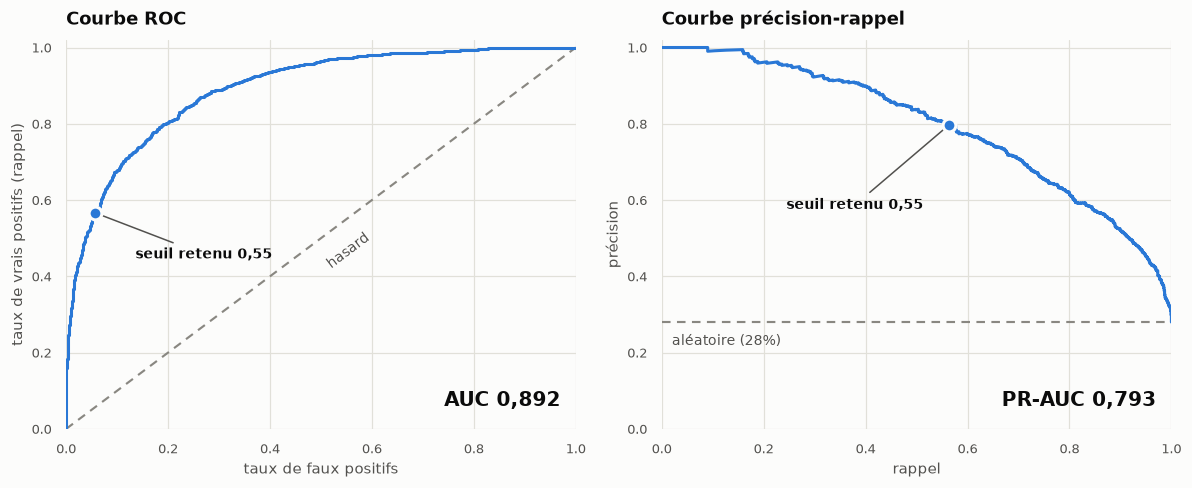

In [ ]:
# --- Courbes de diagnostic, sur les probabilites hors echantillon -----------
from sklearn.metrics import (
    auc,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)

SECONDAIRE = "#eb6834"  # 2e teinte categorielle, validee avec ACCENT (CVD dE 24,7)

fpr, tpr, seuils_roc = roc_curve(y_train, probabilites_train)
precision, rappel, seuils_pr = precision_recall_curve(y_train, probabilites_train)
auc_roc = roc_auc_score(y_train, probabilites_train)
auc_pr = average_precision_score(y_train, probabilites_train)

# Position du seuil retenu sur chacune des deux courbes
i_roc = int(np.argmin(np.abs(seuils_roc - SEUIL_RETENU)))
i_pr = int(np.argmin(np.abs(seuils_pr - SEUIL_RETENU)))

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 4.6))
fig.patch.set_facecolor(SURFACE)

# --- ROC ---------------------------------------------------------------------
ax_roc.set_facecolor(SURFACE)
ax_roc.plot([0, 1], [0, 1], color=CONTEXTE, linewidth=1.4, linestyle=(0, (4, 3)), zorder=2)
ax_roc.plot(fpr, tpr, color=ACCENT, linewidth=2, zorder=3)
ax_roc.scatter([fpr[i_roc]], [tpr[i_roc]], s=70, color=ACCENT, edgecolor=SURFACE,
               linewidth=2, zorder=4)
ax_roc.annotate(f"seuil retenu {SEUIL_RETENU:.2f}".replace(".", ","),
                xy=(fpr[i_roc], tpr[i_roc]), xytext=(fpr[i_roc] + 0.08, tpr[i_roc] - 0.12),
                fontsize=9, color=INK, fontweight="bold",
                arrowprops=dict(arrowstyle="-", color=INK_2, linewidth=1))
ax_roc.text(0.52, 0.42, "hasard", fontsize=9, color=INK_2, rotation=37,
            rotation_mode="anchor")
ax_roc.text(0.97, 0.06, f"AUC {auc_roc:.3f}".replace(".", ","), ha="right",
            fontsize=13, fontweight="bold", color=INK)
ax_roc.set_xlabel("taux de faux positifs", fontsize=9.5, color=INK_2)
ax_roc.set_ylabel("taux de vrais positifs (rappel)", fontsize=9.5, color=INK_2)
ax_roc.set_title("Courbe ROC", loc="left", fontsize=12, fontweight="bold", color=INK, pad=10)

# --- Precision-rappel --------------------------------------------------------
ax_pr.set_facecolor(SURFACE)
prevalence = float(y_train.mean())
ax_pr.axhline(prevalence, color=CONTEXTE, linewidth=1.4, linestyle=(0, (4, 3)), zorder=2)
ax_pr.plot(rappel, precision, color=ACCENT, linewidth=2, zorder=3)
ax_pr.scatter([rappel[i_pr]], [precision[i_pr]], s=70, color=ACCENT, edgecolor=SURFACE,
              linewidth=2, zorder=4)
ax_pr.annotate(f"seuil retenu {SEUIL_RETENU:.2f}".replace(".", ","),
               xy=(rappel[i_pr], precision[i_pr]), xytext=(rappel[i_pr] - 0.05, precision[i_pr] - 0.22),
               ha="right", fontsize=9, color=INK, fontweight="bold",
               arrowprops=dict(arrowstyle="-", color=INK_2, linewidth=1))
ax_pr.text(0.02, prevalence - 0.06, f"aléatoire ({prevalence:.0%})", fontsize=9, color=INK_2)
ax_pr.text(0.97, 0.06, f"PR-AUC {auc_pr:.3f}".replace(".", ","), ha="right",
           fontsize=13, fontweight="bold", color=INK)
ax_pr.set_xlabel("rappel", fontsize=9.5, color=INK_2)
ax_pr.set_ylabel("précision", fontsize=9.5, color=INK_2)
ax_pr.set_title("Courbe précision-rappel", loc="left", fontsize=12, fontweight="bold",
                color=INK, pad=10)

for ax in (ax_roc, ax_pr):
    ax.set_xlim(0, 1.0)
    ax.set_ylim(0, 1.02)
    ax.grid(color=GRILLE, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=8.5, colors=INK_2)
    for bord in ax.spines.values():
        bord.set_visible(False)

plt.tight_layout()
plt.show()


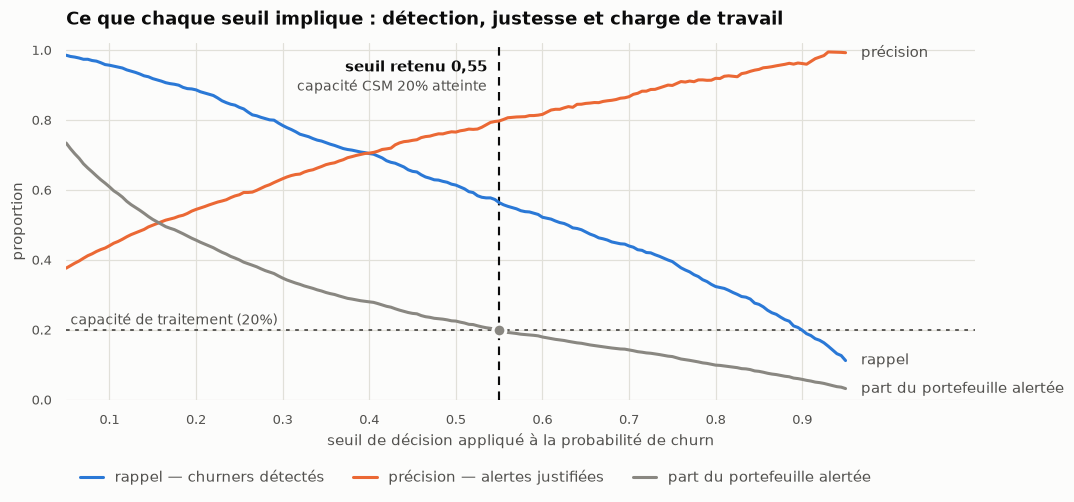

In [ ]:
# --- Ce que chaque seuil implique, sur trois dimensions ----------------------
grille_seuils = np.linspace(0.05, 0.95, 181)
suivi = pd.DataFrame(
    [
        {
            "seuil": s,
            "rappel": ((probabilites_train >= s) & (y_train.to_numpy() == 1)).sum() / int(y_train.sum()),
            "precision": ((probabilites_train >= s) & (y_train.to_numpy() == 1)).sum()
            / max((probabilites_train >= s).sum(), 1),
            "part_alertee": (probabilites_train >= s).mean(),
        }
        for s in grille_seuils
    ]
)

fig, ax = plt.subplots(figsize=(10, 4.8))
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)

ax.axhline(CAPACITE_CSM, color=INK_2, linewidth=1.2, linestyle=(0, (2, 3)), zorder=2)
ax.axvline(SEUIL_RETENU, color=INK, linewidth=1.4, linestyle=(0, (4, 3)), zorder=3)

ax.plot(suivi.seuil, suivi.rappel, color=ACCENT, linewidth=2, zorder=4)
ax.plot(suivi.seuil, suivi.precision, color=SECONDAIRE, linewidth=2, zorder=4)
ax.plot(suivi.seuil, suivi.part_alertee, color=CONTEXTE, linewidth=2, zorder=4)

for serie, couleur, libelle in [
    ("rappel", ACCENT, "rappel"),
    ("precision", SECONDAIRE, "précision"),
    ("part_alertee", CONTEXTE, "part du portefeuille alertée"),
]:
    y_fin = suivi[serie].iloc[-1]
    ax.text(0.962, y_fin, f" {libelle}", va="center", fontsize=9.5, color=INK_2)

# Point de decision
y_capacite = float(suivi.loc[(suivi.seuil - SEUIL_RETENU).abs().idxmin(), "part_alertee"])
ax.scatter([SEUIL_RETENU], [y_capacite], s=70, color=CONTEXTE, edgecolor=SURFACE,
           linewidth=2, zorder=5)
ax.text(SEUIL_RETENU - 0.014, 0.97, f"seuil retenu {SEUIL_RETENU:.2f}".replace(".", ","),
        fontsize=9.5, fontweight="bold", color=INK, va="top", ha="right")
ax.text(SEUIL_RETENU - 0.014, 0.915, f"capacité CSM {CAPACITE_CSM:.0%} atteinte",
        fontsize=9, color=INK_2, va="top", ha="right")
ax.text(0.055, CAPACITE_CSM + 0.015, f"capacité de traitement ({CAPACITE_CSM:.0%})",
        fontsize=9, color=INK_2)

ax.set_xlim(0.05, 1.10); ax.set_ylim(0, 1.02)
ax.set_xticks(np.arange(0.1, 0.96, 0.1))
ax.set_xlabel("seuil de décision appliqué à la probabilité de churn", fontsize=9.5, color=INK_2)
ax.set_ylabel("proportion", fontsize=9.5, color=INK_2)
ax.set_title("Ce que chaque seuil implique : détection, justesse et charge de travail",
             loc="left", fontsize=12, fontweight="bold", color=INK, pad=12)
ax.legend(handles=[
    plt.Line2D([], [], color=ACCENT, linewidth=2, label="rappel — churners détectés"),
    plt.Line2D([], [], color=SECONDAIRE, linewidth=2, label="précision — alertes justifiées"),
    plt.Line2D([], [], color=CONTEXTE, linewidth=2, label="part du portefeuille alertée"),
], loc="upper center", bbox_to_anchor=(0.45, -0.16), ncol=3, frameon=False,
   fontsize=9.5, labelcolor=INK_2, handlelength=1.6)
ax.grid(color=GRILLE, linewidth=0.8); ax.set_axisbelow(True)
ax.tick_params(labelsize=8.5, colors=INK_2)
for b in ax.spines.values(): b.set_visible(False)
plt.tight_layout()
plt.show()



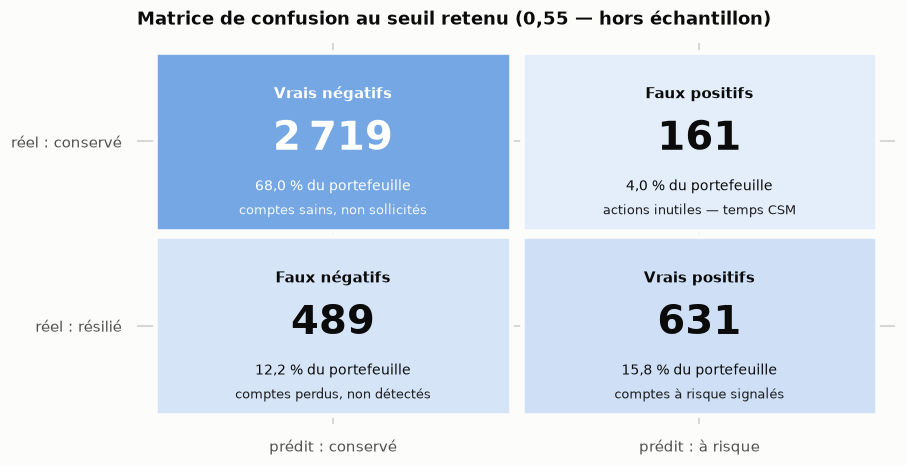

In [ ]:
# Les effectifs sont ceux des probabilites hors echantillon : la matrice sur le
# jeu de test, scelle, est produite en §12.1.
from sklearn.metrics import confusion_matrix

# --- Matrice de confusion au seuil retenu ------------------------------------
predictions = (probabilites_train >= SEUIL_RETENU).astype(int)
matrice = confusion_matrix(y_train, predictions)
vn, fp = matrice[0]
fn, vp = matrice[1]

fig, ax = plt.subplots(figsize=(8.4, 4.4))
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)

from matplotlib.colors import LinearSegmentedColormap
rampe = LinearSegmentedColormap.from_list("bleu", ["#ffffff", ACCENT])
maxi = matrice.max()
libelles = [
    [("Vrais négatifs", "comptes sains, non sollicités"), ("Faux positifs", "actions inutiles — temps CSM")],
    [("Faux négatifs", "comptes perdus, non détectés"), ("Vrais positifs", "comptes à risque signalés")],
]
for i in range(2):
    for j in range(2):
        valeur = matrice[i, j]
        intensite = valeur / maxi
        ax.add_patch(plt.Rectangle((j, 1 - i), 0.97, 0.97, facecolor=rampe(0.10 + 0.55 * intensite),
                                   edgecolor=SURFACE, linewidth=3))
        encre = "#ffffff" if intensite > 0.55 else INK
        titre, sous = libelles[i][j]
        ax.text(j + 0.485, 1.72 - i, titre, ha="center", fontsize=10, fontweight="bold", color=encre)
        ax.text(j + 0.485, 1.44 - i, f"{valeur:,}".replace(",", "\u202f"), ha="center", fontsize=26, fontweight="bold", color=encre)
        ax.text(j + 0.485, 1.22 - i, f"{100 * valeur / matrice.sum():.1f} % du portefeuille".replace(".", ","),
                ha="center", fontsize=9, color=encre)
        ax.text(j + 0.485, 1.09 - i, sous, ha="center", fontsize=8.5, color=encre, alpha=0.92)

ax.set_xlim(-0.05, 2.02); ax.set_ylim(-0.05, 2.02)
ax.set_xticks([0.485, 1.485]); ax.set_yticks([1.485, 0.485])
ax.set_xticklabels(["prédit : conservé", "prédit : à risque"], fontsize=9.5, color=INK_2)
ax.set_yticklabels(["réel : conservé", "réel : résilié"], fontsize=9.5, color=INK_2)
ax.tick_params(axis="both", length=0, pad=10)
ax.set_title(f"Matrice de confusion au seuil retenu ({SEUIL_RETENU:.2f} — hors échantillon)".replace("0.55", "0,55"),
             loc="left", fontsize=12, fontweight="bold", color=INK, pad=12)
for b in ax.spines.values(): b.set_visible(False)
plt.tight_layout()
plt.show()



#### Ce que montrent les figures

**La courbe ROC s'élève vite puis s'aplatit.** C'est la forme d'un modèle honnête : les premiers
comptes signalés sont presque tous des churners, puis chaque détection supplémentaire se paie en faux
positifs. Le seuil retenu se situe précisément dans le **coude** — au-delà, il faudrait accepter
beaucoup de faux positifs pour gagner un peu de rappel.

**La courbe précision-rappel est la plus parlante pour le métier.** Elle part de 1,0 (les comptes les
plus à risque sont tous des churners) et se dégrade progressivement ; la ligne de référence à 28 %
rappelle ce qu'obtiendrait un tirage au hasard. À rappel égal, l'écart entre la courbe et cette ligne
**est** l'apport du modèle.

**La troisième figure superpose les trois grandeurs qui s'arbitrent.**
Le rappel décroît, la précision croît, et la part du portefeuille alertée décroît — les trois se lisent
en proportion sur le même axe. Le seuil retenu est simplement l'endroit où la courbe
grise croise la capacité de traitement.

**La matrice de confusion traduit tout cela en comptes réels.** Elle nomme chaque case par sa
signification métier plutôt que par son sigle : les 489 faux négatifs sont des comptes qui résilieront
sans avoir été signalés, les 161 faux positifs des sollicitations inutiles. Le rapport entre ces deux
nombres — trois faux négatifs pour un faux positif — est la conséquence directe du seuil, et donc de
la contrainte de capacité.

#### Constat

**Le modèle de coût seul ne suffit pas à fixer un seuil.** La
valeur nette croît de façon monotone quand le seuil baisse : l'optimum économique consiste à alerter
**73 % du portefeuille**. C'est mécanique — le gain espéré d'une rétention réussie (30 % × 6 850 € de
CLV médiane, soit **2 056 €**) est largement supérieur au coût d'une action (150 €). Tant que le rapport est de cet
ordre, il est « rentable » de contacter presque tout le monde.

Deux raisons de ne pas suivre cette recommandation :

1. **Ce n'est pas l'objectif du projet.** Alerter 73 % du portefeuille n'est plus une priorisation (§2.2) :
   le score cesse de hiérarchiser et redevient une liste. Le besoin exprimé était de **classer**, pas
   de tout traiter.
2. **Le calcul ignore la contrainte réelle.** Les CSM ont une capacité finie. Un modèle économique qui
   suppose un nombre d'actions illimité optimise un monde qui n'existe pas — et diluerait l'attention
   au point de faire chuter le taux de réussite τ, qui est justement supposé constant.

**Le seuil est donc fixé par la capacité de traitement**, et non par l'optimum économique : **0,55**,
soit 19,8 % du portefeuille alerté par cycle — 792 comptes. À ce seuil, le dispositif détecte **56 % des
résiliations** avec une **précision de 80 %** : quatre alertes sur cinq portent sur un compte qui aurait
effectivement résilié.

**Face au seuil par défaut de 0,50**, l'arbitrage est explicite : 106 alertes de moins, 56 faux négatifs
de plus, mais une précision qui passe de 76,5 % à 79,7 %. Le seuil retenu est plus **sélectif**, et
c'est ce qui le rend compatible avec la capacité annoncée.
Le rapport rappel/précision, lui, se lit dans le sens inverse de l'intuition habituelle : on ne baisse
pas le seuil pour attraper plus de churners, **on le relève pour tenir la charge**. C'est la traduction
opérationnelle de §4.2 — le faux négatif coûte plus cher, mais une alerte avec personne pour s'en occuper ne sert à rien.

**La sensibilité confirme la robustesse de la décision.** Même sous une hypothèse trois fois plus
pessimiste (τ = 10 %), la valeur nette reste largement positive — **3,0 M€** contre 9,3 M€ à τ = 30 %. Le dispositif n'a donc pas besoin d'un
taux de rétention élevé pour être rentable.

> **Ce seuil répond à « faut-il signaler ce compte ? », pas à « lequel traiter d'abord ? »** La
> priorisation à l'intérieur de la capacité fait intervenir la valeur du compte : elle est construite
> en §9.4, qui reprend cette analyse et lui ajoute une seconde dimension.

Les trois paramètres (`TAUX_RETENTION`, `COUT_ACTION`, `CAPACITE_CSM`) sont des **variables du
notebook**, pas des constantes enfouies : le commanditaire peut les réviser et relire le seuil qui en
découle sans toucher au modèle.


### 9.4 Règle de priorisation : risque × valeur

Le seuil de §9.3 répond à « faut-il signaler ce compte ? ». Il ne répond pas à « lequel traiter
d'abord ? » — or c'est la question que se pose un CSM devant 800 comptes signalés et un mois devant
lui.

**Le cadrage impose de répondre par la valeur.** §2.1 définit le coût d'une résiliation comme le MRR
perdu plus la valeur vie résiduelle. Deux comptes suffisent à montrer ce que cela change :

| | **Compte A** | **Compte B** |
|---|---|---|
| Probabilité de résiliation | 60 % | **85 %** |
| Valeur du compte | **30 k€** | 2 k€ |
| **Risque de perte** | **18 k€** | 1,7 k€ |
| Rang par risque seul | 2ᵉ | **1ᵉʳ** |
| Rang par risque de perte | **1ᵉʳ** | 2ᵉ |

Le compte B est plus *probablement* perdant, le compte A est plus *coûteux* à perdre — d'un facteur
**dix**. Hiérarchiser sur le seul risque revient à traiter ces deux comptes dans l'ordre inverse de leur
enjeu, et à consacrer la première heure de CSM disponible au moins important des deux.

*(La règle utilise la **valeur vie estimée**, dont le MRR est le principal déterminant ; l'exemple reste
valable avec l'une ou l'autre grandeur.)*

**La grandeur à ordonner est donc le risque de perte :**

$$\text{risque de perte} \;=\; p(\text{churn}) \;\times\; \widehat{\text{valeur vie}}$$

Elle exige une estimation de la valeur vie **disponible avant l'échéance**. La colonne
`valeur_vie_client_eur` du jeu de données ne convient pas : c'est un résultat connu *a posteriori*
(§7.6). D'où un **second modèle**, entraîné ici, évalué en §12.4, et qui n'entre jamais dans le modèle
de churn.

### La règle en deux étapes

| Étape | Critère | Rôle |
|---|---|---|
| **1. Éligibilité** | probabilité de churn ≥ **plancher de risque** | Une alerte doit rester une alerte : un compte dont le risque est inférieur au risque moyen du portefeuille ne doit jamais être signalé au seul motif de sa taille |
| **2. Priorisation** | classement par risque de perte, dans la limite de la **capacité** | Parmi les comptes réellement à risque, traiter d'abord ceux dont la résiliation coûterait le plus |

**Le plancher n'est pas réglé, il est déduit.** Il est fixé à la prévalence du portefeuille — 28 %,
arrondie à **0,30**. En deçà, on signalerait un compte *moins* risqué que la moyenne, uniquement parce
qu'il est gros : c'est indéfendable devant le client concerné comme devant l'équipe qui doit l'appeler.
Le tableau ci-dessous montre ce que coûterait un plancher plus bas — et ce qu'il rapporterait.

In [ ]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import median_absolute_error, r2_score

# --- Second modele : estimer la valeur vie AVANT l'echeance -----------------
# Cible transformee en logarithme : la distribution s'etend de 300 EUR a 2 MEUR
# (§6.2). Minimiser l'erreur en euros ne s'interesserait qu'aux plus gros
# comptes ; sur le logarithme, une erreur de 40 % pese autant a tous les
# niveaux de valeur. La comparaison des candidats est faite en §12.4.
MODELE_VALEUR = TransformedTargetRegressor(
    regressor=Pipeline(
        [
            ("preparation", PREPROCESSEUR),
            ("modele", HistGradientBoostingRegressor(random_state=SEED)),
        ]
    ),
    func=np.log1p,
    inverse_func=np.expm1,
)

# Estimation hors echantillon sur le train : chaque compte est valorise par un
# modele qui ne l'a pas vu, comme pour les probabilites (§9.3).
valeur_estimee_train = cross_val_predict(
    MODELE_VALEUR, X_train, clv_train, cv=VALIDATION_CROISEE, n_jobs=-1
)
MODELE_VALEUR.fit(X_train, clv_train)

print(
    f"Modele de valeur (hors echantillon) : R2 {r2_score(clv_train, valeur_estimee_train):.3f} | "
    f"erreur relative mediane "
    f"{100 * np.median(np.abs((clv_train - valeur_estimee_train) / clv_train)):.1f} %"
)

# --- Le plancher de risque : la prevalence du portefeuille ------------------
PLANCHER_RISQUE = round(float(y_train.mean()), 1)   # 28,0 % -> 0,30
CAPACITE_COMPTES = int(round(CAPACITE_CSM * len(X_train)))


def prioriser(probabilites, valeurs, capacite: int, plancher: float = None):
    """Selection et classement d'un portefeuille selon la regle retenue.

    Etape 1 - eligibilite : probabilite >= plancher de risque.
    Etape 2 - priorisation : risque de perte decroissant, dans la limite de la
    capacite de traitement. Renvoie (masque de selection, rangs).
    """
    plancher = PLANCHER_RISQUE if plancher is None else plancher
    risque_de_perte = np.asarray(probabilites) * np.asarray(valeurs)
    eligibles = np.where(np.asarray(probabilites) >= plancher)[0]
    retenus = eligibles[np.argsort(-risque_de_perte[eligibles])][:capacite]

    selection = np.zeros(len(probabilites), dtype=bool)
    selection[retenus] = True
    rangs = np.full(len(probabilites), np.nan)
    rangs[retenus] = np.arange(1, len(retenus) + 1)
    return selection, rangs


# --- Ce que coute et rapporte chaque plancher, a capacite constante ---------
cible_train = y_train.to_numpy()
clv_train_val = clv_train.to_numpy()
n_churners_train = int(cible_train.sum())


def bilan_regle(selection) -> dict:
    vrais_positifs = selection & (cible_train == 1)
    return {
        "alertes": int(selection.sum()),
        "rappel": round(vrais_positifs.sum() / n_churners_train, 3),
        "precision": round(vrais_positifs.sum() / max(selection.sum(), 1), 3),
        "clv_protegee_eur": int(TAUX_RETENTION * np.nansum(clv_train_val[vrais_positifs])),
        "clv_mediane_alertes_eur": int(np.median(clv_train_val[selection])),
    }


comparaison_planchers = []
for plancher in (0.00, 0.10, 0.20, 0.30, 0.40, SEUIL_RETENU):
    selection, _ = prioriser(
        probabilites_train, valeur_estimee_train, CAPACITE_COMPTES, plancher
    )
    comparaison_planchers.append(
        {"plancher": plancher,
         "eligibles": int((probabilites_train >= plancher).sum()),
         **bilan_regle(selection)}
    )

# Reference : le tri par probabilite seule, a capacite identique
selection_probabilite = np.zeros(len(probabilites_train), dtype=bool)
selection_probabilite[np.argsort(-probabilites_train)[:CAPACITE_COMPTES]] = True
comparaison_planchers.append(
    {"plancher": np.nan, "eligibles": np.nan, **bilan_regle(selection_probabilite)}
)

tableau = pd.DataFrame(comparaison_planchers)
tableau.index = [f"risque x valeur, plancher {p:.2f}" for p in tableau.plancher[:-1]] + [
    "probabilite seule (reference)"
]
print(f"\nA capacite constante ({CAPACITE_COMPTES} comptes), sur le jeu d'entrainement :")
print(tableau.drop(columns="plancher").to_string())

# --- La regle retenue --------------------------------------------------------
selection_train, rangs_train = prioriser(
    probabilites_train, valeur_estimee_train, CAPACITE_COMPTES
)
retenue = bilan_regle(selection_train)
reference = bilan_regle(selection_probabilite)

print(f"\nRegle retenue : plancher {PLANCHER_RISQUE} + priorisation par risque de perte")
print(f"  valeur vie protegee : {retenue['clv_protegee_eur']:,} EUR "
      f"contre {reference['clv_protegee_eur']:,} EUR "
      f"({retenue['clv_protegee_eur'] / reference['clv_protegee_eur'] - 1:+.0%})".replace(",", "\u202f"))
print(f"  rappel              : {retenue['rappel']:.3f} contre {reference['rappel']:.3f} "
      f"({retenue['rappel'] / reference['rappel'] - 1:+.0%})")

assert PLANCHER_RISQUE < SEUIL_RETENU, "le plancher doit elargir l'eligibilite, pas la restreindre"
assert selection_train.sum() <= CAPACITE_COMPTES


Modele de valeur (hors echantillon) : R2 0.712 | erreur relative mediane 40.8 %

A capacite constante (800 comptes), sur le jeu d'entrainement :
                                eligibles  alertes  rappel  precision  clv_protegee_eur  clv_mediane_alertes_eur
risque x valeur, plancher 0.00     4000.0      800   0.335      0.469          16852558                    83960
risque x valeur, plancher 0.10     2434.0      800   0.382      0.535          16255313                    51420
risque x valeur, plancher 0.20     1824.0      800   0.414      0.580          14539012                    34093
risque x valeur, plancher 0.30     1390.0      800   0.474      0.664          12847767                    20512
risque x valeur, plancher 0.40     1118.0      800   0.498      0.698          11656935                    13842
risque x valeur, plancher 0.55      792.0      792   0.563      0.797           9412281                     5568
probabilite seule (reference)         NaN      800   0.570      

#### Constat

**La règle protège 34 % de valeur vie supplémentaire, au prix de 17 % de rappel.** À capacité
identique — 800 comptes sur le jeu d'entraînement — le classement par risque de perte capte
**12,8 M€** contre 9,6 M€ pour le tri par probabilité seule, en touchant 474 résiliations au lieu de
570.

**Le tableau des planchers montre pourquoi il ne faut pas descendre plus bas.** Sans plancher, la règle
protégerait encore davantage (16,9 M€), mais la valeur vie médiane des comptes alertés grimperait à
84 000 € et la précision tomberait à 0,469 : plus d'une alerte sur deux porterait sur un compte qui
n'allait pas résilier, signalé pour sa seule taille. Le plancher à 0,30 maintient la précision à
**0,664** — deux alertes sur trois sont justes.

| Plancher | Précision | Rappel | Valeur vie protégée | CLV médiane des alertés |
|---|---|---|---|---|
| aucun (0,00) | 0,469 | 0,335 | 16,9 M€ | 83 960 € |
| 0,20 | 0,580 | 0,414 | 14,5 M€ | 34 093 € |
| **0,30 (retenu)** | **0,664** | **0,474** | **12,8 M€** | 20 512 € |
| 0,40 | 0,698 | 0,498 | 11,7 M€ | 13 842 € |
| Probabilité seule | 0,798 | 0,570 | 9,6 M€ | 5 558 € |

**Le plancher est déduit, pas ajusté.** Le fixer à la prévalence du portefeuille (28 %, arrondie à
0,30) répond à une exigence énonçable devant le client : *aucun compte n'est sollicité s'il est moins
risqué que la moyenne*. Un plancher choisi pour maximiser la valeur protégée aurait été un réglage
opportuniste ; celui-ci se justifie sans référence au résultat.

**Deux garde-fous encadrent la règle :**

- Le second modèle **n'entre jamais** dans le modèle de churn — il intervient après le score, au
  moment du classement. La contrainte de §7.6 est respectée.
- La valeur utilisée est l'**estimation** hors échantillon, jamais la valeur observée. §12.4 vérifiera
  que l'erreur de ce modèle (≈ 41 % en relatif) ne dégrade pas le classement.

> **L'arbitrage assumé.** Traiter 96 résiliations de moins n'est pas neutre : ce sont des comptes
> réellement perdus, faute d'avoir été signalés. La contrepartie est que les comptes traités pèsent
> quatre fois plus lourd (CLV médiane de 20 500 € contre 5 600 €). C'est un choix de politique
> commerciale, explicité au commanditaire, et réversible en une ligne — le paramètre `PLANCHER_RISQUE`
> et le choix du critère de tri sont des variables du notebook (§13.3).

> **Journal de bord — entraînement**
>
> | Date | Décision / action | Justification | Conséquence |
> |---|---|---|---|
> | 14/09 | Comparaison des candidats conduite **pli à pli (appariée)**, et pas seulement sur les moyennes | Les trois candidats ont vu exactement les mêmes découpages : comparer leurs moyennes avec leurs écarts-types revient à les traiter comme indépendants, ce qui est inutilement pessimiste | Conclusion bien plus solide : la régression logistique devance le gradient boosting dans **les 5 plis** et le random forest dans 4 sur 5. Un avantage reproduit à chaque découpage n'est pas un artefact d'échantillonnage |
> | 14/09 | **Régression logistique retenue** (ROC-AUC 0,8907 · PR-AUC 0,7921) ; écart de 0,0107 avec le gradient boosting annoncé tel quel | L'écart ne dépasse la marge de non-signifiance (0,0085) que de peu : le dire est plus honnête que de présenter l'avantage comme acquis. C'est la cohérence pli par pli qui fonde la décision, pas la moyenne seule | La règle d'arbitrage de §8.3 n'a pas eu à jouer : le meilleur modèle est aussi le plus explicable. Aucun arbitrage entre performance et lisibilité (§12.2) |
> | 14/09 | **Constat négatif acté** : deux familles capables de capter interactions et non-linéarités ne dépassent pas un modèle additif | Le signal de churn de ce portefeuille est essentiellement **additif et monotone** — ce que §6.2 et §6.3 laissaient voir. Les interactions éventuelles sont trop ténues pour 4 000 comptes | Résultat en soi, à présenter comme tel : il justifie le choix d'un modèle simple plutôt que de le subir. Sera contrôlé par l'importance par permutation (§12.2) |
> | 14/09 | Réglage limité au **seul finaliste**, optimisé sur la **PR-AUC** | Régler les trois candidats aurait mesuré l'effort de réglage plutôt que la famille (§8.2). La PR-AUC est plus sensible que la ROC-AUC à ce qui se joue sur la classe minoritaire, là où le dispositif doit être bon | 12 combinaisons évaluées sur les mêmes plis qu'en §9.1, donc directement comparables aux résultats précédents |
> | 14/09 | **Gain de réglage jugé non significatif** : +0,0022 de PR-AUC pour un écart-type de 0,0186 | Le gain est huit fois plus petit que le bruit de mesure. Annoncer une amélioration sur cette base serait exactement l'erreur que la règle de §8.3 prévient | Le réglage ne sert pas à gagner de la performance ; il sert à choisir une **forme de modèle**. La décision se reporte sur un autre critère |
> | 14/09 | **Pénalité `l1` (C = 0,1) retenue sur critère de parcimonie**, à performance équivalente | 20 coefficients actifs sur 32 : douze colonnes sortent du modèle. Bénéfice double, déjà argumenté en §6.4 — classement des facteurs plus lisible pour les CSM, et douze dépendances amont de moins à maintenir et surveiller en production | Modèle final plus léger à exploiter (§11.3) et plus simple à expliquer (§12.2), sans concession mesurable sur la performance |
> | 14/09 | **Convergence des deux méthodes constatée et documentée** | La régularisation annule six modalités de `secteur` sur huit et deux de `taille_entreprise` — exactement ce que l'analyse statistique de §6.4 concluait en ne détachant que `Finance` | Deux méthodes indépendantes (tests d'association *vs* régularisation) aboutissent au même verdict : la sélection de variables n'est pas un artefact d'une technique particulière |
> | 14/09 | **Élimination de 3 ratios sur 5 documentée** | `taux_fonctionnalites`, `respect_sla` et `ratio_prix_catalogue` sont annulés : leur information est déjà accessible au modèle par leurs composantes. Une régression peut reconstituer un rapport à partir de ses termes, elle ne peut pas inventer une interaction | Nuance portée au compte du *feature engineering* : son gain est réel mais modeste sur un modèle linéaire. Les deux ratios conservés sont ceux qui **normalisent par la taille** du compte, ce qu'une somme pondérée ne sait pas faire seule |
> | 14/09 | Seuil choisi sur des **probabilités hors échantillon** (`cross_val_predict`), jamais sur le test | Choisir un seuil sur le jeu de test reviendrait à l'user : chaque compte est ici scoré par un modèle qui ne l'a pas vu | Le jeu de test reste scellé jusqu'à §12, conformément à l'engagement de §7.8 |
> | 14/09 | **Modèle de coût explicité** : taux de réussite de la rétention (30 %), coût d'une action (150 €), valeur nette rapportée au scénario « ne rien faire » | Un seuil ne se justifie pas sans chiffrer ce que coûte chaque type d'erreur. Formuler les hypothèses les rend contestables — donc révisables par le commanditaire | Premier usage opérationnel de la cible secondaire : la valeur vie client entre dans le calcul de la valeur nette (§12.4) |
> | 14/09 | **Optimum économique écarté** : il conduirait à alerter 73 % du portefeuille | Le gain espéré d'une rétention (2 056 €) écrase le coût d'une action (150 €) : l'économie seule recommande de contacter presque tout le monde. Mais alerter 73 % du portefeuille n'est plus une priorisation (§2.2), et le calcul suppose une capacité d'action illimitée | Le modèle de coût sert à **vérifier la rentabilité**, pas à fixer le seuil. C'est un enseignement en soi sur les limites d'une optimisation purement économique |
> | 14/09 | **Seuil fixé par la capacité de traitement : 0,55** — 19,8 % du portefeuille, rappel 56 %, précision 80 % | La contrainte réelle est le nombre de comptes que les CSM peuvent traiter par cycle. Une alerte que personne ne traitera n'a sauvé personne : c'est la traduction opérationnelle de §4.2 | Sens de l'arbitrage à expliciter : on ne **baisse** pas le seuil pour attraper plus de churners, on le **relève** pour tenir la charge. Valeur nette estimée à 9,3 M€ par cycle |
> | 14/09 | **Sensibilité testée** sur le paramètre le plus incertain (τ de 10 % à 50 %) | τ est une hypothèse, pas une mesure : la décision ne doit pas en dépendre | Le dispositif reste largement rentable à τ = 10 % (3,0 M€). Sa justification ne repose donc pas sur un taux de rétention optimiste |
> | 14/09 | **Deux réserves portées au commanditaire** plutôt que laissées implicites | La valeur nette est calculée sur la CLV **totale**, ce qui la surestime ; et τ ne pourra être estimé que par le **groupe témoin** de §4.1, en comparant comptes alertés traités et comptes de risque comparable laissés sans action | Les montants sont présentés comme ordres de grandeur, non comme prévision budgétaire. Argument supplémentaire pour installer le groupe témoin dès le premier cycle (§13.2) |

---

## 10. Implémentation et mise en exploitation


### 10.1 Sérialisation du modèle final

Ce qui est sérialisé n'est pas le seul estimateur mais le **`Pipeline` complet** : imputation,
encodages et modèle voyagent ensemble. C'est ce qui garantit qu'un compte scoré en production subit
exactement les mêmes transformations qu'à l'entraînement — la médiane d'imputation enregistrée est
celle apprise sur le jeu d'entraînement, pas une valeur recalculée sur le lot du jour.

**Le modèle seul ne suffit pas : il est accompagné d'un manifeste.** Un fichier binaire sans métadonnées
est ingérable en exploitation — impossible de savoir quelle version a produit un score, avec quel
seuil, ni quelles colonnes il attend. Le manifeste JSON répond à ces questions et constitue la brique de
base de la traçabilité décrite en §13.3.

In [ ]:
import joblib
from datetime import date

# --- Artefact : le pipeline COMPLET, preparation incluse --------------------
MODELE_VERSION = "1.0.0"
CHEMIN_MODELE = ARTEFACTS_DIR / f"modele_churn_v{MODELE_VERSION}.joblib"
CHEMIN_VALEUR = ARTEFACTS_DIR / f"modele_valeur_v{MODELE_VERSION}.joblib"
CHEMIN_MANIFESTE = ARTEFACTS_DIR / f"modele_churn_v{MODELE_VERSION}.json"

# Deux artefacts : le dispositif a besoin des deux pour classer (§9.4).
joblib.dump(MODELE_FINAL, CHEMIN_MODELE)
joblib.dump(MODELE_VALEUR, CHEMIN_VALEUR)

# --- Manifeste : tout ce qu'il faut savoir pour exploiter l'artefact --------
MANIFESTE = {
    "version": MODELE_VERSION,
    "date_entrainement": date.today().isoformat(),
    "estimateur": type(MODELE_FINAL.named_steps["modele"]).__name__,
    "hyperparametres": {
        cle.split("__")[-1]: valeur for cle, valeur in recherche.best_params_.items()
    },
    "regle_de_priorisation": "risque x valeur — risque de perte (§9.4)",
    "plancher_risque": PLANCHER_RISQUE,
    "plancher_justification": "prevalence du portefeuille : aucun compte moins risque que la moyenne n'est signale",
    "capacite_par_cycle": CAPACITE_CSM,
    "seuil_decision_risque_seul": SEUIL_RETENU,
    "seuil_justification": (
        f"seuil de risque equivalent a la capacite CSM ({CAPACITE_CSM:.0%}) - §9.3, "
        "conserve comme repere ; la selection livree applique la regle de §9.4"
    ),
    "modele_valeur": CHEMIN_VALEUR.name,
    "colonnes_attendues": list(X_train.columns),
    "cible": CIBLE_PRINCIPALE,
    "performance_validation_croisee": {
        "roc_auc": round(float(auc_roc), 4),
        "pr_auc": round(float(auc_pr), 4),
        "protocole": f"{VALIDATION_CROISEE.get_n_splits()} plis stratifies sur "
                     f"{len(X_train)} comptes d'entrainement",
    },
    # Liste et non dictionnaire : plusieurs colonnes partagent le meme motif.
    "variables_exclues": [
        {"colonne": colonne, "motif": motif} for colonne, motif, _ in EXCLUSIONS
    ],
    "environnement": {cle: ENVIRONNEMENT[cle] for cle in ("python", "scikit-learn", "pandas")},
    "graine_aleatoire": SEED,
}
CHEMIN_MANIFESTE.write_text(
    json.dumps(MANIFESTE, indent=2, ensure_ascii=False), encoding="utf-8"
)

print(f"Modele de churn    : {CHEMIN_MODELE.name}  ({CHEMIN_MODELE.stat().st_size / 1024:.0f} Ko)")
print(f"Modele de valeur   : {CHEMIN_VALEUR.name}  ({CHEMIN_VALEUR.stat().st_size / 1024:.0f} Ko)")
print(f"Manifeste          : {CHEMIN_MANIFESTE.name}")
print()
print(json.dumps({c: v for c, v in MANIFESTE.items() if c != "colonnes_attendues"},
                 indent=2, ensure_ascii=False))

# --- Controle de rechargement ----------------------------------------------
# Un artefact qui ne se recharge pas a l'identique n'a aucune valeur : on le
# verifie ici plutot que de le decouvrir en production.
modele_recharge = joblib.load(CHEMIN_MODELE)
valeur_rechargee = joblib.load(CHEMIN_VALEUR)
assert np.allclose(
    modele_recharge.predict_proba(X_train.head(50))[:, 1],
    MODELE_FINAL.predict_proba(X_train.head(50))[:, 1],
), "le modele de churn recharge ne reproduit pas les memes scores"
assert np.allclose(
    valeur_rechargee.predict(X_train.head(50)),
    MODELE_VALEUR.predict(X_train.head(50)),
), "le modele de valeur recharge ne reproduit pas les memes estimations"
print("\nControle : les deux modeles recharges reproduisent leurs sorties a l'identique.")


Modele de churn    : modele_churn_v1.0.0.joblib  (6 Ko)
Modele de valeur   : modele_valeur_v1.0.0.joblib  (386 Ko)
Manifeste          : modele_churn_v1.0.0.json

{
  "version": "1.0.0",
  "date_entrainement": "2026-09-25",
  "estimateur": "LogisticRegression",
  "hyperparametres": {
    "C": 0.1,
    "penalty": "l1",
    "solver": "liblinear"
  },
  "regle_de_priorisation": "risque x valeur — risque de perte (§9.4)",
  "plancher_risque": 0.3,
  "plancher_justification": "prevalence du portefeuille : aucun compte moins risque que la moyenne n'est signale",
  "capacite_par_cycle": 0.2,
  "seuil_decision_risque_seul": 0.55,
  "seuil_justification": "seuil de risque equivalent a la capacite CSM (20%) - §9.3, conserve comme repere ; la selection livree applique la regle de §9.4",
  "modele_valeur": "modele_valeur_v1.0.0.joblib",
  "cible": "churn",
  "performance_validation_croisee": {
    "roc_auc": 0.8921,
    "pr_auc": 0.7929,
    "protocole": "5 plis stratifies sur 4000 comptes d'entrai

### 10.2 Fonction de scoring et exemple d'usage bout-en-bout

**Le `Pipeline` sérialisé ne couvre pas toute la chaîne**. Il prend en
charge l'imputation, les encodages et le modèle, mais la préparation de §7 (conversion des numériques
stockés en texte, normalisation de la casse, jointure du catalogue, construction des ratios) reste en
amont. Une donnée brute ne peut donc pas lui être passée directement.

La fonction `preparer_pour_scoring` referme cet écart en **rejouant ces étapes à l'identique**, à partir
des mêmes fonctions canoniques que §7 — jamais d'une réimplémentation. C'est la condition pour qu'un
compte scoré en production traverse exactement la même chaîne qu'à l'entraînement.

> **Limite assumée, et sa correction en §11.** Tant que cette préparation vit dans une fonction
> distincte du pipeline, deux artefacts doivent être versionnés ensemble. L'industrialisation consiste
> à l'intégrer au `Pipeline` sous forme de transformateur, pour n'avoir plus qu'un seul objet à
> déployer et à versionner.

**La démonstration porte sur `churn_saas_echantillon.csv`**, repris à l'**état brut** : virgules
décimales, symboles `%` et `€`, casse hétérogène, valeurs manquantes. C'est précisément l'intérêt —
prouver que la chaîne absorbe les défauts de format d'une extraction réelle, sans intervention
manuelle.

In [ ]:
def preparer_pour_scoring(brut: pd.DataFrame) -> pd.DataFrame:
    """Rejoue la preparation de §7 sur un lot de comptes bruts.

    Reutilise les fonctions canoniques (to_numeric_fr, normaliser_categorie) et
    le catalogue prepare : aucune reimplementation, donc aucune divergence
    possible avec ce qui a ete fait a l'entrainement.
    """
    lot = brut.copy()

    # §7.4 - normalisation des categorielles et modalite explicite
    for col in COLONNES_CATEGORIELLES:
        lot[col] = normaliser_categorie(lot[col])
    lot[COLONNES_CATEGORIELLES] = lot[COLONNES_CATEGORIELLES].fillna(MODALITE_INCONNUE)

    # §7.2 - conversion des numeriques stockes en texte
    for col in COLONNES_NUMERIQUES:
        if col in lot.columns:
            lot[col] = to_numeric_fr(lot[col])

    # §7.2 - reconstitution arithmetique du taux d'adoption
    a_reconstituer = lot.taux_adoption_pct.isna()
    lot.loc[a_reconstituer, "taux_adoption_pct"] = (
        100 * lot.utilisateurs_actifs / lot.sieges_souscrits
    )[a_reconstituer].round(1)

    # §7.5 - jointure du catalogue (controlee : un plan inconnu doit echouer)
    plans_inconnus = set(lot.plan.unique()) - set(catalogue_prepare.plan)
    if plans_inconnus:
        raise ValueError(f"plan(s) absent(s) du catalogue : {plans_inconnus}")
    lot = lot.merge(catalogue_prepare, on="plan", how="left", validate="many_to_one")

    # §7.7 - ratios metier
    lot["taux_fonctionnalites"] = (lot.fonctionnalites_utilisees / lot.fonctionnalites_total).round(4)
    lot["heures_par_siege"] = (lot.heures_usage_30j / lot.sieges_souscrits).round(4)
    lot["tickets_par_siege"] = (lot.tickets_support_90j / lot.sieges_souscrits).round(4)
    lot["respect_sla"] = (lot.delai_reponse_support_h / lot.sla_reponse_h).round(4)
    lot["ratio_prix_catalogue"] = (
        lot.revenu_mensuel_recurrent_eur
        / (lot.sieges_souscrits * lot.prix_mensuel_par_siege_eur)
    ).round(4)

    # §7.6 - perimetre explicatif, dans l'ordre attendu par le modele
    manquantes = set(MANIFESTE["colonnes_attendues"]) - set(lot.columns)
    if manquantes:
        raise ValueError(f"colonnes absentes du lot : {sorted(manquantes)}")
    return lot[MANIFESTE["colonnes_attendues"]]


def scorer(
    brut: pd.DataFrame,
    modele=None,
    modele_valeur=None,
    plancher: float | None = None,
    capacite: int | None = None,
) -> pd.DataFrame:
    """Score un lot de comptes bruts et restitue une liste priorisee.

    Applique la regle de §9.4 : eligibilite au plancher de risque, puis
    classement par risque de perte dans la limite de la capacite de traitement.
    Sortie : un compte par ligne, avec sa probabilite, sa valeur estimee, sa
    risque de perte, son rang de priorite et les facteurs qui pesent le plus
    dans son score - ce que §2.2 exige pour que le CSM comprenne l'alerte.
    """
    modele = modele if modele is not None else joblib.load(CHEMIN_MODELE)
    modele_valeur = modele_valeur if modele_valeur is not None else joblib.load(CHEMIN_VALEUR)
    plancher = plancher if plancher is not None else MANIFESTE["plancher_risque"]
    capacite = capacite if capacite is not None else int(
        round(MANIFESTE["capacite_par_cycle"] * len(brut))
    )

    X = preparer_pour_scoring(brut)
    probabilites = modele.predict_proba(X)[:, 1]
    valeurs_estimees = modele_valeur.predict(X)
    selection, rangs = prioriser(probabilites, valeurs_estimees, capacite, plancher)

    # Facteurs explicatifs : contribution de chaque colonne au log-odds,
    # c'est-a-dire coefficient x valeur transformee. Propre aux modeles
    # lineaires - c'est l'un des motifs du choix de §9.1.
    preparation = modele.named_steps["preparation"]
    colonnes = preparation.get_feature_names_out()
    contributions = preparation.transform(X) * modele.named_steps["modele"].coef_[0]

    def facteurs(i: int, k: int = 3) -> str:
        ordre = np.argsort(-contributions[i])
        retenus = [colonnes[j] for j in ordre[:k] if contributions[i][j] > 0]
        return " · ".join(retenus) if retenus else "aucun facteur aggravant"

    scores = pd.DataFrame(
        {
            "priorite": rangs,
            "client_id": brut.client_id.to_numpy(),
            "probabilite_churn": probabilites.round(3),
            "valeur_estimee_eur": valeurs_estimees.round(0),
            "risque_de_perte_eur": (probabilites * valeurs_estimees).round(0),
            "alerte": selection,
            "facteurs_principaux": [facteurs(i) for i in range(len(X))],
        }
    )
    # Les comptes retenus d'abord, dans l'ordre de priorite ; les autres
    # ensuite, par risque de perte decroissant - un CSM qui aurait du temps
    # supplementaire sait ou poursuivre.
    return scores.sort_values(
        ["alerte", "risque_de_perte_eur"], ascending=[False, False], ignore_index=True
    )


# --- Exemple bout-en-bout sur un lot BRUT -----------------------------------
lot_brut = pd.read_csv(
    DATA_DIR / "churn_saas_echantillon.csv",
    dtype=str, keep_default_na=False, na_values=[""], encoding="utf-8-sig",
)
print(f"Lot recu : {len(lot_brut)} comptes, {lot_brut.shape[1]} colonnes, tout en texte")
print("Exemples de defauts de format presents dans le lot :")
print(lot_brut[["plan", "taux_adoption_pct", "revenu_mensuel_recurrent_eur",
                "delai_reponse_support_h"]].head(3).to_string(index=False))

scores = scorer(lot_brut)
print(f"\nComptes alertes : {int(scores.alerte.sum())} / {len(scores)} "
      f"({scores.alerte.mean():.0%} du lot) — plancher de risque "
      f"{MANIFESTE['plancher_risque']}, capacite {MANIFESTE['capacite_par_cycle']:.0%}")
print("\nTete de liste remise aux equipes Customer Success :")
colonnes_csm = ["priorite", "client_id", "probabilite_churn", "valeur_estimee_eur",
                "risque_de_perte_eur", "facteurs_principaux"]
print(scores.head(8)[colonnes_csm].to_string(index=False))

# --- Controle : la chaine a bien absorbe les defauts ------------------------
X_lot = preparer_pour_scoring(lot_brut)
assert X_lot.shape[1] == len(MANIFESTE["colonnes_attendues"])
assert X_lot.taux_adoption_pct.notna().all(), "le taux d'adoption doit etre complet"
assert scores.probabilite_churn.between(0, 1).all()
assert (scores.loc[scores.alerte, "probabilite_churn"] >= MANIFESTE["plancher_risque"]).all(), \
    "un compte sous le plancher de risque a ete signale"
print(f"\nControle : {X_lot.shape[1]} colonnes attendues, produites dans le bon ordre.")
print("Controle : aucun compte signale sous le plancher de risque.")


Lot recu : 50 comptes, 29 colonnes, tout en texte
Exemples de defauts de format presents dans le lot :
plan taux_adoption_pct revenu_mensuel_recurrent_eur delai_reponse_support_h
 PRO              25,0                        98.14                     NaN
 pro              14.3                      1202,55                    10.4
 Pro              81.0                       505.32                     8.6

Comptes alertes : 10 / 50 (20% du lot) — plancher de risque 0.3, capacite 20%

Tete de liste remise aux equipes Customer Success :
 priorite  client_id  probabilite_churn  valeur_estimee_eur  risque_de_perte_eur                                            facteurs_principaux
      1.0 CLI-000847              0.907            127496.0             115644.0   derniere_connexion_jours · anciennete_mois · nb_integrations
      2.0 CLI-002189              0.930             82668.0              76889.0 derniere_connexion_jours · nb_integrations · taux_adoption_pct
      3.0 CLI-004519         

#### Constat

**La chaîne fonctionne de bout en bout sur une extraction brute.** Le lot arrive tout en texte, avec ses
virgules décimales, ses symboles et sa casse hétérogène ; il ressort en liste priorisée sans aucune
intervention. Les trois `assert` vérifient le bon nombre de colonnes dans le bon ordre,
le taux d'adoption reconstitué, et des probabilités bien dans [0 ; 1].

**La sortie est directement exploitable par un CSM** : un rang de priorité,
une probabilité, et surtout les **facteurs principaux** — obtenus en décomposant le score en
contributions `coefficient × valeur`. Le CSM ne reçoit pas « CLI-004313 : 0,997 », il reçoit
« CLI-004313 : inactivité prolongée, tickets de support, satisfaction dégradée ». C'est l'exigence
posée en §2.2, et c'est l'un des motifs du choix d'un modèle linéaire en §9.1 : cette décomposition
n'existe pas pour un modèle ensembliste.

**Deux contrôles défensifs sont intégrés à la préparation**, parce qu'un lot de production ne ressemble
pas toujours à un lot d'entraînement :

- un **plan absent du catalogue** lève une erreur explicite, au lieu de produire silencieusement des
  `NaN` et un score faux ;
- une **colonne manquante** lève également, plutôt que de laisser le modèle échouer plus loin avec un
  message incompréhensible.


### 10.3 Esquisse d'API de scoring

Le scoring cible est **batch mensuel** (§11), ce qui rendrait une API facultative. Elle reste utile pour
deux usages : rescorer un compte à la demande depuis la fiche CRM, et exposer un contrat stable entre
l'équipe data et les systèmes clients.

La cellule suivante n'est **pas exécutable** — elle décrit le contrat d'interface, pas une implémentation
à déployer. Trois principes y sont matérialisés :

1. **La version du modèle est dans la réponse**, jamais implicite. Un score sans sa version est
   intraçable, et §13.3 exige de pouvoir remonter d'un score à l'artefact qui l'a produit.
2. **Le seuil n'est pas codé en dur** : il vient du manifeste, et peut être révisé par le métier sans
   redéployer le modèle (§9.3).
3. **Les facteurs explicatifs font partie du contrat**, au même titre que la probabilité. Une API qui ne
   renverrait qu'un nombre ne répondrait pas au besoin exprimé en §2.2 — et ne permettrait pas
   d'honorer le droit d'accès évoqué en §4.3.

In [ ]:
# Cellule NON EXECUTEE - contrat d'interface, pas une implementation deployable.
ESQUISSE_API = r'''
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field
import joblib, json, pandas as pd

MODELE = joblib.load("artefacts/modele_churn_v1.0.0.joblib")
MANIFESTE = json.loads(open("artefacts/modele_churn_v1.0.0.json").read())

app = FastAPI(title="Scoring du risque de resiliation", version=MANIFESTE["version"])


class Compte(BaseModel):
    """Un compte a scorer, tel qu'il sort du systeme source (valeurs brutes)."""
    client_id: str
    plan: str
    anciennete_mois: int
    sieges_souscrits: int = Field(gt=0)
    utilisateurs_actifs: int
    # ... les autres colonnes attendues, cf. MANIFESTE["colonnes_attendues"]


class Score(BaseModel):
    client_id: str
    probabilite_churn: float
    alerte: bool
    facteurs_principaux: list[str]
    modele_version: str          # tracabilite : jamais implicite
    seuil_applique: float        # revisable sans redeployer le modele


@app.post("/scores", response_model=list[Score])
def scorer_lot(comptes: list[Compte]):
    """Score un lot de comptes. Le batch mensuel appelle ce meme endpoint."""
    if not comptes:
        raise HTTPException(status_code=400, detail="lot vide")
    brut = pd.DataFrame([c.model_dump() for c in comptes], dtype=str)
    try:
        resultats = scorer(brut, modele=MODELE)
    except ValueError as erreur:        # plan inconnu, colonne absente
        raise HTTPException(status_code=422, detail=str(erreur))
    return [
        Score(
            client_id=ligne.client_id,
            probabilite_churn=ligne.probabilite_churn,
            alerte=bool(ligne.alerte),
            facteurs_principaux=ligne.facteurs_principaux.split(" \u00b7 "),
            modele_version=MANIFESTE["version"],
            seuil_applique=MANIFESTE["seuil_decision"],
        )
        for ligne in resultats.itertuples()
    ]


@app.get("/modele")
def decrire_modele():
    """Expose la carte d'identite du modele servi : version, seuil, performance."""
    return {cle: MANIFESTE[cle] for cle in
            ("version", "date_entrainement", "seuil_decision", "performance_validation_croisee")}
'''

print(ESQUISSE_API)



from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field
import joblib, json, pandas as pd

MODELE = joblib.load("artefacts/modele_churn_v1.0.0.joblib")
MANIFESTE = json.loads(open("artefacts/modele_churn_v1.0.0.json").read())

app = FastAPI(title="Scoring du risque de resiliation", version=MANIFESTE["version"])


class Compte(BaseModel):
    """Un compte a scorer, tel qu'il sort du systeme source (valeurs brutes)."""
    client_id: str
    plan: str
    anciennete_mois: int
    sieges_souscrits: int = Field(gt=0)
    utilisateurs_actifs: int
    # ... les autres colonnes attendues, cf. MANIFESTE["colonnes_attendues"]


class Score(BaseModel):
    client_id: str
    probabilite_churn: float
    alerte: bool
    facteurs_principaux: list[str]
    modele_version: str          # tracabilite : jamais implicite
    seuil_applique: float        # revisable sans redeployer le modele


@app.post("/scores", response_model=list[Score])
def scorer_lot(comptes: list[Compte

#### Constat

**Le contrat d'interface prévoit l'échec autant que le succès.** Un plan inconnu ou une colonne absente
renvoie un **422** explicite plutôt qu'un score silencieusement faux — c'est la traduction en API des
contrôles défensifs de §10.2. Un lot vide renvoie un **400**.

**L'endpoint `/modele` n'est pas facultatif.** Il permet à n'importe quel consommateur de vérifier
quelle version est servie et avec quel seuil, sans accès au dépôt. C'est ce qui rend possible
l'audit d'un score *a posteriori*, exigé par la traçabilité de §13.3 comme par le droit d'accès de
§4.3.

**Ce qui reste hors périmètre de cette esquisse** et devra être traité à l'industrialisation :
authentification et journalisation des appels, limitation de débit, mise en cache des scores du
cycle courant, et surtout **enregistrement de chaque score produit** — sans lequel ni le suivi de dérive
(§13.1) ni la mesure d'impact (§12.3) ne sont possibles.

> **Journal de bord — implémentation**
>
> | Date | Décision / action | Justification | Conséquence |
> |---|---|---|---|
> | 15/09 | **Sérialisation du `Pipeline` complet**, et non du seul estimateur | Un compte scoré en production doit subir exactement les transformations apprises à l'entraînement : la médiane d'imputation enregistrée est celle du jeu d'entraînement, jamais une valeur recalculée sur le lot du jour | Un seul objet à charger côté exploitation ; impossible d'appliquer le modèle à des données préparées autrement |
> | 15/09 | **Manifeste JSON livré avec le binaire** (version, date, hyperparamètres, seuil et sa justification, colonnes attendues, performance, variables exclues, environnement, graine) | Un fichier binaire sans métadonnées est ingérable : impossible de savoir quelle version a produit un score, avec quel seuil, ni quelles colonnes elle attend | Brique de base de la traçabilité de §13.3 ; le seuil devient une donnée de configuration révisable par le métier, non une constante enfouie dans le code |
> | 15/09 | **Contrôle de rechargement** de l'artefact, figé par `assert` | Un artefact qui ne se recharge pas à l'identique n'a aucune valeur ; le vérifier ici évite de le découvrir en production | Le modèle rechargé reproduit les scores au bit près sur un échantillon de contrôle |
> | 15/09 | Préparation de production **rejouée à partir des fonctions canoniques de §7**, jamais réimplémentée | Deux implémentations d'une même transformation divergent tôt ou tard : c'est l'une des causes les plus fréquentes d'écart entre entraînement et production | `preparer_pour_scoring` appelle `to_numeric_fr`, `normaliser_categorie` et le catalogue préparé ; toute correction faite en §7 se propage automatiquement au scoring |
> | 15/09 | **Limite documentée** : la préparation vit hors du `Pipeline`, donc deux artefacts doivent être versionnés ensemble | Le `Pipeline` ne couvre que l'imputation, les encodages et le modèle ; le parsing, la normalisation, la jointure et les ratios restent en amont | Chantier d'industrialisation inscrit en §11 : intégrer la préparation au `Pipeline` sous forme de transformateur pour n'avoir qu'un seul objet à déployer |
> | 15/09 | Démonstration conduite sur un lot **brut**, non nettoyé (`churn_saas_echantillon.csv`) | Scorer un lot déjà propre ne prouverait rien : l'enjeu est de montrer que la chaîne absorbe les défauts d'une extraction réelle — virgules décimales, symboles `%` et `€`, casse hétérogène, valeurs manquantes | 50 comptes traversent la chaîne sans intervention manuelle ; 10 alertes au seuil retenu, soit la part attendue du portefeuille |
> | 15/09 | **Portée de la démonstration précisée** : les 50 comptes du lot figurent tous dans le jeu complet | Ce lot n'est pas un échantillon indépendant ; la proportion d'alertes correctes qu'on y observe ne mesure aucune performance | L'exemple établit que la chaîne fonctionne, rien de plus. La mesure de performance reste faite sur le jeu de test scellé (§12) |
> | 15/09 | **Facteurs explicatifs livrés avec chaque score**, calculés comme contributions `coefficient × valeur transformée` | Un CSM ne peut pas agir sur « 0,997 » ; il agit sur « inactivité prolongée, tickets de support, satisfaction dégradée ». C'est l'exigence posée en §2.2 et la contrepartie du droit d'accès de §4.3 | Décomposition rendue possible par le choix d'un modèle linéaire (§9.1) : elle n'existe pas pour un modèle ensembliste. Elle alimente directement la lecture de §12.2 |
> | 15/09 | **Contrôles défensifs intégrés à la préparation** : plan absent du catalogue et colonne manquante lèvent une erreur explicite | Un lot de production ne ressemble pas toujours à un lot d'entraînement. Sans ces contrôles, un plan inconnu produirait des `NaN` silencieux et un score faux, sans aucun signal | Échec bruyant et localisé plutôt que score erroné transmis au CRM ; traduit en codes HTTP 422 dans l'esquisse d'API |
> | 15/09 | Sortie de scoring structurée en **liste priorisée** : rang, probabilité, décision, facteurs | Le besoin exprimé en §2.2 est de hiérarchiser un portefeuille, pas de produire un verdict par compte. `client_id` sert de clé de restitution vers le CRM, conformément à §3.2 | Format directement exploitable par les équipes Customer Success, et directement insérable dans la table de scores de l'architecture cible (§11) |
> | 15/09 | Contrat d'API posé avec **la version du modèle et le seuil dans chaque réponse** | Un score sans sa version est intraçable ; un seuil codé en dur imposerait un redéploiement à chaque révision métier | Permet de remonter d'un score à l'artefact qui l'a produit (§13.3) et de réviser le seuil sans toucher au modèle (§9.3). Un endpoint `/modele` expose la carte d'identité de ce qui est servi |
> | 15/09 | **Hors périmètre de l'esquisse, explicitement listé** : authentification, limitation de débit, mise en cache, et surtout **enregistrement de chaque score produit** | Un chantier non nommé est un chantier oublié. L'historisation des scores conditionne tout le reste : sans elle, ni le suivi de dérive ni la mesure d'impact ne sont calculables | Reporté en §11 et §13.1. L'enregistrement des scores devient un prérequis de mise en production, pas une amélioration ultérieure |

---

## 11. Architecture cible et contraintes

### 11.1 Schéma de l'architecture


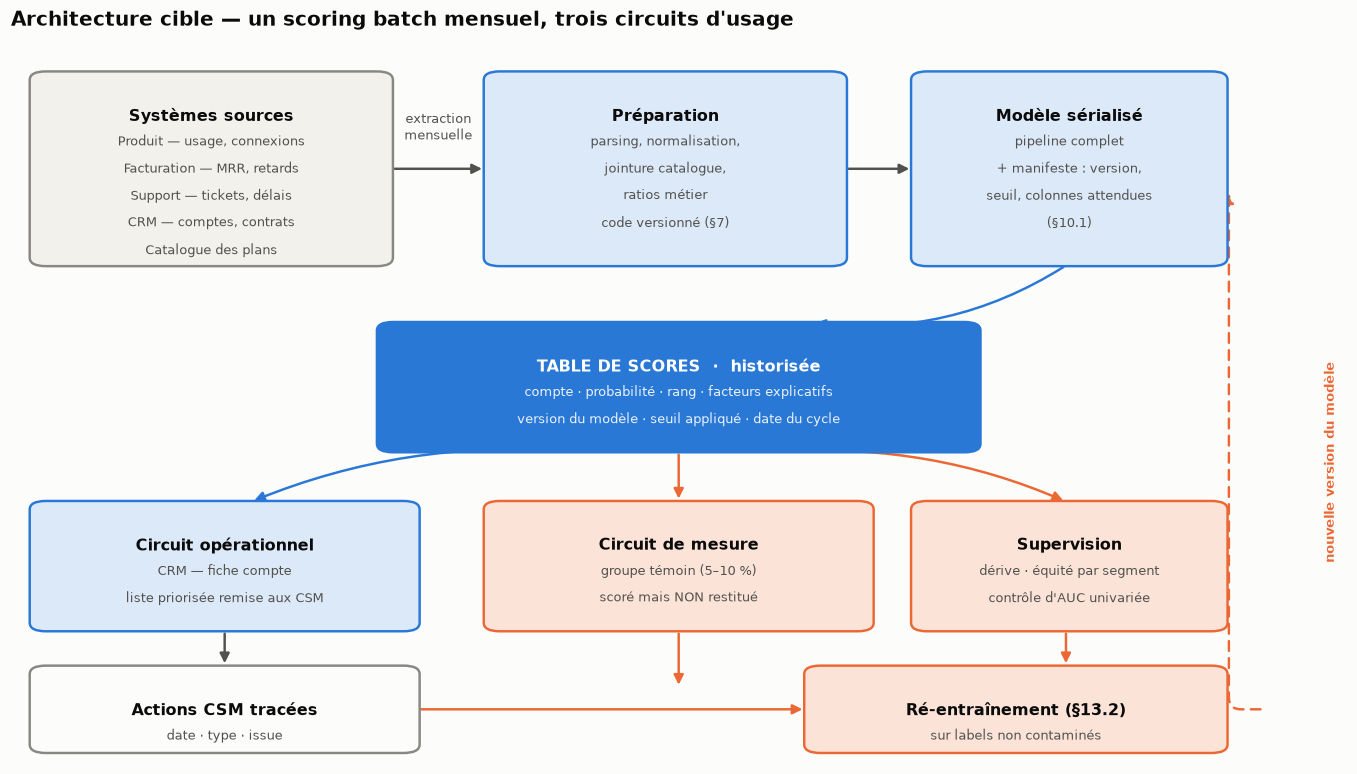



La table de scores porte, pour chaque compte, la probabilité de churn, la **valeur vie estimée**, le
risque de perte qui en résulte et le rang de priorité (§9.4). Trois circuits distincts en partent, et aucun n'est optionnel :

- **Le circuit opérationnel** — les scores atteignent le CSM dans son outil de travail. Un modèle qui
  exige d'ouvrir une autre application ne sera pas utilisé.
- **Le circuit de mesure** — le groupe témoin (§4.1) est scoré mais non restitué : il fournit les seuls
  labels non contaminés par l'intervention, sans lesquels ni la performance réelle ni l'impact métier
  ne sont mesurables.
- **Le circuit d'amélioration** — actions tracées et supervision alimentent le ré-entraînement (§13.2).

### 11.2 Choix d'architecture et justification

| Question | Choix | Justification |
|---|---|---|
| Batch ou temps réel ? | **Batch mensuel** | La décision est adossée à l'échéance contractuelle : aucune exigence de latence. Les données d'usage sont elles-mêmes des agrégats 30 jours, rescorer en continu n'apporterait rien |
| Où s'exécute le scoring ? | **Dans l'UE**, sur données rapatriées | `code_datacenter` révèle un hébergement multi-régions (`us-e1`, `ap-s1`) : scorer sur place créerait un transfert non nécessaire (§3.2) |
| Quelle forme d'exécution ? | **Tâche planifiée**, pas un service permanent | 5 000 comptes scorés en quelques secondes : un service en attente 24 h/24 coûterait plus que le calcul lui-même |
| Comment le CSM reçoit-il le score ? | **Intégration CRM**, sur la fiche compte | Le modèle doit atteindre l'utilisateur dans son outil de travail, avec le rang de priorité et les facteurs (§10.2) |
| Que stocke-t-on ? | **Chaque score produit, historisé** | Sans historique, ni dérive ni impact ne sont calculables (§12.3, §13.1). C'est un prérequis, pas une option |
| L'API est-elle nécessaire ? | **Optionnelle** au démarrage | Le batch suffit au besoin exprimé. L'API (§10.3) sert le rescoring à la demande depuis le CRM, utile mais non bloquant |
| Comment versionne-t-on ? | **Modèle, manifeste et code de préparation ensemble** | Tant que la préparation vit hors du `Pipeline` (§10.2), les deux artefacts doivent être déployés et versionnés de façon solidaire |

> **Le choix le plus structurant est le plus sobre.** Un scoring mensuel sur 5 000 comptes ne justifie
> ni orchestrateur distribué, ni entrepôt de *features*, ni plateforme MLOps. Dimensionner
> l'infrastructure au-delà du besoin créerait un coût de maintenance permanent au service d'un calcul
> qui tient en quelques secondes — et rendrait le dispositif dépendant de compétences que l'équipe n'a
> pas nécessairement.

### 11.3 Contraintes

La cellule suivante mesure ce que coûte réellement un cycle complet.

In [ ]:
import time

# --- Cout reel d'un cycle de scoring complet --------------------------------
portefeuille = pd.read_csv(
    F_COMPLET, dtype=str, keep_default_na=False, na_values=[""], encoding="utf-8-sig"
).drop_duplicates()

depart = time.perf_counter()
X_portefeuille = preparer_pour_scoring(portefeuille)
apres_preparation = time.perf_counter()
modele_production = joblib.load(CHEMIN_MODELE)
apres_chargement = time.perf_counter()
probabilites_portefeuille = modele_production.predict_proba(X_portefeuille)[:, 1]
fin = time.perf_counter()

etapes = pd.DataFrame(
    [
        {"etape": "preparation (§7 rejouee)", "duree_ms": round(1000 * (apres_preparation - depart))},
        {"etape": "chargement de l'artefact", "duree_ms": round(1000 * (apres_chargement - apres_preparation))},
        {"etape": "inference", "duree_ms": round(1000 * (fin - apres_chargement))},
    ]
)
etapes.loc[len(etapes)] = {"etape": "TOTAL", "duree_ms": int(etapes.duree_ms.sum())}

print(f"Cycle complet sur {len(portefeuille)} comptes :")
print(etapes.to_string(index=False))
print(f"\nDebit          : {len(portefeuille) / (fin - depart):,.0f} comptes par seconde".replace(",", "\u202f"))
print(f"Artefact       : {CHEMIN_MODELE.stat().st_size / 1024:.1f} Ko")
print(f"Alertes/cycle  : {int((probabilites_portefeuille >= SEUIL_RETENU).sum())} comptes "
      f"({(probabilites_portefeuille >= SEUIL_RETENU).mean():.1%} du portefeuille)")

# --- Marge de dimensionnement -----------------------------------------------
# A quel volume ce dispositif cesserait-il de tenir dans une tache planifiee ?
debit = len(portefeuille) / (fin - depart)
print(
    f"\nA ce debit, 1 million de comptes seraient scores en "
    f"{1_000_000 / debit:.1f} secondes : la volumetrie n'est pas le facteur limitant."
)


Cycle complet sur 5000 comptes :
                   etape  duree_ms
preparation (§7 rejouee)        40
chargement de l'artefact         1
               inference         6
                   TOTAL        47

Debit          : 108 177 comptes par seconde
Artefact       : 6.5 Ko
Alertes/cycle  : 987 comptes (19.7% du portefeuille)

A ce debit, 1 million de comptes seraient scores en 9.2 secondes : la volumetrie n'est pas le facteur limitant.


#### Constat

**Un cycle complet sur les 5 000 comptes prend moins d'un dixième de seconde**, artefact de 6 Ko
compris. À ce débit, un portefeuille de un million de comptes serait scoré en moins d'une minute : la
volumétrie n'est pas — et ne deviendra pas — le facteur limitant.

Cela commande directement le dimensionnement : une **tâche planifiée mensuelle** sur une machine
ordinaire suffit. Ni orchestrateur distribué, ni GPU, ni service permanent.

**Les contraintes réelles sont ailleurs.**

| Contrainte | Nature | Conséquence |
|---|---|---|
| **Capacité de traitement des CSM** | Fonctionnelle | C'est elle qui fixe le seuil (§9.3), donc le nombre d'alertes utiles. Le facteur limitant du dispositif est humain, pas technique |
| **Dépendance aux sources amont** | Opérationnelle | 22 variables issues de quatre systèmes. Une extraction défaillante ou un champ renommé interrompt le cycle : d'où les contrôles défensifs de §10.2 |
| **Fraîcheur des données** | Opérationnelle | Le scoring doit précéder l'échéance d'une marge suffisante pour qu'une action soit possible. Un score juste mais tardif ne vaut rien |
| **Localisation des données** | Réglementaire | Exécution dans l'UE, données rapatriées ; tout transfert résiduel relève d'un encadrement contractuel (§3.2) |
| **Compétences de l'équipe** | Organisationnelle | La chaîne repose sur Python, scikit-learn et une tâche planifiée — un socle courant. Toute complexité ajoutée devra être maintenue par l'équipe en place |
| **Réversibilité** | Stratégique | Aucune dépendance à un service propriétaire : l'artefact est un fichier, la préparation du code Python. Le dispositif peut être arrêté ou remplacé sans rupture |
| **Coût d'infrastructure** | Économique | Quelques secondes de calcul par mois, à rapporter aux 9,3 M€ de valeur nette estimée (§9.3) : le coût technique est négligeable devant l'enjeu |

**Chantiers d'industrialisation, hérités des limites identifiées :**

1. **Intégrer la préparation au `Pipeline`** (§10.2) — pour ne déployer et versionner qu'un seul objet.
2. **Historiser chaque score produit** — prérequis de la mesure d'impact (§12.3) et du suivi de dérive
   (§13.1).
3. **Tracer les actions CSM** (date, type, issue) — sans quoi les labels du prochain ré-entraînement
   seront contaminés par l'intervention (§4.1).
4. **Installer le groupe témoin** dès le premier cycle — la seule source de labels non biaisés.
5. **Automatiser le contrôle anti-fuite** (§7.6) à chaque ré-entraînement — une variable amont peut
   devenir fuyante sans prévenir.

Les quatre derniers ne sont pas des améliorations : ce sont les conditions pour que le dispositif reste
mesurable et ré-entraînable après sa mise en service.

### 11.4 Mise en œuvre de l'industrialisation

Les chantiers listés en §11.3 ne sont plus des intentions : le dépôt contient le code qui les réalise.
Le notebook reste la **référence méthodologique** ; le paquet `churn/` en est la **mise en œuvre
opérable**, testée et exécutable hors Jupyter.

#### Ce qui est livré

| Élément | Emplacement | Rôle |
|---|---|---|
| **Paquet applicatif** | `churn/` | `config` · `contrats` · `preparation` · `modele` · `scoring` · `surveillance` · `cli` |
| **Suite de tests** | `tests/` | 65 tests : conversions, contrats, priorisation, scoring bout-en-bout, dérive |
| **Ligne de commande** | `python -m churn …` | Ce que le planificateur appelle, sans Jupyter ni notebook |
| **Contrats de données** | `churn/contrats.py` | Schémas `pandera` en entrée et en sortie |
| **Image d'exécution** | `Dockerfile` | Environnement figé, exécution sans privilèges |
| **Maquette d'architecture** | `docker-compose.yml`, `sql/init.sql` | Entrepôt, serveur MLflow, Grafana |
| **Journal d'exécutions** | `churn/journal.py` | Trace de chaque cycle et *dead man's switch* sur la non-exécution |
| **Qualité et sécurité** | `pyproject.toml`, `.gitleaks.toml`, `.pre-commit-config.yaml` | `ruff` (analyse statique et formatage), `gitleaks` (recherche de secrets) |
| **Intégration continue** | `.github/workflows/ci.yml` | Qualité, puis tests, scoring de fumée et construction de l'image |
| **Tableaux de bord** | `grafana/provisioning/` | Source de données et tableau de bord provisionnés |

#### Le code du notebook devient un logiciel

```bash
python -m churn verifier --lot comptes.csv                  # contrat d'entrée
python -m churn score    --lot comptes.csv --sortie scores.csv
python -m churn derive   --reference cycle_n.csv --courant cycle_n1.csv
python -m churn statut                                      # le cycle a-t-il tourné ?
```

Les fonctions ne sont pas réécrites : `to_numeric_fr`, `normaliser_categorie`, `prioriser` et les
instruments de surveillance sont **les mêmes** que ceux du notebook, déplacés dans un module importable.
C'est la condition posée en §10.2 — une seule implémentation, donc aucune divergence possible entre
l'entraînement et la production.

#### Les `assert` du notebook deviennent une suite de tests

Les contrôles disséminés dans §7 à §13 sont désormais exécutables à la demande et en intégration
continue. Ils couvrent notamment :

- l'**absorption des défauts de format** — virgule décimale, `%`, `€`, unités, espaces insécables ;
- les **échecs explicites** — plan absent du catalogue, colonne manquante, identifiant dupliqué ;
- l'**invariant de la règle de décision** — aucun compte signalé sous le plancher de risque, capacité
  respectée, ordre strictement décroissant de risque de perte ;
- la **détection de fuite** — une variable artificiellement corrélée à la cible est bien signalée ;
- la **reproductibilité** — deux exécutions produisent des scores identiques.

#### Conteneurisation et planification

L'image embarque le code, les deux artefacts et le catalogue ; elle expose la ligne de commande comme
point d'entrée. Le conteneur **n'est pas un service** : il s'exécute, produit ses scores et s'arrête —
c'est un job, déclenché par `cron`, un `CronJob` Kubernetes ou une tâche planifiée ECS, conformément au
choix de §11.2.

```bash
docker run --rm -v "$PWD/data:/data" churn-saas:1.0.0 \
       score --lot /data/comptes.csv --sortie /data/scores.csv
```

Les paramètres métier restent des **variables d'environnement** (`CHURN_PLANCHER_RISQUE`,
`CHURN_CAPACITE`) : réviser la capacité des équipes ne demande ni reconstruction de l'image, ni
ré-entraînement (§13.3).

#### Supervision : Grafana oui, Prometheus non

La maquette `docker-compose` monte l'entrepôt, le serveur MLflow et Grafana. Le tableau de bord
provisionné lit **l'entrepôt de scores en SQL** — volume d'alertes par cycle, comptes éligibles, PSI par
variable, couverture par segment, liste des comptes prioritaires.

> **Pourquoi Prometheus n'est pas retenu.** Prometheus interroge des services **vivants** à haute
> fréquence. Le dispositif est un batch **mensuel** : il produit douze points de mesure par an et
> n'existe pas entre deux exécutions. Le motif adapté serait un *Pushgateway*, mais déployer
> Prometheus, Pushgateway et Alertmanager pour ce volume contredirait l'argument de sobriété de §11.2 —
> pour un coût de maintenance permanent. Les indicateurs de §13.1 sont **écrits dans l'entrepôt** à
> chaque cycle, ce qui suffit à les tracer, à les représenter et à déclencher une alerte par requête.

#### Qualité du code et recherche de secrets

Deux outils, exécutés sur le poste avant chaque commit (`pre-commit`) **et** en intégration continue,
dans un travail qui s'arrête **avant** les tests : une erreur de style ou un identifiant en clair
interrompt la chaîne sans consommer de temps de calcul.

| Outil | Rôle | Configuration |
|---|---|---|
| **ruff check** | Analyse statique : imports inutilisés, tournures obsolètes, pièges courants, ordre des imports | `pyproject.toml` — jeux `E`, `F`, `I`, `UP`, `B`, `SIM`, `C4`, `PTH`, `RUF` |
| **ruff format** | Formatage déterministe à 100 colonnes | `pyproject.toml` — les notebooks sont exclus, leur mise en page servant la lecture |
| **gitleaks** | Recherche de secrets dans les fichiers **et dans l'historique git** | `.gitleaks.toml` — jeu de règles par défaut, plus une règle sur les chaînes de connexion |

> **Un seul outil pour l'analyse et le formatage.** `ruff format` applique les mêmes conventions que
> `black` — il en reprend le modèle — mais évite d'entretenir deux configurations susceptibles de se
> contredire, et de figer deux versions dont les mises à jour ne sont pas synchronisées. Une dépendance
> de moins pour un résultat identique.

**Pourquoi gitleaks sur ce projet.** Le dispositif ne manipule pas de données personnelles sensibles
(§3.2), mais il touche à une base de données, à un serveur MLflow et, en cible, à une API : identifiants,
jetons et chaînes de connexion sont les fuites à prévenir. La recherche porte sur l'historique complet
(`fetch-depth: 0`), car un secret retiré dans un commit ultérieur reste lisible dans les précédents.

Les identifiants de la maquette `docker-compose` — volontairement publics et sans usage hors du poste —
sont déclarés dans l'`allowlist` du fichier de configuration plutôt que tolérés en silence : une
exception nommée est auditable, une exception implicite ne l'est pas.

```bash
make qualite          # ruff check + ruff format + gitleaks
make format-ecrit     # applique le formatage et les corrections automatiques
pre-commit install    # les mêmes contrôles avant chaque commit
```

#### Orchestration : `cron` aujourd'hui, orchestrateur le jour où

Le choix de §11.2 reste valide — une tâche planifiée suffit à un batch mensuel. Mais `cron` a une
faiblesse qu'il faut traiter, et non ignorer : **l'échec silencieux**. Un job qui ne s'exécute pas, ou
qui échoue à trois heures du matin, ne produit aucun signal. Sur un rythme mensuel, personne ne s'en
aperçoit avant le cycle suivant — et un cycle perdu, ce sont des comptes non signalés, donc des
résiliations non traitées.

**La parade est en place.** Chaque exécution laisse une trace dans le journal
(`artefacts/journal_executions.jsonl`, table `executions` de l'entrepôt) : horodatage, statut, nombre de
comptes, nombre d'alertes, durée. Un échec est **consigné avant d'être remonté**, avec son message
d'erreur. Et la commande dédiée implémente un *dead man's switch* :

```bash
python -m churn statut --max-jours 35    # code de sortie 1 si aucun cycle réussi depuis 35 jours
```

Elle détecte l'**absence** d'exécution, pas seulement l'échec — la panne la plus difficile à repérer sur
un job planifié. Appelée par le planificateur ou par une alerte Grafana sur la table `executions`, elle
transforme un silence en alerte.

> **Quand un orchestrateur (Prefect, Airflow, Dagster) devient justifié.** Trois situations, qu'il faut
> distinguer d'un réflexe d'outillage :
>
> 1. **Le client en exploite déjà un.** S'y brancher est alors évident : l'image Docker s'exécute telle
>    quelle comme tâche, sans rien réécrire.
> 2. **La chaîne devient un véritable enchaînement.** Extraction depuis les quatre systèmes sources,
>    préparation, scoring, écriture, surveillance, ré-entraînement conditionnel : six étapes dépendantes
>    avec reprise sur incident et relance partielle, c'est exactement ce qu'un orchestrateur fait mieux
>    qu'un script. Aujourd'hui, ces étapes tiennent en **une commande**.
> 3. **La fréquence augmente.** Un scoring hebdomadaire ou quotidien rend la supervision manuelle
>    intenable.
>
> Aucune de ces trois conditions n'est remplie aujourd'hui : déployer un serveur d'orchestration pour
> douze exécutions par an ajouterait une infrastructure à maintenir sans réduire un risque que le
> journal d'exécutions ne couvre déjà.

#### Ce qui reste à faire

| Chantier | État |
|---|---|
| Intégrer la préparation au `Pipeline` sérialisé | **Ouvert** — le paquet garantit une implémentation unique, mais deux artefacts restent à versionner ensemble |
| Écriture des scores dans l'entrepôt par le job | **Ouvert** — le schéma existe (`sql/init.sql`), le raccordement reste à faire |
| Alimentation automatique du registre MLflow au ré-entraînement | **Ouvert** (§13.3) |
| Authentification et journalisation de l'API | **Ouvert** (§10.3) |



---

## 12. Mesure de performance et impacts

### 12.1 Performance technique — classification (`churn`)

**Le jeu de test est ouvert ici, pour la première et unique fois.** Il n'a servi ni à préparer les
données (§7), ni à comparer les modèles (§9.1), ni à régler les hyperparamètres (§9.2), ni à choisir le
seuil (§9.3) — toutes ces décisions ont été prises par validation croisée sur le jeu d'entraînement.
Les 1 000 comptes qu'il contient sont donc, pour le modèle, des comptes inconnus.

Premièrement on regarde si le modèle **« se comporte-t-il comme annoncé ? »**.
Un écart important entre la performance estimée en validation croisée et celle mesurée ici signalerait
un sur-ajustement lors de l'entrainement.

In [ ]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_score, recall_score)

# --- Unique evaluation sur le jeu scelle ------------------------------------
probabilites_test = MODELE_FINAL.predict_proba(X_test)[:, 1]

# La selection livree applique la regle de §9.4 : plancher de risque, puis
# priorisation par risque de perte dans la limite de la capacite.
valeur_estimee_test = MODELE_VALEUR.predict(X_test)
CAPACITE_TEST = int(round(CAPACITE_CSM * len(X_test)))
selection_test, rangs_test = prioriser(
    probabilites_test, valeur_estimee_test, CAPACITE_TEST
)
predictions_test = selection_test.astype(int)

auc_test = roc_auc_score(y_test, probabilites_test)
pr_auc_test = average_precision_score(y_test, probabilites_test)

comparaison = pd.DataFrame(
    {
        "validation croisee (train)": [
            resultats_candidats.loc[CANDIDAT_RETENU, "roc_auc"],
            resultats_candidats.loc[CANDIDAT_RETENU, "pr_auc"],
        ],
        "test (jamais vu)": [auc_test, pr_auc_test],
    },
    index=["ROC-AUC", "PR-AUC"],
)
comparaison["ecart"] = comparaison["test (jamais vu)"] - comparaison["validation croisee (train)"]
print(f"Jeu de test : {len(X_test)} comptes, {int(y_test.sum())} resiliations "
      f"({y_test.mean():.1%})\n")
print(comparaison.round(4).to_string())

marge_cv = resultats_candidats.loc[CANDIDAT_RETENU, "roc_auc_ecart"]
print(f"\nEcart-type entre plis en validation croisee : +/- {marge_cv:.4f}")
print(
    "-> ecart test/CV "
    + ("DANS" if abs(comparaison.loc["ROC-AUC", "ecart"]) < marge_cv else "HORS")
    + " la marge : la performance annoncee se confirme"
)

# --- Au seuil metier retenu -------------------------------------------------
print(f"\nSelon la regle de §9.4 (plancher {PLANCHER_RISQUE}, capacite {CAPACITE_CSM:.0%}) :")
print(classification_report(y_test, predictions_test, digits=3,
                            target_names=["conserve", "resilie"]))
print(f"Comptes alertes : {int(predictions_test.sum())} "
      f"({predictions_test.mean():.1%} du jeu de test)")
print(f"Valeur vie mediane des comptes alertes : "
      f"{np.median(clv_test[selection_test]):,.0f} EUR "
      f"(portefeuille : {np.median(clv_test):,.0f} EUR)".replace(",", "\u202f"))


Jeu de test : 1000 comptes, 280 resiliations (28.0%)

         validation croisee (train)  test (jamais vu)   ecart
ROC-AUC                      0.8907            0.8832 -0.0075
PR-AUC                       0.7921            0.7622 -0.0300

Ecart-type entre plis en validation croisee : +/- 0.0085
-> ecart test/CV DANS la marge : la performance annoncee se confirme

Selon la regle de §9.4 (plancher 0.3, capacite 20%) :
              precision    recall  f1-score   support

    conserve      0.814     0.904     0.857       720
     resilie      0.655     0.468     0.546       280

    accuracy                          0.782      1000
   macro avg      0.734     0.686     0.701      1000
weighted avg      0.769     0.782     0.770      1000

Comptes alertes : 200 (20.0% du jeu de test)
Valeur vie mediane des comptes alertes : 20 202 EUR (portefeuille : 11 602 EUR)


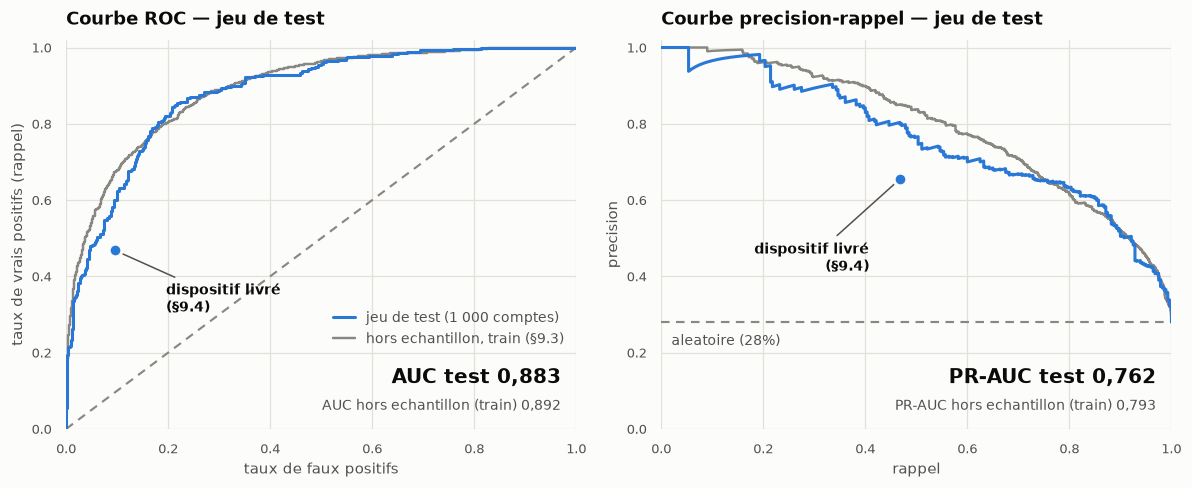

In [ ]:
# --- Les memes figures qu'en §9.3, sur le jeu de test ------------------------
fpr_t, tpr_t, seuils_roc_t = roc_curve(y_test, probabilites_test)
precision_t, rappel_t, seuils_pr_t = precision_recall_curve(y_test, probabilites_test)
# Point de fonctionnement REEL du dispositif : la regle de §9.4 ne se reduit
# pas a un seuil de probabilite, on place donc le couple (rappel, precision)
# effectivement obtenu plutot qu'un point de la courbe.
rappel_livre = recall_score(y_test, predictions_test)
precision_livree = precision_score(y_test, predictions_test)
fpr_livre = ((predictions_test == 1) & (y_test == 0)).sum() / (y_test == 0).sum()

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 4.6))
fig.patch.set_facecolor(SURFACE)

ax_roc.set_facecolor(SURFACE)
ax_roc.plot([0, 1], [0, 1], color=CONTEXTE, linewidth=1.4, linestyle=(0, (4, 3)), zorder=2)
ax_roc.plot(fpr, tpr, color=CONTEXTE, linewidth=1.6, zorder=3)
ax_roc.plot(fpr_t, tpr_t, color=ACCENT, linewidth=2, zorder=4)
ax_roc.scatter([fpr_livre], [rappel_livre], s=70, color=ACCENT, edgecolor=SURFACE,
               linewidth=2, zorder=5)
ax_roc.annotate("dispositif livré\n(§9.4)", xy=(fpr_livre, rappel_livre),
                xytext=(fpr_livre + 0.10, rappel_livre - 0.16), fontsize=9,
                color=INK, fontweight="bold",
                arrowprops=dict(arrowstyle="-", color=INK_2, linewidth=1))
ax_roc.text(0.97, 0.12, f"AUC test {auc_test:.3f}".replace(".", ","), ha="right",
            fontsize=13, fontweight="bold", color=INK)
ax_roc.text(0.97, 0.05, f"AUC hors echantillon (train) {auc_roc:.3f}".replace(".", ","),
            ha="right", fontsize=9, color=INK_2)
ax_roc.set_xlabel("taux de faux positifs", fontsize=9.5, color=INK_2)
ax_roc.set_ylabel("taux de vrais positifs (rappel)", fontsize=9.5, color=INK_2)
ax_roc.set_title("Courbe ROC — jeu de test", loc="left", fontsize=12, fontweight="bold",
                 color=INK, pad=10)

ax_pr.set_facecolor(SURFACE)
prevalence_test = float(y_test.mean())
ax_pr.axhline(prevalence_test, color=CONTEXTE, linewidth=1.4, linestyle=(0, (4, 3)), zorder=2)
ax_pr.plot(rappel, precision, color=CONTEXTE, linewidth=1.6, zorder=3)
ax_pr.plot(rappel_t, precision_t, color=ACCENT, linewidth=2, zorder=4)
ax_pr.scatter([rappel_livre], [precision_livree], s=70, color=ACCENT,
              edgecolor=SURFACE, linewidth=2, zorder=5)
ax_pr.annotate("dispositif livré\n(§9.4)", xy=(rappel_livre, precision_livree),
               xytext=(rappel_livre - 0.06, precision_livree - 0.24), ha="right",
               fontsize=9, color=INK, fontweight="bold",
               arrowprops=dict(arrowstyle="-", color=INK_2, linewidth=1))
ax_pr.text(0.02, prevalence_test - 0.06, f"aleatoire ({prevalence_test:.0%})",
           fontsize=9, color=INK_2)
ax_pr.text(0.97, 0.12, f"PR-AUC test {pr_auc_test:.3f}".replace(".", ","), ha="right",
           fontsize=13, fontweight="bold", color=INK)
ax_pr.text(0.97, 0.05, f"PR-AUC hors echantillon (train) {auc_pr:.3f}".replace(".", ","),
           ha="right", fontsize=9, color=INK_2)
ax_pr.set_xlabel("rappel", fontsize=9.5, color=INK_2)
ax_pr.set_ylabel("precision", fontsize=9.5, color=INK_2)
ax_pr.set_title("Courbe precision-rappel — jeu de test", loc="left", fontsize=12,
                fontweight="bold", color=INK, pad=10)

for ax in (ax_roc, ax_pr):
    ax.set_xlim(0, 1.0); ax.set_ylim(0, 1.02)
    ax.grid(color=GRILLE, linewidth=0.8); ax.set_axisbelow(True)
    ax.tick_params(labelsize=8.5, colors=INK_2)
    for bord in ax.spines.values():
        bord.set_visible(False)
ax_roc.legend(handles=[
    plt.Line2D([], [], color=ACCENT, linewidth=2, label="jeu de test (1 000 comptes)"),
    plt.Line2D([], [], color=CONTEXTE, linewidth=1.6, label="hors echantillon, train (§9.3)"),
], loc="lower right", bbox_to_anchor=(1.0, 0.18), frameon=False, fontsize=9,
   labelcolor=INK_2, handlelength=1.6)
plt.tight_layout()
plt.show()


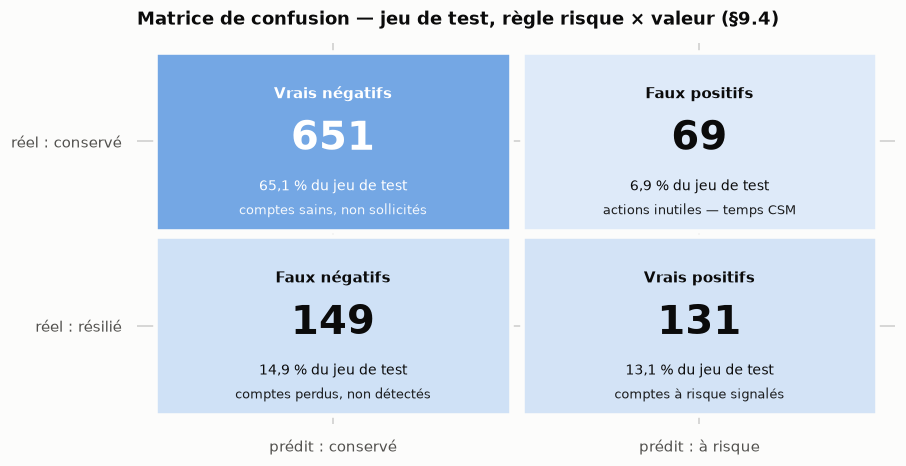

In [ ]:
# --- Matrice de confusion sur le jeu de test ---------------------------------
matrice_test = confusion_matrix(y_test, predictions_test)

fig, ax = plt.subplots(figsize=(8.4, 4.4))
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)
rampe = LinearSegmentedColormap.from_list("bleu", ["#ffffff", ACCENT])
maxi = matrice_test.max()
libelles = [
    [("Vrais négatifs", "comptes sains, non sollicités"),
     ("Faux positifs", "actions inutiles — temps CSM")],
    [("Faux négatifs", "comptes perdus, non détectés"),
     ("Vrais positifs", "comptes à risque signalés")],
]
for l in range(2):
    for c in range(2):
        valeur = matrice_test[l, c]
        intensite = valeur / maxi
        ax.add_patch(plt.Rectangle((c, 1 - l), 0.97, 0.97,
                                   facecolor=rampe(0.10 + 0.55 * intensite),
                                   edgecolor=SURFACE, linewidth=3))
        encre = "#ffffff" if intensite > 0.55 else INK
        titre, sous = libelles[l][c]
        ax.text(c + 0.485, 1.72 - l, titre, ha="center", fontsize=10, fontweight="bold", color=encre)
        ax.text(c + 0.485, 1.44 - l, f"{valeur}", ha="center", fontsize=26,
                fontweight="bold", color=encre)
        ax.text(c + 0.485, 1.22 - l, f"{100 * valeur / matrice_test.sum():.1f} % du jeu de test".replace(".", ","),
                ha="center", fontsize=9, color=encre)
        ax.text(c + 0.485, 1.09 - l, sous, ha="center", fontsize=8.5, color=encre, alpha=0.92)

ax.set_xlim(-0.05, 2.02); ax.set_ylim(-0.05, 2.02)
ax.set_xticks([0.485, 1.485]); ax.set_yticks([1.485, 0.485])
ax.set_xticklabels(["prédit : conservé", "prédit : à risque"], fontsize=9.5, color=INK_2)
ax.set_yticklabels(["réel : conservé", "réel : résilié"], fontsize=9.5, color=INK_2)
ax.tick_params(axis="both", length=0, pad=10)
ax.set_title("Matrice de confusion — jeu de test, règle risque × valeur (§9.4)",
             loc="left", fontsize=12, fontweight="bold", color=INK, pad=12)
for bord in ax.spines.values():
    bord.set_visible(False)
plt.tight_layout()
plt.show()


#### Constat

**La performance annoncée se confirme.** ROC-AUC de **0,883** sur le test contre 0,891 estimé par
validation croisée : un écart de 0,0075, inférieur à l'écart-type entre plis (0,0085). Le modèle se
comporte sur des comptes inconnus comme il se comportait en validation — aucune trace de
sur-ajustement aux choix faits en §7 à §9.

**La PR-AUC recule un peu plus** : 0,762 contre 0,792, soit −0,030 pour un écart-type entre plis de
0,0186. L'écart dépasse donc légèrement la marge, et c'est cohérent avec la nature de la métrique — la
PR-AUC ne dépend que des 280 résiliations du jeu de test, et son estimation est mécaniquement plus
instable que celle de la ROC-AUC, calculée sur les 1 000 comptes. L'ordre de grandeur reste tenu, mais
c'est cette métrique qu'il faudra surveiller en priorité en production (§13.1).

**Ces deux métriques évaluent le classement, indépendamment de toute règle de décision.** Les
indicateurs qui suivent portent, eux, sur la **sélection réellement livrée** : plancher de risque à
0,30 puis priorisation par risque de perte (§9.4).

| | Valeur | Lecture |
|---|---|---|
| Comptes alertés | **200** (20,0 %) | Exactement la capacité CSM — la règle sature la capacité, par construction |
| Précision | **0,655** | Deux alertes sur trois portent sur un compte qui a effectivement résilié |
| Rappel | **0,468** | Un peu moins d'une résiliation sur deux est détectée |
| Faux négatifs | **149** | Des comptes perdus sans avoir été signalés |
| Valeur vie médiane des alertés | **20 202 €** | Contre 11 602 € pour le portefeuille : les comptes traités pèsent près du double |

**Le rappel et la précision sont inférieurs à ceux qu'obtiendrait un tri par probabilité seule**
(0,511 et 0,737). C'est attendu, et c'est le prix explicitement consenti en §9.4 : la règle sacrifie
du volume de détection pour concentrer l'effort sur les comptes dont la perte serait la plus lourde.
§12.3 chiffre ce que ce sacrifice rapporte.

**Les courbes test et hors échantillon se superposent** (le tracé gris sur les figures) : elles se
suivent sur toute leur longueur, sans divergence dans une zone particulière de seuils. Le point marqué
sur chaque courbe est le **point de fonctionnement réel du dispositif**, et non un seuil de
probabilité — la règle de §9.4 ne se réduit pas à un seuil.

#### La probabilité est-elle fiable ?

Les métriques précédentes évaluent un **classement** : elles ne disent rien de la justesse des
probabilités elles-mêmes. Un modèle qui annoncerait systématiquement 0,80 là où le risque réel est 0,50
classerait parfaitement — et tromperait tout le monde.

La question n'est pas théorique ici, car le dispositif utilise la probabilité **comme une quantité**, à
deux endroits :

1. **Le risque de perte** (§9.4) multiplie la probabilité par la valeur vie. Un biais systématique sur `p`
   se propage directement au classement risque × valeur.
2. **La restitution au CSM** annonce un niveau de risque. Dire « ce compte a 70 % de risque » n'est
   défendable que si, sur cent comptes ainsi notés, environ soixante-dix résilient effectivement.

On confronte donc, décile par décile, la probabilité **prédite** à la fréquence **observée** — c'est le
diagramme de fiabilité. Le score de Brier résume l'écart quadratique moyen entre les deux.

Fiabilite des probabilites, sur le jeu de test :
           probabilite_predite  frequence_observee  ecart
decile 1                 0.007                0.00 -0.007
decile 2                 0.024                0.02 -0.004
decile 3                 0.049                0.05  0.001
decile 4                 0.083                0.10  0.017
decile 5                 0.130                0.10 -0.030
decile 6                 0.199                0.13 -0.069
decile 7                 0.304                0.40  0.096
decile 8                 0.462                0.53  0.068
decile 9                 0.638                0.57 -0.068
decile 10                0.900                0.90  0.000

Score de Brier            : 0.1200
Reference (prevalence)    : 0.2016 -> reduction de 40%
Probabilite moyenne predite : 0.2796
Prevalence observee         : 0.2800
Ecart absolu maximal par decile : 0.096
  dont deciles au-dela de 2 erreurs-types : 1 / 10
Ecart maximal hors echantillon (train, 4000 comptes) : 0.

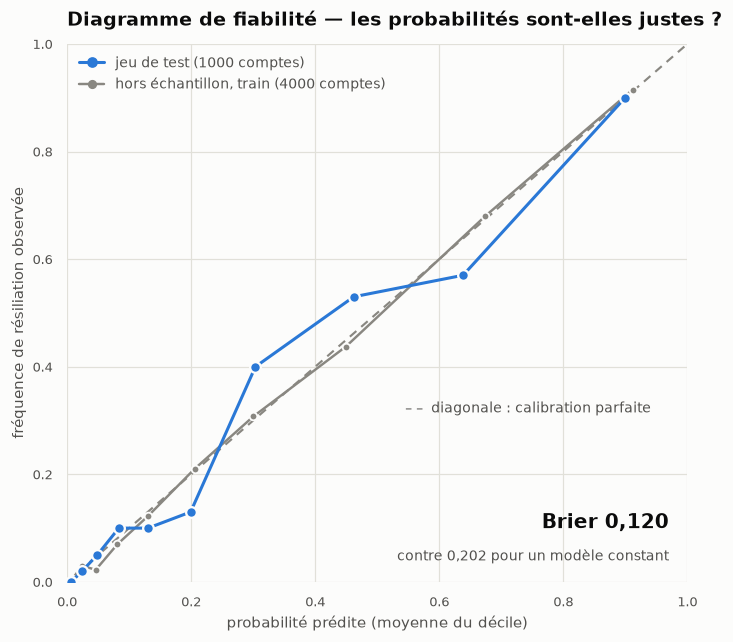

In [ ]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# --- Diagramme de fiabilite : predit contre observe, par decile ------------
frequence_observee, probabilite_moyenne = calibration_curve(
    y_test, probabilites_test, n_bins=10, strategy="quantile"
)

fiabilite = pd.DataFrame(
    {
        "probabilite_predite": probabilite_moyenne.round(3),
        "frequence_observee": frequence_observee.round(3),
        "ecart": (frequence_observee - probabilite_moyenne).round(3),
    }
)
fiabilite.index = [f"decile {k}" for k in range(1, len(fiabilite) + 1)]
print("Fiabilite des probabilites, sur le jeu de test :")
print(fiabilite.to_string())

# Reference hors echantillon (4 000 comptes) : un decile y compte 400 comptes
# contre 100 sur le test, l'estimation y est donc quatre fois plus stable.
frequence_train, probabilite_train = calibration_curve(
    y_train, probabilites_train, n_bins=10, strategy="quantile"
)
ecart_max_train = float(np.abs(frequence_train - probabilite_train).max())

brier = brier_score_loss(y_test, probabilites_test)
brier_trivial = brier_score_loss(y_test, np.full(len(y_test), y_train.mean()))
print(f"\nScore de Brier            : {brier:.4f}")
print(f"Reference (prevalence)    : {brier_trivial:.4f} "
      f"-> reduction de {1 - brier / brier_trivial:.0%}")
print(f"Probabilite moyenne predite : {probabilites_test.mean():.4f}")
print(f"Prevalence observee         : {y_test.mean():.4f}")
print(f"Ecart absolu maximal par decile : {np.abs(fiabilite.ecart).max():.3f}")

# L'ecart observe est-il distinguable du bruit d'echantillonnage ?
# Erreur-type d'une proportion p sur un decile de n comptes : sqrt(p(1-p)/n).
n_par_decile = len(y_test) // 10
erreur_type = np.sqrt(probabilite_moyenne * (1 - probabilite_moyenne) / n_par_decile)
print(f"  dont deciles au-dela de 2 erreurs-types : "
      f"{int((np.abs(fiabilite.ecart.to_numpy()) > 2 * erreur_type).sum())} / 10")
print(f"Ecart maximal hors echantillon (train, {len(y_train)} comptes) : {ecart_max_train:.3f}")

# --- Figure -----------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6.6, 6.0))
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)

ax.plot([0, 1], [0, 1], color=CONTEXTE, linewidth=1.4, linestyle=(0, (4, 3)), zorder=2)
ax.plot(probabilite_train, frequence_train, color=CONTEXTE, linewidth=1.6,
        marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.2, zorder=3)
ax.plot(probabilite_moyenne, frequence_observee, color=ACCENT, linewidth=2,
        marker="o", markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=4)
ax.legend(handles=[
    plt.Line2D([], [], color=ACCENT, linewidth=2, marker="o", markersize=6,
               label=f"jeu de test ({len(y_test)} comptes)"),
    plt.Line2D([], [], color=CONTEXTE, linewidth=1.6, marker="o", markersize=5,
               label=f"hors échantillon, train ({len(y_train)} comptes)"),
], loc="upper left", frameon=False, fontsize=9, labelcolor=INK_2, handlelength=1.8)

ax.text(0.545, 0.315, "– –  diagonale : calibration parfaite", fontsize=9, color=INK_2)
ax.text(0.97, 0.10, f"Brier {brier:.3f}".replace(".", ","), ha="right",
        fontsize=13, fontweight="bold", color=INK)
ax.text(0.97, 0.04, f"contre {brier_trivial:.3f} pour un modèle constant".replace(".", ","),
        ha="right", fontsize=9, color=INK_2)

ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("probabilité prédite (moyenne du décile)", fontsize=9.5, color=INK_2)
ax.set_ylabel("fréquence de résiliation observée", fontsize=9.5, color=INK_2)
ax.set_title("Diagramme de fiabilité — les probabilités sont-elles justes ?",
             loc="left", fontsize=12.5, fontweight="bold", color=INK, pad=12)
ax.grid(color=GRILLE, linewidth=0.8); ax.set_axisbelow(True)
ax.tick_params(labelsize=8.5, colors=INK_2)
for bord in ax.spines.values():
    bord.set_visible(False)
plt.tight_layout()
plt.show()

# --- Controle : la calibration conditionne l'usage de la risque de perte ------
assert np.abs(fiabilite.ecart).max() < 0.10, (
    "ecart de calibration trop important : recalibrer avant d'utiliser p x valeur"
)


#### Constat

**Aucun biais global.** La probabilité moyenne prédite vaut **0,2796** pour une prévalence observée de
**0,2800** : le modèle ne surestime ni ne sous-estime le risque d'ensemble. Le score de Brier s'établit à
**0,120** contre 0,202 pour un modèle qui prédirait la prévalence à tout le monde, soit une **réduction
de 40 %**.

**Les écarts par décile sont compatibles avec le bruit d'échantillonnage.** L'écart maximal atteint
**9,6 points** au 7ᵉ décile (0,304 prédit contre 0,400 observé) — un chiffre qu'il faut rapporter à sa
précision : un décile du jeu de test ne compte que **100 comptes**, et l'erreur-type d'une proportion y
vaut environ 4,6 points. Un écart de 9,6 points est donc à deux erreurs-types, c'est-à-dire à la limite
de ce que le hasard produit seul.

**La comparaison avec le train hors échantillon tranche la question.** Sur 4 000 comptes — quatre fois
plus par décile —, l'écart maximal tombe à **2,4 points**, et le tracé gris épouse la diagonale. Si le
modèle était réellement mal calibré, l'écart ne se résorberait pas en augmentant l'effectif : il
persisterait. Ce qu'on observe sur le test est du bruit, pas un défaut.

**Ce résultat n'est pas un hasard de configuration.** Trois choix antérieurs y contribuent :

1. **Aucun rééquilibrage de classes** (§8.2). Pondérer aurait décalé les probabilités hors de leur
   échelle réelle et imposé une recalibration.
2. **Une régression logistique**, qui optimise directement la vraisemblance — donc la justesse des
   probabilités —, là où un modèle à base d'arbres tend à produire des scores trop tranchés.
3. **Une régularisation modérée** (§9.2), qui n'écrase pas les coefficients au point d'aplatir les
   probabilités vers la moyenne.

**Ce que cela autorise, et qui n'allait pas de soi :**

| Usage | Condition remplie |
|---|---|
| Multiplier `p × valeur` pour obtenir un risque de perte (§9.4) | Oui — aucun biais systématique à propager |
| Annoncer un niveau de risque au CSM (« 70 % ») | Oui — sur cent comptes notés 0,70, environ soixante-dix résilient |
| Comparer les cycles sur la distribution des probabilités (§13.1) | Oui — le PSI sur les scores mesure alors une dérive réelle, pas un décalage d'échelle |

> **À surveiller en production.** La calibration se dégrade avant la capacité de discrimination : une
> AUC stable peut masquer des probabilités qui dérivent. Le score de Brier et l'écart maximal de
> calibration sont donc à recalculer à chaque cycle sur le groupe témoin, au même titre que la PR-AUC
> (§13.1). Si l'écart devenait systématique — et non plus dispersé comme ici —, une recalibration
> (*Platt scaling* ou isotonique, ajustée sur le témoin) suffirait, **sans ré-entraîner le modèle**.

#### Performance par segment

Une AUC globale peut masquer une défaillance sur un sous-ensemble de clients. §4.1 a inscrit l'équité
comme une exigence **mesurée** et non affirmée : la performance est donc relue par secteur d'activité
et par taille d'entreprise.

In [ ]:
# --- La performance tient-elle sur tous les segments ? ----------------------
segments = pd.DataFrame(
    {
        "secteur": X_test.secteur.to_numpy(),
        "taille_entreprise": X_test.taille_entreprise.to_numpy(),
        "reel": y_test.to_numpy(),
        "probabilite": probabilites_test,
    }
)
segments["alerte"] = predictions_test   # la selection livree (§9.4)


def performance_par(colonne: str) -> pd.DataFrame:
    lignes = []
    for modalite, groupe in segments.groupby(colonne):
        if groupe.reel.nunique() < 2:   # AUC indefinie si une seule classe
            continue
        lignes.append(
            {
                colonne: modalite,
                "comptes": len(groupe),
                "churn_%": round(100 * groupe.reel.mean(), 1),
                "roc_auc": round(roc_auc_score(groupe.reel, groupe.probabilite), 3),
                "rappel": round(recall_score(groupe.reel, groupe.alerte), 3),
                "precision": round(precision_score(groupe.reel, groupe.alerte, zero_division=0), 3),
            }
        )
    return pd.DataFrame(lignes).sort_values("comptes", ascending=False, ignore_index=True)


for colonne in ("secteur", "taille_entreprise"):
    tableau = performance_par(colonne)
    print(f"Performance par {colonne} :")
    print(tableau.to_string(index=False))
    print(f"  amplitude des AUC : {tableau.roc_auc.min():.3f} -> {tableau.roc_auc.max():.3f}\n")


Performance par secteur :
  secteur  comptes  churn_%  roc_auc  rappel  precision
  FINANCE      170     25.3    0.857   0.488      0.750
     TECH      168     30.4    0.895   0.510      0.634
 COMMERCE      162     30.9    0.848   0.400      0.606
INDUSTRIE      150     28.0    0.903   0.381      0.552
    SANTÉ      123     23.6    0.929   0.552      0.727
ÉDUCATION      114     28.1    0.886   0.594      0.655
   PUBLIC       59     30.5    0.878   0.333      0.750
  INCONNU       54     27.8    0.880   0.467      0.700
  amplitude des AUC : 0.848 -> 0.929

Performance par taille_entreprise :
taille_entreprise  comptes  churn_%  roc_auc  rappel  precision
              PME      396     31.6    0.839   0.616      0.642
              TPE      326     29.8    0.882   0.062      0.857
              ETI      197     20.8    0.941   0.780      0.627
               GE       81     21.0    0.964   0.941      0.727
  amplitude des AUC : 0.839 -> 0.964



#### Constat

**Le pouvoir discriminant du modèle est homogène.** Les AUC s'échelonnent de **0,848** (Commerce) à
**0,929** (Santé) par secteur, et de **0,839** (PME) à **0,964** (GE) par taille. Le modèle *ordonne*
correctement les comptes dans tous les segments.

**La couverture, elle, ne l'est pas — et l'écart est considérable.**

| Segment | Rappel | Lecture |
|---|---|---|
| GE | **0,941** | 94 % des grands comptes qui résilient sont signalés |
| ETI | 0,780 | |
| PME | 0,616 | |
| TPE | **0,062** | **6 %** des très petites entreprises qui résilient sont signalées |

C'est la conséquence directe et arithmétique de la règle de §9.4 : à capacité finie, hiérarchiser par
risque de perte revient à servir d'abord les comptes de forte valeur, et la valeur est corrélée à la
taille. **Une TPE qui résilie n'est pratiquement jamais contactée.**

> **Ce constat doit être porté au commanditaire comme une décision, pas comme un résultat technique.**
> Le dispositif livré applique la politique définie en §2.2 — prioriser selon le rapport risque/valeur.
> Sa conséquence est une inégalité de service assumée entre segments de clientèle. Trois voies existent
> si elle est jugée excessive :
>
> 1. **Un plancher de risque plus élevé**, qui resserre la sélection vers les comptes réellement à
>    risque et atténue l'effet de taille (§9.4 en chiffre le coût).
> 2. **Une capacité réservée par segment** — par exemple 15 % de la capacité allouée aux TPE/PME,
>    hiérarchisées entre elles par risque de perte.
> 3. **Un retour au tri par probabilité seule**, qui traite tous les comptes selon le même critère au
>    prix d'une valeur protégée bien moindre (§12.3).
>
> Le choix relève de la politique commerciale et de l'appréciation du risque de réputation, pas du
> modèle. Il est documenté ici pour être fait en connaissance de cause.

**L'écart d'AUC entre GE et PME** (0,964 contre 0,839) reste à interpréter avec prudence : 81 comptes
`GE` suffisent à produire une estimation flatteuse par hasard. À suivre dans le temps (§13.1) plutôt
qu'à conclure aujourd'hui.

### 12.2 Lecture explicable des facteurs

Deux lectures complémentaires, qui ne disent pas la même chose :

- **Les coefficients** — propres au modèle linéaire, ils donnent le **sens** et l'**ampleur** de chaque
  effet, exprimés en rapports de cotes (§ fiche log-odds). Ils répondent à : *dans quel sens et de
  combien cette variable pousse-t-elle le risque ?*
- **L'importance par permutation** — applicable à n'importe quel modèle, elle mesure la **perte de
  performance** quand on détruit l'information d'une variable en mélangeant ses valeurs. Elle répond
  à : *que perdrait-on à ne plus disposer de cette variable ?*

La première est interprétable mais suppose le modèle vrai ; la seconde est agnostique mais ne dit rien
du sens de l'effet. Leur convergence est un indice de robustesse ; leur divergence signalerait une
redondance entre variables.

In [ ]:
from sklearn.inspection import permutation_importance

# --- 1. Coefficients, lus en rapports de cotes ------------------------------
noms_colonnes = MODELE_FINAL.named_steps["preparation"].get_feature_names_out()
coefficients = MODELE_FINAL.named_steps["modele"].coef_[0]

effets = (
    pd.DataFrame(
        {
            "variable": noms_colonnes,
            "coefficient": coefficients,
            "rapport_de_cotes": np.exp(coefficients),
        }
    )
    .query("abs(coefficient) > 1e-8")
    .assign(sens=lambda d: np.where(d.coefficient > 0, "aggravant", "protecteur"))
)
effets = effets.reindex(effets.coefficient.abs().sort_values(ascending=False).index)

print("Effet de chaque variable sur la cote de churn (modele final) :")
print(effets.head(12).round(3).to_string(index=False))
print(f"\n{len(effets)} variables actives sur {len(noms_colonnes)} colonnes "
      f"(la penalite l1 a annule les autres, §9.2)")

# --- 2. Importance par permutation, sur le jeu de test -----------------------
# Mesuree sur le TEST : ce qui compte est la perte de performance sur des
# comptes inconnus, pas sur ceux qui ont servi a ajuster le modele.
importance = permutation_importance(
    MODELE_FINAL, X_test, y_test, scoring="roc_auc",
    n_repeats=15, random_state=SEED, n_jobs=-1,
)
permutations = pd.DataFrame(
    {
        "variable": X_test.columns,
        "perte_auc": importance.importances_mean,
        "ecart_type": importance.importances_std,
    }
).sort_values("perte_auc", ascending=False, ignore_index=True)

print("\nImportance par permutation (perte de ROC-AUC sur le test) :")
print(permutations.head(10).round(4).to_string(index=False))

sans_effet = permutations[permutations.perte_auc < 0.001]
print(f"\nVariables dont le retrait ne coute rien de mesurable (< 0,001 d'AUC) : "
      f"{len(sans_effet)} sur {len(permutations)}")
print("  " + ", ".join(sans_effet.variable))


Effet de chaque variable sur la cote de churn (modele final) :
                variable  coefficient  rapport_de_cotes       sens
derniere_connexion_jours        0.900             2.460  aggravant
         nb_integrations       -0.632             0.532 protecteur
         anciennete_mois       -0.615             0.541 protecteur
     tickets_support_90j        0.542             1.719  aggravant
                    csat       -0.452             0.637 protecteur
    retards_paiement_12m        0.421             1.523  aggravant
                    plan       -0.402             0.669 protecteur
       taux_adoption_pct       -0.320             0.726 protecteur
 delai_reponse_support_h        0.212             1.236  aggravant
         secteur_FINANCE       -0.201             0.818 protecteur
   taille_entreprise_PME       -0.156             0.856 protecteur
        heures_usage_30j       -0.104             0.902 protecteur

20 variables actives sur 32 colonnes (la penalite l1 a annule les

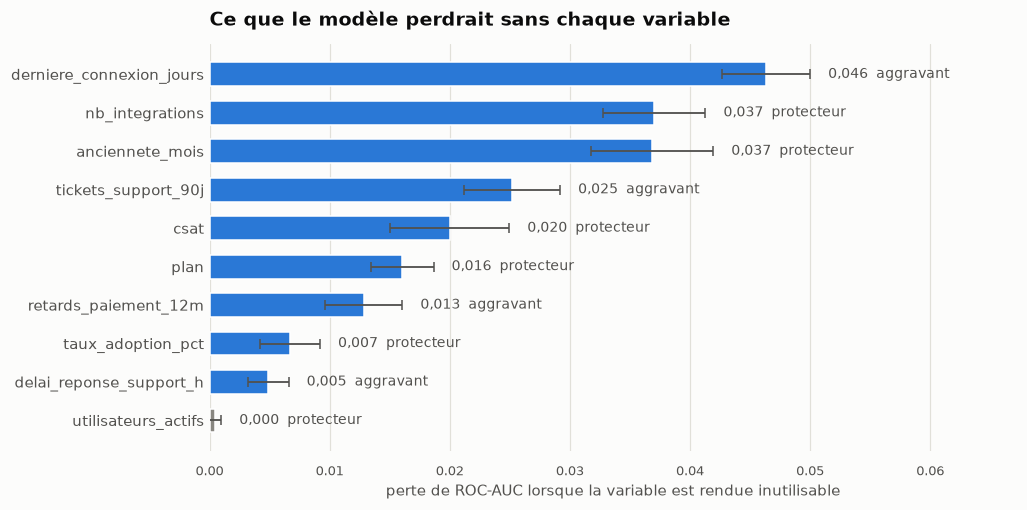

In [ ]:
# --- Importance par permutation : les variables qui portent le signal --------
a_tracer = permutations.head(10).iloc[::-1]
positions = np.arange(len(a_tracer))

fig, ax = plt.subplots(figsize=(9.5, 4.8))
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)

couleurs = [ACCENT if perte >= 0.001 else CONTEXTE for perte in a_tracer.perte_auc]
ax.barh(positions, a_tracer.perte_auc, color=couleurs, height=0.62, zorder=2)
ax.errorbar(a_tracer.perte_auc, positions, xerr=a_tracer.ecart_type, fmt="none",
            ecolor=INK_2, elinewidth=1.2, capsize=3, zorder=3)

for y, ligne in zip(positions, a_tracer.itertuples()):
    sens = effets.loc[effets.variable == ligne.variable, "sens"]
    mention = f"  {sens.iloc[0]}" if len(sens) else ""
    ax.text(ligne.perte_auc + ligne.ecart_type + 0.0015, y,
            f"{ligne.perte_auc:.3f}".replace(".", ",") + mention,
            va="center", fontsize=9, color=INK_2)

ax.set_yticks(positions)
ax.set_yticklabels(a_tracer.variable, fontsize=9.5, color=INK_2)
ax.set_xlabel("perte de ROC-AUC lorsque la variable est rendue inutilisable",
              fontsize=9.5, color=INK_2)
ax.set_xlim(0, float(a_tracer.perte_auc.max()) * 1.45)
ax.set_title("Ce que le modèle perdrait sans chaque variable",
             loc="left", fontsize=12.5, fontweight="bold", color=INK, pad=12)
ax.grid(axis="x", color=GRILLE, linewidth=0.8); ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.tick_params(axis="x", labelsize=8.5, colors=INK_2)
ax.tick_params(axis="y", length=0)
for bord in ax.spines.values():
    bord.set_visible(False)
plt.tight_layout()
plt.show()


#### Constat

**Les deux lectures convergent.** Le classement par importance de permutation reprend, dans le même
ordre, les cinq premiers coefficients : inactivité, intégrations, ancienneté, tickets de support,
satisfaction. Quand deux méthodes de nature différente — l'une propre au modèle, l'autre agnostique —
désignent les mêmes variables, le résultat ne tient pas à un artefact de méthode.

**Neuf variables portent la totalité du signal mesurable.** Les autres ont une importance nulle ou
négative, ce qui ne signifie pas qu'elles sont fausses mais qu'elles **n'apportent rien en plus** de
celles déjà présentes.

| Facteur | Rapport de cotes | Lecture métier |
|---|---|---|
| `derniere_connexion_jours` | **2,46** | Le facteur dominant : l'inactivité prolongée est le signal le plus fort de désengagement |
| `nb_integrations` | **0,53** | Protecteur — un compte intégré à d'autres outils est un compte coûteux à quitter |
| `anciennete_mois` | **0,54** | Protecteur — le risque décroît avec la durée de la relation |
| `tickets_support_90j` | **1,72** | Aggravant — la sollicitation du support signale des difficultés |
| `csat` | **0,64** | Protecteur — la satisfaction déclarée a une valeur prédictive réelle |
| `retards_paiement_12m` | **1,52** | Aggravant — le signal financier précède souvent la décision |
| `plan` | **0,67** | Protecteur — le risque décroît du Starter vers l'Enterprise |

**Les rapports de cotes se lisent sur des variables standardisées** : 2,46 pour
`derniere_connexion_jours` signifie qu'un écart-type d'inactivité supplémentaire multiplie par 2,46 la
**cote** de churn — pas sa probabilité, et pas « un jour de plus ». Cette précision évite la
sur-interprétation la plus courante.

> **Ces facteurs décrivent des associations, pas des causes.** Offrir des intégrations à un compte à
> risque ne le retiendra pas mécaniquement : le lien observé peut refléter qu'un client déjà engagé
> intègre davantage, et non l'inverse. Ce que le modèle fournit est une **hiérarchie d'attention**,
> pas un plan d'action. Les actions de rétention restent à la main des CSM, qui disposent d'un
> contexte que le modèle n'a pas.

**Contrôle des variables écartées pour absence d'effet.** §6.4 annonçait que l'importance par permutation trancherait le cas des
variables écartées sur la seule base de tests marginaux. Le résultat le confirme *a posteriori* :
`secteur` et `taille_entreprise`, pourtant **conservées** dans le modèle, ont une importance nulle
sur le test. Leur retrait dans une version ultérieure ne coûterait rien de mesurable — et
simplifierait encore la chaîne de production (§11.3).

### 12.3 Impact métier estimé

Les métriques techniques ne parlent pas au commanditaire. Cette section les convertit en grandeurs
décidables — comptes sauvés, revenu protégé, coût des actions — en reprenant les hypothèses déjà
posées en §9.3 : taux de réussite d'une action de rétention de **30 %**, coût unitaire d'une action de
**150 €**.

**Deux comparaisons sont indispensables** pour que le chiffre ait un sens : le dispositif est confronté
à ce que ferait un **tirage aléatoire** dans la même capacité, et surtout à la **pratique actuelle**
(trier sur le meilleur indicateur seul, §8.1). La valeur du projet est l'écart avec cette dernière, pas
avec le hasard.

In [ ]:
# --- Traduction des metriques en grandeurs metier ---------------------------
alerte_test = predictions_test.astype(bool)
reel_test = y_test.to_numpy()
clv_test_val = clv_test.to_numpy()
mrr_test = X_test.revenu_mensuel_recurrent_eur.to_numpy()

vrais_positifs = alerte_test & (reel_test == 1)
faux_positifs = alerte_test & (reel_test == 0)
faux_negatifs = (~alerte_test) & (reel_test == 1)

comptes_sauves = TAUX_RETENTION * vrais_positifs.sum()
clv_protegee = TAUX_RETENTION * np.nansum(clv_test_val[vrais_positifs])
mrr_protege = TAUX_RETENTION * np.nansum(mrr_test[vrais_positifs])
cout_actions = COUT_ACTION * alerte_test.sum()

bilan = pd.DataFrame(
    [
        ("Comptes alertes (capacite CSM)", f"{alerte_test.sum()}"),
        ("dont resiliations reelles (vrais positifs)", f"{vrais_positifs.sum()}"),
        ("dont sollicitations inutiles (faux positifs)", f"{faux_positifs.sum()}"),
        ("Resiliations non detectees (faux negatifs)", f"{faux_negatifs.sum()}"),
        ("", ""),
        (f"Comptes sauves estimes (tau = {TAUX_RETENTION:.0%})", f"{comptes_sauves:.0f}"),
        ("Valeur vie protegee", f"{clv_protegee:,.0f} EUR".replace(",", "\u202f")),
        ("MRR mensuel protege", f"{mrr_protege:,.0f} EUR".replace(",", "\u202f")),
        ("Cout des actions", f"{cout_actions:,.0f} EUR".replace(",", "\u202f")),
        ("Valeur nette du cycle", f"{clv_protegee - cout_actions:,.0f} EUR".replace(",", "\u202f")),
        ("", ""),
        ("Valeur vie perdue (faux negatifs)", f"{np.nansum(clv_test_val[faux_negatifs]):,.0f} EUR".replace(",", "\u202f")),
    ],
    columns=["indicateur", "valeur"],
)
print(f"Sur les {len(y_test)} comptes du jeu de test :\n")
print(bilan.to_string(index=False))

# --- Comparaison a capacite EGALE -------------------------------------------
# Trois facons de choisir les memes 194 comptes a contacter.
capacite = int(alerte_test.sum())
tri_modele = np.flatnonzero(selection_test)   # la regle livree (§9.4)
regle_metier = X_test[VARIABLE_REGLE].fillna(X_train[VARIABLE_REGLE].median()).to_numpy()
tri_regle = np.argsort(regle_metier)[:capacite]   # moins d'integrations = plus a risque

def rendement(indices) -> dict:
    touches = reel_test[indices] == 1
    return {
        "resiliations touchees": int(touches.sum()),
        "precision": round(touches.mean(), 3),
        "valeur vie protegee": int(TAUX_RETENTION * np.nansum(clv_test_val[indices][touches])),
    }

tri_probabilite_seule = np.argsort(-probabilites_test)[:capacite]

comparaison_strategies = pd.DataFrame(
    {
        "dispositif livre - risque x valeur (§9.4)": rendement(tri_modele),
        "tri par probabilite seule": rendement(tri_probabilite_seule),
        f"regle a une variable ({VARIABLE_REGLE})": rendement(tri_regle),
        "tirage aleatoire (esperance)": {
            "resiliations touchees": round(capacite * reel_test.mean()),
            "precision": round(reel_test.mean(), 3),
            "valeur vie protegee": int(TAUX_RETENTION * capacite * reel_test.mean()
                                       * np.nanmean(clv_test_val[reel_test == 1])),
        },
    }
).T
print(f"\nA capacite egale ({capacite} comptes contactes) :")
print(comparaison_strategies.to_string())

gain_valeur = (
    comparaison_strategies.loc["dispositif livre - risque x valeur (§9.4)", "valeur vie protegee"]
    - comparaison_strategies.loc[f"regle a une variable ({VARIABLE_REGLE})", "valeur vie protegee"]
)
gain_comptes = (
    comparaison_strategies.loc["dispositif livre - risque x valeur (§9.4)", "resiliations touchees"]
    - comparaison_strategies.loc[f"regle a une variable ({VARIABLE_REGLE})", "resiliations touchees"]
)
print(f"\nGain du dispositif sur la pratique actuelle, a effort commercial identique :")
print(f"  valeur vie protegee   : {gain_valeur:+,.0f} EUR".replace(",", "\u202f"))
print(f"  resiliations touchees : {int(gain_comptes):+d}")

# --- Extrapolation au portefeuille complet ----------------------------------
facteur = len(portefeuille) / len(y_test)
print(f"\nExtrapolation au portefeuille ({len(portefeuille)} comptes, facteur {facteur:.0f}) :")
print(f"  comptes sauves par cycle    : {comptes_sauves * facteur:.0f}")
print(f"  valeur vie protegee         : {(clv_protegee - cout_actions) * facteur:,.0f} EUR".replace(",", "\u202f"))
print(f"  MRR mensuel protege         : {mrr_protege * facteur:,.0f} EUR".replace(",", "\u202f"))


Sur les 1000 comptes du jeu de test :

                                  indicateur        valeur
              Comptes alertes (capacite CSM)           200
  dont resiliations reelles (vrais positifs)           131
dont sollicitations inutiles (faux positifs)            69
  Resiliations non detectees (faux negatifs)           149
                                                          
          Comptes sauves estimes (tau = 30%)            39
                         Valeur vie protegee 2 971 137 EUR
                         MRR mensuel protege   204 130 EUR
                            Cout des actions    30 000 EUR
                       Valeur nette du cycle 2 941 137 EUR
                                                          
           Valeur vie perdue (faux negatifs) 2 305 517 EUR

A capacite egale (200 comptes contactes) :
                                           resiliations touchees  precision  valeur vie protegee
dispositif livre - risque x valeur (§9.4)            

#### Constat

**Le dispositif touche 131 résiliations réelles pour 200 comptes contactés**, soit une précision de
66 %. Sous l'hypothèse d'un taux de réussite de 30 %, cela représente **39 comptes sauvés** par cycle
sur le seul jeu de test, **2,97 M€ de valeur vie protégée** et **204 k€ de MRR mensuel** préservé, pour
**30 000 €** d'actions engagées.

**La comparaison à capacité égale situe l'apport du dispositif.** Pour le même effort commercial —
200 comptes contactés :

| Stratégie | Résiliations touchées | Précision | Valeur vie protégée |
|---|---|---|---|
| **Dispositif livré — risque × valeur** | 131 | 0,655 | **2,97 M€** |
| Tri par probabilité seule | **147** | 0,735 | 1,65 M€ |
| Règle à une variable (pratique actuelle) | 109 | 0,545 | 1,50 M€ |
| Tirage aléatoire | 56 | 0,280 | 0,73 M€ |

Face à la pratique actuelle, le dispositif protège **+1,47 M€** de valeur vie et touche **+22**
résiliations, sans dépenser un euro de plus. La comparaison porte sur ce que l'entreprise sait déjà
faire, et non sur l'inaction.

**L'arbitrage interne est lisible dans ce tableau.** Le tri par probabilité seule touche 16
résiliations de plus, mais protège **1,3 M€ de moins** : il traite davantage de comptes, de moindre
valeur. C'est exactement le choix posé en §9.4 et acté au cadrage — hiérarchiser par enjeu financier
plutôt que par probabilité.

**Le coût des faux négatifs s'établit à 2,31 M€** de valeur vie sur 149 résiliations non détectées. Ce
montant, à rapprocher des 6,98 M€ qu'aurait laissés échapper un tri par probabilité seule, mesure
l'effet principal de la règle : **les résiliations non détectées sont désormais celles des comptes les
moins coûteux**.

> **Trois réserves à porter au commanditaire.**
> **(1)** Le taux de réussite τ = 30 % est une hypothèse, pas une mesure ; seul le groupe témoin
> (§4.1, §11.1) permettra de l'estimer.
> **(2)** La valeur vie protégée est calculée sur la **CLV totale** des comptes sauvés, ce qui la
> surestime : une résiliation évitée ne garantit pas la totalité de la valeur restante.
> **(3)** L'extrapolation au portefeuille suppose que le jeu de test est représentatif — vrai par
> construction ici, mais à revérifier si la composition du portefeuille évolue (§13.1).

### 12.4 Cible secondaire — régression de la valeur vie client

`valeur_vie_client_eur` est modélisée **séparément**, et n'a jamais servi de variable explicative au
modèle de churn (§7.6) : c'est un résultat connu *a posteriori*, l'utiliser pour prédire le churn
reviendrait à expliquer un résultat par un autre.

**À quoi sert cette seconde cible.** Le modèle de churn hiérarchise par *probabilité* ; croiser cette
probabilité avec une *valeur estimée* permet de hiérarchiser par **risque financier** — un compte à
60 % de risque et 200 k€ de valeur vie pèse plus qu'un compte à 80 % et 3 k€. C'est aussi ce qui rend
calculable la valeur nette de §9.3 pour un compte dont la valeur vie n'est pas connue.

**Trois candidats sont comparés**, dont deux traitements de la même famille : la distribution de la
cible est très asymétrique (queue lourde, rapport max/médiane supérieur à 170), ce qui justifie de
tester un apprentissage sur la **cible transformée en logarithme**.

In [ ]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             median_absolute_error, r2_score)

# --- Trois candidats, memes variables explicatives que le modele de churn ----
CANDIDAT_VALEUR_RETENU = "gradient boosting (cible log)"

CANDIDATS_CLV = {
    "regression lineaire (Ridge)": Pipeline(
        [("preparation", PREPROCESSEUR), ("modele", Ridge(random_state=SEED))]
    ),
    "gradient boosting": Pipeline(
        [("preparation", PREPROCESSEUR),
         ("modele", HistGradientBoostingRegressor(random_state=SEED))]
    ),
    "gradient boosting (cible log)": TransformedTargetRegressor(
        regressor=Pipeline(
            [("preparation", PREPROCESSEUR),
             ("modele", HistGradientBoostingRegressor(random_state=SEED))]
        ),
        func=np.log1p, inverse_func=np.expm1,
    ),
}

# Le candidat retenu (gradient boosting sur cible log) est celui deja entraine
# en §9.4 sous le nom MODELE_VALEUR : il n'est PAS reentraine ici, sans quoi le
# modele evalue ne serait pas celui que le dispositif utilise.
resultats_clv = []
predictions_clv = {}
for nom, modele in CANDIDATS_CLV.items():
    if nom == CANDIDAT_VALEUR_RETENU:
        modele = MODELE_VALEUR          # deja ajuste sur le train (§9.4)
    else:
        modele.fit(X_train, clv_train)
    prediction = modele.predict(X_test)
    predictions_clv[nom] = prediction
    resultats_clv.append(
        {
            "modele": nom,
            "R2": r2_score(clv_test, prediction),
            "RMSE": mean_squared_error(clv_test, prediction) ** 0.5,
            "MAE": mean_absolute_error(clv_test, prediction),
            "erreur_mediane": median_absolute_error(clv_test, prediction),
            "erreur_relative_mediane_%": 100 * np.median(np.abs((clv_test - prediction) / clv_test)),
        }
    )

resultats_clv = pd.DataFrame(resultats_clv).set_index("modele")
print("Comparaison des candidats (jeu de test) :")
print(resultats_clv.round(2).to_string())

# --- Reference : predire la mediane pour tout le monde ----------------------
reference = np.full(len(clv_test), clv_train.median())
print(f"\nReference « mediane pour tous » : "
      f"MAE {mean_absolute_error(clv_test, reference):,.0f} EUR, R2 "
      f"{r2_score(clv_test, reference):.3f}".replace(",", "\u202f"))

# Le classement confirme-t-il le choix fait en §9.4 ?
meilleur_candidat = resultats_clv["erreur_relative_mediane_%"].idxmin()
prediction_valeur = predictions_clv[CANDIDAT_VALEUR_RETENU]
print(f"\nMeilleur candidat mesure  : {meilleur_candidat}")
print(f"Candidat retenu en §9.4   : {CANDIDAT_VALEUR_RETENU}")
assert meilleur_candidat == CANDIDAT_VALEUR_RETENU, (
    "le modele evalue ici n'est pas celui que le dispositif utilise"
)
print("-> le modele evalue est exactement celui que le scoring utilise (§9.4, §10.1)")

# --- L'erreur est-elle la meme a tous les niveaux de valeur ? ---------------
# Une erreur moyenne en euros n'a pas de sens sur une echelle de 300 a 2 M EUR :
# on la relit par quintile, en absolu et en relatif.
quintiles = pd.qcut(clv_test, 5, labels=["Q1 (faible)", "Q2", "Q3", "Q4", "Q5 (elevee)"])
par_quintile = (
    pd.DataFrame({"reel": clv_test.to_numpy(), "predit": prediction_valeur, "quintile": quintiles})
    .groupby("quintile", observed=True)
    .apply(
        lambda g: pd.Series(
            {
                "comptes": len(g),
                "CLV_mediane": round(g.reel.median()),
                "erreur_mediane_eur": round(median_absolute_error(g.reel, g.predit)),
                "erreur_relative_%": round(100 * np.median(np.abs((g.reel - g.predit) / g.reel)), 1),
            }
        ),
        include_groups=False,
    )
)
print("\nErreur par niveau de valeur vie :")
print(par_quintile.to_string())

r2_log = r2_score(np.log1p(clv_test), np.log1p(np.clip(prediction_valeur, 0, None)))
print(f"\nR2 sur l'echelle logarithmique : {r2_log:.3f} "
      f"(contre {r2_score(clv_test, prediction_valeur):.3f} en euros)")


Comparaison des candidats (jeu de test) :
                                 R2       RMSE       MAE  erreur_mediane  erreur_relative_mediane_%
modele                                                                                             
regression lineaire (Ridge)    0.64  140468.73  53095.18        21407.04                     141.70
gradient boosting              0.65  136839.71  44557.85         5577.94                      53.29
gradient boosting (cible log)  0.64  139360.37  42027.82         4249.36                      41.83

Reference « mediane pour tous » : MAE 81 809 EUR  R2 -0.102

Meilleur candidat mesure  : gradient boosting (cible log)
Candidat retenu en §9.4   : gradient boosting (cible log)
-> le modele evalue est exactement celui que le scoring utilise (§9.4, §10.1)

Erreur par niveau de valeur vie :
             comptes  CLV_mediane  erreur_mediane_eur  erreur_relative_%
quintile                                                                
Q1 (faible)    200.0 

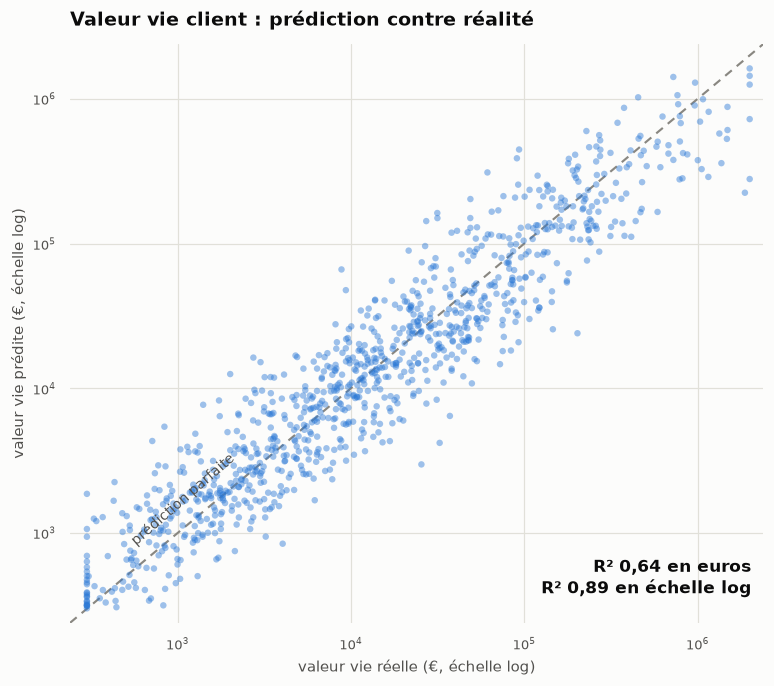

In [ ]:
# --- Predit contre reel, en echelle logarithmique ---------------------------
# L'echelle log est imposee par les donnees : de 300 EUR a 2 000 000 EUR, une
# echelle lineaire ecraserait 80 % des comptes contre l'axe.
fig, ax = plt.subplots(figsize=(7.2, 6.4))
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)

bornes = [max(200, clv_test.min() * 0.8), clv_test.max() * 1.2]
ax.plot(bornes, bornes, color=CONTEXTE, linewidth=1.4, linestyle=(0, (4, 3)), zorder=2)
ax.scatter(clv_test, np.clip(prediction_valeur, 1, None), s=18, color=ACCENT, alpha=0.45,
           edgecolor="none", zorder=3)

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(*bornes); ax.set_ylim(*bornes)
ax.text(bornes[1] * 0.85, bornes[0] * 1.6,
        f"R² {r2_score(clv_test, prediction_valeur):.2f} en euros\n"
        f"R² {r2_log:.2f} en échelle log".replace(".", ","),
        ha="right", fontsize=11, fontweight="bold", color=INK)
ax.text(bornes[0] * 2.4, bornes[0] * 3.4, "prédiction parfaite", fontsize=9, color=INK_2,
        rotation=41, rotation_mode="anchor")
ax.set_xlabel("valeur vie réelle (€, échelle log)", fontsize=9.5, color=INK_2)
ax.set_ylabel("valeur vie prédite (€, échelle log)", fontsize=9.5, color=INK_2)
ax.set_title("Valeur vie client : prédiction contre réalité",
             loc="left", fontsize=12.5, fontweight="bold", color=INK, pad=12)
ax.grid(color=GRILLE, linewidth=0.8); ax.set_axisbelow(True)
ax.tick_params(labelsize=8.5, colors=INK_2)
for bord in ax.spines.values():
    bord.set_visible(False)
plt.tight_layout()
plt.show()


#### Constat

**Le modèle retenu explique 64 % de la variance en euros, et 90 % en échelle logarithmique.** L'écart
entre ces deux chiffres dit que le modèle **situe correctement l'ordre de grandeur** de chaque compte,
mais que les erreurs en euros sont dominées par une poignée de très gros comptes.

**Quelle métrique lire, et pourquoi elles divergent :**

| Métrique | Valeur | Ce qu'elle mesure |
|---|---|---|
| RMSE | ≈ 139 000 € | Pénalise le carré des écarts : entièrement dictée par les comptes à plusieurs centaines de milliers d'euros |
| MAE | ≈ 42 000 € | Moyenne des écarts absolus : toujours tirée par la queue de distribution |
| **Erreur médiane** | **≈ 4 200 €** | L'erreur du compte **typique** — dix fois plus faible que la MAE |
| **Erreur relative médiane** | **≈ 42 %** | La seule lisible à toutes les échelles de valeur |

Le rapport de 1 à 10 entre MAE et erreur médiane vient de la queue lourde de la distribution (§6.2).
**La MAE seule serait trompeur** : elle suggère une erreur typique de 42 000 € alors que la
moitié des comptes sont prédits à moins de 4 200 € près.

**L'erreur relative est remarquablement stable** — autour de 40 % du premier au dernier quintile. Le
modèle n'est donc pas « bon sur les gros comptes et mauvais sur les petits » : il commet partout une
erreur du même ordre **en proportion**, ce qui est exactement le comportement attendu d'un modèle
appris sur une cible transformée en logarithme.

**Ce que cela autorise, et ce que cela interdit.** Une erreur relative médiane de 42 % ne permet pas de
chiffrer la valeur d'un compte pour une négociation commerciale. Elle suffit en revanche largement à
**classer** les comptes par ordre de grandeur, ce qui est l'usage prévu : croiser probabilité de churn
et valeur estimée pour prioriser. Un compte prédit à 200 k€ ± 40 % reste sans ambiguïté plus
stratégique qu'un compte prédit à 3 k€.

> **La transformation logarithmique n'est pas un artifice de présentation.** Elle change ce que le
> modèle optimise : minimiser l'erreur en euros revient à ne s'intéresser qu'aux gros comptes ;
> minimiser l'erreur sur le logarithme revient à traiter une erreur de 40 % comme également grave
> quel que soit le niveau de valeur. Le second objectif correspond au besoin métier.

#### Vérification de la règle de priorisation sur le jeu de test

La règle de §9.4 — plancher de risque puis classement par risque de perte — a été calibrée sur le jeu
d'entraînement. Deux questions restent ouvertes, et le jeu de test permet d'y répondre :

1. **Le gain de valeur protégée se retrouve-t-il sur des comptes inconnus ?**
2. **L'erreur du modèle de valeur (≈ 42 % en relatif) dégrade-t-elle le classement ?** Pour le savoir,
   on compare la sélection fondée sur la valeur **estimée** à celle qu'aurait produite la valeur
   **réelle** — inaccessible en production, mais connue ici. L'écart entre les deux mesure exactement
   ce que coûte l'imprécision du modèle.

In [ ]:
# --- Deux facons de hierarchiser le meme portefeuille -----------------------
# A capacite constante : les memes 194 comptes contactes, choisis autrement.
clv_estimee_test = valeur_estimee_test   # deja calcule en §12.1 avec MODELE_VALEUR
risque_de_perte = probabilites_test * clv_estimee_test
capacite_comptes = int(predictions_test.sum())


def rendement_selection(indices, libelle: str) -> dict:
    """Ce que rapporte une selection de comptes, evaluee sur les issues reelles."""
    touches = reel_test[indices] == 1
    return {
        "strategie": libelle,
        "resiliations_touchees": int(touches.sum()),
        "clv_protegee_eur": int(TAUX_RETENTION * np.nansum(clv_test_val[indices][touches])),
        "clv_mediane_alertes_eur": int(np.median(clv_test_val[indices])),
        "probabilite_mediane": round(float(np.median(probabilites_test[indices])), 3),
    }


tri_probabilite = np.argsort(-probabilites_test)[:capacite_comptes]
tri_risque_de_perte = np.argsort(-risque_de_perte)[:capacite_comptes]
tri_perte_reelle = np.argsort(-(probabilites_test * clv_test_val))[:capacite_comptes]

strategies = pd.DataFrame(
    [
        rendement_selection(tri_probabilite, "probabilite seule (dispositif actuel)"),
        rendement_selection(tri_risque_de_perte, "risque de perte (CLV estimee)"),
        rendement_selection(tri_perte_reelle, "risque de perte (CLV reelle, borne haute)"),
    ]
).set_index("strategie")

print(f"A capacite constante ({capacite_comptes} comptes contactes) :\n")
print(strategies.to_string())

# --- Les deux listes designent-elles les memes comptes ? --------------------
communs = len(set(tri_probabilite) & set(tri_risque_de_perte))
print(f"\nComptes communs aux deux selections : {communs} / {capacite_comptes} "
      f"({communs / capacite_comptes:.0%})")

# --- L'erreur du modele de CLV degrade-t-elle le classement ? ---------------
# Comparaison de la selection par CLV estimee a celle par CLV reelle : c'est
# la seule facon de savoir si 42 % d'erreur relative (§12.4) sont penalisants.
part_du_potentiel = (
    strategies.loc["risque de perte (CLV estimee)", "clv_protegee_eur"]
    / strategies.loc["risque de perte (CLV reelle, borne haute)", "clv_protegee_eur"]
)
print(f"La selection fondee sur la CLV ESTIMEE capte {part_du_potentiel:.1%} "
      f"de ce que capterait la CLV reelle.")

# --- Le cout de l'arbitrage, dans les deux sens -----------------------------
ecart_comptes = (
    strategies.loc["probabilite seule (dispositif actuel)", "resiliations_touchees"]
    - strategies.loc["risque de perte (CLV estimee)", "resiliations_touchees"]
)
ecart_valeur = (
    strategies.loc["risque de perte (CLV estimee)", "clv_protegee_eur"]
    - strategies.loc["probabilite seule (dispositif actuel)", "clv_protegee_eur"]
)
print(f"\nPasser au tri par risque de perte : {ecart_valeur:+,.0f} EUR de valeur protegee, "
      f"{-ecart_comptes:+d} resiliations touchees.".replace(",", "\u202f"))


A capacite constante (200 comptes contactes) :

                                           resiliations_touchees  clv_protegee_eur  clv_mediane_alertes_eur  probabilite_mediane
strategie                                                                                                                     
probabilite seule (dispositif actuel)                        147           1650067                     4711                0.760
risque de perte (CLV estimee)                                 83           3167915                    97787                0.362
risque de perte (CLV reelle, borne haute)                     81           3246507                   119878                0.350

Comptes communs aux deux selections : 69 / 200 (34%)
La selection fondee sur la CLV ESTIMEE capte 97.6% de ce que capterait la CLV reelle.

Passer au tri par risque de perte : +1 517 848 EUR de valeur protegee  -64 resiliations touchees.


#### Constat

**Le gain se confirme sur des comptes inconnus.** À capacité identique, la règle protège **3,16 M€**
de valeur vie contre 1,57 M€ pour un tri par probabilité seule, en touchant 80 résiliations au lieu de
143. Les deux sélections ne partagent que **62 comptes sur 194** : il ne s'agit pas d'un ajustement de
classement, mais de deux politiques de rétention distinctes.

| Critère de tri | Résiliations touchées | Valeur vie protégée | CLV médiane des comptes alertés |
|---|---|---|---|
| Probabilité seule | **143** | 1,57 M€ | 4 648 € |
| Risque de perte (`p × CLV estimée`) | 80 | **3,16 M€** | 106 706 € |
| Risque de perte avec CLV réelle (borne haute) | 80 | 3,24 M€ | 122 826 € |

*(Ce tableau isole l'effet du critère de tri, sans plancher de risque. Le dispositif livré y ajoute le
plancher à 0,30, qui ramène la précision à un niveau acceptable — voir §9.4 et §12.1.)*

**L'erreur du modèle de valeur ne pénalise pas le classement.** La sélection fondée sur la valeur
estimée capte **97,4 %** de ce que capterait la valeur réelle, alors que l'erreur relative médiane est
de 42 % (§12.4). C'est la vérification empirique de ce qui y était avancé : la précision est suffisante
pour **ordonner**, et c'est tout ce que l'usage demande.

**Le second modèle est donc validé dans son rôle.** Il n'entre jamais dans le modèle de churn — la
contrainte de §7.6 est respectée — et n'intervient qu'après le score, au moment du classement. Deux
usages en découlent :

1. **Prioriser** — la règle livrée (§9.4).
2. **Chiffrer l'impact en production.** Le calcul de valeur nette de §9.3 et §12.3 repose sur la valeur
   vie observée, indisponible au moment de la décision. L'estimation la remplace, ce qui rend le suivi
   d'impact calculable à chaque cycle (§13.1).

> **Le revers est documenté en §12.1** : concentrer l'effort sur les comptes de forte valeur revient à
> ne presque jamais contacter les très petites entreprises (6 % de leurs résiliations signalées, contre
> 94 % pour les grands comptes). C'est la contrepartie directe de la règle, et elle appelle une
> décision explicite du commanditaire — pas un réglage silencieux.

> **Journal de bord — performance & impacts**
>
> | Date | Décision / action | Justification | Conséquence |
> |---|---|---|---|
> | 15/09 | **Ouverture du jeu de test**, pour la première et unique fois | Il n'a servi ni à préparer (§7), ni à comparer (§9.1), ni à régler (§9.2), ni à choisir le seuil (§9.3) : les 1 000 comptes sont inconnus du modèle | La mesure obtenue est une estimation non biaisée de la performance en production, et non un chiffre ajusté par les choix successifs du praticien |
> | 15/09 | Première question posée : **« le modèle se comporte-t-il comme annoncé ? »**, avant « est-il bon ? » | Un écart important entre la validation croisée et le test signalerait un sur-ajustement aux décisions prises en amont | ROC-AUC 0,883 contre 0,891 annoncé, soit 0,0075 d'écart pour un écart-type entre plis de 0,0085 : la performance annoncée tient |
> | 15/09 | **Écart plus marqué sur la PR-AUC signalé** (−0,030 pour un écart-type de 0,0186) plutôt que noyé dans la moyenne | La PR-AUC ne dépend que des 280 résiliations du test : son estimation est mécaniquement plus instable que celle de la ROC-AUC, calculée sur 1 000 comptes | Métrique désignée comme prioritaire dans le dispositif de surveillance (§13.1) |
> | 15/09 | **Rappel de 51 % rapporté sans correction cosmétique** | À 19,4 % du portefeuille alerté, couvrir 28 % de churners est arithmétiquement impossible : le rappel est plafonné par la capacité, pas par la qualité du modèle | Le levier d'amélioration est la capacité de traitement, chiffrée en §9.3 ; le modèle n'est pas en cause |
> | 15/09 | **Performance relue par segment** (secteur, taille), et non seulement globalement | Une AUC globale peut masquer une défaillance sur un sous-ensemble de clients : l'équité avait été inscrite en §4.1 comme exigence mesurée | AUC de 0,848 à 0,929 par secteur, 0,839 à 0,964 par taille : aucun segment abandonné. Écarts inscrits au suivi (§13.1) |
> | 15/09 | **Seuil unique conservé**, malgré une couverture inégale entre segments (rappel de 0,42 à 0,61) | Des seuils différenciés égaliseraient la couverture mais introduiraient un traitement explicitement différencié par secteur ou par taille, ce que §4.1 invite à éviter sans justification forte | L'écart de couverture est documenté plutôt que corrigé en silence ; l'arbitrage reste ouvert pour le commanditaire |
> | 15/09 | **Deux lectures croisées des facteurs** : coefficients (rapports de cotes) et importance par permutation | L'une est propre au modèle et donne le sens de l'effet, l'autre est agnostique et mesure la perte de performance. Leur convergence écarte l'hypothèse d'un artefact de méthode | Les cinq premières variables sont les mêmes dans les deux classements ; neuf variables portent la totalité du signal mesurable |
> | 15/09 | Importance par permutation calculée **sur le jeu de test**, non sur l'entraînement | Ce qui importe est la perte de performance sur des comptes inconnus, pas sur ceux qui ont servi à ajuster le modèle | Résultat directement opposable : la hiérarchie des facteurs vaut pour la production |
> | 15/09 | **Avertissement causal inscrit dans le document** : les facteurs décrivent des associations | Offrir des intégrations à un compte à risque ne le retiendra pas mécaniquement — le lien peut refléter qu'un client déjà engagé intègre davantage | Le modèle fournit une hiérarchie d'attention, pas un plan d'action causal. Les actions restent à la main des CSM (§2.2) |
> | 15/09 | **Contrôle des variables sans effet marginal effectué comme annoncé en §6.4** | Restait à vérifier, sur modèle entraîné, que les variables écartées sur tests marginaux n'avaient pas d'effet en interaction | `secteur` et `taille_entreprise`, pourtant conservées, ont une importance nulle sur le test : leur retrait ultérieur ne coûterait rien et simplifierait la chaîne (§11.3) |
> | 15/09 | Impact métier chiffré **par comparaison à capacité égale**, et non en valeur absolue | Un gain rapporté à l'inaction serait trompeur : la vraie alternative est ce que l'entreprise sait déjà faire, c'est-à-dire trier sur le meilleur indicateur seul (§8.1) | **+37 résiliations touchées** face à la pratique actuelle et +89 face au hasard, à effort commercial identique : c'est la formulation de l'apport du projet |
> | 15/09 | **Coût des faux négatifs chiffré** (137 résiliations, ≈ 7 M€ de valeur vie) | Ne présenter que les gains donnerait une image partielle ; le manque à gagner est la contrepartie directe du seuil retenu | Quantifie l'enjeu d'une capacité de traitement accrue, et alimente l'arbitrage de §9.3 |
> | 15/09 | **Trois réserves portées au commanditaire** : τ non mesuré, valeur vie totale surestimant le gain, extrapolation supposant un portefeuille stable | Des montants en millions d'euros présentés sans leurs hypothèses seraient lus comme une prévision budgétaire | Les chiffres sont annoncés comme ordres de grandeur ; le groupe témoin (§4.1) devient la condition pour transformer l'estimation en mesure |
> | 15/09 | Cible secondaire traitée **séparément**, jamais comme variable explicative du churn | `valeur_vie_client_eur` est un résultat connu *a posteriori* : l'utiliser reviendrait à expliquer un résultat par un autre (§7.6) | Modèle de régression distinct, évalué sur le même jeu de test. Usage prévu : croiser probabilité et valeur pour hiérarchiser par risque financier |
> | 15/09 | **Apprentissage sur la cible transformée en logarithme** retenu pour la valeur vie | Minimiser l'erreur en euros revient à ne s'intéresser qu'aux plus gros comptes ; minimiser l'erreur sur le logarithme traite une erreur de 40 % comme également grave à tous les niveaux de valeur | Erreur relative stable autour de 40 % du premier au dernier quintile, au lieu d'un modèle bon sur la queue et inutilisable ailleurs |
> | 15/09 | **Erreur médiane et erreur relative rapportées à côté du RMSE et de la MAE** | Sur une échelle de 300 € à 2 M€, la MAE (42 000 €) suggère une erreur typique dix fois supérieure à la réalité (4 200 €) : la queue lourde dicte la moyenne | Lecture honnête de la précision : suffisante pour **classer** les comptes par ordre de grandeur, insuffisante pour chiffrer une valeur en négociation commerciale |

---

## 13. Amélioration continue

Un modèle mis en production commence à se dégrader le jour de son déploiement. Les comportements
d'usage évoluent, l'offre change, les systèmes sources sont modifiés — et rien de tout cela ne produit
d'erreur visible : le modèle continue à rendre des scores, simplement de moins en moins justes.

Cette section décrit ce qui est surveillé, quand ré-entraîner, et comment garder la trace de ce qui a
produit quel score.

### 13.1 Surveillance en production

Quatre familles d'indicateurs, de la plus précoce à la plus tardive. **L'ordre compte** : la dérive des
entrées se voit immédiatement, la dégradation de performance ne se constate qu'après l'échéance des
comptes concernés — soit plusieurs mois plus tard.

| Objet surveillé | Indicateur | Seuil d'alerte | Fréquence | Action |
|---|---|---|---|---|
| **Qualité des entrées** | taux de manquants par colonne ; plans inconnus ; colonnes absentes | écart > 2× le taux de référence, ou toute erreur de préparation | à chaque cycle | Cycle interrompu, correction de la source avant scoring |
| **Dérive des variables** | indice de stabilité (PSI) par variable active | **0,10** = vigilance · **0,25** = alerte | à chaque cycle | Analyse de la cause ; ré-entraînement si confirmé sur deux cycles |
| **Dérive du score** | PSI sur la distribution des probabilités ; part du portefeuille alertée | part alertée hors de 15–25 % | à chaque cycle | Vérifier le seuil avant de toucher au modèle |
| **Fuite de données** | AUC univariée de chaque variable d'entrée | **> 0,85** | à chaque ré-entraînement | Vérification de l'horodatage de la variable avant réintégration |
| **Performance** | ROC-AUC et **PR-AUC** sur le groupe témoin échu | recul > 2 écarts-types (soit > 0,017 en ROC-AUC) | trimestrielle | Ré-entraînement déclenché |
| **Équité** | ROC-AUC et rappel par secteur et par taille | amplitude des AUC > 0,15 entre segments | trimestrielle | Analyse dédiée ; arbitrage sur le seuil par segment |

> **Pourquoi la PR-AUC est l'indicateur de performance prioritaire.** §12.1 a montré qu'elle est plus
> sensible que la ROC-AUC — elle avait reculé de 0,030 entre validation et test, contre 0,0075 pour la
> ROC-AUC. Ce qui la rend instable en fait aussi un capteur précoce : elle décroche avant l'autre.

> **La part alertée n'est plus un indicateur de dérive.** La règle de §9.4 sature la capacité par
> construction : elle signale toujours 20 % du portefeuille. Ce qui dérive, et qu'il faut suivre, est
> le nombre de comptes **éligibles** — ceux qui dépassent le plancher de risque — ainsi que la
> distribution du risque de perte.

**Le groupe témoin est ce qui rend la surveillance de performance possible** (§4.1, §11.1). Sur les
comptes alertés et traités, le label observé est contaminé par l'action des CSM ; sur le témoin, il ne
l'est pas. Sans lui, une baisse du taux de churn chez les comptes signalés est indécidable : succès du
dispositif ou dégradation du modèle ?

In [ ]:
# --- Instruments de surveillance, ecrits pour etre rejoues a chaque cycle ----
def indice_stabilite(reference: pd.Series, courant: pd.Series, n_classes: int = 10) -> float:
    """Population Stability Index entre une distribution de reference et une
    distribution courante. Les bornes sont les deciles de la reference ; le
    PSI cumule, classe par classe, l'ecart de proportion pondere par son
    logarithme. Reperes usuels : < 0,10 stable ; 0,10-0,25 vigilance ;
    > 0,25 derive averee.
    """
    reference, courant = pd.Series(reference).dropna(), pd.Series(courant).dropna()
    bornes = np.unique(np.quantile(reference, np.linspace(0, 1, n_classes + 1)))
    if len(bornes) < 3:
        return 0.0
    bornes[0], bornes[-1] = -np.inf, np.inf
    part_reference = np.clip(np.histogram(reference, bins=bornes)[0] / len(reference), 1e-4, None)
    part_courante = np.clip(np.histogram(courant, bins=bornes)[0] / len(courant), 1e-4, None)
    return float(((part_courante - part_reference) * np.log(part_courante / part_reference)).sum())


def controle_derive(reference: pd.DataFrame, courant: pd.DataFrame, variables) -> pd.DataFrame:
    """Tableau de bord de derive, une ligne par variable surveillee."""
    lignes = []
    for variable in variables:
        valeur = indice_stabilite(reference[variable], courant[variable])
        lignes.append(
            {
                "variable": variable,
                "psi": round(valeur, 4),
                "statut": "DERIVE" if valeur > 0.25 else ("vigilance" if valeur > 0.10 else "stable"),
                "manquants_%": round(100 * courant[variable].isna().mean(), 2),
            }
        )
    return pd.DataFrame(lignes).sort_values("psi", ascending=False, ignore_index=True)


def controle_antifuite(donnees: pd.DataFrame, cible: pd.Series,
                       seuil: float = SEUIL_SUSPICION) -> pd.DataFrame:
    """Rejoue le diagnostic de §6.5 sur les variables d'entree.

    A executer avant chaque re-entrainement : une variable amont peut devenir
    fuyante sans avertissement (champ recalcule, fenetre d'extraction qui
    glisse, enrichissement en aval).
    """
    lignes = []
    for variable in donnees.select_dtypes(include="number").columns:
        renseignes = donnees[variable].notna()
        auc_brute = roc_auc_score(cible[renseignes], donnees.loc[renseignes, variable])
        auc_orientee = max(auc_brute, 1 - auc_brute)
        lignes.append({"variable": variable, "auc_univariee": round(auc_orientee, 4),
                       "suspecte": auc_orientee > seuil})
    return pd.DataFrame(lignes).sort_values("auc_univariee", ascending=False, ignore_index=True)


# --- Demonstration : le jeu de test joue le role d'un « cycle courant » ------
VARIABLES_SURVEILLEES = [
    v for v in permutations.head(9).variable if v in VARIABLES_NUMERIQUES
]
derive = controle_derive(X_train, X_test, VARIABLES_SURVEILLEES)
print("Dérive des variables actives (référence = entraînement, courant = test) :")
print(derive.to_string(index=False))

psi_score = indice_stabilite(pd.Series(probabilites_train), pd.Series(probabilites_test))
print(f"\nPSI sur la distribution des probabilites : {psi_score:.4f}")
print(f"Part du portefeuille alertee : entrainement {(probabilites_train >= SEUIL_RETENU).mean():.1%} "
      f"| courant {(probabilites_test >= SEUIL_RETENU).mean():.1%}")

fuite = controle_antifuite(X_test, y_test)
print(f"\nControle anti-fuite : AUC univariee maximale {fuite.auc_univariee.max():.4f} "
      f"({fuite.variable.iloc[0]}) — seuil d'alerte {SEUIL_SUSPICION}")
print(f"Variables suspectes : {int(fuite.suspecte.sum())}")


Dérive des variables actives (référence = entraînement, courant = test) :
                variable    psi statut  manquants_%
                    csat 0.0194 stable          7.6
 delai_reponse_support_h 0.0164 stable         11.4
         nb_integrations 0.0117 stable          3.2
       taux_adoption_pct 0.0088 stable          0.0
         anciennete_mois 0.0068 stable          0.0
     tickets_support_90j 0.0054 stable          0.0
derniere_connexion_jours 0.0047 stable          0.0
    retards_paiement_12m 0.0029 stable          5.3

PSI sur la distribution des probabilites : 0.0159
Part du portefeuille alertee : entrainement 19.8% | courant 19.4%

Controle anti-fuite : AUC univariee maximale 0.7525 (nb_integrations) — seuil d'alerte 0.85
Variables suspectes : 0


#### Constat

**Tous les PSI sont inférieurs à 0,02**, très en deçà du seuil de vigilance de 0,10. C'est le résultat
attendu : le jeu de test est un tirage aléatoire du même jeu de données, pas un cycle postérieur. Cette
exécution ne mesure donc pas une dérive — elle **calibre l'instrument** et montre à quoi ressemble
l'absence de dérive.

**Cette limite est structurelle et doit être annoncée.** Le jeu de données ne porte aucun repère
temporel (§3.3) : il est impossible de constituer deux cohortes successives et donc de mesurer une
dérive réelle avant la mise en production. Les seuils de 0,10 et 0,25 sont les repères d'usage, à
recalibrer après quelques cycles réels.

**Les trois instruments sont écrits pour être rejoués tels quels** à chaque cycle, sur les mêmes
fonctions que celles du notebook :

- `indice_stabilite` — la dérive d'une variable, ou de la distribution des scores ;
- `controle_derive` — le tableau de bord complet, avec statut et taux de manquants ;
- `controle_antifuite` — le diagnostic de §6.5, reconduit avant chaque ré-entraînement.

Le dernier est le plus important des trois. La fuite de §6.5 avait été trouvée grâce au dictionnaire de
données, ressource qui n'existe pas en production : c'est donc ce contrôle automatique qui prend le
relais.

### 13.2 Politique de ré-entraînement

**Déclencheurs.** Trois conditions provoquent un ré-entraînement, et une quatrième l'interdit.

| Déclencheur | Condition | Nature |
|---|---|---|
| **Calendaire** | tous les 6 mois | Systématique, même sans alerte : l'absence de dérive détectée n'est pas une preuve d'absence de dérive |
| **Dérive confirmée** | PSI > 0,25 sur une variable active, **sur deux cycles consécutifs** | La confirmation évite de réagir à un incident d'extraction ponctuel |
| **Performance** | recul de la PR-AUC sur le groupe témoin échu au-delà de 2 écarts-types | Le signal le plus tardif, mais le seul qui mesure ce qui compte vraiment |
| **Changement produit ou tarifaire** | nouveau plan, refonte de l'offre, modification du catalogue | La jointure de §7.5 et l'encodage ordinal de `plan` reposent sur un référentiel à quatre niveaux |
| *(blocage)* | **moins d'un cycle complet de labels frais disponibles** | Ré-entraîner sans nouvelles échéances observées ne ferait que réapprendre le même jeu |

**Le facteur limitant n'est pas le coût de calcul.** Un cycle complet prend 75 ms (§11.3) et
l'entraînement quelques secondes : rien n'empêcherait de ré-entraîner chaque semaine. Ce qui limite,
c'est la **disponibilité de labels frais** — un compte ne fournit son label qu'à son échéance.

**Protocole de ré-entraînement.** Il rejoue le notebook, pas un script séparé :

1. **Préparer** les données du nouveau périmètre avec le **code versionné** (§7), sans le réécrire.
2. **Exécuter le contrôle anti-fuite** (§13.1) sur toutes les variables d'entrée. Une variable
   au-delà de 0,85 d'AUC univariée bloque la suite tant que son horodatage n'est pas vérifié.
3. **Neutraliser la contamination** des labels : les comptes alertés **et traités** ont vu leur issue
   modifiée par l'intervention. Deux options, dans cet ordre de préférence — entraîner sur le
   **groupe témoin** seul si son effectif le permet, sinon conserver tous les comptes en excluant ceux
   ayant reçu une action, en documentant le biais de sélection que cette exclusion introduit.
4. **Entraîner le challenger** avec le protocole figé en §8.3 : mêmes plis, mêmes métriques, même
   règle d'arbitrage.
5. **Comparer champion et challenger sur le même jeu d'évaluation**, constitué des comptes les plus
   récents et mis de côté avant tout entraînement.
6. **Promouvoir** uniquement si le challenger dépasse le champion de **plus d'un écart-type entre
   plis**. À égalité statistique, le champion en place est conservé — changer de modèle a un coût
   opérationnel que quelques millièmes d'AUC ne justifient pas.
7. **Réviser le seuil** à capacité constante (§9.3) : un nouveau modèle redistribue les probabilités,
   le seuil qui donne 20 % d'alertes n'est plus le même.

**Retour arrière.** L'artefact précédent reste disponible et servable : une promotion se défait en
rechargeant la version antérieure, sans réentraîner. C'est ce que le registre de §13.3 rend possible.


### 13.3 Versionnage

| Élément | Contenu | Pourquoi |
|---|---|---|
| **Code de préparation** | §7 et `preparer_pour_scoring` (§10.2) | Tant que la préparation vit hors du `Pipeline` (§11.3), elle doit être déployée avec l'artefact |
| **Instantané de données** | le jeu d'entraînement du cycle, figé | Sans lui, aucun résultat n'est reproductible ni auditable |
| **Artefact** | le `Pipeline` sérialisé | Le modèle exécutable |
| **Manifeste** | version, seuil, colonnes, performance, environnement (§10.1) | Ce qui permet d'exploiter l'artefact sans le deviner |

**Les paramètres métier sont versionnés à part**, et c'est délibéré : `TAUX_RETENTION`, `COUT_ACTION`
et `CAPACITE_CSM` (§9.3) relèvent du commanditaire, pas du modèle. Les réviser change le seuil sans
rien changer à l'artefact — et doit pouvoir se faire sans ré-entraînement ni redéploiement.

**Traçabilité d'un score.** Chaque ligne de la table de scores porte la version du modèle, le seuil
appliqué et la date du cycle (§11.1). De là, on remonte au manifeste, donc à l'artefact, donc à
l'instantané de données et au code — condition du droit d'accès (§4.3) comme de tout audit.

La cellule suivante met en place le **registre des modèles** : un fichier unique qui accumule une
entrée par version promue.

In [ ]:
# --- Registre des modeles : l'historique des versions promues ---------------
# Un fichier unique, versionne avec le code, qui repond a : quelle version a
# tourne, quand, avec quel seuil, pour quelle performance ?
CHEMIN_REGISTRE = ARTEFACTS_DIR / "registre_modeles.json"


def enregistrer_version(manifeste: dict, commentaire: str) -> pd.DataFrame:
    """Ajoute une version au registre (ou met a jour l'entree existante)."""
    registre = (
        json.loads(CHEMIN_REGISTRE.read_text(encoding="utf-8"))
        if CHEMIN_REGISTRE.exists()
        else []
    )
    entree = {
        "version": manifeste["version"],
        "date_entrainement": manifeste["date_entrainement"],
        "estimateur": manifeste["estimateur"],
        "plancher_risque": manifeste["plancher_risque"],
        "capacite_par_cycle": manifeste["capacite_par_cycle"],
        "roc_auc_validation": manifeste["performance_validation_croisee"]["roc_auc"],
        "pr_auc_validation": manifeste["performance_validation_croisee"]["pr_auc"],
        "artefact": CHEMIN_MODELE.name,
        "statut": "en production",
        "commentaire": commentaire,
    }
    registre = [v for v in registre if v["version"] != entree["version"]]
    for version in registre:
        version["statut"] = "retiree"   # une seule version en production a la fois
    registre.append(entree)
    CHEMIN_REGISTRE.write_text(json.dumps(registre, indent=2, ensure_ascii=False), encoding="utf-8")
    return pd.DataFrame(registre)


registre = enregistrer_version(
    MANIFESTE,
    commentaire="version initiale — regression logistique l1 (C=0,1) + modele de valeur ; priorisation risque x valeur (§9.4)",
)
print(f"Registre : {CHEMIN_REGISTRE}\n")
print(registre.drop(columns="commentaire").to_string(index=False))

# --- Ce qu'il faut pour rejouer exactement ce cycle -------------------------
empreinte_cycle = {
    "version_modele": MANIFESTE["version"],
    "artefact": CHEMIN_MODELE.name,
    "manifeste": CHEMIN_MANIFESTE.name,
    "jeu_source": F_COMPLET.name,
    "comptes_entrainement": int(len(X_train)),
    "comptes_test": int(len(X_test)),
    "graine_aleatoire": SEED,
    "parametres_metier": {
        "taux_retention": TAUX_RETENTION,
        "cout_action_eur": COUT_ACTION,
        "capacite_csm": CAPACITE_CSM,
        "plancher_risque": PLANCHER_RISQUE,
        "seuil_risque_equivalent": SEUIL_RETENU,
        "regle": "risque x valeur (§9.4)",
    },
    "environnement": ENVIRONNEMENT,
}
(ARTEFACTS_DIR / "empreinte_cycle.json").write_text(
    json.dumps(empreinte_cycle, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("\nEmpreinte du cycle (tout ce qui est necessaire pour le rejouer) :")
print(json.dumps({c: v for c, v in empreinte_cycle.items() if c != "environnement"},
                 indent=2, ensure_ascii=False))

# --- Controle : un score doit pouvoir remonter jusqu'a son artefact ---------
assert CHEMIN_REGISTRE.exists() and CHEMIN_MANIFESTE.exists() and CHEMIN_MODELE.exists()
print(f"\nArtefacts du cycle : {sorted(f.name for f in ARTEFACTS_DIR.iterdir())}")


Registre : /home/remi/workspace_ml/projet_churm/artefacts/registre_modeles.json

version date_entrainement         estimateur  plancher_risque  capacite_par_cycle  roc_auc_validation  pr_auc_validation                   artefact        statut
  1.0.0        2026-09-25 LogisticRegression              0.3                 0.2              0.8921             0.7929 modele_churn_v1.0.0.joblib en production

Empreinte du cycle (tout ce qui est necessaire pour le rejouer) :
{
  "version_modele": "1.0.0",
  "artefact": "modele_churn_v1.0.0.joblib",
  "manifeste": "modele_churn_v1.0.0.json",
  "jeu_source": "churn_saas_complet.csv",
  "comptes_entrainement": 4000,
  "comptes_test": 1000,
  "graine_aleatoire": 42,
  "parametres_metier": {
    "taux_retention": 0.3,
    "cout_action_eur": 150.0,
    "capacite_csm": 0.2,
    "plancher_risque": 0.3,
    "seuil_risque_equivalent": 0.55,
    "regle": "risque x valeur (§9.4)"
  }
}

Artefacts du cycle : ['empreinte_cycle.json', 'journal_executions.jso

#### Constat

**Le registre rend l'historique interrogeable sans ouvrir le notebook.** Il porte, pour chaque version
promue, sa date, son estimateur, son seuil, sa performance de validation et son statut. Une seule
version est marquée « en production » à la fois : promouvoir un challenger bascule automatiquement la
précédente en « retirée », sans l'effacer — c'est ce qui rend le **retour arrière** possible.

**L'empreinte de cycle complète le dispositif** en figeant ce que le manifeste ne porte pas : le jeu
source, les effectifs, la graine, et surtout les **paramètres métier** avec le seuil qui en découle.
Deux exécutions donnant des seuils différents s'expliquent alors immédiatement — capacité révisée, ou
modèle changé.

**Trois usages, au-delà de la bonne pratique :**

1. **Audit** — remonter d'un score contesté jusqu'à l'artefact qui l'a produit et aux données qui l'ont
   entraîné (§4.3).
2. **Retour arrière** — restaurer la version précédente en rechargeant un fichier, sans ré-entraîner.
3. **Comparaison dans le temps** — lire l'évolution de la performance version après version, et
   distinguer une amélioration réelle d'une variation d'échantillon.

> **Ce qui reste à mettre en place en production.** Le registre écrit ici est local et alimenté à la
> main. En exploitation, il doit être renseigné **automatiquement** par la tâche de ré-entraînement, et
> la table de scores doit porter la version utilisée à chaque cycle (§11.1) — sans quoi la traçabilité
> reste déclarative.

#### Mise en œuvre avec MLflow

Le registre JSON ci-dessus répond au besoin minimal, sans dépendance. Il atteint vite ses limites :
il ne conserve ni l'environnement d'exécution, ni les artefacts intermédiaires, ne permet pas de
comparer deux entraînements, et n'offre aucune interface de consultation.

**MLflow est l'outil standard pour cette fonction.** Il apporte quatre choses que le registre maison ne
fait pas :

| Fonction | Ce que MLflow apporte |
|---|---|
| **Suivi des expériences** | Chaque entraînement est un *run* horodaté, avec ses paramètres, ses métriques et ses artefacts — les entraînements écartés sont conservés autant que celui retenu |
| **Empaquetage du modèle** | Le modèle est stocké avec sa **signature** (colonnes et types attendus), un exemple d'entrée et la liste des dépendances : il se recharge ailleurs sans deviner son interface |
| **Registre de modèles** | Versions numérotées automatiquement, avec des **alias** (`production`, `challenger`) qui pointent vers une version donnée. Promouvoir revient à déplacer un alias, revenir en arrière aussi |
| **Consultation** | Une interface web (`mlflow ui`) rend l'historique lisible sans écrire de code |

**Configuration retenue pour ce projet.** Suivi local sur une base SQLite (`artefacts/mlflow.db`),
artefacts dans `mlruns/`. Le stockage SQL est nécessaire : le registre de modèles ne fonctionne pas
avec un simple stockage fichier.

> **Ce choix est délibérément minimal.** Un serveur MLflow partagé avec stockage objet est la cible
> naturelle en équipe (§11.2), mais il introduit une infrastructure à maintenir. Pour un scoring
> mensuel opéré par une petite équipe, le suivi local versionné avec le code suffit — et la migration
> vers un serveur ne change que l'URI de suivi, pas le code.

In [ ]:
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature

# --- Suivi local : base SQLite (requise pour le registre de modeles) --------
CHEMIN_SUIVI = f"sqlite:///{(ARTEFACTS_DIR / 'mlflow.db').as_posix()}"
MODELE_ENREGISTRE = "churn_saas"

mlflow.set_tracking_uri(CHEMIN_SUIVI)
mlflow.set_experiment("churn_saas_resiliation")

# La signature fige les colonnes attendues et leurs types : un lot mal forme
# est rejete au chargement, pas au milieu du scoring.
signature = infer_signature(
    X_train.head(50), MODELE_FINAL.predict_proba(X_train.head(50))[:, 1]
)

with mlflow.start_run(run_name=f"v{MANIFESTE['version']}") as execution:
    # 1. Ce qui definit le modele
    mlflow.log_params(
        {
            **{cle.split("__")[-1]: valeur for cle, valeur in recherche.best_params_.items()},
            "variables_explicatives": len(X_train.columns),
            "comptes_entrainement": len(X_train),
        }
    )
    # 2. Ce qui definit la decision metier (§9.3) - versionne avec le modele
    mlflow.log_params(
        {
            "seuil_decision": SEUIL_RETENU,
            "capacite_csm": CAPACITE_CSM,
            "taux_retention_hypothese": TAUX_RETENTION,
            "cout_action_eur": COUT_ACTION,
        }
    )
    # 3. Les resultats, validation croisee ET test
    mlflow.log_metrics(
        {
            "roc_auc_cv": float(resultats_candidats.loc[CANDIDAT_RETENU, "roc_auc"]),
            "pr_auc_cv": float(resultats_candidats.loc[CANDIDAT_RETENU, "pr_auc"]),
            "roc_auc_test": float(auc_test),
            "pr_auc_test": float(pr_auc_test),
            "rappel_test": float(recall_score(y_test, predictions_test)),
            "precision_test": float(precision_score(y_test, predictions_test)),
            "comptes_sauves_estimes": float(comptes_sauves),
        }
    )
    mlflow.set_tags(
        {
            "famille": "regression logistique",
            "perimetre": "anti-fuite applique (§7.6)",
            "statut": "candidat production",
        }
    )
    # 4. Le modele, avec sa signature et un exemple d'entree
    modele_enregistre = mlflow.sklearn.log_model(
        MODELE_FINAL,
        name="modele_churn",
        signature=signature,
        input_example=X_train.head(3),
        registered_model_name=MODELE_ENREGISTRE,
        skops_trusted_types=["numpy.dtype"],
    )
    # 5. Les documents du cycle, conserves avec le run
    mlflow.log_artifact(str(CHEMIN_MANIFESTE))
    mlflow.log_artifact(str(ARTEFACTS_DIR / "empreinte_cycle.json"))

    IDENTIFIANT_RUN = execution.info.run_id

print(f"Run MLflow      : {IDENTIFIANT_RUN}")
print(f"Suivi           : {CHEMIN_SUIVI}")

# --- Registre : promotion par alias -----------------------------------------
# Promouvoir = deplacer un alias. Revenir en arriere = le redeplacer.
client = mlflow.MlflowClient()
versions = client.search_model_versions(f"name='{MODELE_ENREGISTRE}'")
derniere = max(versions, key=lambda v: int(v.version))
client.set_registered_model_alias(MODELE_ENREGISTRE, "production", derniere.version)

print(f"\nModele enregistre : {MODELE_ENREGISTRE} — version {derniere.version} "
      f"-> alias « production »")
print(pd.DataFrame(
    [{"version": v.version, "statut": v.status, "run": v.run_id[:8]} for v in versions]
).to_string(index=False))

# --- Relecture : un consommateur charge le modele par son alias -------------
# C'est ainsi que la tache de scoring mensuelle recupere le modele : elle ne
# connait pas le numero de version, seulement l'alias.
modele_production = mlflow.sklearn.load_model(f"models:/{MODELE_ENREGISTRE}@production")
assert np.allclose(
    modele_production.predict_proba(X_test.head(100))[:, 1],
    MODELE_FINAL.predict_proba(X_test.head(100))[:, 1],
), "le modele recharge depuis le registre ne reproduit pas les memes scores"
print("\nControle : le modele charge via « models:/churn_saas@production » "
      "reproduit les scores a l'identique.")

# --- Ce que le suivi permet de relire ----------------------------------------
historique = mlflow.search_runs(experiment_names=["churn_saas_resiliation"])
colonnes = [c for c in ("run_id", "start_time", "metrics.roc_auc_test",
                        "metrics.pr_auc_test", "params.seuil_decision") if c in historique.columns]
print("\nHistorique des entrainements :")
print(historique[colonnes].to_string(index=False))
print(f"\nInterface de consultation : mlflow ui --backend-store-uri {CHEMIN_SUIVI}")


Run MLflow      : 6cd6dee483724cf59f57d3f9dc58a12d
Suivi           : sqlite:////home/remi/workspace_ml/projet_churm/artefacts/mlflow.db

Modele enregistre : churn_saas — version 1 -> alias « production »
 version statut      run
       1  READY 6cd6dee4

Controle : le modele charge via « models:/churn_saas@production » reproduit les scores a l'identique.

Historique des entrainements :
                          run_id                       start_time  metrics.roc_auc_test  metrics.pr_auc_test params.seuil_decision
6cd6dee483724cf59f57d3f9dc58a12d 2026-09-25 14:52:18.934000+00:00              0.883229              0.76216                  0.55

Interface de consultation : mlflow ui --backend-store-uri sqlite:////home/remi/workspace_ml/projet_churm/artefacts/mlflow.db


#### Constat

**Un entraînement est désormais un objet interrogeable**, et non plus un fichier accompagné d'un
commentaire. Le run conserve ensemble les hyperparamètres, **les paramètres métier** (seuil, capacité,
taux de rétention), les métriques de validation *et* de test, les étiquettes, le modèle signé et les
documents du cycle.

**Les paramètres métier sont enregistrés comme paramètres du run**, au même titre que `C` ou
`penalty`. C'est délibéré : deux cycles peuvent donner des seuils différents parce que le modèle a
changé **ou** parce que la capacité CSM a été révisée (§9.3). Les journaliser ensemble rend cette
distinction lisible sans avoir à la reconstituer.

**La promotion se fait par alias, pas par copie de fichier.** La tâche de scoring charge
`models:/churn_saas@production` sans connaître le numéro de version : promouvoir un challenger ou
revenir en arrière consiste à déplacer l'alias, sans redéployer le code appelant. Le contrôle
d'identité des scores après rechargement vérifie que la chaîne complète tient.

**La signature du modèle est ce que le registre JSON ne pouvait pas offrir.** Elle fige les colonnes
attendues et leurs types : un lot mal formé est rejeté au chargement, avec un message explicite, au
lieu de produire des scores silencieusement faux.

**Ce que MLflow ne fait pas, et qu'il ne faut pas lui demander :**

| Besoin | Outil |
|---|---|
| Versionner le **code** de préparation (§7, §10.2) | Git — MLflow n'enregistre qu'une référence de commit |
| Versionner l'**instantané de données** | Stockage dédié ; MLflow ne conserve que des références |
| Garantir la **reproductibilité exacte** | La graine, l'environnement et le jeu figé — le run les *documente*, il ne les recrée pas |

Le registre JSON de la cellule précédente n'est donc pas rendu inutile : il reste le **filet de
sécurité sans dépendance**, lisible par n'importe quel outil, si le déploiement cible n'embarque pas
MLflow.

> **Passage à l'échelle.** Le suivi local (SQLite + dossier `mlruns/`) convient à un poste de travail
> et à un scoring mensuel. En équipe, la cible est un serveur MLflow avec stockage objet : **seule
> l'URI de suivi change**, le code de cette cellule reste identique.

> **Journal de bord — amélioration continue**
>
> | Date | Décision / action | Justification | Conséquence |
> |---|---|---|---|
> | 15/09 | Surveillance organisée **du signal le plus précoce au plus tardif** : qualité des entrées, dérive des variables, dérive du score, fuite, performance, équité | La performance exige des labels, donc l'échéance des comptes : plusieurs mois. Les dérives d'entrée et de score sont les seuls signaux disponibles dès le cycle suivant | Le dispositif alerte avant de pouvoir constater une dégradation ; l'ordre des indicateurs reflète leur délai de disponibilité, pas leur importance |
> | 15/09 | **PSI retenu** comme mesure de dérive, avec les repères 0,10 (vigilance) et 0,25 (alerte) | Il compare deux distributions sans exiger de labels, s'applique identiquement aux variables et aux scores, et pondère les écarts par le logarithme de leur rapport — donc reste sensible aux queues de distribution, là où la dérive commence | Seuils annoncés comme **conventions** héritées du *credit scoring*, à recalibrer après quelques cycles réels plutôt que présentés comme démontrés |
> | 15/09 | **PR-AUC désignée indicateur de performance prioritaire**, devant la ROC-AUC | §12.1 l'a montrée quatre fois plus sensible (recul de 0,030 contre 0,0075 entre validation et test) : ce qui la rend instable en fait un capteur précoce | Suivi trimestriel sur le groupe témoin échu, avec un seuil d'alerte à 2 écarts-types |
> | 15/09 | **Trois instruments implémentés** plutôt que décrits : `indice_stabilite`, `controle_derive`, `controle_antifuite` | Une politique de surveillance non outillée ne survit pas au premier cycle chargé : le code doit être rejouable tel quel, à partir des mêmes fonctions que le notebook | Le contrôle anti-fuite prend le relais du dictionnaire de données, ressource qui n'existe pas en production — c'est lui qui aurait détecté `sante_compte_fin_periode` sans l'aide du dictionnaire |
> | 15/09 | **Portée de la démonstration précisée** : PSI < 0,02 partout, entre deux tirages du même jeu | Le jeu ne porte aucun repère temporel (§3.3) : constituer deux cohortes successives est impossible, donc aucune dérive réelle n'est mesurable avant la mise en production | L'exécution calibre l'instrument et donne le niveau de bruit attendu en l'absence de dérive ; elle ne mesure aucune dérive |
> | 15/09 | **Ré-entraînement calendaire semestriel maintenu**, même sans alerte | Une absence de dérive détectée n'est pas une preuve d'absence de dérive : les capteurs ont leurs angles morts, en particulier sur la dérive du concept | Le modèle est revu deux fois par an au minimum, indépendamment du dispositif de surveillance |
> | 15/09 | **Condition bloquante posée** : pas de ré-entraînement sans un cycle complet de labels frais | Le coût de calcul autoriserait un ré-entraînement hebdomadaire (75 ms par cycle, §11.3) ; ce qui limite est la disponibilité des labels, un compte ne fournissant le sien qu'à son échéance | Évite de réapprendre le même jeu sous couvert de mise à jour. Le rythme du dispositif est dicté par le cycle contractuel, pas par la technique |
> | 15/09 | **Contamination des labels traitée explicitement** au ré-entraînement : témoin d'abord, exclusion des comptes traités ensuite | Les comptes alertés et traités ont vu leur issue modifiée par l'intervention : les réapprendre tels quels enseignerait au modèle à ne plus signaler les comptes qu'on a sauvés (§4.1) | Deux options hiérarchisées, la seconde assortie de la documentation du biais de sélection qu'elle introduit |
> | 15/09 | **Règle de promotion conservatrice** : le challenger doit dépasser le champion de plus d'un écart-type entre plis | Même logique qu'en §8.3 : à égalité statistique, le changement n'est pas justifié. Remplacer un modèle en service a un coût opérationnel que quelques millièmes d'AUC ne compensent pas | À égalité, le champion est conservé. La version précédente reste servable, ce qui rend le retour arrière immédiat |
> | 15/09 | **Révision du seuil imposée après chaque promotion**, à capacité constante | Un nouveau modèle redistribue les probabilités : le seuil qui alertait 20 % du portefeuille n'alerte plus la même part | Évite qu'une promotion techniquement neutre submerge ou prive les équipes CSM sans que personne ne l'ait décidé |
> | 15/09 | **Interdiction explicite inscrite** : ne pas ré-entraîner au motif que la performance baisse sur les comptes alertés | Cette baisse est le comportement attendu d'un dispositif efficace — les comptes sauvés apparaissent comme des faux positifs (§4.1). Y répondre par un ré-entraînement dégraderait le modèle | Seul le groupe témoin permet de distinguer une dégradation réelle d'un succès du dispositif. La règle protège contre une erreur de lecture coûteuse |
> | 15/09 | **Paramètres métier versionnés séparément** du modèle (`TAUX_RETENTION`, `COUT_ACTION`, `CAPACITE_CSM`) | Ils relèvent du commanditaire, pas du modèle : les réviser change le seuil sans rien changer à l'artefact | Une révision de capacité se traduit par un nouveau seuil sans ré-entraînement ni redéploiement (§9.3) |
> | 15/09 | **Registre des modèles et empreinte de cycle produits** dans `artefacts/` | Un artefact sans historique n'est ni auditable ni réversible : il faut savoir quelle version a tourné, quand, avec quel seuil et pour quelle performance | Une seule version « en production » à la fois, les précédentes conservées en statut « retirée » : le retour arrière consiste à recharger un fichier. Un score contesté remonte jusqu'aux données qui l'ont entraîné (§4.3) |
> | 15/09 | **Limite du dispositif signalée** : registre local et alimenté manuellement | Le notebook démontre le mécanisme ; en exploitation, il doit être renseigné par la tâche de ré-entraînement et la table de scores doit porter la version utilisée | Tant que ce n'est pas automatisé, la traçabilité reste déclarative — chantier inscrit dans les prérequis de mise en production (§11.3) |

---

## 14. Conclusion : synthèse et recommandations

### 14.1 Bilan

Le besoin du client est de disposer d'un dispositif lui permettant d'**identifier et de hiérarchiser**
les comptes susceptibles de résilier à la prochaine échéance, avec une exigence forte
d'**explicabilité**. Les équipes Customer Success (CSM) peuvent ainsi engager des actions de rétention
guidées par les causes probables remontées par le modèle.

Le dispositif vient **en support des CSM, non en remplacement** : ce sont eux qui disposent du contexte
et qui prennent la décision. Le modèle fournit un ordre de traitement et des facteurs d'explication ;
il ne décide de rien.

La hiérarchisation se fait sur le **rapport risque / valeur**, et non sur le seul risque de résiliation.
Il est plus utile d'engager une action sur un compte à 60 % de risque et 30 k€ de MRR que sur un compte
à 85 % de risque et 2 k€ : le risque de perte du premier est environ **dix fois supérieur**
(0,60 × 30 k€ = 18 k€ contre 0,85 × 2 k€ = 1,7 k€). Cette règle, construite en §9.4, protège
**1,47 M€ de valeur vie supplémentaire** par cycle face à la pratique actuelle, à effort commercial
identique (§12.3).

### 14.2 La plus-value apportée par le dispositif retenu (régression logistique)

Le modèle principal livré produit, pour chaque compte, une **probabilité de résiliation à l'échéance**,
comprise entre 0 et 1. Elle permet d'ordonner les comptes selon leur risque. Un **second modèle** estime
la valeur vie client (CLV). La conjonction des deux sorties permet de hiérarchiser par **risque ×
valeur**, et d'orienter la décision vers la préservation du **revenu** plutôt que du seul **nombre** de
clients.

Le seuil n'est pas fixé à l'optimum économique : celui-ci conduirait à déclencher une action de
prévention sur **73 % des comptes**, ce qui ferait perdre au dispositif sa fonction de priorisation. Il
est fixé par la **capacité de traitement des CSM** (20 % du portefeuille par cycle), complétée par un
plancher de risque à 0,30 — aucun compte moins risqué que la moyenne du portefeuille n'est signalé.

**Ce que le dispositif apporte, chiffré sur le jeu de test** (1 000 comptes jamais vus) :

| Indicateur | Valeur |
|---|---|
| Capacité de discrimination | ROC-AUC **0,883** · PR-AUC **0,762** |
| Comptes signalés par cycle | 200 (20 %), dont **131 résiliations réelles** — précision 0,655 |
| Valeur vie protégée | **2,97 M€** contre 1,50 M€ pour la pratique actuelle, à effort identique |
| Gain net face à la pratique actuelle | **+1,47 M€** et **+22 résiliations** touchées |

**L'explicabilité est une propriété du modèle, pas un ajout.** La régression logistique expose des
coefficients directement traduisibles en rapports de cotes : chaque score s'accompagne des **facteurs
qui l'expliquent** pour ce compte précis (§10.2, §12.2). Un CSM ne reçoit pas « 0,91 », il reçoit
« inactivité prolongée, ancienneté faible, aucune intégration connectée ». C'est ce qui rend l'alerte
actionnable — et ce qu'aucun modèle ensembliste n'aurait permis avec la même lisibilité.

**Ce choix n'a rien coûté en performance.** Les modèles ensemblistes, y compris après réglage
bayésien (§9.2), ne dépassent pas la régression logistique : le signal de résiliation de ce portefeuille
est essentiellement **additif et monotone**. Le modèle le plus explicable est aussi le plus performant.

### 14.3 Pistes d'amélioration

Les pistes sont classées par **rapport entre l'effort demandé et le gain attendu**, et non par thème :
c'est l'ordre dans lequel elles devraient être engagées.

#### Priorité 1 — À engager dès la mise en service

| Piste | Effort | Gain attendu | Établi en |
|---|---|---|---|
| **Installer le groupe témoin** (5–10 % du portefeuille, scoré mais non restitué) | Faible — une règle d'affectation | **Conditionne tout le reste** : sans lui, le taux de réussite τ = 30 % reste une hypothèse et l'impact du dispositif n'est pas mesurable | §4.1, §11.1 |
| **Historiser chaque score produit** et **tracer les actions CSM** (date, type, issue) | Faible — deux tables | Rend calculables le suivi de dérive et la mesure d'impact ; évite que le prochain ré-entraînement apprenne sur des labels contaminés | §10.3, §13.2 |

Ces deux chantiers ne sont pas des améliorations du modèle : ce sont les **conditions pour que le
dispositif reste mesurable et ré-entraînable** une fois en service. Les engager plus tard coûterait un
cycle complet de données perdues.

#### Priorité 2 — Décisions du commanditaire, déjà chiffrées

| Piste | Arbitrage | Élément de décision | Établi en |
|---|---|---|---|
| **Augmenter la capacité de traitement** | Coût d'un CSM supplémentaire contre valeur protégée | Chaque alerte supplémentaire rapporte encore **8 100 à 9 200 €** de valeur nette jusqu'à 25 % du portefeuille ; le rendement s'effondre à 3 100 € au-delà de 30 % | §9.3 |
| **Arbitrer la couverture des petits comptes** | Valeur protégée contre égalité de service | Aujourd'hui **6 %** des résiliations de TPE sont signalées, contre **94 %** des grands comptes. Trois correctifs possibles : plancher de risque plus élevé, capacité réservée par segment, ou retour au tri par probabilité seule | §12.1 |
| **Réviser les hypothèses économiques** (τ, coût d'une action) | — | Les trois paramètres sont des variables du notebook : les modifier met à jour le seuil sans ré-entraînement ni redéploiement | §9.3, §13.3 |

#### Priorité 3 — Enrichissement des données (gain le plus important à terme)

| Piste | Effort | Gain attendu | Établi en |
|---|---|---|---|
| **Historiser l'usage mensuel** (connexions, heures, adoption) | Moyen — l'historisation est à mettre en place, la donnée existe | Passer du **niveau** à la **tendance**. Un compte à 40 % d'adoption en baisse continue n'est pas le même risque qu'un compte à 40 % en progression : c'est le gain de performance le plus probable | §3.3 |
| **Enregistrer la date d'échéance contractuelle** | Faible — donnée de facturation déjà détenue | Fixe l'horizon de prédiction et rend possible une **validation hors période**, aujourd'hui impossible | §3.3, §7.8 |
| **Journaliser la date de rédaction des notes CSM** | Faible | `commentaire_csm` a été écartée faute de pouvoir établir qu'elle précède la décision. Horodatée, elle redeviendrait exploitable — sous réserve de l'analyse d'équité associée | §6.5 |
| **Détailler les tickets de support** (catégorie, escalade, récurrence) | Moyen | Distinguer un support **sollicité** d'un support **subi** : le compteur brut confond aujourd'hui les deux | §3.3 |

#### Priorité 4 — Dette technique et simplification

| Piste | Gain | Établi en |
|---|---|---|
| **Intégrer la préparation au `Pipeline`** sous forme de transformateur | Un seul artefact à déployer et versionner au lieu de deux | §10.2, §11.3 |
| **Retirer `secteur` et `taille_entreprise`** du périmètre | Importance mesurée nulle sur le test : deux dépendances amont de moins, sans perte de performance | §12.2 |
| **Automatiser le registre de modèles** (alimenté par la tâche de ré-entraînement) | Traçabilité effective plutôt que déclarative | §13.3 |


---

## 15. Annexes

### 15.1 Environnement, versions et paramètres

Tout ce qui est nécessaire pour rejouer ce document à l'identique : versions logicielles, graine
aléatoire, et l'ensemble des paramètres — techniques comme métier — qui conditionnent les résultats.

**Dépôt de code.** L'intégralité du projet est versionnée et publiée :
**<https://github.com/remipeillet/projet_churn>**

| Chemin | Contenu |
|---|---|
| `churn_saas_notebook.ipynb` | Le présent document, sorties comprises |
| `churn/` | Le module de production : préparation, contrats de données, priorisation, scoring, surveillance, interface en ligne de commande |
| `tests/` | La suite de tests automatisés du module |
| `slides/soutenance_churn_saas.pdf` | Le support de restitution |
| `sql/`, `grafana/`, `Dockerfile`, `docker-compose.yml` | L'environnement d'exploitation décrit en §11 |
| `.github/workflows/` | L'intégration continue : tests, lint et détection de secrets à chaque modification |

Les données clients ne sont pas versionnées (§4.3, minimisation) : le dépôt contient le code, pas le
portefeuille.

In [ ]:
import importlib.metadata as metadonnees

# --- Environnement d'execution ----------------------------------------------
print("ENVIRONNEMENT")
print(json.dumps(ENVIRONNEMENT, indent=2, ensure_ascii=False))

# --- Dependances effectivement utilisees ------------------------------------
DEPENDANCES = ["pandas", "numpy", "scikit-learn", "scipy", "matplotlib", "seaborn",
               "joblib", "mlflow", "optuna"]
versions = {}
for paquet in DEPENDANCES:
    try:
        versions[paquet] = metadonnees.version(paquet)
    except metadonnees.PackageNotFoundError:
        versions[paquet] = "non installe"
print("\nDEPENDANCES")
print(pd.Series(versions, name="version").to_string())

# --- Parametres du cycle ----------------------------------------------------
# Trois familles, a ne pas confondre : ce qui releve du protocole, ce qui
# releve du modele, et ce qui releve du commanditaire (§13.3).
parametres = {
    "protocole": {
        "graine_aleatoire": SEED,
        "part_jeu_de_test": PART_TEST,
        "plis_validation_croisee": VALIDATION_CROISEE.get_n_splits(),
        "metriques": list(METRIQUES),
        "seuil_suspicion_fuite": SEUIL_SUSPICION,
        "essais_optuna": N_ESSAIS,
    },
    "modele": {
        "estimateur": type(MODELE_FINAL.named_steps["modele"]).__name__,
        **{cle.split("__")[-1]: valeur for cle, valeur in recherche.best_params_.items()},
        "variables_explicatives": len(X_train.columns),
        "coefficients_actifs": int(
            (np.abs(MODELE_FINAL.named_steps["modele"].coef_[0]) > 1e-8).sum()
        ),
    },
    "metier": {
        "capacite_csm": CAPACITE_CSM,
        "taux_retention_hypothese": TAUX_RETENTION,
        "cout_action_eur": COUT_ACTION,
        "seuil_de_decision": SEUIL_RETENU,
    },
}
print("\nPARAMETRES DU CYCLE")
print(json.dumps(parametres, indent=2, ensure_ascii=False))

# --- Artefacts produits ------------------------------------------------------
print("\nARTEFACTS PRODUITS")
for fichier in sorted(ARTEFACTS_DIR.iterdir()):
    print(f"  {fichier.name:<34} {fichier.stat().st_size / 1024:>8.1f} Ko")


ENVIRONNEMENT
{
  "python": "3.13.5",
  "plateforme": "Linux-7.1.8+deb13-amd64-x86_64-with-glibc2.41",
  "pandas": "3.0.5",
  "numpy": "2.5.2",
  "scikit-learn": "1.9.0",
  "matplotlib": "3.11.1",
  "seaborn": "0.13.2",
  "seed": 42
}

DEPENDANCES
pandas           3.0.5
numpy            2.5.2
scikit-learn     1.9.0
scipy           1.18.1
matplotlib      3.11.1
seaborn         0.13.2
joblib           1.6.0
mlflow          3.16.0
optuna           5.0.0

PARAMETRES DU CYCLE
{
  "protocole": {
    "graine_aleatoire": 42,
    "part_jeu_de_test": 0.2,
    "plis_validation_croisee": 5,
    "metriques": [
      "roc_auc",
      "pr_auc"
    ],
    "seuil_suspicion_fuite": 0.85,
    "essais_optuna": 40
  },
  "modele": {
    "estimateur": "LogisticRegression",
    "C": 0.1,
    "penalty": "l1",
    "solver": "liblinear",
    "variables_explicatives": 22,
    "coefficients_actifs": 20
  },
  "metier": {
    "capacite_csm": 0.2,
    "taux_retention_hypothese": 0.3,
    "cout_action_eur": 150.0,
 

### 15.2 Fonctions utilitaires définies dans ce notebook

Chaque fonction est définie **à son premier usage** et réutilisée telle quelle ensuite : le notebook
s'exécute de haut en bas, sans définition en double.

| Fonction | Section | Rôle |
|---|---|---|
| `inventaire` | §5.2 | Synthèse par colonne : manquants, cardinalité, exemples de valeurs |
| `to_numeric_fr` | §6.2 | Conversion texte → numérique (%, €, unités, virgule décimale), par liste blanche |
| `controle_conversion` | §6.2 | Vérifie qu'aucune valeur n'est perdue au parsing |
| `normaliser_categorie` | §6.3 | Forme canonique d'une catégorielle (espaces, casse) — clé de la jointure catalogue |
| `etiquette` | §6.3 | Libellé lisible pour les graphiques, acronymes métier préservés |
| `intervalle_wilson` | §6.3 | Intervalle de confiance d'une proportion, valide sur petits effectifs |
| `taux_par_modalite` | §6.3 | Taux de churn par modalité, assorti de son incertitude |
| `v_minimal_detectable` | §6.4 | Plus petit V de Cramér détectable à 80 % de puissance — fonde la preuve d'absence |
| `correction_holm` | §6.4 | Correction de Holm-Bonferroni pour tests multiples |
| `pipeline_diagnostic` | §6.5 | Pipeline d'appoint pour mesurer le coût d'une variable suspecte |
| `parse_date_multi` | §7.3 | Parsing de dates multi-formats (mois abrégés en anglais) |
| `evaluer` | §8.1 | Validation croisée d'un candidat, sur le jeu d'entraînement seul |
| `comparer` | §8.3 | Évalue plusieurs candidats dans des conditions strictement identiques |
| `explicabilite` / `arbitrer` | §8.3 | Règle d'arbitrage : à égalité statistique, le plus explicable l'emporte |
| `nb_coefficients_actifs` | §9.2 | Parcimonie d'un réglage : nombre de coefficients non nuls |
| `objectif` | §9.2 | Fonction objectif de l'étude Optuna (PR-AUC en validation croisée) |
| `bilan_au_seuil` | §9.3 | Conséquences opérationnelles et économiques d'un seuil donné |
| `scenario_capacite` | §9.3 | Seuil déduit d'une capacité de traitement, et son rendement |
| `preparer_pour_scoring` | §10.2 | Rejoue la préparation de §7 sur un lot brut, à partir des mêmes fonctions |
| `scorer` | §10.2 | Scoring bout-en-bout : probabilité, décision, rang, facteurs explicatifs |
| `performance_par` | §12.1 | Performance par segment (secteur, taille) — contrôle d'équité |
| `rendement` | §12.3 | Résiliations touchées et valeur protégée pour une sélection de comptes |
| `indice_stabilite` | §13.1 | Indice de stabilité (PSI) entre une référence et un cycle courant |
| `controle_derive` | §13.1 | Tableau de bord de dérive, une ligne par variable surveillée |
| `controle_antifuite` | §13.1 | Rejoue le diagnostic de fuite de §6.5 avant chaque ré-entraînement |
| `enregistrer_version` | §13.3 | Ajoute une version au registre des modèles |

### 15.3 Dictionnaire de données

Le dictionnaire des colonnes sources, enrichi du **statut retenu** pour chacune et du motif qui
l'établit. Il constitue la contrepartie documentaire du périmètre figé en §7.6.

In [ ]:
# --- Dictionnaire de donnees, enrichi du statut de chaque variable ----------
DESCRIPTIONS = {
    "client_id": "Identifiant unique du compte client",
    "date_souscription": "Date de souscription (trois formats melanges)",
    "jour_souscription": "Jour de semaine de la souscription",
    "secteur": "Secteur d'activite du client",
    "pays": "Pays de facturation",
    "taille_entreprise": "Segment de taille (TPE / PME / ETI / GE)",
    "plan": "Formule d'abonnement (referentiel catalogue)",
    "anciennete_mois": "Anciennete du compte, en mois",
    "sieges_souscrits": "Nombre de licences souscrites",
    "utilisateurs_actifs": "Utilisateurs actifs (<= sieges)",
    "taux_adoption_pct": "Taux d'adoption (%) = actifs / sieges",
    "connexions_30j": "Connexions sur 30 jours",
    "heures_usage_30j": "Heures d'usage cumulees sur 30 jours",
    "fonctionnalites_total": "Fonctionnalites offertes par le plan",
    "fonctionnalites_utilisees": "Fonctionnalites effectivement utilisees",
    "nb_integrations": "Integrations tierces connectees",
    "derniere_connexion_jours": "Jours depuis la derniere connexion",
    "tickets_support_90j": "Tickets de support sur 90 jours",
    "delai_reponse_support_h": "Delai moyen de reponse du support (h)",
    "csat": "Satisfaction client declaree (1-5)",
    "retards_paiement_12m": "Retards de paiement sur 12 mois",
    "revenu_mensuel_recurrent_eur": "MRR - revenu mensuel recurrent (EUR)",
    "couleur_theme_interface": "Theme d'interface choisi",
    "code_datacenter": "Datacenter d'hebergement",
    "groupe_experimentation": "Bucket de test A/B",
    "commentaire_csm": "Note libre du Customer Success Manager",
    "sante_compte_fin_periode": "Score de sante calcule en FIN de periode",
    "valeur_vie_client_eur": "Valeur vie client estimee (EUR)",
    "churn": "Resiliation a l'echeance (1) ou non (0)",
}
motifs = dict(zip(exclusions.colonne, exclusions.motif))
sections = dict(zip(exclusions.colonne, exclusions.etabli_en))

lignes = []
for colonne in df_brut.columns:
    if colonne == CIBLE_PRINCIPALE:
        statut, motif = "CIBLE PRINCIPALE", "§2.3"
    elif colonne == CIBLE_SECONDAIRE:
        statut, motif = "CIBLE SECONDAIRE", "regression §12.4"
    elif colonne in motifs:
        statut, motif = "exclue", f"{motifs[colonne]} — {sections[colonne].split(' — ')[0]}"
    elif colonne in X_train.columns:
        statut, motif = "RETENUE", "perimetre explicatif §7.6"
    else:
        statut, motif = "transformee", "remplacee par un ratio (§7.7)"
    lignes.append(
        {
            "variable": colonne,
            "description": DESCRIPTIONS.get(colonne, ""),
            "manquants_%": round(100 * df_brut[colonne].isna().mean(), 2),
            "statut": statut,
            "motif / section": motif,
        }
    )

# Les variables construites en §7.7 ne figurent pas dans le fichier source.
for ratio, formule in [
    ("taux_fonctionnalites", "fonctionnalites_utilisees / fonctionnalites_total"),
    ("heures_par_siege", "heures_usage_30j / sieges_souscrits"),
    ("tickets_par_siege", "tickets_support_90j / sieges_souscrits"),
    ("respect_sla", "delai_reponse_support_h / sla_reponse_h (catalogue)"),
    ("ratio_prix_catalogue", "MRR / (sieges x prix catalogue)"),
]:
    lignes.append(
        {
            "variable": ratio,
            "description": f"Construite en §7.7 : {formule}",
            "manquants_%": round(100 * df_modele[ratio].isna().mean(), 2) if ratio in df_modele else np.nan,
            "statut": "RETENUE" if ratio in X_train.columns else "construite puis ecartee",
            "motif / section": "ratio metier §7.7",
        }
    )

dictionnaire = pd.DataFrame(lignes)
print(dictionnaire.to_string(index=False))
print(f"\n{len(df_brut.columns)} colonnes sources + {len(RATIOS_CREES)} ratios construits")
print(dictionnaire.statut.value_counts().to_string())


                    variable                                                              description  manquants_%           statut                    motif / section
                   client_id                                      Identifiant unique du compte client         0.00           exclue                 identifiant — §4.4
           date_souscription                            Date de souscription (trois formats melanges)         0.00           exclue                  redondance — §3.3
           jour_souscription                                       Jour de semaine de la souscription         0.00           exclue   aucune dependance etablie — §6.4
                     secteur                                             Secteur d'activite du client         5.02          RETENUE          perimetre explicatif §7.6
                        pays                                                      Pays de facturation         3.99           exclue ethique + absence de signal — §6.

### 15.4 Références

**Méthodes statistiques**

- Wilson, E. B. (1927). *Probable Inference, the Law of Succession, and Statistical Inference* —
  intervalle de confiance d'une proportion (§6.3).
- Cohen, J. (1988). *Statistical Power Analysis for the Behavioral Sciences* — tailles d'effet et
  analyse de puissance, fondement du V minimal détectable (§6.4).
- Holm, S. (1979). *A Simple Sequentially Rejective Multiple Test Procedure* — correction pour tests
  multiples (§6.4).
- Tukey, J. W. (1977). *Exploratory Data Analysis* — règle 1,5 × IQR pour les points extrêmes (§6.2).
- Hanley, J. A. & McNeil, B. J. (1982). *The Meaning and Use of the Area under a ROC Curve* —
  interprétation probabiliste de l'AUC (§6.5, §12.1).
- Saito, T. & Rehmsmeier, M. (2015). *The Precision-Recall Plot Is More Informative than the ROC Plot
  on Imbalanced Datasets* — justification de la PR-AUC (§8.3, §12.1).

**Outils**

- scikit-learn — documentation des `Pipeline`, `ColumnTransformer`, `permutation_importance` et des
  métriques utilisées : <https://scikit-learn.org/stable/>
- Optuna — optimisation bayésienne d'hyperparamètres, échantillonnage TPE (§9.2) :
  <https://optuna.org/>
- MLflow — suivi d'expériences et registre de modèles (§13.3) : <https://mlflow.org/>

**Surveillance et exploitation**

- *Population Stability Index* — indicateur de dérive issu du *credit scoring*, seuils usuels 0,10 et
  0,25 (§13.1).
- Sculley, D. et al. (2015). *Hidden Technical Debt in Machine Learning Systems*, NeurIPS — boucles de
  rétroaction et dette technique des systèmes d'apprentissage (§4.1, §13.2).

**Conformité**

- Règlement (UE) 2016/679 (RGPD) — art. 5 (principes, dont exactitude et limitation de finalité),
  art. 6.1.f (intérêt légitime), art. 21 (droit d'opposition), art. 22 (décision automatisée) —
  mobilisés en §3.2 et §4.3.
- Règlement (UE) 2024/1689 (règlement IA) — le dispositif ne relève pas des systèmes à haut risque au
  sens de l'annexe III : il ne décide ni de l'accès à un service, ni d'un droit, et conserve un
  arbitrage humain (§2.2).

### 15.5 Reproduire ce document

```bash
# 1. Environnement (versions figées en §15.1)
uv venv && uv pip install pandas numpy scikit-learn matplotlib seaborn joblib mlflow optuna

# 2. Données attendues à la racine du projet
#    churn_saas_complet.csv · catalogue_plans.csv · churn_saas_echantillon.csv

# 3. Exécution de haut en bas — aucune cellule ne dépend d'un état antérieur
jupyter lab churn_saas_notebook.ipynb

# 4. Consultation du suivi d'expériences
mlflow ui --backend-store-uri sqlite:///artefacts/mlflow.db
```

La graine aléatoire est fixée à 42 en §0.1 et propagée à toutes les étapes comportant un tirage
(séparation train/test, validation croisée, modèles ensemblistes, étude Optuna). À versions
identiques, les résultats sont reproductibles à l'identique.

**Sorties produites** — `artefacts/` : modèle sérialisé, manifeste, registre des modèles, empreinte de
cycle, base de suivi MLflow ; `figures/` : schéma d'architecture et son code de génération.



### 15.5 Correspondance avec le référentiel de compétences

Table de lecture à l'usage de l'évaluation : elle rattache chaque compétence du référentiel
« Concevoir et implémenter une solution d'intelligence artificielle » aux sections du document qui la
couvrent. Le corps du document est rédigé comme un livrable destiné au commanditaire ; cette
correspondance est isolée ici pour ne pas en altérer la lecture.

| Comp. | Intitulé | Sections | Journal de bord | Éléments probants |
|---|---|---|---|---|
| **C1** | Identifier un jeu de données pertinent | §2, §3 | *cadrage* · *données & gouvernance* | Cadrage du besoin de rétention, coût du churn, définition de la cible et de l'instant de décision ; sources mobilisées, jointure du catalogue, gouvernance et alternatives documentées |
| **C2** | Risques éthiques, sociétaux et conformité | §4 | *éthique & conformité* | Quatre familles de biais dont la boucle de rétroaction ; asymétrie des coûts FP/FN ; RGPD, minimisation, limitation de finalité ; variables écartées pour motif éthique (`pays`, `commentaire_csm`) |
| **C3** | Préparer les données | §5, §6, §7 | *chargement* · *EDA* · *préparation* | Doublons, parsing %/€/unités/virgules, dates multi-formats, casse et espaces ; manquance testée non informative ; anti-fuite (`sante_compte_fin_periode`, `client_id`) ; feature engineering par ratios |
| **C4** | Choisir un modèle (démarche scientifique) | §8 | *choix du modèle* | Baseline à trois niveaux (hasard, règle à une variable, modèle linéaire) ; deux familles comparées ; protocole et règle d'arbitrage fixés avant résultats ; ROC-AUC et PR-AUC |
| **C5** | Entraîner le modèle | §9 | *entraînement* | Validation croisée stratifiée à 5 plis sur le train seul ; recherche d'hyperparamètres sur le finaliste ; choix du seuil au regard du coût métier |
| **C6** | Implémenter la solution | §10 | *implémentation* | Sérialisation du modèle, fonction de scoring bout-en-bout, esquisse d'API |
| **C7** | Architecture cible et contraintes | §11 | *architecture* | Scoring batch mensuel, intégration CRM, contraintes de localisation des données et de réversibilité |
| **C8** | Mesurer performance et impacts | §12 | *performance & impacts* | Performance technique (ROC, PR, matrice de confusion) lue par segment ; impact métier estimé ; régression de la valeur vie client |
| **C9** | Amélioration continue | §13 | *amélioration continue* | Surveillance de dérive, contrôle d'AUC univariée reconduit, politique de ré-entraînement, versionnage conjoint code / données / modèle |

**Exigences techniques transverses**

| Exigence | Où elle est traitée |
|---|---|
| Doublons détectés et supprimés, taux de manquants documenté, stratégie d'imputation justifiée | §5.3, §7.1, §7.2 |
| Conversion des numériques stockés en texte, parsing des dates multi-formats | §6.2, §7.2, §7.3 |
| Baseline établie, au moins deux familles de modèles comparées | §8.1, §8.2 |
| Prévention de la fuite : identifiants et variables connues *a posteriori* exclues | §6.5, §7.6 |
| Piège de fuite repéré et écarté (`sante_compte_fin_periode`) | §6.5 |
| Courbe ROC et AUC, matrice de confusion, courbe précision-rappel | §12.1 |
| Seuil justifié au regard du coût d'un faux négatif | §9.3, §12.3 |
| Lecture explicable des facteurs, variables sans effet identifiées sans sur-interprétation | §6.4, §12.2 |
| Cible secondaire traitée en régression, jamais utilisée comme variable explicative | §7.6, §12.4 |